# Desarrollo

## 00 Scraping

### 0.1 Macroeconómica - BCRP

El runtime no tiene salida a internet, así que la descarga se hace fuera del notebook, con el script `extraer_bcrp.py` (paquete `scraping_bcrp`) en una laptop:

1. Correr el script en local; deja `bcrp_series_cruda.csv` y `bcrp_extraccion_resumen.csv` en su carpeta `salida/`.
2. Subir los dos archivos al panel **Archivos** de esta instancia.
3. Correr esta sección: valida los archivos y los escribe crudos en BigQuery. El preprocesamiento se hace en SQL en la sección 01 (celda *Macroeconómica*).

Solo se vuelve a correr cuando se actualiza la data; las secciones siguientes leen de BigQuery.

#### Parametrización

In [ ]:
# --- Destino en BigQuery ---
PROJECT_ID = "acpe-dev-uc-sandbox-aa"
DATASET = "acpe-dev-uc-sandbox-aa.dev"
TABLA_BCRP_CRUDA = f"{DATASET}.tb_bcrp_series_cruda"
TABLA_BCRP_RESUMEN = f"{DATASET}.tb_bcrp_extraccion_resumen"
# Cada carga reemplaza a la anterior: el CSV siempre trae la historia completa.
MODO_ESCRITURA = "WRITE_TRUNCATE"

# --- Archivos subidos al panel "Archivos" (quedan en el directorio de trabajo) ---
RUTA_CSV_SERIES = "bcrp_series_cruda.csv"
RUTA_CSV_RESUMEN = "bcrp_extraccion_resumen.csv"

# --- Contrato con el script local ---
# Columnas y tipos explícitos: sin esquema, BigQuery infiere y puede dejar fechas o valores
# como texto. Si el script cambia sus columnas, la lectura falla aquí y no más adelante.
ESQUEMA_SERIES = {
    "codigo_serie": "STRING",
    "nombre_corto": "STRING",
    "nombre_serie": "STRING",
    "grupo": "STRING",
    "uso": "STRING",                  # nucleo (entra a it07) o reserva (solo se guarda)
    "periodo_texto": "STRING",        # tal cual lo devuelve la API, p. ej. "Ene.2023"
    "fecha_mes": "DATE",
    "valor": "FLOAT64",               # vacío cuando la API devolvió "n.d."
    "valor_texto": "STRING",
    "fecha_extraccion": "TIMESTAMP",
}
ESQUEMA_RESUMEN = {
    "codigo_serie": "STRING",
    "nombre_corto": "STRING",
    "grupo": "STRING",
    "uso": "STRING",
    "nombre_serie": "STRING",
    "filas": "INT64",
    "sin_dato": "INT64",
    "primer_mes": "DATE",
    "ultimo_mes": "DATE",
    "rezago_observado_meses": "INT64",
    "fecha_extraccion": "TIMESTAMP",
}

# Las mismas series de SERIES_BCRP en el script local. Protege contra subir un CSV viejo o
# incompleto.
CODIGOS_ESPERADOS = [
    # Núcleo
    "PN01273PM", "PN09822PM", "PN01207PM", "PD38047AM", "PN01774AM", "PN31886GM",
    # Reserva
    "PN01279PM", "PN01277PM", "PN01248PM", "PN01770AM", "PN01767AM", "PD38045AM",
    "PD37981AM", "PN38063GM", "PN31880GM", "PN01661XM", "PN01650XM", "PN01664XM",
    "PN00507MM",
]

#### Funciones

In [ ]:
import pandas as pd


def leer_csv_con_esquema(ruta, esquema):
    """Lee un CSV del script local y aplica los tipos del esquema.

    Args:
        ruta: Ruta del CSV subido.
        esquema: Diccionario columna -> tipo de BigQuery (STRING, DATE, FLOAT64, INT64,
            TIMESTAMP).

    Returns:
        DataFrame con las columnas en el orden del esquema.

    Raises:
        ValueError: Si al CSV le falta o le sobra alguna columna.
    """
    datos = pd.read_csv(ruta, dtype=str, keep_default_na=False, na_values=[""], encoding="utf-8")
    faltan, sobran = set(esquema) - set(datos.columns), set(datos.columns) - set(esquema)
    if faltan or sobran:
        raise ValueError(f"{ruta}: faltan {sorted(faltan)}, sobran {sorted(sobran)}")
    datos = datos[list(esquema)].copy()
    for columna, tipo in esquema.items():
        if tipo == "DATE":
            datos[columna] = pd.to_datetime(datos[columna], format="%Y-%m-%d").dt.date
        elif tipo == "TIMESTAMP":
            datos[columna] = pd.to_datetime(datos[columna], utc=True)
        elif tipo == "FLOAT64":
            datos[columna] = pd.to_numeric(datos[columna]).astype("float64")
        elif tipo == "INT64":
            datos[columna] = pd.to_numeric(datos[columna]).astype("Int64")
    return datos


def validar_series(series, resumen, codigos_esperados):
    """Valida los CSV antes de escribirlos en BigQuery.

    Comprueba que ambos archivos traen exactamente las series esperadas, que no se repite
    ningún par (serie, mes), que ninguna serie está vacía y que los dos archivos vienen de la
    misma extracción.

    Args:
        series: Tabla cruda (una fila por serie y mes).
        resumen: Resumen por serie.
        codigos_esperados: Códigos que debe traer la extracción.

    Raises:
        ValueError: Con la lista de todos los problemas encontrados.
    """
    problemas = []
    esperados = set(codigos_esperados)
    for nombre, datos in [("series", series), ("resumen", resumen)]:
        faltan, sobran = esperados - set(datos["codigo_serie"]), set(datos["codigo_serie"]) - esperados
        if faltan or sobran:
            problemas.append(f"{nombre}: faltan {sorted(faltan)}, sobran {sorted(sobran)}")
    duplicados = int(series.duplicated(["codigo_serie", "fecha_mes"]).sum())
    if duplicados:
        problemas.append(f"Pares (serie, mes) repetidos: {duplicados}")
    con_valor = set(series.loc[series["valor"].notna(), "codigo_serie"])
    vacias = sorted(esperados - con_valor)
    if vacias:
        problemas.append(f"Series sin ningún valor: {vacias}")
    if series["fecha_extraccion"].nunique() != 1 or set(series["fecha_extraccion"]) != set(resumen["fecha_extraccion"]):
        problemas.append("Los dos CSV no vienen de la misma extracción (fecha_extraccion distinta)")
    if problemas:
        raise ValueError("Los CSV no pasaron la validación; no se escribió nada.\n- " + "\n- ".join(problemas))


def guardar_con_esquema(datos, project_id, tabla, esquema, write_disposition):
    """Escribe un DataFrame en BigQuery con un esquema explícito.

    Args:
        datos: DataFrame a escribir.
        project_id: Proyecto del cliente de BigQuery.
        tabla: Tabla destino `proyecto.dataset.tabla`.
        esquema: Diccionario columna -> tipo de BigQuery.
        write_disposition: 'WRITE_TRUNCATE' (reemplaza) o 'WRITE_APPEND' (agrega).
    """
    from google.cloud import bigquery
    client = bigquery.Client(project=project_id)
    job_config = bigquery.LoadJobConfig(
        schema=[bigquery.SchemaField(columna, tipo) for columna, tipo in esquema.items()],
        write_disposition=write_disposition,
    )
    client.load_table_from_dataframe(datos, tabla, job_config=job_config).result()

#### Ejecución

In [ ]:
series_bcrp = leer_csv_con_esquema(RUTA_CSV_SERIES, ESQUEMA_SERIES)
resumen_bcrp = leer_csv_con_esquema(RUTA_CSV_RESUMEN, ESQUEMA_RESUMEN)
validar_series(series_bcrp, resumen_bcrp, CODIGOS_ESPERADOS)

guardar_con_esquema(series_bcrp, PROJECT_ID, TABLA_BCRP_CRUDA, ESQUEMA_SERIES, MODO_ESCRITURA)
guardar_con_esquema(resumen_bcrp, PROJECT_ID, TABLA_BCRP_RESUMEN, ESQUEMA_RESUMEN, MODO_ESCRITURA)

resumen_bcrp[["codigo_serie", "nombre_corto", "uso", "primer_mes", "ultimo_mes",
              "rezago_observado_meses", "fecha_extraccion"]].sort_values(["uso", "codigo_serie"])

,codigo_serie,nombre_corto,uso,primer_mes,ultimo_mes,rezago_observado_meses,fecha_extraccion
2,PD38047AM,expectativa_demanda_3m,nucleo,2020-01-01,2026-10-01,1,2026-11-11 20:25:51+00:00
5,PN01207PM,tc_interbancario_promedio,nucleo,2020-01-01,2026-10-01,1,2026-11-11 20:25:51+00:00
3,PN01273PM,ipc_var12m,nucleo,2020-01-01,2026-10-01,1,2026-11-11 20:25:51+00:00
0,PN01774AM,demanda_interna_indice,nucleo,2020-01-01,2026-08-01,3,2026-11-11 20:25:51+00:00
4,PN09822PM,ipc_alimentos_bebidas_var12m,nucleo,2020-01-01,2026-10-01,1,2026-11-11 20:25:51+00:00
1,PN31886GM,masa_salarial_formal_var12m,nucleo,2020-01-01,2026-08-01,3,2026-11-11 20:25:51+00:00
14,PD37981AM,expectativa_economia_12m,reserva,2020-01-01,2026-10-01,1,2026-11-11 20:25:51+00:00
15,PD38045AM,expectativa_economia_3m,reserva,2020-01-01,2026-10-01,1,2026-11-11 20:25:51+00:00
11,PN00507MM,credito_privado_var12m,reserva,2020-01-01,2026-09-01,2,2026-11-11 20:25:51+00:00
18,PN01248PM,tc_var12m,reserva,2020-01-01,2026-10-01,1,2026-11-11 20:25:51+00:00


### 0.2 Clima - Open-Meteo y NOAA

Igual que la 0.1, la descarga se hace en una laptop con el paquete `scraping_clima`:

1. `extraer_clima_openmeteo.py` deja `clima_diario_cruda.csv`, `clima_puntos.csv` y `clima_extraccion_resumen.csv`. Es temperatura media, temperatura máxima y lluvia diarias desde 1991 en una ciudad por departamento (reanálisis ERA5).
2. `extraer_enso_noaa.py` deja `enso_mensual_cruda.csv`, con la temperatura del mar mensual en las regiones de El Niño (Niño 1+2 frente a Perú, entre otras).
3. Subir los cuatro archivos al panel **Archivos** y correr esta sección. Antes hay que correr la celda **Funciones de la 0.1** (no su Ejecución), porque aquí se reutilizan `leer_csv_con_esquema` y `guardar_con_esquema`.

Las anomalías y los pesos por departamento se calculan en SQL, en la sección 01 (celda *Clima*).

#### Parametrización

In [ ]:
# --- Destino en BigQuery ---
PROJECT_ID = "acpe-dev-uc-sandbox-aa"
DATASET = "acpe-dev-uc-sandbox-aa.dev"
TABLA_CLIMA_DIARIO = f"{DATASET}.tb_clima_diario_cruda"
TABLA_CLIMA_PUNTOS = f"{DATASET}.tb_clima_puntos"
TABLA_CLIMA_RESUMEN = f"{DATASET}.tb_clima_extraccion_resumen"
TABLA_ENSO = f"{DATASET}.tb_enso_mensual_cruda"
# Cada carga reemplaza a la anterior: los CSV siempre traen la historia completa.
MODO_ESCRITURA = "WRITE_TRUNCATE"

# --- Archivos subidos al panel "Archivos" ---
RUTA_CSV_CLIMA_DIARIO = "clima_diario_cruda.csv"
RUTA_CSV_CLIMA_PUNTOS = "clima_puntos.csv"
RUTA_CSV_CLIMA_RESUMEN = "clima_extraccion_resumen.csv"
RUTA_CSV_ENSO = "enso_mensual_cruda.csv"

# --- Contrato con los scripts locales (columnas y tipos explícitos) ---
ESQUEMA_CLIMA_DIARIO = {
    "codigo_departamento": "STRING",     # ubigeo de 2 dígitos, igual que tb_geografia_pre_t0
    "fecha": "DATE",
    "temperature_2m_mean": "FLOAT64",    # °C
    "temperature_2m_max": "FLOAT64",     # °C
    "precipitation_sum": "FLOAT64",      # mm/día
    "modelo": "STRING",                  # reanálisis usado (era5)
    "fecha_extraccion": "TIMESTAMP",
}
ESQUEMA_CLIMA_PUNTOS = {
    "codigo_departamento": "STRING",
    "departamento": "STRING",
    "ciudad": "STRING",
    "latitud": "FLOAT64",
    "longitud": "FLOAT64",
    "latitud_grilla": "FLOAT64",         # celda del reanálisis que se usó realmente
    "longitud_grilla": "FLOAT64",
    "elevacion_grilla": "FLOAT64",
    "modelo": "STRING",
    "fecha_extraccion": "TIMESTAMP",
}
ESQUEMA_CLIMA_RESUMEN = {
    "codigo_departamento": "STRING",
    "ciudad": "STRING",
    "modelo": "STRING",
    "primer_dia": "DATE",
    "ultimo_dia": "DATE",
    "dias": "INT64",
    "nulos_temperature_2m_mean": "INT64",
    "nulos_temperature_2m_max": "INT64",
    "nulos_precipitation_sum": "INT64",
    "rezago_observado_dias": "INT64",
    "fecha_extraccion": "TIMESTAMP",
}
ESQUEMA_ENSO = {
    "indice": "STRING",                  # nino12 (el que usa el modelo), nino3, nino4, nino34
    "fecha_mes": "DATE",
    "sst": "FLOAT64",                    # temperatura superficial del mar, °C
    "anomalia": "FLOAT64",               # respecto de la normal 1991-2020 de la NOAA
    "fuente": "STRING",
    "fecha_extraccion": "TIMESTAMP",
}

# --- Lo que debe traer la extracción ---
CODIGOS_DEPARTAMENTO_ESPERADOS = [f"{i:02d}" for i in range(1, 26)]
INDICE_ENSO_REQUERIDO = "nino12"

#### Funciones

In [ ]:
import pandas as pd


def validar_clima(diario, puntos, resumen, enso, codigos_esperados, indice_enso):
    """Valida los CSV de clima y El Niño antes de escribirlos en BigQuery.

    Comprueba que los tres archivos de clima traen los mismos departamentos esperados y vienen
    de la misma extracción, que no hay días repetidos ni saltos de fechas por departamento, y
    que el archivo de El Niño trae el índice requerido sin meses repetidos ni saltos.

    Args:
        diario: Clima diario por departamento.
        puntos: Tabla de puntos.
        resumen: Resumen de la extracción de clima.
        enso: Índices mensuales de El Niño.
        codigos_esperados: Códigos de departamento esperados.
        indice_enso: Índice de El Niño que usa el modelo.

    Raises:
        ValueError: Con la lista de todos los problemas encontrados.
    """
    problemas = []
    esperados = set(codigos_esperados)
    for nombre, datos in [("clima diario", diario), ("puntos", puntos), ("resumen", resumen)]:
        faltan, sobran = esperados - set(datos["codigo_departamento"]), set(datos["codigo_departamento"]) - esperados
        if faltan or sobran:
            problemas.append(f"{nombre}: faltan {sorted(faltan)}, sobran {sorted(sobran)}")
    if int(diario.duplicated(["codigo_departamento", "fecha"]).sum()):
        problemas.append("Clima diario: hay días repetidos")
    cobertura = diario.groupby("codigo_departamento")["fecha"].agg(["min", "max", "size"])
    con_saltos = cobertura[(pd.to_datetime(cobertura["max"]) - pd.to_datetime(cobertura["min"])).dt.days + 1
                           != cobertura["size"]].index.tolist()
    if con_saltos:
        problemas.append(f"Clima diario: fechas faltantes en {con_saltos}")
    marcas = set(diario["fecha_extraccion"]) | set(puntos["fecha_extraccion"]) | set(resumen["fecha_extraccion"])
    if len(marcas) != 1:
        problemas.append("Los tres CSV de clima no vienen de la misma extracción")
    serie = enso[enso["indice"] == indice_enso]
    if serie.empty:
        problemas.append(f"El Niño: falta el índice {indice_enso}")
    else:
        meses = pd.to_datetime(serie["fecha_mes"])
        esperados_meses = len(pd.date_range(meses.min(), meses.max(), freq="MS"))
        if serie["fecha_mes"].duplicated().any() or len(serie) != esperados_meses:
            problemas.append(f"El Niño: meses repetidos o faltantes en {indice_enso}")
    if problemas:
        raise ValueError("Los CSV no pasaron la validación; no se escribió nada.\n- " + "\n- ".join(problemas))

#### Ejecución

In [ ]:
clima_diario = leer_csv_con_esquema(RUTA_CSV_CLIMA_DIARIO, ESQUEMA_CLIMA_DIARIO)
clima_puntos = leer_csv_con_esquema(RUTA_CSV_CLIMA_PUNTOS, ESQUEMA_CLIMA_PUNTOS)
clima_resumen = leer_csv_con_esquema(RUTA_CSV_CLIMA_RESUMEN, ESQUEMA_CLIMA_RESUMEN)
enso = leer_csv_con_esquema(RUTA_CSV_ENSO, ESQUEMA_ENSO)
validar_clima(clima_diario, clima_puntos, clima_resumen, enso, CODIGOS_DEPARTAMENTO_ESPERADOS,
              INDICE_ENSO_REQUERIDO)

guardar_con_esquema(clima_diario, PROJECT_ID, TABLA_CLIMA_DIARIO, ESQUEMA_CLIMA_DIARIO, MODO_ESCRITURA)
guardar_con_esquema(clima_puntos, PROJECT_ID, TABLA_CLIMA_PUNTOS, ESQUEMA_CLIMA_PUNTOS, MODO_ESCRITURA)
guardar_con_esquema(clima_resumen, PROJECT_ID, TABLA_CLIMA_RESUMEN, ESQUEMA_CLIMA_RESUMEN, MODO_ESCRITURA)
guardar_con_esquema(enso, PROJECT_ID, TABLA_ENSO, ESQUEMA_ENSO, MODO_ESCRITURA)

pd.DataFrame({
    "tabla": [TABLA_CLIMA_DIARIO, TABLA_CLIMA_PUNTOS, TABLA_CLIMA_RESUMEN, TABLA_ENSO],
    "filas": [len(clima_diario), len(clima_puntos), len(clima_resumen), len(enso)],
    "desde": [clima_diario["fecha"].min(), None, None, enso["fecha_mes"].min()],
    "hasta": [clima_diario["fecha"].max(), None, None, enso["fecha_mes"].max()],
})

,tabla,filas,desde,hasta
0,acpe-dev-uc-sandbox-aa.dev.tb_clima_diario_cruda,327500,1991-01-01,2026-11-12
1,acpe-dev-uc-sandbox-aa.dev.tb_clima_puntos,25,None,None
2,acpe-dev-uc-sandbox-aa.dev.tb_clima_extraccion...,25,None,None
3,acpe-dev-uc-sandbox-aa.dev.tb_enso_mensual_cruda,1720,1991-01-01,2026-10-01


## 01 Preprocesamiento

In [ ]:
# sql_engine: bigquery
# output_variable: df
# output_mode: table
# start _sql
_sql = """
-- =====================================================================================
-- ETAPA 1 · PREPROCESAMIENTO
-- Construye los seis tablones base a partir de las tablas fuente de BigQuery.
-- Salida: input de la Etapa 2 (feature engineering).
--
-- Cómo ejecutar:
--   1. Reemplazar PROYECTO_DESTINO.DATASET_DESTINO por el destino real (buscar y reemplazar).
--   2. Ejecutar el script completo desde la consola de BigQuery o desde Colab con
--      client.query(sql).result()  -- admite scripts de varias sentencias.
--
-- Reglas aplicadas (ver docs/etapa1_mapeo_datos.md):
--   * Clave de serie = cod_material_historico (el código con el que se facturó).
--     Agrupar por cod_material_actual hace que un producto nuevo herede la venta de su
--     predecesor y rompe el escenario cold-start sin dar ningún error.
--   * Filtro de demanda: canal Nacional, sin intercompany ni internos, solo producto
--     terminado del maestro (la categoría Galletas de la tabla de venta incluye trigo).
--   * Unidades en kilogramos (cod_unidad_peso = 'KG'), pese a lo que dice el catálogo.
--   * Exportación se excluye con ind_exportacion = 'E'.
-- =====================================================================================
""" # end _sql
from google.colab.sql import bigquery as _bqsqlcell
df = _bqsqlcell.run(_sql)
df

### Parametrizacion

In [ ]:
# sql_engine: bigquery
# output_variable: df
# output_mode: table
# start _sql
_sql = """
-- =====================================================================================
-- PARAMETRIZACIÓN
-- =====================================================================================
DECLARE FEC_LANZAMIENTO_DESDE DATE DEFAULT DATE '2023-01-01';
DECLARE FEC_LANZAMIENTO_HASTA DATE DEFAULT DATE '2026-06-15';   -- garantiza 13 semanas completas
DECLARE FEC_VENTA_DESDE       DATE DEFAULT DATE '2023-01-01';   -- filtro de partición: no quitar
DECLARE FEC_VENTA_HASTA       DATE DEFAULT DATE '2026-09-30';
DECLARE DIAS_HORIZONTE        INT64 DEFAULT 90;                 -- 13 semanas desde t0
DECLARE SEMANAS_HORIZONTE     INT64 DEFAULT 13;
DECLARE SEMANAS_CONTEXTO      INT64 DEFAULT 13;                 -- ventana previa a t0

DECLARE MIN_SEMANAS_CON_VENTA INT64   DEFAULT 10;               -- de 13; por debajo la curva no es evaluable
DECLARE MIN_KG_VIDA           FLOAT64 DEFAULT 2000.0;           -- menos de 2 t en toda su vida: sin volumen
DECLARE DIAS_INICIATIVA       INT64   DEFAULT 7;                -- SKUs hermanos de la misma familia
DECLARE UMBRAL_LOTE_MASIVO    INT64   DEFAULT 10;               -- altas en bloque: recodificación
DECLARE PRECIO_KG_MIN         FLOAT64 DEFAULT 2.0;              -- fuera de rango hay placeholders
DECLARE PRECIO_KG_MAX         FLOAT64 DEFAULT 60.0;

DECLARE PLATAFORMAS ARRAY<STRING> DEFAULT ['Foods'];
DECLARE CATEGORIAS_EXCLUIDAS ARRAY<STRING> DEFAULT [
  'Panetones', 'Harinas', 'Margarinas Industriales', 'Insumos Panaderia',
  'Aceites IDE', 'Mantecas IDE', 'Mantecas', 'RBD Palma IDE', 'Rellenos y Cobertura'
];
DECLARE GRUPOS_CLIENTE_EXCLUIDOS ARRAY<STRING> DEFAULT ['Intercompany', 'Interno', 'Sin Asignar'];
DECLARE TIPOS_MATERIAL ARRAY<STRING> DEFAULT ['ZFER', 'ZHAW'];
DECLARE CANAL_DISTRIBUCION STRING DEFAULT 'Nacional';
DECLARE CATEGORIA_EVALUACION STRING DEFAULT 'Galletas';

-- Mes comercial de lanzamiento: si t0 cae en los últimos DIAS_CIERRE_MES días del mes, el M0
-- es el mes siguiente y la venta de esos días se suma a él.
DECLARE DIAS_CIERRE_MES INT64 DEFAULT 7;

-- Plan de Trade Marketing (Okinawa); se usan en la celda Plan mensual.
DECLARE DIAS_MAX_DESFASE_OKINAWA  INT64 DEFAULT 90;    -- distancia máxima entre la fecha de Okinawa y t0
DECLARE INCLUIR_PLAN_ANUAL_OKINAWA BOOL DEFAULT TRUE;  -- planes con solo volumen anual: Y1 / 12 por mes
""" # end _sql
from google.colab.sql import bigquery as _bqsqlcell
df = _bqsqlcell.run(_sql)
df

,statement_type,job_id,location
0,SCRIPT,job_LvtoVqsueafTDZM5IiJUYsFmimyF,US


### Calendario

In [ ]:
# sql_engine: bigquery
# output_variable: df
# output_mode: table
# start _sql
_sql = """
-- =====================================================================================
-- PARAMETRIZACIÓN
-- =====================================================================================
DECLARE FEC_LANZAMIENTO_DESDE DATE DEFAULT DATE '2023-01-01';
DECLARE FEC_LANZAMIENTO_HASTA DATE DEFAULT DATE '2026-06-15';   -- garantiza 13 semanas completas
DECLARE FEC_VENTA_DESDE       DATE DEFAULT DATE '2023-01-01';   -- filtro de partición: no quitar
DECLARE FEC_VENTA_HASTA       DATE DEFAULT DATE '2026-09-30';
DECLARE DIAS_HORIZONTE        INT64 DEFAULT 90;                 -- 13 semanas desde t0
DECLARE SEMANAS_HORIZONTE     INT64 DEFAULT 13;
DECLARE SEMANAS_CONTEXTO      INT64 DEFAULT 13;                 -- ventana previa a t0

DECLARE MIN_SEMANAS_CON_VENTA INT64   DEFAULT 10;               -- de 13; por debajo la curva no es evaluable
DECLARE MIN_KG_VIDA           FLOAT64 DEFAULT 2000.0;           -- menos de 2 t en toda su vida: sin volumen
DECLARE DIAS_INICIATIVA       INT64   DEFAULT 7;                -- SKUs hermanos de la misma familia
DECLARE UMBRAL_LOTE_MASIVO    INT64   DEFAULT 10;               -- altas en bloque: recodificación
DECLARE PRECIO_KG_MIN         FLOAT64 DEFAULT 2.0;              -- fuera de rango hay placeholders
DECLARE PRECIO_KG_MAX         FLOAT64 DEFAULT 60.0;

DECLARE PLATAFORMAS ARRAY<STRING> DEFAULT ['Foods'];
DECLARE CATEGORIAS_EXCLUIDAS ARRAY<STRING> DEFAULT [
  'Panetones', 'Harinas', 'Margarinas Industriales', 'Insumos Panaderia',
  'Aceites IDE', 'Mantecas IDE', 'Mantecas', 'RBD Palma IDE', 'Rellenos y Cobertura'
];
DECLARE GRUPOS_CLIENTE_EXCLUIDOS ARRAY<STRING> DEFAULT ['Intercompany', 'Interno', 'Sin Asignar'];
DECLARE TIPOS_MATERIAL ARRAY<STRING> DEFAULT ['ZFER', 'ZHAW'];
DECLARE CANAL_DISTRIBUCION STRING DEFAULT 'Nacional';
DECLARE CATEGORIA_EVALUACION STRING DEFAULT 'Galletas';

-- =====================================================================================
-- T0 · tb_calendario — un día por fila, con feriados y días no laborables de la compañía
--
-- Fuente: cr_calendario_venta, el calendario oficial del área comercial. Sustituye al
-- listado de feriados derivado de la fecha: aquel no sabía de cierres de planta ni de
-- los domingos que sí se despachan.
--
-- Lo que mostró la validación (queries C1-C4):
--   * Una fila por fecha; el GROUP BY queda como defensa, no porque haga falta.
--   * tip_dia_feriado marca FERIADO todos los domingos, no solo los feriados de ley
--     (209 domingos de 2023-2026 están marcados). Por eso se separan flg_feriado
--     (feriado que no cae domingo) y flg_domingo: el efecto domingo ya lo captura
--     dia_semana y mezclarlos diluiría la señal del feriado.
--   * NO LABORABLE es siempre un subconjunto de FERIADO: no hay día no laborable que
--     no esté marcado como feriado.
--   * La marca de no laborable solo está mantenida hasta 2026; más allá toda fecha
--     aparece como laborable. Para esas fechas se cae a flg_feriado, que sí está
--     proyectado. No afecta al horizonte de la tesis (termina en sep-2026), sí a la
--     inferencia de lanzamientos futuros.
--   * Se usa el calendario de sell-in, que es el target de la tesis. Difiere del de
--     sell-out en 4 días de 2025 (abril, octubre y dos en diciembre), donde el retail
--     opera y el despacho no. El de sell-out se guarda como columna auxiliar.
--   * Los hábiles derivados reproducen exactamente cnt_dia_laboral_mes_venta_sell_in
--     en los 12 meses de 2025, así que la derivación coincide con el número oficial.
--
-- Las campañas comerciales no están en la tabla y se siguen derivando de la fecha.
-- =====================================================================================
CREATE OR REPLACE TABLE `acpe-dev-uc-sandbox-aa.dev.tb_calendario` AS

WITH base AS (
  SELECT
    fec_dia AS fecha,
    MAX(IF(UPPER(tip_dia_feriado) = 'FERIADO', 1, 0))                  AS flg_feriado_o_domingo,
    MAX(IF(UPPER(tip_dia_venta_sell_in)  LIKE '%NO LABORABLE%', 1, 0)) AS flg_no_laborable_crudo,
    MAX(IF(UPPER(tip_dia_venta_sell_out) LIKE '%NO LABORABLE%', 1, 0)) AS flg_no_laborable_sell_out
  FROM `acpe-prod-dlk-shrd-gld.delivery_reporte_comercial.cr_calendario_venta`
  WHERE periodo IS NOT NULL
    AND fec_dia BETWEEN FEC_VENTA_DESDE AND DATE_ADD(FEC_VENTA_HASTA, INTERVAL 1 YEAR)
  GROUP BY fecha
),

limite AS (
  SELECT MAX(fecha) AS fec_ultima_marcada
  FROM base
  WHERE flg_no_laborable_crudo = 1
),

efectivo AS (
  SELECT
    b.fecha,
    EXTRACT(DAYOFWEEK FROM b.fecha) AS dia_semana,     -- 1 = domingo
    b.flg_feriado_o_domingo,
    b.flg_no_laborable_sell_out,
    IF(b.fecha <= l.fec_ultima_marcada, b.flg_no_laborable_crudo, b.flg_feriado_o_domingo)
      AS flg_no_laborable,
    b.fecha > l.fec_ultima_marcada AS flg_calendario_proyectado
  FROM base b
  CROSS JOIN limite l
)

SELECT
  fecha,
  dia_semana,
  IF(flg_feriado_o_domingo = 1 AND dia_semana != 1, 1, 0) AS flg_feriado,
  IF(dia_semana = 1, 1, 0) AS flg_domingo,
  flg_no_laborable,
  1 - flg_no_laborable AS flg_habil,
  flg_no_laborable_sell_out,
  flg_calendario_proyectado,
  CASE
    WHEN FORMAT_DATE('%m-%d', fecha) BETWEEN '02-15' AND '03-31' THEN 'campania_escolar'
    WHEN FORMAT_DATE('%m-%d', fecha) BETWEEN '05-01' AND '05-15' THEN 'dia_madre'
    WHEN FORMAT_DATE('%m-%d', fecha) BETWEEN '07-15' AND '07-31' THEN 'fiestas_patrias'
    WHEN FORMAT_DATE('%m-%d', fecha) BETWEEN '10-15' AND '10-31' THEN 'senor_milagros'
    WHEN FORMAT_DATE('%m-%d', fecha) BETWEEN '12-01' AND '12-25' THEN 'navidad'
    ELSE NULL
  END AS campania
FROM efectivo;
""" # end _sql
from google.colab.sql import bigquery as _bqsqlcell
df = _bqsqlcell.run(_sql)
df

,statement_type,job_id,location
0,SCRIPT,job_fmi1LgzNoE_CQSteCz7CLlYGAttI,US


### Lanzamiento

In [ ]:
# sql_engine: bigquery
# output_variable: df
# output_mode: table
# start _sql
_sql = """
-- =====================================================================================
-- PARAMETRIZACIÓN
-- =====================================================================================
DECLARE FEC_LANZAMIENTO_DESDE DATE DEFAULT DATE '2023-01-01';
DECLARE FEC_LANZAMIENTO_HASTA DATE DEFAULT DATE '2026-06-15';   -- garantiza 13 semanas completas
DECLARE FEC_VENTA_DESDE       DATE DEFAULT DATE '2023-01-01';   -- filtro de partición: no quitar
DECLARE FEC_VENTA_HASTA       DATE DEFAULT DATE '2026-09-30';
DECLARE DIAS_HORIZONTE        INT64 DEFAULT 90;                 -- 13 semanas desde t0
DECLARE SEMANAS_HORIZONTE     INT64 DEFAULT 13;
DECLARE SEMANAS_CONTEXTO      INT64 DEFAULT 13;                 -- ventana previa a t0

DECLARE MIN_SEMANAS_CON_VENTA INT64   DEFAULT 10;               -- de 13; por debajo la curva no es evaluable
DECLARE MIN_KG_VIDA           FLOAT64 DEFAULT 2000.0;           -- menos de 2 t en toda su vida: sin volumen
DECLARE DIAS_INICIATIVA       INT64   DEFAULT 7;                -- SKUs hermanos de la misma familia
DECLARE UMBRAL_LOTE_MASIVO    INT64   DEFAULT 10;               -- altas en bloque: recodificación
DECLARE PRECIO_KG_MIN         FLOAT64 DEFAULT 2.0;              -- fuera de rango hay placeholders
DECLARE PRECIO_KG_MAX         FLOAT64 DEFAULT 60.0;

DECLARE PLATAFORMAS ARRAY<STRING> DEFAULT ['Foods'];
DECLARE CATEGORIAS_EXCLUIDAS ARRAY<STRING> DEFAULT [
  'Panetones', 'Harinas', 'Margarinas Industriales', 'Insumos Panaderia',
  'Aceites IDE', 'Mantecas IDE', 'Mantecas', 'RBD Palma IDE', 'Rellenos y Cobertura'
];
DECLARE GRUPOS_CLIENTE_EXCLUIDOS ARRAY<STRING> DEFAULT ['Intercompany', 'Interno', 'Sin Asignar'];
DECLARE TIPOS_MATERIAL ARRAY<STRING> DEFAULT ['ZFER', 'ZHAW'];
DECLARE CANAL_DISTRIBUCION STRING DEFAULT 'Nacional';
DECLARE CATEGORIA_EVALUACION STRING DEFAULT 'Galletas';

-- Mes comercial de lanzamiento: si t0 cae en los últimos DIAS_CIERRE_MES días del mes, el M0
-- es el mes siguiente y la venta de esos días se suma a él.
DECLARE DIAS_CIERRE_MES INT64 DEFAULT 7;

-- =====================================================================================
-- T1 · tb_lanzamientos — un lanzamiento por fila, clasificado por nivel de novedad
--
-- nivel_novedad: 0 fuera de alcance · 1 reemplazo · 2 sin predecesor · 3 innovación
-- El nivel 3 solo se distingue del 2 en galletas, con la clasificación manual revisada
-- que va embebida abajo (CTE `clasificacion_manual`).
-- =====================================================================================
CREATE OR REPLACE TABLE `acpe-dev-uc-sandbox-aa.dev.tb_lanzamientos` AS

WITH clasificacion_manual AS (
  -- Revisión manual de galletas: es la única fuente que separa innovación de extensión
  -- y la que marca las ediciones limitadas con curva truncada por oferta.
  SELECT * FROM UNNEST([
    STRUCT('000000000004504511' AS cod_material, 'excluido' AS tipo_lanzamiento, 0 AS nivel_novedad, 'ADAN' AS id_iniciativa, FALSE AS flg_edicion_limitada),
    ('000000000004504510', 'excluido', 0, 'ADAN', FALSE),
    ('000000000004508425', 'innovacion_formato', 3, 'KILL_BILL', FALSE),
    ('000000000004508426', 'extension_presentacion', 2, 'CASINO_HAITI', FALSE),
    ('000000000004504124', 'reemplazo', 1, 'DIA_SODA_2023', FALSE),
    ('000000000004504123', 'reemplazo', 1, 'DIA_SODA_2023', FALSE),
    ('000000000004504053', 'reemplazo', 1, 'DIA_RELLENAS_2023', FALSE),
    ('000000000004504052', 'reemplazo', 1, 'DIA_RELLENAS_2023', FALSE),
    ('000000000004504050', 'reemplazo', 1, 'DIA_RELLENAS_2023', FALSE),
    ('000000000004504051', 'reemplazo', 1, 'DIA_RELLENAS_2023', FALSE),
    ('000000000004527270', 'reemplazo', 1, 'MARGARITA_2023', FALSE),
    ('000000000004508084', 'extension_presentacion', 2, 'CASINO_FRESA_8PQT', FALSE),
    ('000000000004508085', 'extension_presentacion', 2, 'GLACITAS_FRESA_8PQT', FALSE),
    ('000000000004527269', 'reemplazo', 1, 'MARGARITA_2023', FALSE),
    ('000000000004504059', 'reemplazo', 1, 'DIA_RELLENAS_SURTIDA', FALSE),
    ('000000000004527252', 'reemplazo', 1, 'SAYON_VAINILLA_FAM', FALSE),
    ('000000000004527265', 'reemplazo', 1, 'TENTACION_2023', FALSE),
    ('000000000004527268', 'reemplazo', 1, 'TENTACION_2023', FALSE),
    ('000000000004527267', 'reemplazo', 1, 'TENTACION_2023', FALSE),
    ('000000000004508086', 'innovacion_sabor', 3, 'CASINO_TRES_LECHES', FALSE),
    ('000000000004527266', 'reemplazo', 1, 'TENTACION_2023', FALSE),
    ('000000000004508088', 'extension_presentacion', 2, 'CASINO_64_5G', FALSE),
    ('000000000004527271', 'reemplazo', 1, 'SAYON_ZOO_GRANEL', FALSE),
    ('000000000004508087', 'extension_presentacion', 2, 'CASINO_64_5G', FALSE),
    ('000000000004509027', 'reemplazo', 1, 'CASINO_TORRE_129G_2024', FALSE),
    ('000000000004509026', 'reemplazo', 1, 'CASINO_TORRE_129G_2024', FALSE),
    ('000000000004527274', 'innovacion_sabor', 3, 'CASINO_PIE_LIMON', FALSE),
    ('000000000004508990', 'extension_presentacion', 2, 'CASINO_TORRE_108G', FALSE),
    ('000000000004508991', 'extension_presentacion', 2, 'CASINO_TORRE_108G', FALSE),
    ('000000000004527278', 'reemplazo', 1, 'CHOCOBUM_33G', FALSE),
    ('000000000004508432', 'reemplazo', 1, 'MINI_REDUX_2025', FALSE),
    ('000000000004508431', 'reemplazo', 1, 'MINI_REDUX_2025', FALSE),
    ('000000000004508103', 'extension_presentacion', 2, 'CASINO_12PQT', FALSE),
    ('000000000004508104', 'extension_presentacion', 2, 'CASINO_12PQT', FALSE),
    -- Tokyo Bloom: edición limitada, 5 de 13 semanas con venta. La curva la corta la
    -- oferta y no la demanda, así que queda fuera de la evaluación (nivel 0).
    ('000000000004508105', 'innovacion_sabor', 0, 'CASINO_TOKYO_BLOOM', TRUE),
    ('000000000004508106', 'innovacion_sabor', 3, 'CASINO_TURRON', TRUE),
    ('000000000004509028', 'extension_presentacion', 2, 'CASINO_TORRE_CHOCO_129G', FALSE),
    ('000000000004509030', 'reemplazo', 1, 'GLACITAS_REDUX_2025', FALSE),
    ('000000000004509031', 'reemplazo', 1, 'GLACITAS_REDUX_2025', FALSE),
    ('000000000004509029', 'reemplazo', 1, 'GLACITAS_REDUX_2025', FALSE),
    ('000000000004509032', 'reemplazo', 1, 'GLACITAS_REDUX_2025', FALSE),
    ('000000000004527280', 'reemplazo', 1, 'MARGARITA_REDUX_2026', FALSE),
    ('000000000004527281', 'reemplazo', 1, 'MARGARITA_REDUX_2026', FALSE),
    ('000000000004527277', 'extension_presentacion', 2, 'TENTACION_CHOCO_20PQT', FALSE),
    ('000000000004509039', 'reemplazo', 1, 'CASINO_TORRE_28PQT', FALSE),
    ('000000000004509038', 'reemplazo', 1, 'CASINO_TORRE_28PQT', FALSE),
    ('000000000004509040', 'reemplazo', 1, 'CASINO_TORRE_28PQT', FALSE),
    ('000000000004508109', 'innovacion_sabor', 3, 'CASINO_CAFE', FALSE)
  ])
),

maestro AS (
  SELECT
    cod_material,
    des_material,
    NULLIF(TRIM(des_proyecto), '') AS des_proyecto,
    des_plataforma,
    des_categoria,
    des_familia,
    des_variedad,
    des_presentacion,
    des_marca,
    cod_tier,
    des_negocio,
    des_subnegocio,
    num_peso_neto,
    cod_unidad_peso,
    num_tiempo_total_repisa,
    fec_creacion_material,
    fec_lanzamiento,
    ind_exportacion,
    cod_material_reemplazo
  FROM `acpe-prod-dlk-shrd-gld.gld_inventario.s4_material_fert_hawa`
  WHERE fec_lanzamiento BETWEEN FEC_LANZAMIENTO_DESDE AND FEC_LANZAMIENTO_HASTA
    AND cod_tipo_material IN UNNEST(TIPOS_MATERIAL)
    AND des_plataforma IN UNNEST(PLATAFORMAS)
    AND des_categoria NOT IN UNNEST(CATEGORIAS_EXCLUIDAS)
    AND (ind_exportacion IS NULL OR ind_exportacion != 'E')
),

venta AS (
  -- Solo las líneas que tocan a un material lanzado, bajo cualquiera de las dos claves.
  SELECT
    v.cod_material_actual,
    COALESCE(NULLIF(TRIM(v.cod_material_historico), ''), v.cod_material_actual) AS cod_material_transaccion,
    v.fec_dia_natural,
    v.num_peso_real
  FROM `acpe-prod-dlk-shrd-gld.delivery_reporte_comercial_sell_in.cr_venta_sell_in` v
  WHERE v.periodo BETWEEN FEC_VENTA_DESDE AND FEC_VENTA_HASTA
    AND v.num_peso_real > 0
    AND v.des_canal_distribucion = CANAL_DISTRIBUCION
    AND v.des_grupo_cliente_alicorp NOT IN UNNEST(GRUPOS_CLIENTE_EXCLUIDOS)
    AND (v.cod_material_actual IN (SELECT cod_material FROM maestro)
         OR v.cod_material_historico IN (SELECT cod_material FROM maestro))
),

venta_propia AS (
  -- Venta facturada bajo el código del propio lanzamiento: es el target.
  SELECT
    m.cod_material,
    SUM(v.num_peso_real) AS kg_vida,
    MIN(v.fec_dia_natural) AS fec_primera_venta,
    SUM(IF(v.fec_dia_natural < m.fec_lanzamiento, v.num_peso_real, 0)) AS kg_propias_antes_t0,
    SUM(IF(v.fec_dia_natural BETWEEN m.fec_lanzamiento
             AND DATE_ADD(m.fec_lanzamiento, INTERVAL DIAS_HORIZONTE DAY), v.num_peso_real, 0)) AS kg_13sem,
    COUNT(DISTINCT IF(v.fec_dia_natural BETWEEN m.fec_lanzamiento
             AND DATE_ADD(m.fec_lanzamiento, INTERVAL DIAS_HORIZONTE DAY),
             DIV(DATE_DIFF(v.fec_dia_natural, m.fec_lanzamiento, DAY), 7), NULL)) AS n_sem_con_venta
  FROM maestro m
  JOIN venta v ON v.cod_material_transaccion = m.cod_material
  GROUP BY 1
),

herencia AS (
  -- Predecesores que le heredan venta bajo cod_material_actual. Es la señal que detecta
  -- los reemplazos NO declarados (Dia Rellenas, Surtida, Sayon Vainilla, Torre 28pqt).
  SELECT
    m.cod_material,
    COUNT(DISTINCT IF(v.cod_material_transaccion != m.cod_material, v.cod_material_transaccion, NULL)) AS n_predecesores_heredados,
    STRING_AGG(DISTINCT IF(v.cod_material_transaccion != m.cod_material, v.cod_material_transaccion, NULL), '|') AS predecesores_heredados
  FROM maestro m
  JOIN venta v ON v.cod_material_actual = m.cod_material
  GROUP BY 1
),

base AS (
  SELECT
    m.*,
    COALESCE(p.kg_vida, 0) AS kg_vida,
    p.fec_primera_venta,
    COALESCE(p.kg_propias_antes_t0, 0) AS kg_propias_antes_t0,
    COALESCE(p.kg_13sem, 0) AS kg_13sem,
    COALESCE(p.n_sem_con_venta, 0) AS n_sem_con_venta,
    COALESCE(h.n_predecesores_heredados, 0) AS n_predecesores_heredados,
    h.predecesores_heredados,
    -- Predecesor declarado válido: 'PIERDE' y vacío son basura del maestro.
    (m.cod_material_reemplazo IS NOT NULL
     AND TRIM(m.cod_material_reemplazo) NOT IN ('', 'PIERDE')
     AND m.cod_material_reemplazo != m.cod_material) AS flg_reemplazo_declarado,
    COUNT(*) OVER (PARTITION BY m.des_categoria, m.fec_lanzamiento) AS n_lanzados_mismo_dia
  FROM maestro m
  LEFT JOIN venta_propia p USING (cod_material)
  LEFT JOIN herencia h USING (cod_material)
),

iniciativa_auto AS (
  -- Sin des_proyecto, se agrupan los SKUs de la misma familia lanzados con menos de
  -- DIAS_INICIATIVA de diferencia: son hermanos y comparten shocks.
  SELECT
    b.*,
    SUM(IF(fec_lanzamiento_anterior IS NULL
           OR DATE_DIFF(fec_lanzamiento, fec_lanzamiento_anterior, DAY) > DIAS_INICIATIVA, 1, 0))
      OVER (PARTITION BY des_familia ORDER BY fec_lanzamiento, cod_material) AS bloque_familia
  FROM (
    SELECT
      *,
      LAG(fec_lanzamiento) OVER (PARTITION BY des_familia ORDER BY fec_lanzamiento, cod_material) AS fec_lanzamiento_anterior
    FROM base
  ) b
),

clasificado AS (
  SELECT
    i.* EXCEPT (bloque_familia, fec_lanzamiento_anterior),
    (i.flg_reemplazo_declarado OR i.n_predecesores_heredados > 0) AS flg_predecesor,
    i.n_sem_con_venta >= MIN_SEMANAS_CON_VENTA AS flg_curva_valida,
    i.kg_vida < MIN_KG_VIDA AS flg_sin_volumen,
    i.n_lanzados_mismo_dia >= UMBRAL_LOTE_MASIVO AS flg_lote_masivo,
    DATE_DIFF(i.fec_primera_venta, i.fec_lanzamiento, DAY) AS desfase_t0_dias,
    COALESCE(cm.id_iniciativa,
             i.des_proyecto,
             CONCAT(i.des_familia, '__', CAST(i.bloque_familia AS STRING))) AS id_iniciativa,
    COALESCE(cm.flg_edicion_limitada, FALSE) AS flg_edicion_limitada,
    cm.tipo_lanzamiento AS tipo_manual,
    cm.nivel_novedad AS nivel_manual
  FROM iniciativa_auto i
  LEFT JOIN clasificacion_manual cm USING (cod_material)
)

SELECT
  * EXCEPT (tipo_manual, nivel_manual),
  COALESCE(
    nivel_manual,
    CASE
      WHEN flg_sin_volumen OR NOT flg_curva_valida THEN 0
      WHEN flg_predecesor THEN 1
      ELSE 2
    END) AS nivel_novedad,
  COALESCE(
    tipo_manual,
    CASE
      WHEN flg_sin_volumen OR NOT flg_curva_valida THEN 'excluido'
      WHEN flg_predecesor THEN 'reemplazo'
      ELSE 'sin_predecesor'
    END) AS tipo_lanzamiento,
  -- Evaluación cold-start: niveles 2 y 3 con curva válida.
  COALESCE(nivel_manual,
           CASE WHEN flg_sin_volumen OR NOT flg_curva_valida THEN 0
                WHEN flg_predecesor THEN 1 ELSE 2 END) IN (2, 3)
    AND n_sem_con_venta >= MIN_SEMANAS_CON_VENTA AS flg_eval_coldstart,
  -- Entrenamiento: todo lo que tenga curva observable, incluidos los reemplazos.
  COALESCE(nivel_manual,
           CASE WHEN flg_sin_volumen OR NOT flg_curva_valida THEN 0
                WHEN flg_predecesor THEN 1 ELSE 2 END) IN (1, 2, 3)
    AND n_sem_con_venta >= MIN_SEMANAS_CON_VENTA AS flg_entrenamiento,
  des_categoria = CATEGORIA_EVALUACION AS flg_galletas,
  -- Mes comercial: el M0 de las comparaciones mensuales.
  DATE_DIFF(LAST_DAY(fec_lanzamiento, MONTH), fec_lanzamiento, DAY) < DIAS_CIERRE_MES
    AS flg_lanzamiento_cierre_mes,
  IF(DATE_DIFF(LAST_DAY(fec_lanzamiento, MONTH), fec_lanzamiento, DAY) < DIAS_CIERRE_MES,
     DATE_ADD(DATE_TRUNC(fec_lanzamiento, MONTH), INTERVAL 1 MONTH),
     DATE_TRUNC(fec_lanzamiento, MONTH)) AS fec_mes_comercial
FROM clasificado;
""" # end _sql
from google.colab.sql import bigquery as _bqsqlcell
df = _bqsqlcell.run(_sql)
df

,statement_type,job_id,location
0,SCRIPT,job_Cdl2Q3xvag_OCtZCJfpgIr3v2HhF,US


### Curvas de lanzamiento

In [ ]:
# sql_engine: bigquery
# output_variable: df
# output_mode: table
# start _sql
_sql = """
-- =====================================================================================
-- PARAMETRIZACIÓN
-- =====================================================================================
DECLARE FEC_LANZAMIENTO_DESDE DATE DEFAULT DATE '2023-01-01';
DECLARE FEC_LANZAMIENTO_HASTA DATE DEFAULT DATE '2026-06-15';   -- garantiza 13 semanas completas
DECLARE FEC_VENTA_DESDE       DATE DEFAULT DATE '2023-01-01';   -- filtro de partición: no quitar
DECLARE FEC_VENTA_HASTA       DATE DEFAULT DATE '2026-09-30';
DECLARE DIAS_HORIZONTE        INT64 DEFAULT 90;                 -- 13 semanas desde t0
DECLARE SEMANAS_HORIZONTE     INT64 DEFAULT 13;
DECLARE SEMANAS_CONTEXTO      INT64 DEFAULT 13;                 -- ventana previa a t0

DECLARE MIN_SEMANAS_CON_VENTA INT64   DEFAULT 10;               -- de 13; por debajo la curva no es evaluable
DECLARE MIN_KG_VIDA           FLOAT64 DEFAULT 2000.0;           -- menos de 2 t en toda su vida: sin volumen
DECLARE DIAS_INICIATIVA       INT64   DEFAULT 7;                -- SKUs hermanos de la misma familia
DECLARE UMBRAL_LOTE_MASIVO    INT64   DEFAULT 10;               -- altas en bloque: recodificación
DECLARE PRECIO_KG_MIN         FLOAT64 DEFAULT 2.0;              -- fuera de rango hay placeholders
DECLARE PRECIO_KG_MAX         FLOAT64 DEFAULT 60.0;

DECLARE PLATAFORMAS ARRAY<STRING> DEFAULT ['Foods'];
DECLARE CATEGORIAS_EXCLUIDAS ARRAY<STRING> DEFAULT [
  'Panetones', 'Harinas', 'Margarinas Industriales', 'Insumos Panaderia',
  'Aceites IDE', 'Mantecas IDE', 'Mantecas', 'RBD Palma IDE', 'Rellenos y Cobertura'
];
DECLARE GRUPOS_CLIENTE_EXCLUIDOS ARRAY<STRING> DEFAULT ['Intercompany', 'Interno', 'Sin Asignar'];
DECLARE TIPOS_MATERIAL ARRAY<STRING> DEFAULT ['ZFER', 'ZHAW'];
DECLARE CANAL_DISTRIBUCION STRING DEFAULT 'Nacional';
DECLARE CATEGORIA_EVALUACION STRING DEFAULT 'Galletas';

-- =====================================================================================
-- T2 · tb_curvas_lanzamiento — kg por lanzamiento, bloque de canal y semana desde t0
--
-- tau se mide en días desde fec_lanzamiento entre 7, no por semana calendario: así
-- tau = 0 son los primeros siete días reales de venta y no una semana parcial.
-- La grilla se completa con ceros: una semana sin venta es demanda cero, no un dato
-- ausente, y sin ella los shares de la curva quedan sesgados.
-- =====================================================================================
CREATE OR REPLACE TABLE `acpe-dev-uc-sandbox-aa.dev.tb_curvas_lanzamiento` AS

WITH lanz AS (
  SELECT cod_material, fec_lanzamiento
  FROM `acpe-dev-uc-sandbox-aa.dev.tb_lanzamientos`
),

venta_tau AS (
  SELECT
    l.cod_material,
    CASE
      WHEN v.des_grupo_cliente_alicorp = 'Distribuidor' THEN 'DEX'
      WHEN v.des_grupo_cliente_alicorp = 'Retailers' THEN 'MODERNO'
      WHEN v.des_grupo_cliente_alicorp IN ('Mayorista', 'Minorista', 'Industrias', 'Instituciones') THEN 'VERTICALES'
      ELSE 'OTRO'
    END AS bloque_canal,
    DIV(DATE_DIFF(v.fec_dia_natural, l.fec_lanzamiento, DAY), 7) AS tau,
    SUM(v.num_peso_real) AS kg
  FROM lanz l
  JOIN `acpe-prod-dlk-shrd-gld.delivery_reporte_comercial_sell_in.cr_venta_sell_in` v
    ON COALESCE(NULLIF(TRIM(v.cod_material_historico), ''), v.cod_material_actual) = l.cod_material
  WHERE v.periodo BETWEEN FEC_VENTA_DESDE AND FEC_VENTA_HASTA
    AND v.fec_dia_natural BETWEEN l.fec_lanzamiento AND DATE_ADD(l.fec_lanzamiento, INTERVAL DIAS_HORIZONTE DAY)
    AND v.num_peso_real > 0
    AND v.des_canal_distribucion = CANAL_DISTRIBUCION
    AND v.des_grupo_cliente_alicorp NOT IN UNNEST(GRUPOS_CLIENTE_EXCLUIDOS)
  GROUP BY 1, 2, 3
),

con_total AS (
  SELECT cod_material, bloque_canal, tau, kg FROM venta_tau
  UNION ALL
  SELECT cod_material, 'TOTAL' AS bloque_canal, tau, SUM(kg) AS kg
  FROM venta_tau GROUP BY 1, 2, 3
),

grilla AS (
  SELECT
    l.cod_material,
    l.fec_lanzamiento,
    bloque_canal,
    tau
  FROM lanz l
  CROSS JOIN UNNEST(['TOTAL', 'DEX', 'MODERNO', 'VERTICALES', 'OTRO']) AS bloque_canal
  CROSS JOIN UNNEST(GENERATE_ARRAY(0, SEMANAS_HORIZONTE - 1)) AS tau
),

-- Calendario agregado sobre la ventana real de cada semana tau, que empieza el día del
-- lanzamiento y no el lunes. Contarlo aquí, con las fechas exactas, evita la aproximación
-- de repartir semanas calendario: un lanzamiento en jueves desplazaba el conteo de
-- hábiles hasta en tres días.
calendario_tau AS (
  SELECT
    l.cod_material,
    DIV(DATE_DIFF(c.fecha, l.fec_lanzamiento, DAY), 7) AS tau,
    SUM(c.flg_habil)   AS n_dias_habiles,
    SUM(c.flg_feriado) AS n_feriados,
    STRING_AGG(DISTINCT c.campania, '|' ORDER BY c.campania) AS campanias
  FROM lanz l
  JOIN `acpe-dev-uc-sandbox-aa.dev.tb_calendario` c
    ON c.fecha BETWEEN l.fec_lanzamiento
                   AND DATE_ADD(l.fec_lanzamiento, INTERVAL DIAS_HORIZONTE DAY)
  GROUP BY 1, 2
)

SELECT
  g.cod_material,
  g.bloque_canal,
  g.tau,
  DATE_ADD(g.fec_lanzamiento, INTERVAL g.tau * 7 DAY) AS fec_inicio_tau,
  DATE_ADD(g.fec_lanzamiento, INTERVAL g.tau * 7 + 6 DAY) AS fec_fin_tau,
  COALESCE(c.kg, 0) AS kg,
  t.n_dias_habiles,
  t.n_feriados,
  t.campanias
FROM grilla g
LEFT JOIN con_total c
  ON c.cod_material = g.cod_material AND c.bloque_canal = g.bloque_canal AND c.tau = g.tau
LEFT JOIN calendario_tau t
  ON t.cod_material = g.cod_material AND t.tau = g.tau;
""" # end _sql
from google.colab.sql import bigquery as _bqsqlcell
df = _bqsqlcell.run(_sql)
df

,statement_type,job_id,location
0,SCRIPT,job_8d7NaQzbAEOTQ-OsFpVL4xF8D7om,US


### Venta semanal cataogo

In [ ]:
# sql_engine: bigquery
# output_variable: df
# output_mode: table
# start _sql
_sql = """
-- =====================================================================================
-- PARAMETRIZACIÓN
-- =====================================================================================
DECLARE FEC_LANZAMIENTO_DESDE DATE DEFAULT DATE '2023-01-01';
DECLARE FEC_LANZAMIENTO_HASTA DATE DEFAULT DATE '2026-06-15';   -- garantiza 13 semanas completas
DECLARE FEC_VENTA_DESDE       DATE DEFAULT DATE '2023-01-01';   -- filtro de partición: no quitar
DECLARE FEC_VENTA_HASTA       DATE DEFAULT DATE '2026-09-30';
DECLARE DIAS_HORIZONTE        INT64 DEFAULT 90;                 -- 13 semanas desde t0
DECLARE SEMANAS_HORIZONTE     INT64 DEFAULT 13;
DECLARE SEMANAS_CONTEXTO      INT64 DEFAULT 13;                 -- ventana previa a t0

DECLARE MIN_SEMANAS_CON_VENTA INT64   DEFAULT 10;               -- de 13; por debajo la curva no es evaluable
DECLARE MIN_KG_VIDA           FLOAT64 DEFAULT 2000.0;           -- menos de 2 t en toda su vida: sin volumen
DECLARE DIAS_INICIATIVA       INT64   DEFAULT 7;                -- SKUs hermanos de la misma familia
DECLARE UMBRAL_LOTE_MASIVO    INT64   DEFAULT 10;               -- altas en bloque: recodificación
DECLARE PRECIO_KG_MIN         FLOAT64 DEFAULT 2.0;              -- fuera de rango hay placeholders
DECLARE PRECIO_KG_MAX         FLOAT64 DEFAULT 60.0;

DECLARE PLATAFORMAS ARRAY<STRING> DEFAULT ['Foods'];
DECLARE CATEGORIAS_EXCLUIDAS ARRAY<STRING> DEFAULT [
  'Panetones', 'Harinas', 'Margarinas Industriales', 'Insumos Panaderia',
  'Aceites IDE', 'Mantecas IDE', 'Mantecas', 'RBD Palma IDE', 'Rellenos y Cobertura'
];
DECLARE GRUPOS_CLIENTE_EXCLUIDOS ARRAY<STRING> DEFAULT ['Intercompany', 'Interno', 'Sin Asignar'];
DECLARE TIPOS_MATERIAL ARRAY<STRING> DEFAULT ['ZFER', 'ZHAW'];
DECLARE CANAL_DISTRIBUCION STRING DEFAULT 'Nacional';
DECLARE CATEGORIA_EVALUACION STRING DEFAULT 'Galletas';

-- =====================================================================================
-- T3 · tb_venta_semanal_catalogo — venta semanal de todo el producto terminado del dominio
--
-- Alimenta el contexto previo a t0 (volumen de la familia y de la categoría antes del
-- lanzamiento) y la venta del predecesor. Son features legítimas: se conocen antes de t0.
-- =====================================================================================
CREATE OR REPLACE TABLE `acpe-dev-uc-sandbox-aa.dev.tb_venta_semanal_catalogo` AS

WITH materiales AS (
  SELECT cod_material, des_categoria, des_familia, des_marca
  FROM `acpe-prod-dlk-shrd-gld.gld_inventario.s4_material_fert_hawa`
  WHERE cod_tipo_material IN UNNEST(TIPOS_MATERIAL)
    AND des_plataforma IN UNNEST(PLATAFORMAS)
    AND des_categoria NOT IN UNNEST(CATEGORIAS_EXCLUIDAS)
    AND (ind_exportacion IS NULL OR ind_exportacion != 'E')
),

venta AS (
  SELECT
    COALESCE(NULLIF(TRIM(v.cod_material_historico), ''), v.cod_material_actual) AS cod_material,
    DATE_TRUNC(v.fec_dia_natural, WEEK(MONDAY)) AS semana,
    SUM(v.num_peso_real) AS kg
  FROM `acpe-prod-dlk-shrd-gld.delivery_reporte_comercial_sell_in.cr_venta_sell_in` v
  WHERE v.periodo BETWEEN FEC_VENTA_DESDE AND FEC_VENTA_HASTA
    AND v.num_peso_real > 0
    AND v.des_canal_distribucion = CANAL_DISTRIBUCION
    AND v.des_grupo_cliente_alicorp NOT IN UNNEST(GRUPOS_CLIENTE_EXCLUIDOS)
  GROUP BY 1, 2
)

SELECT
  m.cod_material,
  m.des_categoria,
  m.des_familia,
  m.des_marca,
  v.semana,
  v.kg
FROM venta v
JOIN materiales m USING (cod_material);
""" # end _sql
from google.colab.sql import bigquery as _bqsqlcell
df = _bqsqlcell.run(_sql)
df

,statement_type,job_id,location
0,SCRIPT,job_ZRX4K4bKsKcBeVkg_SkTRVlF0_xb,US


### Plan mensual

In [ ]:
# sql_engine: bigquery
# output_variable: df
# output_mode: table
# start _sql
_sql = """
-- =====================================================================================
-- PARAMETRIZACIÓN
-- =====================================================================================
DECLARE FEC_LANZAMIENTO_DESDE DATE DEFAULT DATE '2023-01-01';
DECLARE FEC_LANZAMIENTO_HASTA DATE DEFAULT DATE '2026-06-15';   -- garantiza 13 semanas completas
DECLARE FEC_VENTA_DESDE       DATE DEFAULT DATE '2023-01-01';   -- filtro de partición: no quitar
DECLARE FEC_VENTA_HASTA       DATE DEFAULT DATE '2026-09-30';
DECLARE DIAS_HORIZONTE        INT64 DEFAULT 90;                 -- 13 semanas desde t0
DECLARE SEMANAS_HORIZONTE     INT64 DEFAULT 13;
DECLARE SEMANAS_CONTEXTO      INT64 DEFAULT 13;                 -- ventana previa a t0

DECLARE MIN_SEMANAS_CON_VENTA INT64   DEFAULT 10;               -- de 13; por debajo la curva no es evaluable
DECLARE MIN_KG_VIDA           FLOAT64 DEFAULT 2000.0;           -- menos de 2 t en toda su vida: sin volumen
DECLARE DIAS_INICIATIVA       INT64   DEFAULT 7;                -- SKUs hermanos de la misma familia
DECLARE UMBRAL_LOTE_MASIVO    INT64   DEFAULT 10;               -- altas en bloque: recodificación
DECLARE PRECIO_KG_MIN         FLOAT64 DEFAULT 2.0;              -- fuera de rango hay placeholders
DECLARE PRECIO_KG_MAX         FLOAT64 DEFAULT 60.0;

DECLARE PLATAFORMAS ARRAY<STRING> DEFAULT ['Foods'];
DECLARE CATEGORIAS_EXCLUIDAS ARRAY<STRING> DEFAULT [
  'Panetones', 'Harinas', 'Margarinas Industriales', 'Insumos Panaderia',
  'Aceites IDE', 'Mantecas IDE', 'Mantecas', 'RBD Palma IDE', 'Rellenos y Cobertura'
];
DECLARE GRUPOS_CLIENTE_EXCLUIDOS ARRAY<STRING> DEFAULT ['Intercompany', 'Interno', 'Sin Asignar'];
DECLARE TIPOS_MATERIAL ARRAY<STRING> DEFAULT ['ZFER', 'ZHAW'];
DECLARE CANAL_DISTRIBUCION STRING DEFAULT 'Nacional';
DECLARE CATEGORIA_EVALUACION STRING DEFAULT 'Galletas';

-- --- Plan de Trade Marketing (Okinawa) ---
DECLARE DIAS_MAX_DESFASE_OKINAWA  INT64 DEFAULT 90;    -- distancia máxima entre la fecha de Okinawa y t0
DECLARE INCLUIR_PLAN_ANUAL_OKINAWA BOOL DEFAULT TRUE;  -- planes con solo volumen anual: Y1 / 12 por mes

-- =====================================================================================
-- T4 · tb_plan_mensual — baselines por mes y venta real
--
-- B0c: plan del área de Planeamiento (num_peso_plan). Puede venir revisado dentro del mes:
--      es un rival conservador.
-- B0o: plan de Trade Marketing (Okinawa), aprobado antes del lanzamiento.
--
-- Los meses se cuentan desde el mes comercial de lanzamiento (fec_mes_comercial, Etapa 1):
-- si t0 cae en los últimos días del mes, la venta de esos días se suma al M0.
--
-- Okinawa: el Mes 1 es el M0. Cada lanzamiento toma el plan de Okinawa más cercano a t0;
-- si el volumen está cargado en una sola fila del proyecto (Gaudí), se reparte en partes
-- iguales entre los SKUs del proyecto que están en tb_lanzamientos. kg_okinawa es NULL
-- cuando el lanzamiento no tiene plan en Okinawa y 0 en los meses que el plan no cubre.
-- =====================================================================================
CREATE OR REPLACE TABLE `acpe-dev-uc-sandbox-aa.dev.tb_plan_mensual` AS

WITH lanz AS (
  SELECT cod_material, fec_lanzamiento, fec_mes_comercial, flg_lanzamiento_cierre_mes
  FROM `acpe-dev-uc-sandbox-aa.dev.tb_lanzamientos`
),

mensual AS (
  SELECT
    COALESCE(NULLIF(TRIM(v.cod_material_historico), ''), v.cod_material_actual) AS cod_material,
    DATE_TRUNC(v.periodo, MONTH) AS mes_calendario,
    SUM(v.num_peso_plan) AS kg_plan,
    SUM(v.num_peso_real) AS kg_real
  FROM `acpe-prod-dlk-shrd-gld.delivery_reporte_comercial_sell_in.cr_venta_sell_in` v
  WHERE v.periodo BETWEEN FEC_VENTA_DESDE AND FEC_VENTA_HASTA
    AND v.des_canal_distribucion = CANAL_DISTRIBUCION
    AND v.des_grupo_cliente_alicorp NOT IN UNNEST(GRUPOS_CLIENTE_EXCLUIDOS)
  GROUP BY 1, 2
),

venta AS (
  SELECT
    l.cod_material,
    -- Los días de cierre del mes de t0 se suman al mes comercial: su mes pasa a ser el M0.
    DATE_DIFF(m.mes_calendario, l.fec_mes_comercial, MONTH)
      + IF(l.flg_lanzamiento_cierre_mes
           AND m.mes_calendario <= DATE_TRUNC(l.fec_lanzamiento, MONTH), 1, 0) AS mes_relativo,
    m.mes_calendario,
    m.kg_plan,
    m.kg_real,
    -- Días del mes de t0 en que el producto pudo venderse. Se conoce antes de t0.
    SAFE_DIVIDE(
      DATE_DIFF(LAST_DAY(l.fec_lanzamiento, MONTH), l.fec_lanzamiento, DAY) + 1,
      EXTRACT(DAY FROM LAST_DAY(l.fec_lanzamiento, MONTH))) AS fraccion_m0_disponible
  FROM lanz l
  JOIN mensual m USING (cod_material)
),

venta_mes AS (
  SELECT
    cod_material,
    mes_relativo,
    MAX(mes_calendario) AS mes_calendario,
    COALESCE(SUM(kg_plan), 0) AS kg_plan,
    COALESCE(SUM(kg_real), 0) AS kg_real,
    ANY_VALUE(fraccion_m0_disponible) AS fraccion_m0_disponible
  FROM venta
  WHERE mes_relativo BETWEEN -1 AND 3
  GROUP BY 1, 2
),

okinawa AS (
  SELECT *
  FROM `acpe-dev-uc-sandbox-aa.dev.tb_okinawa_plan`
  WHERE flg_version_principal AND cod_material IS NOT NULL
),

candidatos AS (
  -- Plan propio del SKU.
  SELECT l.cod_material, o.id_plan, IF(o.flg_volumen_proyecto, 2, 1) AS prioridad,
         ABS(DATE_DIFF(o.fec_lanzamiento, l.fec_lanzamiento, DAY)) AS desfase
  FROM lanz l
  JOIN okinawa o USING (cod_material)
  WHERE o.flg_con_volumen AND (o.n_meses_plan > 0 OR INCLUIR_PLAN_ANUAL_OKINAWA)
  UNION ALL
  -- Plan cargado en otra fila del mismo proyecto: cubre al proyecto completo.
  SELECT l.cod_material, p.id_plan, 2 AS prioridad,
         ABS(DATE_DIFF(p.fec_lanzamiento, l.fec_lanzamiento, DAY)) AS desfase
  FROM lanz l
  JOIN okinawa o USING (cod_material)
  JOIN okinawa p
    ON p.hoja_origen = o.hoja_origen AND p.cod_proyecto = o.cod_proyecto
   AND p.flg_volumen_proyecto AND p.id_plan != o.id_plan
  WHERE NOT o.flg_con_volumen AND (p.n_meses_plan > 0 OR INCLUIR_PLAN_ANUAL_OKINAWA)
),

elegido AS (
  SELECT cod_material, id_plan
  FROM candidatos
  WHERE desfase <= DIAS_MAX_DESFASE_OKINAWA
  QUALIFY ROW_NUMBER() OVER (PARTITION BY cod_material ORDER BY prioridad, desfase) = 1
),

reparto AS (
  SELECT e.cod_material, e.id_plan, o.n_meses_plan, o.vol_y1_t,
         1 / COUNT(*) OVER (PARTITION BY e.id_plan) AS factor_okinawa
  FROM elegido e
  JOIN okinawa o USING (id_plan)
),

okinawa_mes AS (
  SELECT r.cod_material, m.mes_plan - 1 AS mes_relativo,
         SUM(m.vol_t * 1000 * r.factor_okinawa) AS kg_okinawa
  FROM reparto r
  JOIN `acpe-dev-uc-sandbox-aa.dev.tb_okinawa_plan_mensual` m USING (id_plan)
  GROUP BY 1, 2
  UNION ALL
  -- Planes con solo volumen anual (Eiffel, Encanto): reparto plano en 12 meses.
  SELECT r.cod_material, mes - 1 AS mes_relativo,
         r.vol_y1_t * 1000 * r.factor_okinawa / 12 AS kg_okinawa
  FROM reparto r, UNNEST(GENERATE_ARRAY(1, 12)) AS mes
  WHERE r.n_meses_plan = 0
)

SELECT
  v.cod_material,
  v.mes_calendario,
  v.mes_relativo,
  v.kg_plan,
  v.kg_real,
  IF(r.cod_material IS NULL, NULL, COALESCE(o.kg_okinawa, 0)) AS kg_okinawa,
  r.id_plan AS id_plan_okinawa,
  r.factor_okinawa,
  r.n_meses_plan = 0 AS flg_okinawa_anual,
  v.fraccion_m0_disponible
FROM venta_mes v
LEFT JOIN reparto r USING (cod_material)
LEFT JOIN okinawa_mes o USING (cod_material, mes_relativo);
""" # end _sql
from google.colab.sql import bigquery as _bqsqlcell
df = _bqsqlcell.run(_sql)
df

,statement_type,job_id,location
0,SCRIPT,job_pEuxx1LHof7qCSN5scvg4v4yzyv-,US


### Precio t0

In [ ]:
# sql_engine: bigquery
# output_variable: df
# output_mode: table
# start _sql
_sql = """
-- =====================================================================================
-- PARAMETRIZACIÓN
-- =====================================================================================
DECLARE FEC_LANZAMIENTO_DESDE DATE DEFAULT DATE '2023-01-01';
DECLARE FEC_LANZAMIENTO_HASTA DATE DEFAULT DATE '2026-06-15';   -- garantiza 13 semanas completas
DECLARE FEC_VENTA_DESDE       DATE DEFAULT DATE '2023-01-01';   -- filtro de partición: no quitar
DECLARE FEC_VENTA_HASTA       DATE DEFAULT DATE '2026-09-30';
DECLARE DIAS_HORIZONTE        INT64 DEFAULT 90;                 -- 13 semanas desde t0
DECLARE SEMANAS_HORIZONTE     INT64 DEFAULT 13;
DECLARE SEMANAS_CONTEXTO      INT64 DEFAULT 13;                 -- ventana previa a t0

DECLARE MIN_SEMANAS_CON_VENTA INT64   DEFAULT 10;               -- de 13; por debajo la curva no es evaluable
DECLARE MIN_KG_VIDA           FLOAT64 DEFAULT 2000.0;           -- menos de 2 t en toda su vida: sin volumen
DECLARE DIAS_INICIATIVA       INT64   DEFAULT 7;                -- SKUs hermanos de la misma familia
DECLARE UMBRAL_LOTE_MASIVO    INT64   DEFAULT 10;               -- altas en bloque: recodificación
DECLARE PRECIO_KG_MIN         FLOAT64 DEFAULT 2.0;              -- fuera de rango hay placeholders
DECLARE PRECIO_KG_MAX         FLOAT64 DEFAULT 60.0;

DECLARE PLATAFORMAS ARRAY<STRING> DEFAULT ['Foods'];
DECLARE CATEGORIAS_EXCLUIDAS ARRAY<STRING> DEFAULT [
  'Panetones', 'Harinas', 'Margarinas Industriales', 'Insumos Panaderia',
  'Aceites IDE', 'Mantecas IDE', 'Mantecas', 'RBD Palma IDE', 'Rellenos y Cobertura'
];
DECLARE GRUPOS_CLIENTE_EXCLUIDOS ARRAY<STRING> DEFAULT ['Intercompany', 'Interno', 'Sin Asignar'];
DECLARE TIPOS_MATERIAL ARRAY<STRING> DEFAULT ['ZFER', 'ZHAW'];
DECLARE CANAL_DISTRIBUCION STRING DEFAULT 'Nacional';
DECLARE CATEGORIA_EVALUACION STRING DEFAULT 'Galletas';

-- =====================================================================================
-- T5 · tb_precio_t0 — precio de lista en soles por kilo vigente en la fecha de lanzamiento
--
-- El id_material de la tabla de precios trae el prefijo 'MAT-SAPS4-'; sin quitarlo el
-- join no encuentra nada. Fuera del rango válido hay placeholders (S/ 5 000 por unidad
-- en registros de exportación con tres filas). El precio realizado NO se usa: es
-- posterior a t0. La imputación de faltantes se hace en la Etapa 2.
-- =====================================================================================
CREATE OR REPLACE TABLE `acpe-dev-uc-sandbox-aa.dev.tb_precio_t0` AS

WITH lanz AS (
  SELECT cod_material, fec_lanzamiento, num_peso_neto
  FROM `acpe-dev-uc-sandbox-aa.dev.tb_lanzamientos`
),

precio AS (
  SELECT
    REPLACE(p.id_material, 'MAT-SAPS4-', '') AS cod_material,
    p.cod_canal_distribucion,
    p.fec_inicio_validez,
    p.fec_fin_validez,
    p.mnt_precio_lista_unidad_base
  FROM `acpe-prod-dlk-shrd-gld.gld_inventario.s4_precio_lista` p
  WHERE REPLACE(p.id_material, 'MAT-SAPS4-', '') IN (SELECT cod_material FROM lanz)
),

vigente AS (
  SELECT
    l.cod_material,
    l.num_peso_neto,
    p.cod_canal_distribucion,
    p.mnt_precio_lista_unidad_base
  FROM lanz l
  JOIN precio p USING (cod_material)
  WHERE l.fec_lanzamiento BETWEEN p.fec_inicio_validez AND p.fec_fin_validez
),

mediana AS (
  SELECT
    cod_material,
    COUNT(*) AS n_registros_vigentes,
    COUNT(DISTINCT cod_canal_distribucion) AS n_canales,
    ANY_VALUE(num_peso_neto) AS num_peso_neto,
    APPROX_QUANTILES(mnt_precio_lista_unidad_base, 100)[OFFSET(50)] AS precio_unidad_base_t0
  FROM vigente
  GROUP BY 1
)

SELECT
  l.cod_material,
  COALESCE(m.n_registros_vigentes, 0) AS n_registros_vigentes,
  m.precio_unidad_base_t0,
  IF(SAFE_DIVIDE(m.precio_unidad_base_t0, m.num_peso_neto) BETWEEN PRECIO_KG_MIN AND PRECIO_KG_MAX,
     SAFE_DIVIDE(m.precio_unidad_base_t0, m.num_peso_neto),
     NULL) AS sol_por_kg_t0
FROM lanz l
LEFT JOIN mediana m USING (cod_material);
""" # end _sql
from google.colab.sql import bigquery as _bqsqlcell
df = _bqsqlcell.run(_sql)
df

,statement_type,job_id,location
0,SCRIPT,job_zUbDMLjX6eubL1rAxQogsZXBZ3UY,US


### Canal y distribución

In [ ]:
# sql_engine: bigquery
# output_variable: df
# output_mode: table
# start _sql
_sql = """
-- =====================================================================================
-- PARAMETRIZACIÓN
-- =====================================================================================
-- La ventana de contexto arranca antes que FEC_VENTA_DESDE: los lanzamientos de enero de
-- 2023 necesitan sus 13 semanas previas completas (las fuentes tienen datos desde 2022).
DECLARE FEC_CONTEXTO_DESDE    DATE DEFAULT DATE '2022-09-01';
DECLARE FEC_VENTA_HASTA       DATE DEFAULT DATE '2026-09-30';
DECLARE DIAS_CONTEXTO         INT64 DEFAULT 91;                 -- ventana previa: [t0 - 91, t0 - 1]
DECLARE DIAS_HORIZONTE        INT64 DEFAULT 90;                 -- 13 semanas desde t0, igual que el target

DECLARE PLATAFORMAS ARRAY<STRING> DEFAULT ['Foods'];
DECLARE CATEGORIAS_EXCLUIDAS ARRAY<STRING> DEFAULT [
  'Panetones', 'Harinas', 'Margarinas Industriales', 'Insumos Panaderia',
  'Aceites IDE', 'Mantecas IDE', 'Mantecas', 'RBD Palma IDE', 'Rellenos y Cobertura'
];
DECLARE GRUPOS_CLIENTE_EXCLUIDOS ARRAY<STRING> DEFAULT ['Intercompany', 'Interno', 'Sin Asignar'];
DECLARE TIPOS_MATERIAL ARRAY<STRING> DEFAULT ['ZFER', 'ZHAW'];
DECLARE CANAL_DISTRIBUCION STRING DEFAULT 'Nacional';

-- Partición de canales del S&OE (validada por negocio):
--   DEX        = cliente que reportó sell-out en DEX (dex_cliente_detalle) entre M-2 y M
--   MODERNO    = jerarquía de cliente 2 'MODERNO'
--   VERTICALES = el resto del despacho nacional
DECLARE MESES_PERMANENCIA_DEX INT64  DEFAULT 2;
DECLARE JERARQUIA_MODERNO     STRING DEFAULT 'MODERNO';
DECLARE FABRICANTE_DEX        STRING DEFAULT '0001';           -- Alicorp en el sell-out de DEX

-- =====================================================================================
-- T6 · tb_canal_pre_t0 — canal y distribución (iteración it02)
--
-- Una fila por lanzamiento con dos tipos de columnas:
--   *_pre_t0  Familia del lanzamiento en las 13 semanas previas a t0. Se conocen antes de
--             lanzar: entran directo al modelo.
--   post_*    Alcance que logró el PROPIO SKU en sus 13 semanas. Es un resultado posterior a
--             t0: nunca entra como feature del propio lanzamiento, solo promediado sobre sus
--             análogos (Etapa 2), igual que el nivel de venta de los análogos.
-- Solo se cargan códigos y conteos: ninguna columna de nombres de clientes.
-- =====================================================================================
CREATE OR REPLACE TABLE `acpe-dev-uc-sandbox-aa.dev.tb_canal_pre_t0` AS

WITH materiales AS (
  SELECT cod_material, des_categoria, des_familia
  FROM `acpe-prod-dlk-shrd-gld.gld_inventario.s4_material_fert_hawa`
  WHERE cod_tipo_material IN UNNEST(TIPOS_MATERIAL)
    AND des_plataforma IN UNNEST(PLATAFORMAS)
    AND des_categoria NOT IN UNNEST(CATEGORIAS_EXCLUIDAS)
    AND (ind_exportacion IS NULL OR ind_exportacion != 'E')
),

lanz AS (
  SELECT cod_material, des_categoria, des_familia, fec_lanzamiento
  FROM `acpe-dev-uc-sandbox-aa.dev.tb_lanzamientos`
),

-- Meses en que cada cliente cuenta como DEX: el mes en que reportó sell-out en DEX y los
-- dos siguientes (regla del S&OE). Solo mira hacia atrás, así que no usa la composición
-- futura del canal. Se usa dex_cliente_detalle y no cr_venta_dex porque esta última solo
-- guarda desde 2025-09; sus clientes coinciden 39 de 39 con los de dex_cliente_detalle.
clientes_dex AS (
  SELECT DISTINCT
    d.cod_cliente_sap AS cliente,
    DATE_ADD(DATE_TRUNC(d.periodo, MONTH), INTERVAL k MONTH) AS mes_aplicacion
  FROM `acpe-prod-dlk-shrd-gld.gld_cliente.dex_cliente_detalle` d,
       UNNEST(GENERATE_ARRAY(0, MESES_PERMANENCIA_DEX)) AS k
  WHERE d.periodo BETWEEN DATE_SUB(FEC_CONTEXTO_DESDE, INTERVAL MESES_PERMANENCIA_DEX MONTH)
                      AND FEC_VENTA_HASTA
    AND d.cod_fabricante = FABRICANTE_DEX
    AND d.cod_cliente_sap IS NOT NULL
),

-- Sell-in curado por negocio (misma fuente que el S&OE), con el canal de cada fila.
sell_in AS (
  SELECT
    m.des_categoria,
    m.des_familia,
    COALESCE(NULLIF(TRIM(v.cod_material_historico), ''), v.cod_material_actual) AS cod_material,
    v.fec_dia_natural AS fecha,
    v.cod_destinatario_mercancia AS destinatario,
    CASE
      WHEN cd.cliente IS NOT NULL THEN 'DEX'
      WHEN v.nom_jerarquia_cliente2_alicorp = JERARQUIA_MODERNO THEN 'MODERNO'
      ELSE 'VERTICALES'
    END AS canal,
    v.num_peso_real AS kg
  FROM `acpe-prod-dlk-shrd-gld.delivery_reporte_comercial_sell_in.cr_venta_sell_in_actual` v
  JOIN materiales m
    ON m.cod_material = COALESCE(NULLIF(TRIM(v.cod_material_historico), ''), v.cod_material_actual)
  LEFT JOIN clientes_dex cd
    ON cd.cliente = v.cod_cliente_alicorp_actual
   AND cd.mes_aplicacion = DATE_TRUNC(v.periodo, MONTH)
  WHERE v.periodo BETWEEN FEC_CONTEXTO_DESDE AND FEC_VENTA_HASTA
    AND v.num_peso_real > 0
    AND v.des_canal_distribucion = CANAL_DISTRIBUCION
    AND v.des_grupo_cliente_alicorp NOT IN UNNEST(GRUPOS_CLIENTE_EXCLUIDOS)
),

-- Sell-out de DEX con el distrito (ubigeo) del cliente final. Las devoluciones vienen con
-- signo negativo: un distrito cuenta solo si su venta neta en la ventana es positiva.
sell_out_dex AS (
  SELECT
    m.des_categoria,
    m.des_familia,
    m.cod_material,
    d.fec_documento AS fecha,
    d.cod_ubigeo AS ubigeo,
    d.num_peso_neto AS kg
  FROM `acpe-prod-dlk-shrd-gld.gld_cliente.dex_cliente_detalle` d
  JOIN materiales m ON m.cod_material = LPAD(d.id_material_origen, 18, '0')
  WHERE d.periodo BETWEEN FEC_CONTEXTO_DESDE AND FEC_VENTA_HASTA
    AND d.cod_fabricante = FABRICANTE_DEX
    AND d.cod_ubigeo IS NOT NULL
),

-- Agregados diarios: reducen el volumen antes de cruzar con cada lanzamiento.
si_familia_dia AS (
  SELECT des_familia, fecha, canal, destinatario, SUM(kg) AS kg
  FROM sell_in
  GROUP BY 1, 2, 3, 4
),
so_familia_dia AS (
  SELECT des_familia, fecha, ubigeo, SUM(kg) AS kg
  FROM sell_out_dex
  GROUP BY 1, 2, 3
),
so_categoria_dia AS (
  SELECT des_categoria, fecha, ubigeo, SUM(kg) AS kg
  FROM sell_out_dex
  GROUP BY 1, 2, 3
),

-- ---------------------------------------------------------------- familia antes de t0
familia_pre_t0 AS (
  SELECT
    l.cod_material,
    SUM(s.kg) AS kg_total,
    SUM(IF(s.canal = 'DEX', s.kg, 0)) AS kg_dex,
    SUM(IF(s.canal = 'MODERNO', s.kg, 0)) AS kg_moderno,
    COUNT(DISTINCT s.destinatario) AS n_destinatarios
  FROM lanz l
  JOIN si_familia_dia s
    ON s.des_familia = l.des_familia
   AND s.fecha BETWEEN DATE_SUB(l.fec_lanzamiento, INTERVAL DIAS_CONTEXTO DAY)
                   AND DATE_SUB(l.fec_lanzamiento, INTERVAL 1 DAY)
  GROUP BY 1
),
distritos_familia_pre_t0 AS (
  SELECT cod_material, COUNTIF(kg > 0) AS n_distritos
  FROM (
    SELECT l.cod_material, s.ubigeo, SUM(s.kg) AS kg
    FROM lanz l
    JOIN so_familia_dia s
      ON s.des_familia = l.des_familia
     AND s.fecha BETWEEN DATE_SUB(l.fec_lanzamiento, INTERVAL DIAS_CONTEXTO DAY)
                     AND DATE_SUB(l.fec_lanzamiento, INTERVAL 1 DAY)
    GROUP BY 1, 2
  )
  GROUP BY 1
),
distritos_categoria_pre_t0 AS (
  SELECT cod_material, COUNTIF(kg > 0) AS n_distritos
  FROM (
    SELECT l.cod_material, s.ubigeo, SUM(s.kg) AS kg
    FROM lanz l
    JOIN so_categoria_dia s
      ON s.des_categoria = l.des_categoria
     AND s.fecha BETWEEN DATE_SUB(l.fec_lanzamiento, INTERVAL DIAS_CONTEXTO DAY)
                     AND DATE_SUB(l.fec_lanzamiento, INTERVAL 1 DAY)
    GROUP BY 1, 2
  )
  GROUP BY 1
),

-- ---------------------------------------------------------------- SKU en sus 13 semanas
destinatarios_sku_13s AS (
  SELECT l.cod_material, COUNT(DISTINCT s.destinatario) AS n_destinatarios
  FROM lanz l
  JOIN sell_in s
    ON s.cod_material = l.cod_material
   AND s.fecha BETWEEN l.fec_lanzamiento AND DATE_ADD(l.fec_lanzamiento, INTERVAL DIAS_HORIZONTE DAY)
  GROUP BY 1
),
distritos_sku_13s AS (
  SELECT cod_material, COUNTIF(kg > 0) AS n_distritos
  FROM (
    SELECT l.cod_material, s.ubigeo, SUM(s.kg) AS kg
    FROM lanz l
    JOIN sell_out_dex s
      ON s.cod_material = l.cod_material
     AND s.fecha BETWEEN l.fec_lanzamiento AND DATE_ADD(l.fec_lanzamiento, INTERVAL DIAS_HORIZONTE DAY)
    GROUP BY 1, 2
  )
  GROUP BY 1
),
distritos_categoria_13s AS (
  SELECT cod_material, COUNTIF(kg > 0) AS n_distritos
  FROM (
    SELECT l.cod_material, s.ubigeo, SUM(s.kg) AS kg
    FROM lanz l
    JOIN so_categoria_dia s
      ON s.des_categoria = l.des_categoria
     AND s.fecha BETWEEN l.fec_lanzamiento AND DATE_ADD(l.fec_lanzamiento, INTERVAL DIAS_HORIZONTE DAY)
    GROUP BY 1, 2
  )
  GROUP BY 1
)

SELECT
  l.cod_material,
  -- Mezcla de canal de la familia: NULL si la familia no vendió antes de t0. Verticales
  -- no se guarda porque es 1 - las otras dos.
  SAFE_DIVIDE(f.kg_dex, f.kg_total) AS share_dex_familia_pre_t0,
  SAFE_DIVIDE(f.kg_moderno, f.kg_total) AS share_moderno_familia_pre_t0,
  LN(1 + COALESCE(f.n_destinatarios, 0)) AS log_n_destinatarios_familia_pre_t0,
  -- Penetración relativa a la categoría: cancela el crecimiento de distritos que reporta
  -- DEX en el tiempo. NULL si la familia no aparece en el sell-out (sin dato, no cero).
  SAFE_DIVIDE(df.n_distritos, dc.n_distritos) AS penetracion_distritos_familia_pre_t0,
  -- Resultados posteriores a t0: solo para promediar sobre los análogos.
  IF(ds.n_destinatarios IS NULL, NULL, LN(1 + ds.n_destinatarios)) AS post_log_n_destinatarios_13s,
  SAFE_DIVIDE(dk.n_distritos, dc13.n_distritos) AS post_penetracion_distritos_13s
FROM lanz l
LEFT JOIN familia_pre_t0 f USING (cod_material)
LEFT JOIN distritos_familia_pre_t0 df USING (cod_material)
LEFT JOIN distritos_categoria_pre_t0 dc USING (cod_material)
LEFT JOIN destinatarios_sku_13s ds USING (cod_material)
LEFT JOIN distritos_sku_13s dk USING (cod_material)
LEFT JOIN distritos_categoria_13s dc13 USING (cod_material);
""" # end _sql
from google.colab.sql import bigquery as _bqsqlcell
df = _bqsqlcell.run(_sql)
df

,statement_type,job_id,location
0,SCRIPT,job_3Iw3xNGJWawIEXovfjg8kS9m0d4l,US


### Inventario en el canal

In [ ]:
# sql_engine: bigquery
# output_variable: df
# output_mode: table
# start _sql
_sql = """
-- =====================================================================================
-- PARAMETRIZACIÓN
-- =====================================================================================
DECLARE FEC_CONTEXTO_DESDE    DATE DEFAULT DATE '2022-09-01';   -- 13 semanas antes del primer lanzamiento
DECLARE FEC_VENTA_HASTA       DATE DEFAULT DATE '2026-09-30';
DECLARE DIAS_CONTEXTO         INT64 DEFAULT 91;                 -- ventana previa: [t0 - 91, t0 - 1]
DECLARE DIAS_RECIENTE         INT64 DEFAULT 28;                 -- últimas 4 semanas antes de t0
DECLARE DIAS_HORIZONTE        INT64 DEFAULT 90;                 -- 13 semanas desde t0, igual que el target

DECLARE PLATAFORMAS ARRAY<STRING> DEFAULT ['Foods'];
DECLARE CATEGORIAS_EXCLUIDAS ARRAY<STRING> DEFAULT [
  'Panetones', 'Harinas', 'Margarinas Industriales', 'Insumos Panaderia',
  'Aceites IDE', 'Mantecas IDE', 'Mantecas', 'RBD Palma IDE', 'Rellenos y Cobertura'
];
DECLARE GRUPOS_CLIENTE_EXCLUIDOS ARRAY<STRING> DEFAULT ['Intercompany', 'Interno', 'Sin Asignar'];
DECLARE TIPOS_MATERIAL ARRAY<STRING> DEFAULT ['ZFER', 'ZHAW'];
DECLARE CANAL_DISTRIBUCION STRING DEFAULT 'Nacional';

-- DEX: misma regla que la celda "Canal y distribución" (cliente que reportó sell-out en DEX
-- entre M-2 y M).
DECLARE MESES_PERMANENCIA_DEX INT64  DEFAULT 2;
DECLARE FABRICANTE_DEX        STRING DEFAULT '0001';

-- =====================================================================================
-- T7 · tb_inventario_pre_t0 — inventario en el canal DEX (iteración it03)
--
-- Rotación = kg que DEX vende a sus clientes (sell-out) / kg que DEX compra a la empresa
-- (sell-in). Si es baja, el distribuidor está acumulando inventario; si es alta, está
-- vaciando su almacén. El sell-out solo cubre una parte del sell-in (E3: 50% a 68%) y esa
-- cobertura cambió en el tiempo, así que el nivel absoluto no se compara entre fechas: se
-- usa un ÍNDICE, la rotación de la familia dividida por la de su categoría en la misma
-- ventana, en logaritmo (0 = rota igual que su categoría; > 0 más rápido; < 0 más lento).
--
--   *_pre_t0  Familia del lanzamiento antes de t0: entran directo al modelo.
--   post_*    Índice del PROPIO SKU en sus 13 semanas (¿se vendió al consumidor o solo
--             llenó el canal?). Resultado posterior a t0: solo se usa promediado sobre los
--             análogos (Etapa 2).
-- Un índice es NULL si alguno de sus cuatro volúmenes es cero o no existe.
-- =====================================================================================
CREATE OR REPLACE TABLE `acpe-dev-uc-sandbox-aa.dev.tb_inventario_pre_t0` AS

WITH materiales AS (
  SELECT cod_material, des_categoria, des_familia
  FROM `acpe-prod-dlk-shrd-gld.gld_inventario.s4_material_fert_hawa`
  WHERE cod_tipo_material IN UNNEST(TIPOS_MATERIAL)
    AND des_plataforma IN UNNEST(PLATAFORMAS)
    AND des_categoria NOT IN UNNEST(CATEGORIAS_EXCLUIDAS)
    AND (ind_exportacion IS NULL OR ind_exportacion != 'E')
),

lanz AS (
  SELECT cod_material, des_categoria, des_familia, fec_lanzamiento
  FROM `acpe-dev-uc-sandbox-aa.dev.tb_lanzamientos`
),

clientes_dex AS (
  SELECT DISTINCT
    d.cod_cliente_sap AS cliente,
    DATE_ADD(DATE_TRUNC(d.periodo, MONTH), INTERVAL k MONTH) AS mes_aplicacion
  FROM `acpe-prod-dlk-shrd-gld.gld_cliente.dex_cliente_detalle` d,
       UNNEST(GENERATE_ARRAY(0, MESES_PERMANENCIA_DEX)) AS k
  WHERE d.periodo BETWEEN DATE_SUB(FEC_CONTEXTO_DESDE, INTERVAL MESES_PERMANENCIA_DEX MONTH)
                      AND FEC_VENTA_HASTA
    AND d.cod_fabricante = FABRICANTE_DEX
    AND d.cod_cliente_sap IS NOT NULL
),

-- Sell-in a clientes DEX, agregado por día.
sell_in_dex AS (
  SELECT
    m.des_categoria,
    m.des_familia,
    m.cod_material,
    v.fec_dia_natural AS fecha,
    SUM(CAST(v.num_peso_real AS FLOAT64)) AS kg
  FROM `acpe-prod-dlk-shrd-gld.delivery_reporte_comercial_sell_in.cr_venta_sell_in_actual` v
  JOIN materiales m
    ON m.cod_material = COALESCE(NULLIF(TRIM(v.cod_material_historico), ''), v.cod_material_actual)
  JOIN clientes_dex cd
    ON cd.cliente = v.cod_cliente_alicorp_actual
   AND cd.mes_aplicacion = DATE_TRUNC(v.periodo, MONTH)
  WHERE v.periodo BETWEEN FEC_CONTEXTO_DESDE AND FEC_VENTA_HASTA
    AND v.num_peso_real > 0
    AND v.des_canal_distribucion = CANAL_DISTRIBUCION
    AND v.des_grupo_cliente_alicorp NOT IN UNNEST(GRUPOS_CLIENTE_EXCLUIDOS)
  GROUP BY 1, 2, 3, 4
),

-- Sell-out de DEX, agregado por día (las devoluciones netean por signo).
sell_out_dex AS (
  SELECT
    m.des_categoria,
    m.des_familia,
    m.cod_material,
    d.fec_documento AS fecha,
    SUM(CAST(d.num_peso_neto AS FLOAT64)) AS kg
  FROM `acpe-prod-dlk-shrd-gld.gld_cliente.dex_cliente_detalle` d
  JOIN materiales m ON m.cod_material = LPAD(d.id_material_origen, 18, '0')
  WHERE d.periodo BETWEEN FEC_CONTEXTO_DESDE AND FEC_VENTA_HASTA
    AND d.cod_fabricante = FABRICANTE_DEX
  GROUP BY 1, 2, 3, 4
),

-- Un solo panel: kg de sell-in y sell-out por material y día.
panel AS (
  SELECT des_categoria, des_familia, cod_material, fecha,
         SUM(kg_si) AS kg_si, SUM(kg_so) AS kg_so
  FROM (
    SELECT des_categoria, des_familia, cod_material, fecha, kg AS kg_si, 0.0 AS kg_so FROM sell_in_dex
    UNION ALL
    SELECT des_categoria, des_familia, cod_material, fecha, 0.0, kg FROM sell_out_dex
  )
  GROUP BY 1, 2, 3, 4
),
panel_familia AS (
  SELECT des_familia, fecha, SUM(kg_si) AS kg_si, SUM(kg_so) AS kg_so FROM panel GROUP BY 1, 2
),
panel_categoria AS (
  SELECT des_categoria, fecha, SUM(kg_si) AS kg_si, SUM(kg_so) AS kg_so FROM panel GROUP BY 1, 2
),

-- ---------------------------------------------------------------- familia antes de t0
familia_pre_t0 AS (
  SELECT
    l.cod_material,
    SUM(p.kg_si) AS si_13s, SUM(p.kg_so) AS so_13s,
    SUM(IF(p.fecha >= DATE_SUB(l.fec_lanzamiento, INTERVAL DIAS_RECIENTE DAY), p.kg_si, 0)) AS si_4s,
    SUM(IF(p.fecha >= DATE_SUB(l.fec_lanzamiento, INTERVAL DIAS_RECIENTE DAY), p.kg_so, 0)) AS so_4s
  FROM lanz l
  JOIN panel_familia p
    ON p.des_familia = l.des_familia
   AND p.fecha BETWEEN DATE_SUB(l.fec_lanzamiento, INTERVAL DIAS_CONTEXTO DAY)
                   AND DATE_SUB(l.fec_lanzamiento, INTERVAL 1 DAY)
  GROUP BY 1
),
categoria_pre_t0 AS (
  SELECT
    l.cod_material,
    SUM(p.kg_si) AS si_13s, SUM(p.kg_so) AS so_13s,
    SUM(IF(p.fecha >= DATE_SUB(l.fec_lanzamiento, INTERVAL DIAS_RECIENTE DAY), p.kg_si, 0)) AS si_4s,
    SUM(IF(p.fecha >= DATE_SUB(l.fec_lanzamiento, INTERVAL DIAS_RECIENTE DAY), p.kg_so, 0)) AS so_4s
  FROM lanz l
  JOIN panel_categoria p
    ON p.des_categoria = l.des_categoria
   AND p.fecha BETWEEN DATE_SUB(l.fec_lanzamiento, INTERVAL DIAS_CONTEXTO DAY)
                   AND DATE_SUB(l.fec_lanzamiento, INTERVAL 1 DAY)
  GROUP BY 1
),

-- ---------------------------------------------------------------- SKU en sus 13 semanas
sku_13s AS (
  SELECT l.cod_material, SUM(p.kg_si) AS si_13s, SUM(p.kg_so) AS so_13s
  FROM lanz l
  JOIN panel p
    ON p.cod_material = l.cod_material
   AND p.fecha BETWEEN l.fec_lanzamiento AND DATE_ADD(l.fec_lanzamiento, INTERVAL DIAS_HORIZONTE DAY)
  GROUP BY 1
),
categoria_13s AS (
  SELECT l.cod_material, SUM(p.kg_si) AS si_13s, SUM(p.kg_so) AS so_13s
  FROM lanz l
  JOIN panel_categoria p
    ON p.des_categoria = l.des_categoria
   AND p.fecha BETWEEN l.fec_lanzamiento AND DATE_ADD(l.fec_lanzamiento, INTERVAL DIAS_HORIZONTE DAY)
  GROUP BY 1
)

SELECT
  l.cod_material,
  IF(f.si_13s > 0 AND f.so_13s > 0 AND c.si_13s > 0 AND c.so_13s > 0,
     LN((f.so_13s / f.si_13s) / (c.so_13s / c.si_13s)), NULL) AS indice_rotacion_familia_pre_t0,
  IF(f.si_4s > 0 AND f.so_4s > 0 AND c.si_4s > 0 AND c.so_4s > 0,
     LN((f.so_4s / f.si_4s) / (c.so_4s / c.si_4s)), NULL) AS indice_rotacion_familia_4s_pre_t0,
  -- Resultado posterior a t0: solo para promediar sobre los análogos.
  IF(s.si_13s > 0 AND s.so_13s > 0 AND c13.si_13s > 0 AND c13.so_13s > 0,
     LN((s.so_13s / s.si_13s) / (c13.so_13s / c13.si_13s)), NULL) AS post_indice_rotacion_13s
FROM lanz l
LEFT JOIN familia_pre_t0 f USING (cod_material)
LEFT JOIN categoria_pre_t0 c USING (cod_material)
LEFT JOIN sku_13s s USING (cod_material)
LEFT JOIN categoria_13s c13 USING (cod_material)
""" # end _sql
from google.colab.sql import bigquery as _bqsqlcell
df = _bqsqlcell.run(_sql)
df

,statement_type,job_id,location
0,SCRIPT,job_rZbmCgVW1Iy7iPDfbHxTjcQH8twF,US


### Canibalización y portafolio

In [ ]:
# sql_engine: bigquery
# output_variable: df
# output_mode: table
# start _sql
_sql = """
-- =====================================================================================
-- PARAMETRIZACIÓN
-- =====================================================================================
DECLARE FEC_LANZAMIENTO_DESDE DATE DEFAULT DATE '2023-01-01';   -- igual que tb_lanzamientos
DECLARE FEC_LANZAMIENTO_HASTA DATE DEFAULT DATE '2026-06-15';
DECLARE FEC_CONTEXTO_DESDE    DATE DEFAULT DATE '2022-09-01';   -- 13 semanas antes del primer lanzamiento
DECLARE FEC_VENTA_HASTA       DATE DEFAULT DATE '2026-09-30';
DECLARE DIAS_CONTEXTO         INT64 DEFAULT 91;                 -- ventana previa: [t0 - 91, t0 - 1]
-- Lanzamientos simultáneos: [t0 - 28, t0 + 28]. El calendario de lanzamientos de la empresa
-- se planifica con meses de anticipación, así que los de las 4 semanas siguientes ya se
-- conocen en t0. Poner 0 en DIAS_VENTANA_FUTURA para usar solo lanzamientos pasados.
DECLARE DIAS_VENTANA_PASADA   INT64 DEFAULT 28;
DECLARE DIAS_VENTANA_FUTURA   INT64 DEFAULT 28;

DECLARE PLATAFORMAS ARRAY<STRING> DEFAULT ['Foods'];
DECLARE CATEGORIAS_EXCLUIDAS ARRAY<STRING> DEFAULT [
  'Panetones', 'Harinas', 'Margarinas Industriales', 'Insumos Panaderia',
  'Aceites IDE', 'Mantecas IDE', 'Mantecas', 'RBD Palma IDE', 'Rellenos y Cobertura'
];
DECLARE GRUPOS_CLIENTE_EXCLUIDOS ARRAY<STRING> DEFAULT ['Intercompany', 'Interno', 'Sin Asignar'];
DECLARE TIPOS_MATERIAL ARRAY<STRING> DEFAULT ['ZFER', 'ZHAW'];
DECLARE CANAL_DISTRIBUCION STRING DEFAULT 'Nacional';

-- =====================================================================================
-- T8 · tb_canibalizacion_pre_t0 — canibalización y portafolio (iteración it04)
--
-- Cuánta competencia interna enfrenta el lanzamiento: otros lanzamientos de la empresa que
-- se disputan el mismo espacio y el tamaño del portafolio activo de su marca. Se cuentan
-- solo lanzamientos reales (nivel_novedad > 0) de OTRA iniciativa: los hermanos de la misma
-- iniciativa ya están en n_skus_iniciativa.
--
-- tb_lanzamientos empieza en FEC_LANZAMIENTO_DESDE y termina en FEC_LANZAMIENTO_HASTA: si
-- una ventana cae fuera de ese rango, el conteo saldría artificialmente bajo, así que
-- queda NULL (sin dato) en lugar de un cero falso.
-- =====================================================================================
CREATE OR REPLACE TABLE `acpe-dev-uc-sandbox-aa.dev.tb_canibalizacion_pre_t0` AS

WITH materiales AS (
  SELECT cod_material, des_categoria, des_familia, des_marca
  FROM `acpe-prod-dlk-shrd-gld.gld_inventario.s4_material_fert_hawa`
  WHERE cod_tipo_material IN UNNEST(TIPOS_MATERIAL)
    AND des_plataforma IN UNNEST(PLATAFORMAS)
    AND des_categoria NOT IN UNNEST(CATEGORIAS_EXCLUIDAS)
    AND (ind_exportacion IS NULL OR ind_exportacion != 'E')
),

lanz AS (
  SELECT cod_material, id_iniciativa, des_categoria, des_familia, des_marca,
         fec_lanzamiento, nivel_novedad
  FROM `acpe-dev-uc-sandbox-aa.dev.tb_lanzamientos`
),

-- Lanzamientos que cuentan como competencia interna.
reales AS (
  SELECT * FROM lanz WHERE nivel_novedad > 0
),

lanzamientos_familia_13s AS (
  SELECT l.cod_material, COUNT(r.cod_material) AS n
  FROM lanz l
  LEFT JOIN reales r
    ON r.des_familia = l.des_familia
   AND r.id_iniciativa != l.id_iniciativa
   AND r.fec_lanzamiento BETWEEN DATE_SUB(l.fec_lanzamiento, INTERVAL DIAS_CONTEXTO DAY)
                             AND DATE_SUB(l.fec_lanzamiento, INTERVAL 1 DAY)
  GROUP BY 1
),

lanzamientos_categoria_ventana AS (
  SELECT l.cod_material, COUNT(r.cod_material) AS n
  FROM lanz l
  LEFT JOIN reales r
    ON r.des_categoria = l.des_categoria
   AND r.id_iniciativa != l.id_iniciativa
   AND r.fec_lanzamiento BETWEEN DATE_SUB(l.fec_lanzamiento, INTERVAL DIAS_VENTANA_PASADA DAY)
                             AND DATE_ADD(l.fec_lanzamiento, INTERVAL DIAS_VENTANA_FUTURA DAY)
  GROUP BY 1
),

-- Portafolio activo de la marca en la categoría: SKUs distintos con venta antes de t0.
venta AS (
  SELECT
    m.des_categoria,
    m.des_marca,
    m.cod_material,
    v.fec_dia_natural AS fecha
  FROM `acpe-prod-dlk-shrd-gld.delivery_reporte_comercial_sell_in.cr_venta_sell_in_actual` v
  JOIN materiales m
    ON m.cod_material = COALESCE(NULLIF(TRIM(v.cod_material_historico), ''), v.cod_material_actual)
  WHERE v.periodo BETWEEN FEC_CONTEXTO_DESDE AND FEC_VENTA_HASTA
    AND v.num_peso_real > 0
    AND v.des_canal_distribucion = CANAL_DISTRIBUCION
    AND v.des_grupo_cliente_alicorp NOT IN UNNEST(GRUPOS_CLIENTE_EXCLUIDOS)
  GROUP BY 1, 2, 3, 4
),
skus_marca_pre_t0 AS (
  SELECT l.cod_material, COUNT(DISTINCT v.cod_material) AS n
  FROM lanz l
  JOIN venta v
    ON v.des_categoria = l.des_categoria
   AND v.des_marca = l.des_marca
   AND v.fecha BETWEEN DATE_SUB(l.fec_lanzamiento, INTERVAL DIAS_CONTEXTO DAY)
                   AND DATE_SUB(l.fec_lanzamiento, INTERVAL 1 DAY)
  GROUP BY 1
)

SELECT
  l.cod_material,
  IF(DATE_SUB(l.fec_lanzamiento, INTERVAL DIAS_CONTEXTO DAY) < FEC_LANZAMIENTO_DESDE, NULL,
     LN(1 + f.n)) AS log_n_lanzamientos_familia_13s_pre_t0,
  IF(DATE_SUB(l.fec_lanzamiento, INTERVAL DIAS_VENTANA_PASADA DAY) < FEC_LANZAMIENTO_DESDE
     OR DATE_ADD(l.fec_lanzamiento, INTERVAL DIAS_VENTANA_FUTURA DAY) > FEC_LANZAMIENTO_HASTA, NULL,
     LN(1 + c.n)) AS log_n_lanzamientos_categoria_ventana,
  LN(1 + COALESCE(s.n, 0)) AS log_n_skus_activos_marca_pre_t0
FROM lanz l
LEFT JOIN lanzamientos_familia_13s f USING (cod_material)
LEFT JOIN lanzamientos_categoria_ventana c USING (cod_material)
LEFT JOIN skus_marca_pre_t0 s USING (cod_material)
""" # end _sql
from google.colab.sql import bigquery as _bqsqlcell
df = _bqsqlcell.run(_sql)
df

,statement_type,job_id,location
0,SCRIPT,job_aJIo-xwoXb4QismbgznTM4meLseu,US


### Geografía

In [ ]:
# sql_engine: bigquery
# output_variable: df
# output_mode: table
# start _sql
_sql = """
-- =====================================================================================
-- PARAMETRIZACIÓN
-- =====================================================================================
DECLARE FEC_CONTEXTO_DESDE    DATE DEFAULT DATE '2022-09-01';   -- 13 semanas antes del primer lanzamiento
DECLARE FEC_VENTA_HASTA       DATE DEFAULT DATE '2026-09-30';
DECLARE DIAS_CONTEXTO         INT64 DEFAULT 91;                 -- ventana previa: [t0 - 91, t0 - 1]
DECLARE DIAS_HORIZONTE        INT64 DEFAULT 90;                 -- 13 semanas desde t0, igual que el target

DECLARE PLATAFORMAS ARRAY<STRING> DEFAULT ['Foods'];
DECLARE CATEGORIAS_EXCLUIDAS ARRAY<STRING> DEFAULT [
  'Panetones', 'Harinas', 'Margarinas Industriales', 'Insumos Panaderia',
  'Aceites IDE', 'Mantecas IDE', 'Mantecas', 'RBD Palma IDE', 'Rellenos y Cobertura'
];
DECLARE GRUPOS_CLIENTE_EXCLUIDOS ARRAY<STRING> DEFAULT ['Intercompany', 'Interno', 'Sin Asignar'];
DECLARE TIPOS_MATERIAL ARRAY<STRING> DEFAULT ['ZFER', 'ZHAW'];
DECLARE CANAL_DISTRIBUCION STRING DEFAULT 'Nacional';
DECLARE FABRICANTE_DEX        STRING DEFAULT '0001';

-- Departamento = dos primeros dígitos del ubigeo del INEI (01..25). Se usa el código y no
-- el nombre, porque los nombres no están normalizados (E2: 34 valores para 26 regiones).
-- Lima Metropolitana y Callao se agrupan: es el mercado principal.
DECLARE DEPARTAMENTOS_LIMA ARRAY<STRING> DEFAULT ['15', '07'];

-- =====================================================================================
-- T9 · tb_geografia_pre_t0 — geografía de la venta (iteración it06)
--
-- Dos miradas complementarias:
--   sell-in   Dónde está el cliente que le compra a la empresa (todos los canales).
--   sell-out  Dónde está el cliente final de DEX: la geografía del consumo tradicional.
--
--   *_pre_t0  Familia del lanzamiento en las 13 semanas previas: entran directo al modelo.
--   post_*    Dónde vendió el PROPIO SKU en sus 13 semanas: solo se usa promediado sobre
--             sus análogos (Etapa 2).
-- Las filas con ubigeo vacío o fuera de 01..25 no entran a los cálculos.
-- =====================================================================================
CREATE OR REPLACE TABLE `acpe-dev-uc-sandbox-aa.dev.tb_geografia_pre_t0` AS

WITH materiales AS (
  SELECT cod_material, des_categoria, des_familia
  FROM `acpe-prod-dlk-shrd-gld.gld_inventario.s4_material_fert_hawa`
  WHERE cod_tipo_material IN UNNEST(TIPOS_MATERIAL)
    AND des_plataforma IN UNNEST(PLATAFORMAS)
    AND des_categoria NOT IN UNNEST(CATEGORIAS_EXCLUIDAS)
    AND (ind_exportacion IS NULL OR ind_exportacion != 'E')
),

lanz AS (
  SELECT cod_material, des_categoria, des_familia, fec_lanzamiento
  FROM `acpe-dev-uc-sandbox-aa.dev.tb_lanzamientos`
),

-- Sell-in por material, día y departamento del cliente.
sell_in AS (
  SELECT
    m.des_familia,
    m.cod_material,
    v.fec_dia_natural AS fecha,
    SUBSTR(LPAD(TRIM(v.cod_ubigeo_cliente_alicorp), 6, '0'), 1, 2) AS departamento,
    SUM(CAST(v.num_peso_real AS FLOAT64)) AS kg
  FROM `acpe-prod-dlk-shrd-gld.delivery_reporte_comercial_sell_in.cr_venta_sell_in_actual` v
  JOIN materiales m
    ON m.cod_material = COALESCE(NULLIF(TRIM(v.cod_material_historico), ''), v.cod_material_actual)
  WHERE v.periodo BETWEEN FEC_CONTEXTO_DESDE AND FEC_VENTA_HASTA
    AND v.num_peso_real > 0
    AND v.des_canal_distribucion = CANAL_DISTRIBUCION
    AND v.des_grupo_cliente_alicorp NOT IN UNNEST(GRUPOS_CLIENTE_EXCLUIDOS)
    AND v.cod_ubigeo_cliente_alicorp IS NOT NULL
  GROUP BY 1, 2, 3, 4
  HAVING departamento BETWEEN '01' AND '25'
),

-- Sell-out de DEX por familia, día y departamento del cliente final.
sell_out_dex AS (
  SELECT
    m.des_familia,
    d.fec_documento AS fecha,
    SUBSTR(LPAD(TRIM(d.cod_ubigeo), 6, '0'), 1, 2) AS departamento,
    SUM(CAST(d.num_peso_neto AS FLOAT64)) AS kg
  FROM `acpe-prod-dlk-shrd-gld.gld_cliente.dex_cliente_detalle` d
  JOIN materiales m ON m.cod_material = LPAD(d.id_material_origen, 18, '0')
  WHERE d.periodo BETWEEN FEC_CONTEXTO_DESDE AND FEC_VENTA_HASTA
    AND d.cod_fabricante = FABRICANTE_DEX
    AND d.cod_ubigeo IS NOT NULL
  GROUP BY 1, 2, 3
  HAVING departamento BETWEEN '01' AND '25'
),

si_familia_dia AS (
  SELECT des_familia, fecha, departamento, SUM(kg) AS kg FROM sell_in GROUP BY 1, 2, 3
),

-- ---------------------------------------------------------------- familia antes de t0
lima_familia_pre_t0 AS (
  SELECT
    l.cod_material,
    SUM(s.kg) AS kg_total,
    SUM(IF(s.departamento IN UNNEST(DEPARTAMENTOS_LIMA), s.kg, 0)) AS kg_lima
  FROM lanz l
  JOIN si_familia_dia s
    ON s.des_familia = l.des_familia
   AND s.fecha BETWEEN DATE_SUB(l.fec_lanzamiento, INTERVAL DIAS_CONTEXTO DAY)
                   AND DATE_SUB(l.fec_lanzamiento, INTERVAL 1 DAY)
  GROUP BY 1
),

-- Concentración del consumo DEX por departamento (Herfindahl): 1 = todo en un departamento,
-- cerca de 1/25 = repartido por igual. Solo cuentan departamentos con venta neta positiva.
so_familia_departamento AS (
  SELECT l.cod_material, s.departamento, SUM(s.kg) AS kg
  FROM lanz l
  JOIN sell_out_dex s
    ON s.des_familia = l.des_familia
   AND s.fecha BETWEEN DATE_SUB(l.fec_lanzamiento, INTERVAL DIAS_CONTEXTO DAY)
                   AND DATE_SUB(l.fec_lanzamiento, INTERVAL 1 DAY)
  GROUP BY 1, 2
  HAVING SUM(s.kg) > 0
),
hhi_familia_pre_t0 AS (
  SELECT cod_material, SUM(POW(kg / total, 2)) AS hhi
  FROM (SELECT *, SUM(kg) OVER (PARTITION BY cod_material) AS total FROM so_familia_departamento)
  GROUP BY 1
),

-- ---------------------------------------------------------------- SKU en sus 13 semanas
lima_sku_13s AS (
  SELECT
    l.cod_material,
    SUM(s.kg) AS kg_total,
    SUM(IF(s.departamento IN UNNEST(DEPARTAMENTOS_LIMA), s.kg, 0)) AS kg_lima
  FROM lanz l
  JOIN sell_in s
    ON s.cod_material = l.cod_material
   AND s.fecha BETWEEN l.fec_lanzamiento AND DATE_ADD(l.fec_lanzamiento, INTERVAL DIAS_HORIZONTE DAY)
  GROUP BY 1
)

SELECT
  l.cod_material,
  SAFE_DIVIDE(f.kg_lima, f.kg_total) AS share_lima_familia_pre_t0,
  h.hhi AS hhi_departamentos_familia_pre_t0,
  -- Resultado posterior a t0: solo para promediar sobre los análogos.
  SAFE_DIVIDE(s.kg_lima, s.kg_total) AS post_share_lima_13s
FROM lanz l
LEFT JOIN lima_familia_pre_t0 f USING (cod_material)
LEFT JOIN hhi_familia_pre_t0 h USING (cod_material)
LEFT JOIN lima_sku_13s s USING (cod_material)
""" # end _sql
from google.colab.sql import bigquery as _bqsqlcell
df = _bqsqlcell.run(_sql)
df

,statement_type,job_id,location
0,SCRIPT,job_Y_iyqPIi0mHP_U9iOFc4R9rO-z79,US


### Macroeconómica

In [ ]:
# sql_engine: bigquery
# output_variable: df
# output_mode: table
# start _sql
_sql = """
-- =====================================================================================
-- PARAMETRIZACIÓN
-- =====================================================================================
-- Series del núcleo de it07. Las demás series de la tabla cruda quedan en reserva: para
-- activar una, agregarla aquí y en el pivote final (una línea en cada lugar).
--   transformacion  'directa' = la serie ya viene como variación 12 meses o como índice de
--                   expectativas; 'var12m' = viene en nivel y se calcula su variación 12 meses.
--   meses_hasta_disponible  Desde el día 1 de (mes del dato + este número de meses) el dato
--                   ya estaba publicado con seguridad. Es el rezago de PUBLICACIÓN, no el que
--                   se ve hoy en la API: lo que importa es qué dato existía en cada t0 pasado.
--                   Rezago observado en la extracción del 11-nov-2026: 1 mes para IPC, tipo de
--                   cambio y expectativas; 3 para demanda interna y masa salarial.
--     IPC (INEI publica el día 1 del mes siguiente) ............................ 1
--     Tipo de cambio (promedio del mes, se conoce al cerrar el mes) ............. 1
--     Expectativas empresariales (fecha de publicación variable) ................ 2
--     Demanda interna (INEI, a mediados del segundo mes siguiente) .............. 3
--     Masa salarial formal (planillas SUNAT, publicación variable) .............. 4
DECLARE SERIES_MACRO ARRAY<STRUCT<codigo_serie STRING, feature STRING, transformacion STRING,
                                  meses_hasta_disponible INT64>> DEFAULT [
  STRUCT('PN01273PM', 'ipc_var12m',                  'directa', 1),
  STRUCT('PN09822PM', 'ipc_alimentos_bebidas_var12m', 'directa', 1),
  STRUCT('PN01207PM', 'tc_var12m',                   'var12m',  1),
  STRUCT('PD38047AM', 'expectativa_demanda_3m',      'directa', 2),
  STRUCT('PN01774AM', 'demanda_interna_var12m',      'var12m',  3),
  STRUCT('PN31886GM', 'masa_salarial_formal_var12m', 'directa', 4)
];

-- =====================================================================================
-- T10 · tb_macro_mensual y tb_macro_pre_t0 — entorno macroeconómico (iteración it07)
--
-- Fuente: tb_bcrp_series_cruda (sección 00, descargada de la API del BCRP).
--   tb_macro_mensual  Una fila por feature y mes, con la fecha desde la que el dato estaba
--                     publicado (fecha_disponible).
--   tb_macro_pre_t0   Una fila por lanzamiento: el último dato publicado antes de t0. Es la
--                     misma regla "antes de t0" de las otras tablas, aplicada a la fecha de
--                     publicación y no a la fecha del dato.
-- No hay columnas post_*: la macro posterior a t0 no se conoce al pronosticar.
-- Limitación: la API entrega la última versión de cada dato. IPC, tipo de cambio y
-- expectativas no se revisan; demanda interna y masa salarial se revisan poco.
-- =====================================================================================
CREATE OR REPLACE TABLE `acpe-dev-uc-sandbox-aa.dev.tb_macro_mensual` AS

WITH series AS (
  SELECT * FROM UNNEST(SERIES_MACRO)
),

cruda AS (
  SELECT s.feature, s.transformacion, s.meses_hasta_disponible, c.codigo_serie, c.fecha_mes, c.valor
  FROM `acpe-dev-uc-sandbox-aa.dev.tb_bcrp_series_cruda` c
  JOIN series s USING (codigo_serie)
),

-- La variación 12 meses se calcula contra el mismo mes del año anterior por fecha (no por
-- posición), para que un mes faltante no desplace la comparación.
transformada AS (
  SELECT
    a.codigo_serie,
    a.feature,
    a.fecha_mes,
    a.meses_hasta_disponible,
    CASE a.transformacion
      WHEN 'directa' THEN a.valor
      WHEN 'var12m'  THEN 100 * SAFE_DIVIDE(a.valor, b.valor) - 100
    END AS valor
  FROM cruda a
  LEFT JOIN cruda b
    ON b.codigo_serie = a.codigo_serie
   AND b.fecha_mes = DATE_SUB(a.fecha_mes, INTERVAL 12 MONTH)
)

SELECT
  codigo_serie,
  feature,
  fecha_mes,
  valor,
  DATE_ADD(fecha_mes, INTERVAL meses_hasta_disponible MONTH) AS fecha_disponible
FROM transformada
WHERE valor IS NOT NULL;


CREATE OR REPLACE TABLE `acpe-dev-uc-sandbox-aa.dev.tb_macro_pre_t0` AS

WITH lanz AS (
  SELECT cod_material, fec_lanzamiento
  FROM `acpe-dev-uc-sandbox-aa.dev.tb_lanzamientos`
),

-- Último dato publicado a más tardar el día anterior a t0, por feature.
ultimo_dato AS (
  SELECT l.cod_material, m.feature, m.valor
  FROM lanz l
  JOIN `acpe-dev-uc-sandbox-aa.dev.tb_macro_mensual` m
    ON m.fecha_disponible <= DATE_SUB(l.fec_lanzamiento, INTERVAL 1 DAY)
  QUALIFY ROW_NUMBER() OVER (PARTITION BY l.cod_material, m.feature ORDER BY m.fecha_mes DESC) = 1
)

SELECT
  l.cod_material,
  MAX(IF(u.feature = 'ipc_var12m', u.valor, NULL))                  AS macro_ipc_var12m_t0,
  MAX(IF(u.feature = 'ipc_alimentos_bebidas_var12m', u.valor, NULL)) AS macro_ipc_alimentos_bebidas_var12m_t0,
  MAX(IF(u.feature = 'tc_var12m', u.valor, NULL))                   AS macro_tc_var12m_t0,
  MAX(IF(u.feature = 'expectativa_demanda_3m', u.valor, NULL))      AS macro_expectativa_demanda_3m_t0,
  MAX(IF(u.feature = 'demanda_interna_var12m', u.valor, NULL))      AS macro_demanda_interna_var12m_t0,
  MAX(IF(u.feature = 'masa_salarial_formal_var12m', u.valor, NULL)) AS macro_masa_salarial_formal_var12m_t0
FROM lanz l
LEFT JOIN ultimo_dato u USING (cod_material)
GROUP BY l.cod_material
""" # end _sql
from google.colab.sql import bigquery as _bqsqlcell
df = _bqsqlcell.run(_sql)
df

,statement_type,job_id,location
0,SCRIPT,job_WghHMPFm0DJ8ZD4lqV2eEXGxn8Ri,US


### Clima

In [ ]:
# sql_engine: bigquery
# output_variable: df
# output_mode: table
# start _sql
_sql = """
-- =====================================================================================
-- PARAMETRIZACIÓN
-- =====================================================================================
-- Normal climática (lo esperado para cada punto y época del año)
DECLARE FEC_NORMAL_DESDE    DATE  DEFAULT DATE '1991-01-01';   -- periodo estándar de la OMM
DECLARE FEC_NORMAL_HASTA    DATE  DEFAULT DATE '2020-12-31';
DECLARE DIAS_SUAVIZADO      INT64 DEFAULT 15;   -- la normal de un día promedia ±15 días del calendario
DECLARE PERCENTIL_CALOR     INT64 DEFAULT 90;   -- "día de calor" = máxima sobre este percentil de la normal

-- Ventana de clima observado antes de t0
DECLARE DIAS_VENTANA        INT64 DEFAULT 28;   -- 4 semanas
-- El reanálisis se publica con ~5 días de retraso: en t0 solo se conoce el clima hasta t0 - 7.
DECLARE DIAS_LATENCIA_CLIMA INT64 DEFAULT 7;

-- El Niño
DECLARE INDICE_ENSO           STRING DEFAULT 'nino12';   -- Niño 1+2, frente a Perú
DECLARE DIAS_PUBLICACION_ENSO INT64  DEFAULT 10;  -- el mes M se da por publicado el día 10 de M+1
DECLARE MESES_TENDENCIA_ENSO  INT64  DEFAULT 3;   -- tendencia = anomalía en t0 menos la de 3 meses antes

-- Pesos por departamento: mismo universo de venta que tb_geografia_pre_t0 (it06)
DECLARE FEC_CONTEXTO_DESDE    DATE  DEFAULT DATE '2022-09-01';
DECLARE FEC_VENTA_HASTA       DATE  DEFAULT DATE '2026-09-30';
DECLARE DIAS_CONTEXTO         INT64 DEFAULT 91;   -- pesos = venta de [t0 - 91, t0 - 1]
DECLARE PLATAFORMAS ARRAY<STRING> DEFAULT ['Foods'];
DECLARE CATEGORIAS_EXCLUIDAS ARRAY<STRING> DEFAULT [
  'Panetones', 'Harinas', 'Margarinas Industriales', 'Insumos Panaderia',
  'Aceites IDE', 'Mantecas IDE', 'Mantecas', 'RBD Palma IDE', 'Rellenos y Cobertura'
];
DECLARE GRUPOS_CLIENTE_EXCLUIDOS ARRAY<STRING> DEFAULT ['Intercompany', 'Interno', 'Sin Asignar'];
DECLARE TIPOS_MATERIAL ARRAY<STRING> DEFAULT ['ZFER', 'ZHAW'];
DECLARE CANAL_DISTRIBUCION STRING DEFAULT 'Nacional';

-- =====================================================================================
-- T11 · tb_clima_normal y tb_clima_pre_t0 — clima y El Niño (iteración it08)
--
-- Fuente: tb_clima_diario_cruda y tb_enso_mensual_cruda (sección 00).
--   tb_clima_normal  Por departamento y día del año: temperatura media normal, percentil 90 de
--                    la máxima y lluvia diaria normal (1991-2020, suavizado ±15 días).
--   tb_clima_pre_t0  Por lanzamiento:
--     clima_*        Anomalías de las 4 semanas que terminan en t0 - 7, por departamento, y
--                    luego promediadas con el peso de cada departamento en la venta de la
--                    FAMILIA en las 13 semanas previas (si la familia no tenía venta, la de su
--                    categoría). Así dos lanzamientos del mismo mes reciben clima distinto si
--                    venden en regiones distintas.
--     enso_*         Anomalía Niño 1+2 del último mes publicado antes de t0 y su tendencia.
-- Se usan anomalías y no niveles: la estacionalidad normal ya está en las features de
-- calendario. No hay columnas post_*: el clima del horizonte no se conoce en t0.
-- =====================================================================================
CREATE OR REPLACE TABLE `acpe-dev-uc-sandbox-aa.dev.tb_clima_normal` AS

WITH base AS (
  SELECT
    codigo_departamento,
    EXTRACT(DAYOFYEAR FROM fecha) AS dia_anio,
    temperature_2m_mean AS temp,
    temperature_2m_max AS temp_max,
    precipitation_sum AS lluvia
  FROM `acpe-dev-uc-sandbox-aa.dev.tb_clima_diario_cruda`
  WHERE fecha BETWEEN FEC_NORMAL_DESDE AND FEC_NORMAL_HASTA
),
dias AS (
  SELECT dia_anio FROM UNNEST(GENERATE_ARRAY(1, 366)) AS dia_anio
)

SELECT
  b.codigo_departamento,
  d.dia_anio,
  AVG(b.temp) AS temp_normal,
  APPROX_QUANTILES(b.temp_max, 100)[OFFSET(PERCENTIL_CALOR)] AS temp_max_umbral_calor,
  AVG(b.lluvia) AS lluvia_normal,
  COUNT(*) AS dias_base
FROM dias d
JOIN base b
  -- distancia circular en el calendario: el 3 de enero está a 5 días del 29 de diciembre
  ON LEAST(ABS(b.dia_anio - d.dia_anio), 366 - ABS(b.dia_anio - d.dia_anio)) <= DIAS_SUAVIZADO
GROUP BY 1, 2;


CREATE OR REPLACE TABLE `acpe-dev-uc-sandbox-aa.dev.tb_clima_pre_t0` AS

WITH materiales AS (
  SELECT cod_material, des_categoria, des_familia
  FROM `acpe-prod-dlk-shrd-gld.gld_inventario.s4_material_fert_hawa`
  WHERE cod_tipo_material IN UNNEST(TIPOS_MATERIAL)
    AND des_plataforma IN UNNEST(PLATAFORMAS)
    AND des_categoria NOT IN UNNEST(CATEGORIAS_EXCLUIDAS)
    AND (ind_exportacion IS NULL OR ind_exportacion != 'E')
),

lanz AS (
  SELECT cod_material, des_categoria, des_familia, fec_lanzamiento
  FROM `acpe-dev-uc-sandbox-aa.dev.tb_lanzamientos`
),

-- ---------------------------------------------------------------- pesos por departamento
-- Sell-in por familia, categoría, día y departamento del cliente (misma regla que it06).
sell_in AS (
  SELECT
    m.des_categoria,
    m.des_familia,
    v.fec_dia_natural AS fecha,
    SUBSTR(LPAD(TRIM(v.cod_ubigeo_cliente_alicorp), 6, '0'), 1, 2) AS departamento,
    SUM(CAST(v.num_peso_real AS FLOAT64)) AS kg
  FROM `acpe-prod-dlk-shrd-gld.delivery_reporte_comercial_sell_in.cr_venta_sell_in_actual` v
  JOIN materiales m
    ON m.cod_material = COALESCE(NULLIF(TRIM(v.cod_material_historico), ''), v.cod_material_actual)
  WHERE v.periodo BETWEEN FEC_CONTEXTO_DESDE AND FEC_VENTA_HASTA
    AND v.num_peso_real > 0
    AND v.des_canal_distribucion = CANAL_DISTRIBUCION
    AND v.des_grupo_cliente_alicorp NOT IN UNNEST(GRUPOS_CLIENTE_EXCLUIDOS)
    AND v.cod_ubigeo_cliente_alicorp IS NOT NULL
  GROUP BY 1, 2, 3, 4
  HAVING departamento BETWEEN '01' AND '25'
),

kg_familia AS (
  SELECT l.cod_material, s.departamento, SUM(s.kg) AS kg
  FROM lanz l
  JOIN sell_in s
    ON s.des_familia = l.des_familia
   AND s.fecha BETWEEN DATE_SUB(l.fec_lanzamiento, INTERVAL DIAS_CONTEXTO DAY)
                   AND DATE_SUB(l.fec_lanzamiento, INTERVAL 1 DAY)
  GROUP BY 1, 2
  HAVING SUM(s.kg) > 0
),
kg_categoria AS (
  SELECT l.cod_material, s.departamento, SUM(s.kg) AS kg
  FROM lanz l
  JOIN sell_in s
    ON s.des_categoria = l.des_categoria
   AND s.fecha BETWEEN DATE_SUB(l.fec_lanzamiento, INTERVAL DIAS_CONTEXTO DAY)
                   AND DATE_SUB(l.fec_lanzamiento, INTERVAL 1 DAY)
  GROUP BY 1, 2
  HAVING SUM(s.kg) > 0
),
-- Familia si tuvo venta antes de t0; si no (familia nueva), su categoría.
pesos AS (
  SELECT cod_material, departamento, kg / SUM(kg) OVER (PARTITION BY cod_material) AS peso
  FROM (
    SELECT * FROM kg_familia
    UNION ALL
    SELECT * FROM kg_categoria
    WHERE cod_material NOT IN (SELECT cod_material FROM kg_familia)
  )
),

-- ---------------------------------------------------------------- clima antes de t0
ventana AS (
  SELECT
    l.cod_material,
    c.codigo_departamento,
    AVG(c.temperature_2m_mean - n.temp_normal) AS anom_temp,
    COUNTIF(c.temperature_2m_max > n.temp_max_umbral_calor) AS dias_calor,
    SUM(c.precipitation_sum - n.lluvia_normal) AS anom_lluvia
  FROM lanz l
  JOIN `acpe-dev-uc-sandbox-aa.dev.tb_clima_diario_cruda` c
    ON c.fecha BETWEEN DATE_SUB(l.fec_lanzamiento, INTERVAL (DIAS_LATENCIA_CLIMA + DIAS_VENTANA - 1) DAY)
                   AND DATE_SUB(l.fec_lanzamiento, INTERVAL DIAS_LATENCIA_CLIMA DAY)
  JOIN `acpe-dev-uc-sandbox-aa.dev.tb_clima_normal` n
    ON n.codigo_departamento = c.codigo_departamento
   AND n.dia_anio = EXTRACT(DAYOFYEAR FROM c.fecha)
  GROUP BY 1, 2
  -- Solo ventanas completas: si faltan días, la anomalía no es comparable.
  HAVING COUNT(*) = DIAS_VENTANA
),

clima_ponderado AS (
  SELECT
    p.cod_material,
    SUM(p.peso * v.anom_temp) / SUM(p.peso) AS clima_anom_temp_4s_pre_t0,
    SUM(p.peso * v.dias_calor) / SUM(p.peso) AS clima_dias_calor_4s_pre_t0,
    SUM(p.peso * v.anom_lluvia) / SUM(p.peso) AS clima_anom_lluvia_4s_pre_t0
  FROM pesos p
  JOIN ventana v
    ON v.cod_material = p.cod_material
   AND v.codigo_departamento = p.departamento
  GROUP BY 1
),

-- ---------------------------------------------------------------- El Niño en t0
enso AS (
  SELECT
    fecha_mes,
    anomalia,
    DATE_ADD(DATE_ADD(fecha_mes, INTERVAL 1 MONTH), INTERVAL DIAS_PUBLICACION_ENSO DAY) AS fecha_disponible
  FROM `acpe-dev-uc-sandbox-aa.dev.tb_enso_mensual_cruda`
  WHERE indice = INDICE_ENSO
),
enso_t0 AS (
  SELECT l.cod_material, e.fecha_mes, e.anomalia
  FROM lanz l
  JOIN enso e
    ON e.fecha_disponible <= DATE_SUB(l.fec_lanzamiento, INTERVAL 1 DAY)
  QUALIFY ROW_NUMBER() OVER (PARTITION BY l.cod_material ORDER BY e.fecha_mes DESC) = 1
)

SELECT
  l.cod_material,
  cp.clima_anom_temp_4s_pre_t0,
  cp.clima_dias_calor_4s_pre_t0,
  cp.clima_anom_lluvia_4s_pre_t0,
  et.anomalia AS enso_nino12_anom_t0,
  et.anomalia - ep.anomalia AS enso_nino12_tendencia_3m_t0
FROM lanz l
LEFT JOIN clima_ponderado cp USING (cod_material)
LEFT JOIN enso_t0 et USING (cod_material)
LEFT JOIN enso ep
  ON ep.fecha_mes = DATE_SUB(et.fecha_mes, INTERVAL MESES_TENDENCIA_ENSO MONTH);
""" # end _sql
from google.colab.sql import bigquery as _bqsqlcell
df = _bqsqlcell.run(_sql)
df

,statement_type,job_id,location
0,SCRIPT,job_lwY2lKPQi5Xmtlk1_H2yB2gRHzUZ,US


### Validación

In [ ]:
# sql_engine: bigquery
# output_variable: df
# output_mode: table
# start _sql
_sql = """
-- =====================================================================================
-- PARAMETRIZACIÓN
-- =====================================================================================
DECLARE FEC_LANZAMIENTO_DESDE DATE DEFAULT DATE '2023-01-01';
DECLARE FEC_LANZAMIENTO_HASTA DATE DEFAULT DATE '2026-06-15';   -- garantiza 13 semanas completas
DECLARE FEC_VENTA_DESDE       DATE DEFAULT DATE '2023-01-01';   -- filtro de partición: no quitar
DECLARE FEC_VENTA_HASTA       DATE DEFAULT DATE '2026-09-30';
DECLARE DIAS_HORIZONTE        INT64 DEFAULT 90;                 -- 13 semanas desde t0
DECLARE SEMANAS_HORIZONTE     INT64 DEFAULT 13;
DECLARE SEMANAS_CONTEXTO      INT64 DEFAULT 13;                 -- ventana previa a t0

DECLARE MIN_SEMANAS_CON_VENTA INT64   DEFAULT 10;               -- de 13; por debajo la curva no es evaluable
DECLARE MIN_KG_VIDA           FLOAT64 DEFAULT 2000.0;           -- menos de 2 t en toda su vida: sin volumen
DECLARE DIAS_INICIATIVA       INT64   DEFAULT 7;                -- SKUs hermanos de la misma familia
DECLARE UMBRAL_LOTE_MASIVO    INT64   DEFAULT 10;               -- altas en bloque: recodificación
DECLARE PRECIO_KG_MIN         FLOAT64 DEFAULT 2.0;              -- fuera de rango hay placeholders
DECLARE PRECIO_KG_MAX         FLOAT64 DEFAULT 60.0;

DECLARE PLATAFORMAS ARRAY<STRING> DEFAULT ['Foods'];
DECLARE CATEGORIAS_EXCLUIDAS ARRAY<STRING> DEFAULT [
  'Panetones', 'Harinas', 'Margarinas Industriales', 'Insumos Panaderia',
  'Aceites IDE', 'Mantecas IDE', 'Mantecas', 'RBD Palma IDE', 'Rellenos y Cobertura'
];
DECLARE GRUPOS_CLIENTE_EXCLUIDOS ARRAY<STRING> DEFAULT ['Intercompany', 'Interno', 'Sin Asignar'];
DECLARE TIPOS_MATERIAL ARRAY<STRING> DEFAULT ['ZFER', 'ZHAW'];
DECLARE CANAL_DISTRIBUCION STRING DEFAULT 'Nacional';
DECLARE CATEGORIA_EVALUACION STRING DEFAULT 'Galletas';


SELECT
  'venta_propia_antes_de_t0 (debe ser 0)' AS chequeo,
  CAST(COUNTIF(kg_propias_antes_t0 > 0) AS STRING) AS valor
FROM `acpe-dev-uc-sandbox-aa.dev.tb_lanzamientos`
UNION ALL
SELECT 'p90_desfase_t0_dias (debe ser <= 7)',
       CAST(APPROX_QUANTILES(ABS(desfase_t0_dias), 100)[OFFSET(90)] AS STRING)
FROM `acpe-dev-uc-sandbox-aa.dev.tb_lanzamientos` WHERE desfase_t0_dias IS NOT NULL
UNION ALL
SELECT 'unidades distintas de KG (debe ser 0)',
       CAST(COUNTIF(cod_unidad_peso != 'KG') AS STRING)
FROM `acpe-dev-uc-sandbox-aa.dev.tb_lanzamientos`
UNION ALL
SELECT 'galletas evaluables (esperado 16 SKUs)',
       CAST(COUNTIF(flg_eval_coldstart AND flg_galletas) AS STRING)
FROM `acpe-dev-uc-sandbox-aa.dev.tb_lanzamientos`
UNION ALL
SELECT 'galletas evaluables (esperado 13 iniciativas)',
       CAST(COUNT(DISTINCT IF(flg_eval_coldstart AND flg_galletas, id_iniciativa, NULL)) AS STRING)
FROM `acpe-dev-uc-sandbox-aa.dev.tb_lanzamientos`
UNION ALL
SELECT 'lanzamientos para entrenar (todo Foods)',
       CAST(COUNTIF(flg_entrenamiento) AS STRING)
FROM `acpe-dev-uc-sandbox-aa.dev.tb_lanzamientos`
UNION ALL
SELECT 'precio sin valor válido en t0',
       CAST(COUNTIF(sol_por_kg_t0 IS NULL) AS STRING)
FROM `acpe-dev-uc-sandbox-aa.dev.tb_precio_t0`
UNION ALL
-- Bloqueante: si falta calendario para alguna semana tau, la ventana se salió del rango
-- cargado en tb_calendario y los hábiles quedarían nulos.
SELECT 'semanas tau sin calendario (debe ser 0)',
       CAST(COUNTIF(n_dias_habiles IS NULL) AS STRING)
FROM `acpe-dev-uc-sandbox-aa.dev.tb_curvas_lanzamiento`
UNION ALL
-- Cada semana tau son 7 días exactos: hábiles + no laborables debe dar 7 siempre.
SELECT 'semanas tau con hábiles fuera de 3-7 (debe ser 0)',
       CAST(COUNTIF(n_dias_habiles NOT BETWEEN 3 AND 7) AS STRING)
FROM `acpe-dev-uc-sandbox-aa.dev.tb_curvas_lanzamiento`
UNION ALL
-- Informativo: cuántos días del horizonte caen en el tramo donde la marca de no
-- laborable ya no está mantenida y se está usando el feriado como sustituto.
SELECT 'meses relativos duplicados en tb_plan_mensual (debe ser 0)',
       CAST(COUNT(*) - COUNT(DISTINCT CONCAT(cod_material, '|', CAST(mes_relativo AS STRING))) AS STRING)
FROM `acpe-dev-uc-sandbox-aa.dev.tb_plan_mensual`
UNION ALL
SELECT 'galletas evaluables con t0 en cierre de mes (informativo)',
       CAST(COUNTIF(flg_eval_coldstart AND flg_galletas AND flg_lanzamiento_cierre_mes) AS STRING)
FROM `acpe-dev-uc-sandbox-aa.dev.tb_lanzamientos`
UNION ALL
SELECT 'galletas evaluables con plan Okinawa (esperado 14)',
       CAST(COUNT(DISTINCT p.cod_material) AS STRING)
FROM `acpe-dev-uc-sandbox-aa.dev.tb_plan_mensual` p
JOIN `acpe-dev-uc-sandbox-aa.dev.tb_lanzamientos` l USING (cod_material)
WHERE l.flg_eval_coldstart AND l.flg_galletas AND p.kg_okinawa IS NOT NULL
UNION ALL
SELECT 'días del calendario proyectados (informativo)',
       CAST(COUNTIF(flg_calendario_proyectado AND fecha <= FEC_VENTA_HASTA) AS STRING)
FROM `acpe-dev-uc-sandbox-aa.dev.tb_calendario`;
""" # end _sql
from google.colab.sql import bigquery as _bqsqlcell
df = _bqsqlcell.run(_sql)
df

,chequeo,valor
0,semanas tau sin calendario (debe ser 0),0
1,galletas evaluables (esperado 13 iniciativas),13
2,lanzamientos para entrenar (todo Foods),217
3,precio sin valor válido en t0,30
4,unidades distintas de KG (debe ser 0),0
5,galletas evaluables (esperado 16 SKUs),16
6,galletas evaluables con t0 en cierre de mes (i...,5
7,días del calendario proyectados (informativo),0
8,meses relativos duplicados en tb_plan_mensual ...,0
9,galletas evaluables con plan Okinawa (esperado...,14


In [ ]:
# sql_engine: bigquery
# output_variable: df
# output_mode: table
# start _sql
_sql = """
SELECT l.des_categoria = 'Galletas' AS galletas, COUNT(*) AS lanzamientos,
  COUNTIF(g.share_lima_familia_pre_t0 IS NOT NULL) AS con_share_lima,
  ROUND(AVG(g.share_lima_familia_pre_t0), 3) AS share_lima_prom,
  COUNTIF(g.hhi_departamentos_familia_pre_t0 IS NOT NULL) AS con_hhi,
  ROUND(AVG(g.hhi_departamentos_familia_pre_t0), 3) AS hhi_prom,
  COUNTIF(g.post_share_lima_13s IS NOT NULL) AS con_lima_sku_13s
FROM `acpe-dev-uc-sandbox-aa.dev.tb_geografia_pre_t0` g
JOIN `acpe-dev-uc-sandbox-aa.dev.tb_lanzamientos` l USING (cod_material)
GROUP BY 1;
""" # end _sql
from google.colab.sql import bigquery as _bqsqlcell
df = _bqsqlcell.run(_sql)
df

,galletas,lanzamientos,con_share_lima,share_lima_prom,con_hhi,hhi_prom,con_lima_sku_13s
0,False,228,181,0.529,171,0.225,217
1,True,48,48,0.504,48,0.139,48


In [ ]:
# sql_engine: bigquery
# output_variable: df
# output_mode: table
# start _sql
_sql = """
-- Macroeconómica (it07): cobertura, cuántos meses distintos aporta cada feature, cuán
-- antiguo es el dato usado (debe ser >= 1 mes antes de t0) y su correlación con la fecha
-- del lanzamiento (cerca de ±1 = se comporta como una tendencia temporal).
WITH lanz AS (
  SELECT cod_material, fec_lanzamiento, des_categoria = 'Galletas' AS galletas
  FROM `acpe-dev-uc-sandbox-aa.dev.tb_lanzamientos`
),
uso AS (
  SELECT l.cod_material, l.fec_lanzamiento, l.galletas, m.feature, m.fecha_mes, m.valor
  FROM lanz l
  JOIN `acpe-dev-uc-sandbox-aa.dev.tb_macro_mensual` m
    ON m.fecha_disponible <= DATE_SUB(l.fec_lanzamiento, INTERVAL 1 DAY)
  QUALIFY ROW_NUMBER() OVER (PARTITION BY l.cod_material, m.feature ORDER BY m.fecha_mes DESC) = 1
)
SELECT
  feature,
  (SELECT COUNT(*) FROM lanz) AS lanzamientos,
  COUNT(*) AS con_dato,
  COUNT(DISTINCT fecha_mes) AS meses_distintos,
  ROUND(MIN(valor), 2) AS valor_min,
  ROUND(AVG(valor), 2) AS valor_prom,
  ROUND(MAX(valor), 2) AS valor_max,
  MIN(DATE_DIFF(DATE_TRUNC(fec_lanzamiento, MONTH), fecha_mes, MONTH)) AS meses_antes_t0_min,
  MAX(DATE_DIFF(DATE_TRUNC(fec_lanzamiento, MONTH), fecha_mes, MONTH)) AS meses_antes_t0_max,
  ROUND(CORR(valor, UNIX_DATE(fec_lanzamiento)), 2) AS corr_con_fecha,
  ROUND(CORR(IF(galletas, valor, NULL), IF(galletas, UNIX_DATE(fec_lanzamiento), NULL)), 2) AS corr_con_fecha_galletas
FROM uso
GROUP BY feature
ORDER BY feature
""" # end _sql
from google.colab.sql import bigquery as _bqsqlcell
df = _bqsqlcell.run(_sql)
df

,feature,lanzamientos,con_dato,meses_distintos,valor_min,valor_prom,valor_max,meses_antes_t0_min,meses_antes_t0_max,corr_con_fecha,corr_con_fecha_galletas
0,demanda_interna_var12m,276,276,40,-5.25,3.86,11.96,3,4,0.7,0.81
1,expectativa_demanda_3m,276,276,40,44.3,56.02,63.3,2,3,0.86,0.94
2,ipc_alimentos_bebidas_var12m,276,276,40,0.59,4.69,13.16,1,2,-0.72,-0.87
3,ipc_var12m,276,276,40,1.11,3.7,8.66,1,2,-0.62,-0.89
4,masa_salarial_formal_var12m,276,276,40,2.26,8.08,12.7,4,5,0.28,0.59
5,tc_var12m,276,276,40,-10.76,-4.05,4.52,1,2,-0.54,-0.5


In [ ]:
# sql_engine: bigquery
# output_variable: df
# output_mode: table
# start _sql
_sql = """
-- Clima (it08): cobertura, cuántos valores distintos aporta cada feature y su correlación con
-- la fecha del lanzamiento (cerca de ±1 = se comporta como una tendencia temporal, como pasó
-- con la macro). Las clima_* deberían variar entre lanzamientos del mismo mes; las enso_* no.
WITH f AS (
  SELECT
    c.* REPLACE (CAST(c.clima_dias_calor_4s_pre_t0 AS FLOAT64) AS clima_dias_calor_4s_pre_t0),
    l.fec_lanzamiento,
    l.des_categoria = 'Galletas' AS galletas
  FROM `acpe-dev-uc-sandbox-aa.dev.tb_clima_pre_t0` c
  JOIN `acpe-dev-uc-sandbox-aa.dev.tb_lanzamientos` l USING (cod_material)
),
largo AS (
  SELECT cod_material, fec_lanzamiento, galletas, feature, valor
  FROM f
  UNPIVOT INCLUDE NULLS (valor FOR feature IN (
    clima_anom_temp_4s_pre_t0, clima_dias_calor_4s_pre_t0, clima_anom_lluvia_4s_pre_t0,
    enso_nino12_anom_t0, enso_nino12_tendencia_3m_t0
  ))
)
SELECT
  feature,
  COUNT(*) AS lanzamientos,
  COUNTIF(valor IS NOT NULL) AS con_dato,
  COUNT(DISTINCT ROUND(valor, 4)) AS valores_distintos,
  COUNT(DISTINCT DATE_TRUNC(fec_lanzamiento, MONTH)) AS meses_con_lanzamiento,
  ROUND(MIN(valor), 2) AS valor_min,
  ROUND(AVG(valor), 2) AS valor_prom,
  ROUND(MAX(valor), 2) AS valor_max,
  ROUND(CORR(valor, UNIX_DATE(fec_lanzamiento)), 2) AS corr_con_fecha,
  ROUND(CORR(IF(galletas, valor, NULL), IF(galletas, UNIX_DATE(fec_lanzamiento), NULL)), 2) AS corr_con_fecha_galletas
FROM largo
GROUP BY feature
ORDER BY feature;
""" # end _sql
from google.colab.sql import bigquery as _bqsqlcell
df = _bqsqlcell.run(_sql)
df

,feature,lanzamientos,con_dato,valores_distintos,meses_con_lanzamiento,valor_min,valor_prom,valor_max,corr_con_fecha,corr_con_fecha_galletas
0,clima_anom_lluvia_4s_pre_t0,276,257,202,39,-50.76,2.92,83.29,0.17,0.5
1,clima_anom_temp_4s_pre_t0,276,257,201,39,-0.52,0.71,2.36,-0.29,-0.81
2,clima_dias_calor_4s_pre_t0,276,257,199,39,0.0,7.24,25.8,-0.51,-0.8
3,enso_nino12_anom_t0,276,276,36,39,-1.36,0.89,3.3,-0.17,-0.73
4,enso_nino12_tendencia_3m_t0,276,276,36,39,-1.63,0.62,2.69,0.16,-0.55


In [ ]:
# sql_engine: bigquery
# output_variable: df
# output_mode: table
# start _sql
_sql = """
-- Sanidad de la cadena clima: anomalía mensual de temperatura y lluvia en Piura (20) y Lima (15)
-- junto a Niño 1+2, de 2022 a hoy. El Niño costero 2023 debería verse claro: anomalías
-- positivas de temperatura de mar y aire entre marzo y julio de 2023, y lluvia muy sobre lo
-- normal en Piura en marzo de 2023 (ciclón Yaku).
WITH diario AS (
  SELECT
    c.codigo_departamento,
    DATE_TRUNC(c.fecha, MONTH) AS mes,
    c.temperature_2m_mean - n.temp_normal AS anom_temp,
    c.precipitation_sum - n.lluvia_normal AS anom_lluvia
  FROM `acpe-dev-uc-sandbox-aa.dev.tb_clima_diario_cruda` c
  JOIN `acpe-dev-uc-sandbox-aa.dev.tb_clima_normal` n
    ON n.codigo_departamento = c.codigo_departamento
   AND n.dia_anio = EXTRACT(DAYOFYEAR FROM c.fecha)
  WHERE c.fecha >= DATE '2022-01-01' AND c.codigo_departamento IN ('15', '20')
)
SELECT
  d.mes,
  ROUND(AVG(IF(d.codigo_departamento = '15', d.anom_temp, NULL)), 2) AS lima_anom_temp,
  ROUND(AVG(IF(d.codigo_departamento = '20', d.anom_temp, NULL)), 2) AS piura_anom_temp,
  ROUND(SUM(IF(d.codigo_departamento = '20', d.anom_lluvia, 0)), 1) AS piura_anom_lluvia_mm,
  ANY_VALUE(e.anomalia) AS nino12_anom
FROM diario d
LEFT JOIN `acpe-dev-uc-sandbox-aa.dev.tb_enso_mensual_cruda` e
  ON e.fecha_mes = d.mes AND e.indice = 'nino12'
GROUP BY d.mes
ORDER BY d.mes;
""" # end _sql
from google.colab.sql import bigquery as _bqsqlcell
df = _bqsqlcell.run(_sql)
df

,mes,lima_anom_temp,piura_anom_temp,piura_anom_lluvia_mm,nino12_anom
0,2022-01-01,-0.71,-0.75,-39.4,-0.7
1,2022-02-01,-1.57,-0.98,-41.7,-1.43
2,2022-03-01,-1.21,-0.16,-41.8,-0.66
3,2022-04-01,-1.71,-1.62,-6.4,-1.42
4,2022-05-01,-1.46,-2.05,0.5,-1.42
5,2022-06-01,-1.52,-1.97,5.6,-1.41
6,2022-07-01,-1.15,-1.22,2.8,-1.16
7,2022-08-01,-0.83,-0.79,2.5,-0.57
8,2022-09-01,-0.96,-0.88,-0.7,-1.12
9,2022-10-01,-1.06,-1.41,1.5,-1.81


## 02 Feature Engineering

### Parametrizacion

In [ ]:
# --- Origen y destino en BigQuery ---
PROJECT_ID = "acpe-dev-uc-sandbox-aa"
DATASET = "acpe-dev-uc-sandbox-aa.dev"
TABLA_LANZAMIENTOS = f"{DATASET}.tb_lanzamientos"
TABLA_CURVAS = f"{DATASET}.tb_curvas_lanzamiento"
TABLA_CATALOGO = f"{DATASET}.tb_venta_semanal_catalogo"
TABLA_PRECIO = f"{DATASET}.tb_precio_t0"
TABLA_CANAL = f"{DATASET}.tb_canal_pre_t0"           # it02 · canal y distribución
TABLA_INVENTARIO = f"{DATASET}.tb_inventario_pre_t0" # it03 · inventario en el canal
TABLA_CANIBALIZACION = f"{DATASET}.tb_canibalizacion_pre_t0"  # it04 · canibalización
TABLA_GEOGRAFIA = f"{DATASET}.tb_geografia_pre_t0"   # it06 · geografía
TABLA_MACRO = f"{DATASET}.tb_macro_pre_t0"           # it07 · macroeconómica (BCRP)
TABLA_CLIMA = f"{DATASET}.tb_clima_pre_t0"           # it08 · clima y El Niño
TABLA_DESTINO_ANCHO = f"{DATASET}.tb_dataset_modelo"
TABLA_DESTINO_LARGO = f"{DATASET}.tb_dataset_modelo_largo"

# --- Target ---
BLOQUE_CANAL = "TOTAL"        # el gate modela el total nacional; el desglose por canal es Fase 2
SEMANAS_HORIZONTE = 13        # tau = 0..12

# --- Contexto previo al lanzamiento ---
SEMANAS_CONTEXTO = 13         # ventana hacia atras desde t0 para familia, categoria y predecesor

# --- Analogos ---
K_ANALOGOS = 5
# Un analogo solo es elegible si sus 13 semanas ya terminaron en t0 del lanzamiento objetivo:
# es lo que el planificador podia conocer al momento de planificar.
DIAS_RESULTADO_CONOCIDO = 91
# Similitud entre lanzamientos: suma ponderada de coincidencias de jerarquia y de cercania
# en tamano y precio. Es transparente a proposito, para poder explicarla en la sustentacion.
PESOS_SIMILITUD = {
    "misma_categoria": 0.30,
    "misma_familia": 0.25,
    "misma_marca": 0.15,
    "misma_variedad": 0.10,
    "cercania_peso": 0.10,
    "cercania_precio": 0.10,
}

# --- Canal y distribución (it02) ---
# Familia antes de t0: entran directo al modelo.
COLS_CANAL_FAMILIA = [
    "share_dex_familia_pre_t0", "share_moderno_familia_pre_t0",
    "log_n_destinatarios_familia_pre_t0", "penetracion_distritos_familia_pre_t0",
]
# Alcance del propio SKU en sus 13 semanas (posterior a t0): solo se promedia sobre los
# análogos y sale como analogo_<nombre sin 'post_'>. Nunca entra como feature propia.
COLS_ALCANCE_POST = ["post_log_n_destinatarios_13s", "post_penetracion_distritos_13s"]

# --- Inventario en el canal (it03) ---
# Índices de rotación (sell-out / sell-in) de la familia frente a su categoría, en log.
COLS_INVENTARIO_FAMILIA = ["indice_rotacion_familia_pre_t0", "indice_rotacion_familia_4s_pre_t0"]
# Rotación del propio SKU en sus 13 semanas: solo promediada sobre los análogos.
COLS_INVENTARIO_POST = ["post_indice_rotacion_13s"]

# --- Canibalización y portafolio (it04) ---
# Competencia interna antes de t0 (lanzamientos de otras iniciativas y SKUs activos de la
# marca). No tiene columnas post_*: no hay nada que promediar sobre los análogos.
COLS_CANIBALIZACION = [
    "log_n_lanzamientos_familia_13s_pre_t0", "log_n_lanzamientos_categoria_ventana",
    "log_n_skus_activos_marca_pre_t0",
]

# --- Geografía (it06) ---
# Peso de Lima y Callao en la venta de la familia (sell-in) y concentración del consumo DEX
# por departamento (Herfindahl, sell-out).
COLS_GEOGRAFIA_FAMILIA = ["share_lima_familia_pre_t0", "hhi_departamentos_familia_pre_t0"]
# Dónde vendió el propio SKU en sus 13 semanas: solo promediado sobre los análogos.
COLS_GEOGRAFIA_POST = ["post_share_lima_13s"]

# --- Macroeconómica (it07) ---
# Último dato del BCRP publicado antes de t0. Es el mismo valor para todos los lanzamientos
# de un mes y no tiene columnas post_*: no hay nada que promediar sobre los análogos.
COLS_MACRO = [
    "macro_ipc_var12m_t0", "macro_ipc_alimentos_bebidas_var12m_t0", "macro_tc_var12m_t0",
    "macro_expectativa_demanda_3m_t0", "macro_demanda_interna_var12m_t0",
    "macro_masa_salarial_formal_var12m_t0",
]

# --- Clima y El Niño (it08) ---
# Anomalías de las 4 semanas previas a t0 ponderadas por la venta de la familia en cada
# departamento, y El Niño en t0. Sin columnas post_*: el clima del horizonte no se conoce.
COLS_CLIMA = [
    "clima_anom_temp_4s_pre_t0", "clima_dias_calor_4s_pre_t0", "clima_anom_lluvia_4s_pre_t0",
    "enso_nino12_anom_t0", "enso_nino12_tendencia_3m_t0",
]

# --- Campanas comerciales que se marcan como flag en el horizonte ---
# Vienen de tb_calendario (Etapa 1) concatenadas por semana tau. Se listan aqui para que
# agregar una campana sea un cambio de parametro y no de codigo.
CAMPANIAS = ["campania_escolar", "dia_madre", "fiestas_patrias", "senor_milagros", "navidad"]

# --- Columnas categoricas y de identificacion que pasan al modelo ---
COLS_CATEGORICAS = [
    "des_categoria", "des_familia", "des_variedad", "des_presentacion",
    "des_marca", "cod_tier", "des_negocio", "des_subnegocio",
]
COLS_IDENTIFICACION = [
    "cod_material", "des_material", "id_iniciativa", "fec_lanzamiento",
    "nivel_novedad", "tipo_lanzamiento", "flg_eval_coldstart", "flg_entrenamiento",
    "flg_galletas", "flg_edicion_limitada",
    "fec_mes_comercial", "flg_lanzamiento_cierre_mes",   # M0 de las comparaciones mensuales
]

# --- Escritura en BigQuery ---
WRITE_DISPOSITION = "WRITE_TRUNCATE"   # reemplaza la tabla; WRITE_APPEND para acumular

### Funciones

In [ ]:
import decimal

import numpy as np
import pandas as pd


def cargar_tabla(project_id, table_id):
    """Lee una tabla completa de BigQuery a un DataFrame de pandas."""
    from google.cloud import bigquery
    client = bigquery.Client(project=project_id)
    return client.query(f"SELECT * FROM `{table_id}`").to_dataframe()


def guardar_tabla(df, project_id, table_id, write_disposition):
    """Escribe un DataFrame de pandas a una tabla de BigQuery.

    Args:
        df: DataFrame a persistir.
        project_id: proyecto para el cliente de BigQuery.
        table_id: tabla destino `proyecto.dataset.tabla`.
        write_disposition: 'WRITE_TRUNCATE' (reemplaza) o 'WRITE_APPEND' (agrega).
    """
    from google.cloud import bigquery
    client = bigquery.Client(project=project_id)
    job_config = bigquery.LoadJobConfig(
        write_disposition=write_disposition,
        autodetect=True,  # infiere el esquema desde el DataFrame
    )
    job = client.load_table_from_dataframe(df, table_id, job_config=job_config)
    job.result()  # bloquea hasta terminar (lanza excepcion si falla)


def normalizar_tipos(df, fecha_cols, numeric_cols):
    """Pasa a tipos de numpy lo que BigQuery devuelve como tipos propios.

    Las columnas NUMERIC y BIGNUMERIC llegan como objetos `decimal.Decimal` dentro de una
    columna de dtype object. pandas no puede sacarles mediana ni promedio y falla con
    'agg function failed [how->median,dtype->object]', que es un error de tipos disfrazado
    de error de agregacion. Se detectan por el contenido, no por una lista de nombres, para
    que anadir una columna NUMERIC en la Etapa 1 no rompa esta etapa.

    Los enteros y flotantes nullable (Int64/Float64) se pasan a float64 aparte, porque los
    arrays enmascarados fallan en los reindex.
    """
    d = df.copy()
    for c in d.columns:
        if d[c].dtype == "object":
            muestra = d[c].dropna()
            if len(muestra) > 0 and isinstance(muestra.iloc[0], decimal.Decimal):
                d[c] = pd.to_numeric(d[c], errors="coerce").astype("float64")
    for c in fecha_cols:
        d[c] = pd.to_datetime(d[c], errors="coerce")
    for c in numeric_cols:
        d[c] = pd.to_numeric(d[c], errors="coerce").astype("float64")
    return d

In [ ]:
def construir_targets(curvas, bloque_canal, semanas_horizonte):
    """Separa el target en nivel y forma.

    El nivel es el total de las 13 semanas en log; la forma son los 13 shares que suman 1.
    Se separan porque la curva limpia es casi plana (shares alrededor de 1/13) mientras que
    el nivel varia mas de quince veces entre lanzamientos: casi todo el error vive en el nivel.

    Returns:
        DataFrame con cod_material, kg_13sem, y_nivel y y_forma_0..y_forma_12.
    """
    d = curvas[curvas["bloque_canal"] == bloque_canal].copy()
    d["kg"] = pd.to_numeric(d["kg"], errors="coerce").astype("float64").fillna(0.0)

    ancho = d.pivot_table(index="cod_material", columns="tau", values="kg", aggfunc="sum")
    ancho = ancho.reindex(columns=range(semanas_horizonte), fill_value=0.0).fillna(0.0)

    kg_total = ancho.sum(axis=1)
    shares = ancho.div(kg_total.where(kg_total > 0), axis=0)

    salida = pd.DataFrame({"kg_13sem": kg_total, "y_nivel": np.log1p(kg_total)})
    for tau in range(semanas_horizonte):
        salida[f"y_forma_{tau}"] = shares[tau]
    return salida.reset_index()


def extraer_atributos_pack(lanzamientos, col_descripcion):
    """Extrae gramaje y unidades por caja desde la descripcion del material.

    Los nombres siguen el patron '43GR 6PQT 8PCK': gramos por paquete, paquetes por pack
    y packs por caja. Es la unica fuente de estos atributos, que no estan como columnas.
    """
    desc = lanzamientos[col_descripcion].fillna("").str.upper()
    gramaje = desc.str.extract(r"(\d+(?:\.\d+)?)\s*GR?\b")[0]
    kilos = desc.str.extract(r"(\d+(?:\.\d+)?)\s*KG\b")[0]
    paquetes = desc.str.extract(r"(\d+)\s*PQT")[0]
    packs = desc.str.extract(r"(\d+)\s*PCK")[0]

    d = pd.DataFrame(index=lanzamientos.index)
    d["gramaje_unitario_g"] = pd.to_numeric(gramaje, errors="coerce").fillna(
        pd.to_numeric(kilos, errors="coerce") * 1000
    )
    d["n_paquetes_caja"] = pd.to_numeric(paquetes, errors="coerce")
    d["n_packs_caja"] = pd.to_numeric(packs, errors="coerce")
    d["n_unidades_caja"] = d["n_paquetes_caja"] * d["n_packs_caja"].fillna(1)
    return d

In [ ]:
def _kg_en_ventana(catalogo, materiales, fec_fin, semanas):
    """Suma los kg de un conjunto de materiales en las `semanas` previas a `fec_fin`."""
    if len(materiales) == 0:
        return 0.0
    inicio = fec_fin - pd.Timedelta(weeks=semanas)
    filtro = (
        catalogo["cod_material"].isin(materiales)
        & (catalogo["semana"] >= inicio)
        & (catalogo["semana"] < fec_fin)
    )
    return float(catalogo.loc[filtro, "kg"].sum())


def calcular_contexto_pre_t0(lanzamientos, catalogo, semanas_contexto):
    """Tamaño y tendencia del entorno comercial del producto antes de lanzarlo.

    Es la defensa principal contra la heterogeneidad de escala entre categorías: un
    lanzamiento de aceites y uno de galletas se vuelven comparables en relación con el
    tamaño de su propia familia. Todo se mide antes de t0, así que no hay fuga.
    """
    filas = []
    for _, lanz in lanzamientos.iterrows():
        t0 = lanz["fec_lanzamiento"]
        familia = catalogo[catalogo["des_familia"] == lanz["des_familia"]]
        categoria = catalogo[catalogo["des_categoria"] == lanz["des_categoria"]]

        ventana = (familia["semana"] >= t0 - pd.Timedelta(weeks=semanas_contexto)) & (familia["semana"] < t0)
        previa = (familia["semana"] >= t0 - pd.Timedelta(weeks=2 * semanas_contexto)) & (
            familia["semana"] < t0 - pd.Timedelta(weeks=semanas_contexto)
        )

        kg_familia = float(familia.loc[ventana, "kg"].sum())
        kg_familia_previo = float(familia.loc[previa, "kg"].sum())
        kg_categoria = float(
            categoria.loc[
                (categoria["semana"] >= t0 - pd.Timedelta(weeks=semanas_contexto))
                & (categoria["semana"] < t0),
                "kg",
            ].sum()
        )

        filas.append(
            {
                "cod_material": lanz["cod_material"],
                "kg_familia_pre_t0": kg_familia,
                "kg_categoria_pre_t0": kg_categoria,
                "n_skus_familia_pre_t0": familia.loc[ventana, "cod_material"].nunique(),
                "tendencia_familia": np.divide(kg_familia, kg_familia_previo) if kg_familia_previo > 0 else np.nan,
                "share_familia_en_categoria": np.divide(kg_familia, kg_categoria) if kg_categoria > 0 else np.nan,
            }
        )
    return pd.DataFrame(filas)


def calcular_contexto_predecesor(lanzamientos, catalogo, semanas_contexto):
    """Venta del predecesor en las semanas previas al lanzamiento.

    Para un reemplazo (nivel 1) es la referencia más fuerte que existe y el planificador
    la conoce antes de lanzar. Para los niveles 2 y 3 vale cero: no hay predecesor.
    """
    filas = []
    for _, lanz in lanzamientos.iterrows():
        codigos = []
        heredados = lanz.get("predecesores_heredados")
        if isinstance(heredados, str) and heredados:
            codigos.extend(heredados.split("|"))
        declarado = lanz.get("cod_material_reemplazo")
        if isinstance(declarado, str) and declarado.strip() not in ("", "PIERDE"):
            codigos.append(declarado.strip())

        kg = _kg_en_ventana(catalogo, set(codigos), lanz["fec_lanzamiento"], semanas_contexto)
        filas.append(
            {
                "cod_material": lanz["cod_material"],
                "n_predecesores": len(set(codigos)),
                "kg_predecesor_pre_t0": kg,
            }
        )
    return pd.DataFrame(filas)


def imputar_precio(lanzamientos, precios):
    """Completa el precio de lista faltante con medianas de familia y categoría.

    El precio realizado no se usa como respaldo: se observa después del lanzamiento.
    """
    d = lanzamientos[["cod_material", "des_categoria", "des_familia", "des_presentacion"]].merge(
        precios[["cod_material", "sol_por_kg_t0"]], on="cod_material", how="left"
    )
    d["sol_por_kg_t0"] = pd.to_numeric(d["sol_por_kg_t0"], errors="coerce").astype("float64")
    d["flg_precio_imputado"] = d["sol_por_kg_t0"].isna()
    # Cascada de lo mas especifico a lo mas general. La mediana global cierra el caso de
    # una familia entera sin precio de lista, que en Foods ocurre.
    for llaves in (["des_familia", "des_presentacion"], ["des_familia"], ["des_categoria"]):
        mediana = d.groupby(llaves)["sol_por_kg_t0"].transform("median")
        d["sol_por_kg_t0"] = d["sol_por_kg_t0"].fillna(mediana)
    d["sol_por_kg_t0"] = d["sol_por_kg_t0"].fillna(d["sol_por_kg_t0"].median())
    return d[["cod_material", "sol_por_kg_t0", "flg_precio_imputado"]]

In [ ]:
def _cercania_log(valor_a, valor_b):
    """Cercanía entre dos magnitudes positivas: 1 si son iguales, cae con la razón entre ellas."""
    if not (valor_a > 0 and valor_b > 0):
        return 0.0
    return float(np.exp(-abs(np.log(valor_a / valor_b))))


def calcular_similitud(objetivo, candidatos, pesos):
    """Similitud entre un lanzamiento y los candidatos a análogo, entre 0 y 1.

    Suma ponderada de coincidencias de jerarquía y de cercanía en tamaño y precio. Se usa
    una fórmula explícita en lugar de una distancia aprendida para poder justificar en la
    sustentación por qué un producto fue elegido como referencia de otro.
    """
    sim = (
        pesos["misma_categoria"] * (candidatos["des_categoria"] == objetivo["des_categoria"])
        + pesos["misma_familia"] * (candidatos["des_familia"] == objetivo["des_familia"])
        + pesos["misma_marca"] * (candidatos["des_marca"] == objetivo["des_marca"])
        + pesos["misma_variedad"] * (candidatos["des_variedad"] == objetivo["des_variedad"])
    ).astype("float64")

    sim += pesos["cercania_peso"] * candidatos["num_peso_neto"].apply(
        lambda peso: _cercania_log(objetivo["num_peso_neto"], peso)
    )
    sim += pesos["cercania_precio"] * candidatos["sol_por_kg_t0"].apply(
        lambda precio: _cercania_log(objetivo["sol_por_kg_t0"], precio)
    )
    return sim


def construir_features_analogos(lanzamientos, targets, alcance, cols_alcance, k_analogos,
                                dias_resultado_conocido, pesos, semanas_horizonte):
    """Resume los k análogos de cada lanzamiento: su nivel, su dispersión y su curva.

    Un candidato solo es elegible si su venta de 13 semanas ya había terminado en la fecha
    de lanzamiento del objetivo (t0_candidato + dias_resultado_conocido <= t0_objetivo).
    Esa restricción es la que mantiene el escenario cold-start: reproduce exactamente lo
    que el planificador podía observar al planificar.

    Las columnas de `alcance` (post_*) son resultados de cada SKU en sus 13 semanas; por
    la misma regla de elegibilidad ya eran conocidos en t0 del objetivo. Se promedian con
    los pesos de similitud ignorando los análogos sin dato, y salen como analogo_<col>.
    """
    cols_forma = [f"y_forma_{tau}" for tau in range(semanas_horizonte)]
    # tb_lanzamientos trae su propio kg_13sem (el que decide si la curva es evaluable).
    # Se descarta para que el nivel venga del bloque de canal que se esta modelando y el
    # merge no produzca columnas duplicadas con sufijo.
    propias = [c for c in targets.columns if c != "cod_material"]
    base = lanzamientos.drop(columns=propias, errors="ignore").merge(
        targets, on="cod_material", how="left"
    ).merge(alcance[["cod_material"] + cols_alcance], on="cod_material", how="left")
    elegibles = base[base["kg_13sem"] > 0].copy()

    filas = []
    for _, objetivo in base.iterrows():
        limite = objetivo["fec_lanzamiento"] - pd.Timedelta(days=dias_resultado_conocido)
        candidatos = elegibles[
            (elegibles["fec_lanzamiento"] <= limite)
            & (elegibles["cod_material"] != objetivo["cod_material"])
        ]

        fila = {"cod_material": objetivo["cod_material"], "n_analogos": len(candidatos)}
        if candidatos.empty:
            filas.append(fila)
            continue

        similitud = calcular_similitud(objetivo, candidatos, pesos)
        top = candidatos.assign(similitud=similitud).nlargest(k_analogos, "similitud")
        peso = top["similitud"].to_numpy()
        peso = peso / peso.sum() if peso.sum() > 0 else np.repeat(1 / len(top), len(top))

        fila.update(
            {
                "n_analogos": len(top),
                "analogo_nivel_medio": float(np.average(top["y_nivel"], weights=peso)),
                "analogo_nivel_mediano": float(top["y_nivel"].median()),
                "analogo_nivel_desv": float(top["y_nivel"].std(ddof=0)),
                "analogo_nivel_top1": float(top["y_nivel"].iloc[0]),
                "analogo_similitud_top1": float(top["similitud"].iloc[0]),
                "analogo_similitud_media": float(top["similitud"].mean()),
                "analogo_cod_material_top1": top["cod_material"].iloc[0],
            }
        )
        for col in cols_alcance:
            valores = top[col].to_numpy(dtype="float64")
            con_dato = np.isfinite(valores) & (peso > 0)
            fila[f"analogo_{col.removeprefix('post_')}"] = (
                float(np.average(valores[con_dato], weights=peso[con_dato]))
                if con_dato.any() else np.nan
            )
        curva = np.average(top[cols_forma].to_numpy(dtype="float64"), axis=0, weights=peso)
        for tau in range(semanas_horizonte):
            fila[f"analogo_forma_{tau}"] = float(curva[tau])
        filas.append(fila)

    return pd.DataFrame(filas)

In [ ]:
def resumir_calendario(curvas, lanzamientos, bloque_canal, campanias):
    """Resume el calendario de las 13 semanas del horizonte a una fila por lanzamiento.

    El calendario ya viene agregado por semana tau desde la Etapa 1, calculado sobre las
    fechas exactas de cada ventana: tau empieza el dia del lanzamiento, no el lunes, y
    repartirlo por semana calendario desplazaba el conteo de habiles hasta tres dias.

    Esto no es fuga: la fecha de lanzamiento se decide antes de lanzar, asi que saber que
    feriados y campanas caen dentro del horizonte es informacion disponible en t0.
    """
    d = curvas[curvas["bloque_canal"] == bloque_canal]
    agregado = d.groupby("cod_material").agg(
        dias_habiles_horizonte=("n_dias_habiles", "sum"),
        feriados_horizonte=("n_feriados", "sum"),
    )
    # Las campanas llegan como texto separado por '|' por cada tau; se unen y se buscan.
    texto = d.groupby("cod_material")["campanias"].apply(
        lambda s: "|".join(sorted(set(s.dropna().astype(str))))
    )

    salida = agregado.join(texto.rename("campanias_horizonte")).reset_index()
    salida["campanias_horizonte"] = salida["campanias_horizonte"].fillna("")
    for campania in campanias:
        salida[f"flg_{campania}_en_horizonte"] = salida["campanias_horizonte"].str.contains(
            campania, regex=False
        )
    salida["n_campanias_horizonte"] = salida[
        [f"flg_{c}_en_horizonte" for c in campanias]
    ].sum(axis=1)

    # Posicion del lanzamiento en el ano: el mes explica buena parte del nivel en galletas.
    fechas = lanzamientos[["cod_material", "fec_lanzamiento"]].copy()
    fechas["mes_lanzamiento"] = fechas["fec_lanzamiento"].dt.month
    fechas["trimestre_lanzamiento"] = fechas["fec_lanzamiento"].dt.quarter
    fechas["semana_anio_lanzamiento"] = fechas["fec_lanzamiento"].dt.isocalendar().week.astype("int64")
    fechas["dia_semana_lanzamiento"] = fechas["fec_lanzamiento"].dt.dayofweek  # 0 = lunes

    return salida.merge(fechas.drop(columns=["fec_lanzamiento"]), on="cod_material", how="left")


def construir_dataset_largo(curvas, targets, bloque_canal, semanas_horizonte, campanias):
    """Arma la tabla lanzamiento x tau que alimenta el decoder de forma de A2 y A3.

    Una fila por lanzamiento y semana tau, con el calendario de esa ventana como input y
    el share observado como target. No lleva kg: el nivel vive en la matriz ancha y
    mezclarlos reintroduciria la escala que la descomposicion nivel/forma separa.

    `share_dias_habiles` normaliza los habiles de tau contra los del horizonte completo,
    que es la forma en que el calendario entra al decoder sin arrastrar la escala del mes.
    """
    d = curvas[curvas["bloque_canal"] == bloque_canal].copy()
    d = d[d["tau"] < semanas_horizonte]

    for columna in ("n_dias_habiles", "n_feriados"):
        d[columna] = pd.to_numeric(d[columna], errors="coerce").astype("float64")

    habiles_horizonte = d.groupby("cod_material")["n_dias_habiles"].transform("sum")
    d["share_dias_habiles"] = d["n_dias_habiles"] / habiles_horizonte.where(habiles_horizonte > 0)

    d["campanias"] = d["campanias"].fillna("")
    for campania in campanias:
        d[f"flg_{campania}_en_tau"] = d["campanias"].str.contains(campania, regex=False)

    # El share observado de cada tau es el target del decoder.
    cols_forma = [f"y_forma_{tau}" for tau in range(semanas_horizonte)]
    forma = targets.melt(
        id_vars="cod_material", value_vars=cols_forma,
        var_name="tau", value_name="y_forma",
    )
    forma["tau"] = forma["tau"].str.replace("y_forma_", "", regex=False).astype("int64")

    columnas = [
        "cod_material", "tau", "fec_inicio_tau", "fec_fin_tau",
        "n_dias_habiles", "n_feriados", "share_dias_habiles", "campanias",
    ] + [f"flg_{c}_en_tau" for c in campanias]

    return d[columnas].merge(forma, on=["cod_material", "tau"], how="left").sort_values(
        ["cod_material", "tau"]
    ).reset_index(drop=True)

In [ ]:
def ensamblar_features(lanzamientos, targets, precios, contexto, predecesor, analogos,
                       calendario_resumen, bloques_comerciales, cols_identificacion, cols_categoricas):
    """Une todos los bloques en una fila por lanzamiento y deriva las features finales.

    `bloques_comerciales` reúne las columnas *_pre_t0 de las tablas comerciales de la
    Etapa 1 (canal, inventario, ...): una fila por lanzamiento, ya calculadas en SQL.
    """
    d = lanzamientos[cols_identificacion + cols_categoricas + ["num_peso_neto", "num_tiempo_total_repisa"]].copy()

    for bloque in (targets, precios, contexto, predecesor, analogos, calendario_resumen,
                   bloques_comerciales):
        d = d.merge(bloque, on="cod_material", how="left")

    pack = extraer_atributos_pack(lanzamientos, "des_material")
    d = pd.concat([d, pack.reset_index(drop=True)], axis=1)

    # Escalas en log: los volumenes van de 0.4 t a 380 t entre categorias.
    d["log_kg_familia_pre_t0"] = np.log1p(d["kg_familia_pre_t0"])
    d["log_kg_categoria_pre_t0"] = np.log1p(d["kg_categoria_pre_t0"])
    d["log_kg_predecesor_pre_t0"] = np.log1p(d["kg_predecesor_pre_t0"])
    d["log_peso_neto"] = np.log1p(d["num_peso_neto"])

    # Precio relativo: cuan caro es el lanzamiento frente a su propia familia.
    mediana_familia = d.groupby("des_familia")["sol_por_kg_t0"].transform("median")
    d["precio_relativo_familia"] = d["sol_por_kg_t0"] / mediana_familia

    d["n_skus_iniciativa"] = d.groupby("id_iniciativa")["cod_material"].transform("size")
    return d


def validar_sin_fuga(features, largo, semanas_horizonte):
    """Comprueba las reglas que mantienen valido el escenario cold-start.

    Falla en vez de devolver un dataset silenciosamente invalido.
    """
    cols_forma = [f"y_forma_{tau}" for tau in range(semanas_horizonte)]
    entrenables = features[features["flg_entrenamiento"]]

    suma_forma = entrenables[cols_forma].sum(axis=1)
    assert np.allclose(suma_forma.dropna(), 1.0), "Los shares de la forma no suman 1"
    assert (entrenables["kg_13sem"] > 0).all(), "Hay lanzamientos entrenables sin venta en 13 semanas"

    columnas = set(features.columns)
    prohibidas = {"kg_vida", "fec_primera_venta", "kg_propias_antes_t0", "n_sem_con_venta"}
    assert not (columnas & prohibidas), f"Columnas posteriores a t0 en la matriz: {columnas & prohibidas}"
    # Los resultados post_* de cada SKU solo pueden llegar promediados sobre sus análogos.
    posteriores = sorted(c for c in columnas if c.startswith("post_"))
    assert not posteriores, f"Resultados posteriores a t0 del propio SKU en la matriz: {posteriores}"

    # El calendario viene de la Etapa 1; si falta, el decoder de forma se queda sin input.
    assert largo["n_dias_habiles"].notna().all(), "Hay semanas tau sin calendario"
    filas_por_lanzamiento = largo.groupby("cod_material").size()
    assert (filas_por_lanzamiento == semanas_horizonte).all(), (
        "La tabla larga no tiene 13 filas por lanzamiento"
    )

    return pd.DataFrame(
        [
            {"chequeo": "lanzamientos", "valor": len(features)},
            {"chequeo": "filas tabla larga", "valor": len(largo)},
            {"chequeo": "entrenables", "valor": int(features["flg_entrenamiento"].sum())},
            {"chequeo": "evaluables_coldstart", "valor": int(features["flg_eval_coldstart"].sum())},
            {"chequeo": "evaluables_galletas", "valor": int((features["flg_eval_coldstart"] & features["flg_galletas"]).sum())},
            {"chequeo": "iniciativas_galletas", "valor": features.loc[features["flg_eval_coldstart"] & features["flg_galletas"], "id_iniciativa"].nunique()},
            {"chequeo": "sin_analogos_elegibles", "valor": int((features["n_analogos"] == 0).sum())},
            {"chequeo": "precios_imputados", "valor": int(features["flg_precio_imputado"].sum())},
            {"chequeo": "habiles_horizonte_mediana", "valor": float(features["dias_habiles_horizonte"].median())},
        ]
    )

### Ejecución

In [ ]:
lanzamientos = normalizar_tipos(
    cargar_tabla(PROJECT_ID, TABLA_LANZAMIENTOS),
    fecha_cols=["fec_lanzamiento", "fec_mes_comercial"],
    numeric_cols=["num_peso_neto", "num_tiempo_total_repisa", "kg_13sem"],
)
curvas = normalizar_tipos(
    cargar_tabla(PROJECT_ID, TABLA_CURVAS),
    fecha_cols=["fec_inicio_tau", "fec_fin_tau"],
    numeric_cols=["kg", "n_dias_habiles", "n_feriados"],
)
catalogo = normalizar_tipos(
    cargar_tabla(PROJECT_ID, TABLA_CATALOGO), fecha_cols=["semana"], numeric_cols=["kg"]
)
precios_t0 = normalizar_tipos(
    cargar_tabla(PROJECT_ID, TABLA_PRECIO), fecha_cols=[], numeric_cols=["sol_por_kg_t0"]
)
canal = normalizar_tipos(
    cargar_tabla(PROJECT_ID, TABLA_CANAL), fecha_cols=[],
    numeric_cols=COLS_CANAL_FAMILIA + COLS_ALCANCE_POST,
)
inventario = normalizar_tipos(
    cargar_tabla(PROJECT_ID, TABLA_INVENTARIO), fecha_cols=[],
    numeric_cols=COLS_INVENTARIO_FAMILIA + COLS_INVENTARIO_POST,
)
canibalizacion = normalizar_tipos(
    cargar_tabla(PROJECT_ID, TABLA_CANIBALIZACION), fecha_cols=[],
    numeric_cols=COLS_CANIBALIZACION,
)
geografia = normalizar_tipos(
    cargar_tabla(PROJECT_ID, TABLA_GEOGRAFIA), fecha_cols=[],
    numeric_cols=COLS_GEOGRAFIA_FAMILIA + COLS_GEOGRAFIA_POST,
)
macro = normalizar_tipos(
    cargar_tabla(PROJECT_ID, TABLA_MACRO), fecha_cols=[], numeric_cols=COLS_MACRO,
)
clima = normalizar_tipos(
    cargar_tabla(PROJECT_ID, TABLA_CLIMA), fecha_cols=[], numeric_cols=COLS_CLIMA,
)

# Tablas de contexto de la Etapa 1 (comerciales, macro y clima), una fila por lanzamiento: las *_pre_t0 entran al
# dataset y las post_* solo se usan promediadas sobre los análogos.
comerciales = (canal.merge(inventario, on="cod_material", how="outer")
               .merge(canibalizacion, on="cod_material", how="outer")
               .merge(geografia, on="cod_material", how="outer")
               .merge(macro, on="cod_material", how="outer")
               .merge(clima, on="cod_material", how="outer"))
cols_comerciales_familia = (COLS_CANAL_FAMILIA + COLS_INVENTARIO_FAMILIA + COLS_CANIBALIZACION
                            + COLS_GEOGRAFIA_FAMILIA + COLS_MACRO + COLS_CLIMA)
cols_comerciales_post = COLS_ALCANCE_POST + COLS_INVENTARIO_POST + COLS_GEOGRAFIA_POST

# Solo se construyen features para lanzamientos con curva observable.
lanzamientos = lanzamientos[
    lanzamientos["flg_entrenamiento"] | lanzamientos["flg_eval_coldstart"]
].reset_index(drop=True)
curvas = curvas[curvas["cod_material"].isin(lanzamientos["cod_material"])]

targets = construir_targets(curvas, BLOQUE_CANAL, SEMANAS_HORIZONTE)
precios = imputar_precio(lanzamientos, precios_t0)
contexto = calcular_contexto_pre_t0(lanzamientos, catalogo, SEMANAS_CONTEXTO)
predecesor = calcular_contexto_predecesor(lanzamientos, catalogo, SEMANAS_CONTEXTO)
calendario_resumen = resumir_calendario(curvas, lanzamientos, BLOQUE_CANAL, CAMPANIAS)

# Los analogos necesitan el precio ya imputado para medir cercania de precio.
lanzamientos_con_precio = lanzamientos.merge(precios, on="cod_material", how="left")
analogos = construir_features_analogos(
    lanzamientos_con_precio, targets, comerciales, cols_comerciales_post, K_ANALOGOS,
    DIAS_RESULTADO_CONOCIDO, PESOS_SIMILITUD, SEMANAS_HORIZONTE,
)

features = ensamblar_features(
    lanzamientos, targets, precios, contexto, predecesor, analogos, calendario_resumen,
    comerciales[["cod_material"] + cols_comerciales_familia], COLS_IDENTIFICACION,
    COLS_CATEGORICAS,
)
features_largo = construir_dataset_largo(
    curvas, targets, BLOQUE_CANAL, SEMANAS_HORIZONTE, CAMPANIAS,
)

resumen = validar_sin_fuga(features, features_largo, SEMANAS_HORIZONTE)
resumen

,chequeo,valor
0,lanzamientos,217.0
1,filas tabla larga,2821.0
2,entrenables,217.0
3,evaluables_coldstart,95.0
4,evaluables_galletas,16.0
5,iniciativas_galletas,13.0
6,sin_analogos_elegibles,18.0
7,precios_imputados,24.0
8,habiles_horizonte_mediana,75.0


In [ ]:
guardar_tabla(features, PROJECT_ID, TABLA_DESTINO_ANCHO, WRITE_DISPOSITION)
guardar_tabla(features_largo, PROJECT_ID, TABLA_DESTINO_LARGO, WRITE_DISPOSITION)

### Validación output

In [ ]:
# sql_engine: bigquery
# output_variable: df
# output_mode: table
# start _sql
_sql = """
SELECT *
FROM acpe-dev-uc-sandbox-aa.dev.tb_dataset_modelo
LIMIT 10
""" # end _sql
from google.colab.sql import bigquery as _bqsqlcell
df = _bqsqlcell.run(_sql)
df

,cod_material,des_material,id_iniciativa,fec_lanzamiento,nivel_novedad,tipo_lanzamiento,flg_eval_coldstart,flg_entrenamiento,flg_galletas,flg_edicion_limitada,...,gramaje_unitario_g,n_paquetes_caja,n_packs_caja,n_unidades_caja,log_kg_familia_pre_t0,log_kg_categoria_pre_t0,log_kg_predecesor_pre_t0,log_peso_neto,precio_relativo_familia,n_skus_iniciativa
0,000000000003125995,ACEIT. NICOLINI 900ML 12BOT NUE,Nicolini Domestico__1,2023-03-28 00:00:00,1,reemplazo,False,True,False,False,...,<NA>,<NA>,<NA>,<NA>,13.688112,17.627463,11.562119,0.601032,1.0,1
1,000000000003005019,ACEIT. COCINERO FS 20L 1CJA CBB,MASKOT,2023-05-04 00:00:00,2,sin_predecesor,True,True,False,False,...,<NA>,<NA>,<NA>,<NA>,14.124266,17.604054,0.0,2.965273,1.0,1
2,000000000003103045,ACEIT. COCINERO 900 ML 12BOT (CBB),Cocinero Domestico__1,2023-11-11 00:00:00,2,sin_predecesor,True,True,False,False,...,<NA>,<NA>,<NA>,<NA>,14.193948,17.489259,0.0,0.603222,1.0,1
3,000000000003007014,ACEITE CIL 3L 6BDN,UP FS / JUMBO,2024-04-10 00:00:00,1,reemplazo,False,True,False,False,...,<NA>,<NA>,<NA>,<NA>,14.586844,17.442557,11.472571,1.320422,1.0,1
4,000000000003103046,NUEVO ACEITE COCINERO 900ML 12BOT,Cocinero Domestico__2,2024-08-07 00:00:00,1,reemplazo,False,True,False,False,...,<NA>,<NA>,<NA>,<NA>,14.215025,17.539559,14.050341,0.601032,0.844549,1
5,000000000003101141,ACEIT. PRIMOR 900ML 12BOT PVP,Primor Domestico__1,2024-09-03 00:00:00,2,sin_predecesor,True,True,False,False,...,<NA>,<NA>,<NA>,<NA>,15.809978,17.610235,0.0,0.601032,0.942697,2
6,000000000003101140,ACEIT. PRIMOR PREMIUM 900ML 12BOT PVP,Primor Domestico__1,2024-09-03 00:00:00,2,sin_predecesor,True,True,False,False,...,<NA>,<NA>,<NA>,<NA>,15.809978,17.610235,0.0,0.601032,1.057303,2
7,000000000003126064,ACEITE CIL BOT 3L COPSA,CIL Domestico__2,2025-01-22 00:00:00,2,sin_predecesor,True,True,False,False,...,<NA>,<NA>,<NA>,<NA>,14.915179,17.681328,0.0,1.324419,1.0,1
8,000000000003006017,ACEIT. MIRASOL NV 18L 1BLD,BALDES B2B,2025-03-01 00:00:00,1,reemplazo,False,True,False,False,...,<NA>,<NA>,<NA>,<NA>,14.137285,17.580444,14.103934,2.861,0.880927,4
9,000000000003020021,ACEIT. NORCHEFF FRITURAS ALB 18L 1BLD,ALBERTA AAGG,2025-05-07 00:00:00,2,sin_predecesor,True,True,False,False,...,<NA>,<NA>,<NA>,<NA>,15.015354,17.44846,0.0,2.861,0.954813,6


In [ ]:
# sql_engine: bigquery
# output_variable: df
# output_mode: table
# start _sql
_sql = """
SELECT
  nivel_novedad,
  tipo_lanzamiento,
  des_categoria,
  COUNT(1) as q_rows
FROM acpe-dev-uc-sandbox-aa.dev.tb_dataset_modelo
GROUP BY ALL
ORDER BY 1,2,3
""" # end _sql
from google.colab.sql import bigquery as _bqsqlcell
df = _bqsqlcell.run(_sql)
df

,nivel_novedad,tipo_lanzamiento,des_categoria,q_rows
0,1,reemplazo,Aceites,6
1,1,reemplazo,Caramelos,6
2,1,reemplazo,Cereales,1
3,1,reemplazo,Galletas,28
4,1,reemplazo,Papas Fritas,11
5,1,reemplazo,Pastas,34
6,1,reemplazo,Platano Frito,5
7,1,reemplazo,Postres,5
8,1,reemplazo,Pre Mezclas,7
9,1,reemplazo,Salsas,19


In [ ]:
# sql_engine: bigquery
# output_variable: df
# output_mode: table
# start _sql
_sql = """
SELECT *
FROM acpe-dev-uc-sandbox-aa.dev.tb_dataset_modelo_largo
LIMIT 10
""" # end _sql
from google.colab.sql import bigquery as _bqsqlcell
df = _bqsqlcell.run(_sql)
df

,cod_material,tau,fec_inicio_tau,fec_fin_tau,n_dias_habiles,n_feriados,share_dias_habiles,campanias,flg_campania_escolar_en_tau,flg_dia_madre_en_tau,flg_fiestas_patrias_en_tau,flg_senor_milagros_en_tau,flg_navidad_en_tau,y_forma
0,000000000004302147,9,2023-04-01 00:00:00,2023-04-07 00:00:00,4.0,2.0,0.052632,,False,False,False,False,False,0.004607
1,000000000004302129,10,2023-04-05 00:00:00,2023-04-11 00:00:00,4.0,2.0,0.052632,,False,False,False,False,False,0.035036
2,000000000005205093,11,2024-03-25 00:00:00,2024-03-31 00:00:00,4.0,2.0,0.052632,campania_escolar,True,False,False,False,False,0.00944
3,000000000003305384,12,2024-03-27 00:00:00,2024-04-02 00:00:00,4.0,2.0,0.052632,campania_escolar,True,False,False,False,False,0.037718
4,000000000004319002,9,2024-03-27 00:00:00,2024-04-02 00:00:00,4.0,2.0,0.052632,campania_escolar,True,False,False,False,False,0.129475
5,000000000003305383,10,2024-03-28 00:00:00,2024-04-03 00:00:00,4.0,2.0,0.052632,campania_escolar,True,False,False,False,False,0.052998
6,000000000004319003,9,2024-03-28 00:00:00,2024-04-03 00:00:00,4.0,2.0,0.052632,campania_escolar,True,False,False,False,False,0.004262
7,000000000003126064,12,2025-04-16 00:00:00,2025-04-22 00:00:00,4.0,2.0,0.052632,,False,False,False,False,False,0.009292
8,000000000005101907,12,2025-04-16 00:00:00,2025-04-22 00:00:00,4.0,2.0,0.052632,,False,False,False,False,False,0.025181
9,000000000004527281,11,2026-03-28 00:00:00,2026-04-03 00:00:00,4.0,2.0,0.052632,campania_escolar,True,False,False,False,False,0.08602


## 03 Training

Cada corrida de esta sección es una **iteración** del catálogo de features (`ITERACIONES` en la parametrización):

1. Agregar las variables nuevas a `CATALOGO_FEATURES` con su origen y subcategoría.
2. Declarar la iteración en `ITERACIONES` (subcategorías activas y si se depura) y apuntar `ITERACION` a ella.
3. Actualizar `VERSION_CODIGO` con el commit de GitHub y correr la sección completa.

Cada celda x universo x semilla queda como un run en Vertex AI Experiments (`EXPERIMENTO`) y en las tablas `tb_iteraciones_*`. La sección 05 lee ese historial.

### Parametrización

In [ ]:
# --- Origen y destino en BigQuery ---
PROJECT_ID = "acpe-dev-uc-sandbox-aa"
DATASET = "acpe-dev-uc-sandbox-aa.dev"
TABLA_ANCHO = f"{DATASET}.tb_dataset_modelo"
TABLA_LARGO = f"{DATASET}.tb_dataset_modelo_largo"
TABLA_PLAN = f"{DATASET}.tb_plan_mensual"
# Salidas de la corrida principal (universo y semilla principales). Se reemplazan en cada
# corrida y son las que lee la sección 04 Diagnóstico.
TABLA_PRONOSTICO_NIVEL = f"{DATASET}.tb_pronostico_nivel"
TABLA_PRONOSTICO_SEMANAL = f"{DATASET}.tb_pronostico_semanal"
TABLA_PRONOSTICO_MENSUAL = f"{DATASET}.tb_pronostico_mensual"
TABLA_METRICAS = f"{DATASET}.tb_metricas_lanzamiento"
TABLA_COMPARACION = f"{DATASET}.tb_comparacion_celdas"
# Historial de iteraciones. Se acumulan: al repetir una iteración solo se reemplazan sus filas.
TABLA_IT_REGISTRO = f"{DATASET}.tb_iteraciones_registro"
TABLA_IT_RESUMEN = f"{DATASET}.tb_iteraciones_resumen"
TABLA_IT_LANZAMIENTO = f"{DATASET}.tb_iteraciones_lanzamiento"
TABLA_IT_CATALOGO = f"{DATASET}.tb_iteraciones_catalogo"
TABLA_IT_IMPORTANCIA = f"{DATASET}.tb_iteraciones_importancia"

VERSION_DATOS = "v1"          # queda en cada fila de pronostico para poder rastrear la corrida
WRITE_DISPOSITION = "WRITE_TRUNCATE"

# --- Vertex AI Experiments ---
# Un solo experimento para toda la Etapa 4: cada corrida (iteración x universo x semilla x
# celda) es un run. El nombre solo admite minúsculas, números y guiones.
REGION = "us-east1"
EXPERIMENTO = "coldstart-galletas-etapa4"
DESCRIPCION_EXPERIMENTO = "Pronóstico cold-start: aporte incremental de variables por iteración"
VERSION_CODIGO = "sin-commit"   # hash o tag de GitHub del código que se está corriendo
SOBRESCRIBIR_RUNS = True        # True: repetir una iteración borra sus runs anteriores

# --- Universo de evaluacion ---
# 'galletas' es la evaluacion principal de la tesis (16 SKUs / 13 iniciativas).
# 'foods' es la evaluacion de robustez, que da potencia al analisis factorial (95 casos).
UNIVERSOS = ["galletas", "foods"]
UNIVERSO_PRINCIPAL = "galletas"  # el que se guarda en las tablas de la sección 04
SEMANAS_HORIZONTE = 13
MESES_COMPARACION = [0, 1, 2]   # M0, M1, M2 relativos al mes de lanzamiento
CUANTILES = [0.10, 0.50, 0.90]

# --- Protocolo (PLAN 1.6) ---
# Validacion cruzada agrupada por iniciativa: ningun lanzamiento comparte fold con sus
# hermanos del mismo proyecto. La estratificacion mantiene la mezcla de categoria y nivel
# de novedad parecida entre folds.
N_FOLDS = 5
SEMILLA = 42                    # semilla principal: la que se compara entre iteraciones
COL_GRUPO = "id_iniciativa"
COLS_ESTRATO = ["des_categoria", "nivel_novedad"]

# --- Celdas del factorial que se corren hoy ---
# El eje B (texto e imagen) todavia no existe: la Etapa 3 no produce embeddings, asi que
# todas las celdas activas son B1. Lo que queda es A x C, mas los tres baselines.
CELDAS = [
    # Las celdas 'plan' leen una columna de tb_plan_mensual: no se entrenan.
    {"celda": "B0c", "arquitectura": "plan", "transferencia": None, "columna_plan": "kg_plan"},
    {"celda": "B0o", "arquitectura": "plan", "transferencia": None, "columna_plan": "kg_okinawa"},
    {"celda": "B2", "arquitectura": "categoria", "transferencia": "C1"},
    {"celda": "B1", "arquitectura": "analogo", "transferencia": "C2"},
    {"celda": "A1-B1-C1", "arquitectura": "lightgbm", "transferencia": "C1"},
    {"celda": "A1-B1-C2", "arquitectura": "lightgbm", "transferencia": "C2"},
    {"celda": "A1-B1-C3", "arquitectura": "lightgbm", "transferencia": "C3"},
    {"celda": "A2-B1-C1", "arquitectura": "red", "transferencia": "C1"},
    {"celda": "A2-B1-C2", "arquitectura": "red", "transferencia": "C2"},
    {"celda": "A2-B1-C3", "arquitectura": "red", "transferencia": "C3"},
]
CELDA_BASELINE = "B0c"          # contra quien se mide el RIM, la metrica principal
CELDA_OKINAWA = "B0o"           # plan de Trade Marketing: segundo rival, solo donde existe
PESO_GALLETAS_C3 = 3.0          # peso de muestra de galletas cuando se entrena con todo Foods
# Celdas que se repiten con las semillas adicionales (medición de ruido). La semilla
# principal siempre corre todas las CELDAS; las demás solo estas, para acotar el tiempo.
CELDAS_RUIDO = ["B0c", "B0o", "A1-B1-C3", "A2-B1-C3"]

# --- Catálogo de features ---
# Fuente única de verdad: cada variable con su origen (Interna = la genera la empresa,
# Externa = viene del entorno), su subcategoría de negocio, su tipo y una descripción que
# se pueda leer sin conocer el código. Para añadir variables en una iteración nueva basta
# con agregarlas aquí y activar su subcategoría en ITERACIONES.
#   tipo: 'categorica' o 'numerica'
#   rol:  'estatica' (una fila por lanzamiento) o 'por_semana' (una fila por semana tau;
#         solo la lee el decoder de la red, porque su valor futuro se conoce en t0)
# La subcategoría 'Análogos' es especial: solo la ven las celdas C2 y C3.
CATALOGO_FEATURES = [
    # feature, origen, subcategoria, tipo, rol, descripcion
    ("des_categoria", "Interna", "Atributos del producto", "categorica", "estatica", "Categoría del producto"),
    ("des_familia", "Interna", "Atributos del producto", "categorica", "estatica", "Familia dentro de la categoría"),
    ("des_variedad", "Interna", "Atributos del producto", "categorica", "estatica", "Variedad o sabor"),
    ("des_presentacion", "Interna", "Atributos del producto", "categorica", "estatica", "Presentación o formato de empaque"),
    ("des_marca", "Interna", "Atributos del producto", "categorica", "estatica", "Marca"),
    ("cod_tier", "Interna", "Atributos del producto", "categorica", "estatica", "Segmento de precio (tier) de la marca"),
    ("des_subnegocio", "Interna", "Atributos del producto", "categorica", "estatica", "Subnegocio al que pertenece"),
    ("log_peso_neto", "Interna", "Atributos del producto", "numerica", "estatica", "Peso neto del empaque (log)"),
    ("num_tiempo_total_repisa", "Interna", "Atributos del producto", "numerica", "estatica", "Vida útil en anaquel"),
    ("gramaje_unitario_g", "Interna", "Atributos del producto", "numerica", "estatica", "Gramaje por unidad"),
    ("n_paquetes_caja", "Interna", "Atributos del producto", "numerica", "estatica", "Paquetes por caja"),
    ("n_unidades_caja", "Interna", "Atributos del producto", "numerica", "estatica", "Unidades por caja"),
    ("tipo_lanzamiento", "Interna", "Novedad del lanzamiento", "categorica", "estatica", "Tipo de lanzamiento según la iniciativa"),
    ("nivel_novedad", "Interna", "Novedad del lanzamiento", "numerica", "estatica", "Grado de novedad: reemplaza a un producto o es totalmente nuevo"),
    ("n_predecesores", "Interna", "Novedad del lanzamiento", "numerica", "estatica", "Productos a los que reemplaza"),
    ("n_skus_iniciativa", "Interna", "Novedad del lanzamiento", "numerica", "estatica", "Productos lanzados en la misma iniciativa"),
    ("sol_por_kg_t0", "Interna", "Precio", "numerica", "estatica", "Precio de lista por kilo al lanzamiento"),
    ("precio_relativo_familia", "Interna", "Precio", "numerica", "estatica", "Precio frente al de su familia"),
    ("flg_precio_imputado", "Interna", "Precio", "numerica", "estatica", "El precio de lista se imputó por no existir en t0"),
    ("log_kg_familia_pre_t0", "Interna", "Contexto previo al lanzamiento", "numerica", "estatica", "Venta de la familia en las 13 semanas previas"),
    ("log_kg_categoria_pre_t0", "Interna", "Contexto previo al lanzamiento", "numerica", "estatica", "Venta de la categoría en las 13 semanas previas"),
    ("log_kg_predecesor_pre_t0", "Interna", "Contexto previo al lanzamiento", "numerica", "estatica", "Venta del producto reemplazado en las 13 semanas previas"),
    ("n_skus_familia_pre_t0", "Interna", "Contexto previo al lanzamiento", "numerica", "estatica", "Productos activos en la familia"),
    ("tendencia_familia", "Interna", "Contexto previo al lanzamiento", "numerica", "estatica", "Tendencia reciente de la venta de la familia"),
    ("share_familia_en_categoria", "Interna", "Contexto previo al lanzamiento", "numerica", "estatica", "Participación de la familia en la categoría"),
    ("n_analogos", "Interna", "Análogos", "numerica", "estatica", "Productos análogos con resultado conocido"),
    ("analogo_nivel_medio", "Interna", "Análogos", "numerica", "estatica", "Venta media de los análogos en sus 13 semanas"),
    ("analogo_nivel_mediano", "Interna", "Análogos", "numerica", "estatica", "Venta mediana de los análogos"),
    ("analogo_nivel_desv", "Interna", "Análogos", "numerica", "estatica", "Dispersión de la venta de los análogos"),
    ("analogo_nivel_top1", "Interna", "Análogos", "numerica", "estatica", "Venta del análogo más parecido"),
    ("analogo_similitud_top1", "Interna", "Análogos", "numerica", "estatica", "Similitud con el análogo más parecido"),
    ("analogo_similitud_media", "Interna", "Análogos", "numerica", "estatica", "Similitud media con los análogos"),
    ("mes_lanzamiento", "Externa", "Calendario", "numerica", "estatica", "Mes del lanzamiento"),
    ("trimestre_lanzamiento", "Externa", "Calendario", "numerica", "estatica", "Trimestre del lanzamiento"),
    ("semana_anio_lanzamiento", "Externa", "Calendario", "numerica", "estatica", "Semana del año del lanzamiento"),
    ("dia_semana_lanzamiento", "Externa", "Calendario", "numerica", "estatica", "Día de la semana del lanzamiento"),
    ("dias_habiles_horizonte", "Externa", "Calendario", "numerica", "estatica", "Días hábiles en las 13 semanas"),
    ("feriados_horizonte", "Externa", "Calendario", "numerica", "estatica", "Feriados en las 13 semanas"),
    ("n_campanias_horizonte", "Externa", "Calendario", "numerica", "estatica", "Campañas comerciales en las 13 semanas"),
    ("flg_campania_escolar_en_horizonte", "Externa", "Calendario", "numerica", "estatica", "Campaña escolar dentro del horizonte"),
    ("flg_dia_madre_en_horizonte", "Externa", "Calendario", "numerica", "estatica", "Día de la Madre dentro del horizonte"),
    ("flg_fiestas_patrias_en_horizonte", "Externa", "Calendario", "numerica", "estatica", "Fiestas Patrias dentro del horizonte"),
    ("flg_senor_milagros_en_horizonte", "Externa", "Calendario", "numerica", "estatica", "Señor de los Milagros dentro del horizonte"),
    ("flg_navidad_en_horizonte", "Externa", "Calendario", "numerica", "estatica", "Navidad dentro del horizonte"),
    ("n_dias_habiles", "Externa", "Calendario", "numerica", "por_semana", "Días hábiles de cada semana"),
    ("n_feriados", "Externa", "Calendario", "numerica", "por_semana", "Feriados de cada semana"),
    ("share_dias_habiles", "Externa", "Calendario", "numerica", "por_semana", "Proporción de días hábiles de cada semana"),
    ("flg_campania_escolar_en_tau", "Externa", "Calendario", "numerica", "por_semana", "La semana cae en campaña escolar"),
    ("flg_dia_madre_en_tau", "Externa", "Calendario", "numerica", "por_semana", "La semana cae en Día de la Madre"),
    ("flg_fiestas_patrias_en_tau", "Externa", "Calendario", "numerica", "por_semana", "La semana cae en Fiestas Patrias"),
    ("flg_senor_milagros_en_tau", "Externa", "Calendario", "numerica", "por_semana", "La semana cae en Señor de los Milagros"),
    ("flg_navidad_en_tau", "Externa", "Calendario", "numerica", "por_semana", "La semana cae en Navidad"),
    # it02 · Canal y distribución
    ("share_dex_familia_pre_t0", "Interna", "Canal y distribución", "numerica", "estatica", "Participación del canal tradicional (DEX) en la venta de la familia"),
    ("share_moderno_familia_pre_t0", "Interna", "Canal y distribución", "numerica", "estatica", "Participación del canal moderno en la venta de la familia"),
    ("log_n_destinatarios_familia_pre_t0", "Interna", "Canal y distribución", "numerica", "estatica", "Puntos de entrega que compraron la familia (log)"),
    ("penetracion_distritos_familia_pre_t0", "Interna", "Canal y distribución", "numerica", "estatica", "Distritos donde se vendió la familia en DEX, frente a los de su categoría"),
    ("analogo_log_n_destinatarios_13s", "Interna", "Canal y distribución", "numerica", "estatica", "Puntos de entrega que alcanzaron los análogos en sus 13 semanas (log)"),
    ("analogo_penetracion_distritos_13s", "Interna", "Canal y distribución", "numerica", "estatica", "Distritos que alcanzaron los análogos en DEX en sus 13 semanas"),
    # it03 · Inventario en el canal
    ("indice_rotacion_familia_pre_t0", "Interna", "Inventario en el canal", "numerica", "estatica", "Qué tan rápido rota la familia en DEX frente a su categoría (13 semanas, log)"),
    ("indice_rotacion_familia_4s_pre_t0", "Interna", "Inventario en el canal", "numerica", "estatica", "Qué tan rápido rota la familia en DEX frente a su categoría (últimas 4 semanas, log)"),
    ("analogo_indice_rotacion_13s", "Interna", "Inventario en el canal", "numerica", "estatica", "Si los análogos se vendieron al consumidor o solo llenaron el canal (13 semanas, log)"),
    # it04 · Canibalización y portafolio
    ("log_n_lanzamientos_familia_13s_pre_t0", "Interna", "Canibalización y portafolio", "numerica", "estatica", "Otros lanzamientos de la familia en las 13 semanas previas (log)"),
    ("log_n_lanzamientos_categoria_ventana", "Interna", "Canibalización y portafolio", "numerica", "estatica", "Otros lanzamientos de la categoría ±4 semanas alrededor de t0 (log)"),
    ("log_n_skus_activos_marca_pre_t0", "Interna", "Canibalización y portafolio", "numerica", "estatica", "Productos activos de la marca en la categoría antes de t0 (log)"),
    # it06 · Geografía
    ("share_lima_familia_pre_t0", "Interna", "Geografía", "numerica", "estatica", "Participación de Lima y Callao en la venta de la familia"),
    ("hhi_departamentos_familia_pre_t0", "Interna", "Geografía", "numerica", "estatica", "Concentración del consumo DEX de la familia por departamento (1 = un solo departamento)"),
    ("analogo_share_lima_13s", "Interna", "Geografía", "numerica", "estatica", "Participación de Lima y Callao en la venta de los análogos en sus 13 semanas"),
    # it07 · Macroeconómica (BCRP): último dato publicado antes de t0
    ("macro_ipc_var12m_t0", "Externa", "Macroeconómica", "numerica", "estatica", "Inflación de Lima Metropolitana, variación 12 meses"),
    ("macro_ipc_alimentos_bebidas_var12m_t0", "Externa", "Macroeconómica", "numerica", "estatica", "Inflación de alimentos y bebidas, variación 12 meses"),
    ("macro_tc_var12m_t0", "Externa", "Macroeconómica", "numerica", "estatica", "Tipo de cambio interbancario promedio, variación 12 meses"),
    ("macro_expectativa_demanda_3m_t0", "Externa", "Macroeconómica", "numerica", "estatica", "Expectativa de las empresas sobre la demanda a 3 meses (índice)"),
    ("macro_demanda_interna_var12m_t0", "Externa", "Macroeconómica", "numerica", "estatica", "Demanda interna, variación 12 meses"),
    ("macro_masa_salarial_formal_var12m_t0", "Externa", "Macroeconómica", "numerica", "estatica", "Masa salarial del sector formal, variación 12 meses"),
    # it08 · Clima y El Niño (Open-Meteo ERA5 y NOAA): solo lo conocido antes de t0
    ("clima_anom_temp_4s_pre_t0", "Externa", "Clima", "numerica", "estatica", "Temperatura de las 4 semanas previas frente a lo normal (°C), ponderada por la venta de la familia por departamento"),
    ("clima_dias_calor_4s_pre_t0", "Externa", "Clima", "numerica", "estatica", "Días con máxima sobre el percentil 90 normal en las 4 semanas previas, ponderados por departamento"),
    ("clima_anom_lluvia_4s_pre_t0", "Externa", "Clima", "numerica", "estatica", "Lluvia de las 4 semanas previas frente a lo normal (mm), ponderada por departamento"),
    ("enso_nino12_anom_t0", "Externa", "Clima", "numerica", "estatica", "Anomalía de temperatura del mar en Niño 1+2 (frente a Perú), último mes publicado"),
    ("enso_nino12_tendencia_3m_t0", "Externa", "Clima", "numerica", "estatica", "Cambio de la anomalía Niño 1+2 en los últimos 3 meses (El Niño se intensifica o se disipa)"),
]
SUBCATEGORIA_ANALOGOS = "Análogos"
# Features que se calculan desde los análogos pero pertenecen a otra subcategoría: igual que
# las de 'Análogos', solo las ven C2 y C3 (C1 no usa análogos por diseño).
FEATURES_SOLO_CON_ANALOGOS = ["analogo_log_n_destinatarios_13s", "analogo_penetracion_distritos_13s",
                              "analogo_indice_rotacion_13s", "analogo_share_lima_13s"]

# --- Iteraciones ---
# Cada iteración declara qué subcategorías entran y si se depuran las redundantes. Las
# iteraciones nuevas se agregan al final; las anteriores no se editan, para que el
# historial siga siendo reproducible.
#   semillas_ruido: semillas adicionales a SEMILLA. it00 usa varias para medir cuánto se
#                   mueve el WMAPE solo por azar: ese es el umbral de ruido de todas las
#                   comparaciones. Las demás iteraciones corren solo la semilla principal.
SUBCATEGORIAS_PILOTO = ["Atributos del producto", "Novedad del lanzamiento", "Precio",
                        "Contexto previo al lanzamiento", "Análogos", "Calendario"]
#   base: iteración cuyas variables se heredan tal cual (incluidas las que retiró por
#         redundancia). Sus variables quedan protegidas: la depuración solo puede retirar
#         variables nuevas, para que el cambio de error se atribuya al grupo agregado.
ITERACIONES = {
    "it00": {"descripcion": "Línea base: reproducción del piloto y medición de ruido",
             "subcategorias": SUBCATEGORIAS_PILOTO, "depurar_redundantes": False, "base": None,
             "semillas_ruido": [7, 123, 2024, 31415]},
    # Única edición a una iteración anterior: en it09 se agregaron las mismas semillas de
    # it00 para comparar it01 e it09 con el promedio de 5 corridas. Variables y filtros no
    # cambian, y con la semilla 42 el resultado es idéntico al original.
    "it01": {"descripcion": "Depuración de variables redundantes",
             "subcategorias": SUBCATEGORIAS_PILOTO, "depurar_redundantes": True, "base": None,
             "semillas_ruido": [7, 123, 2024, 31415]},
    "it02": {"descripcion": "Canal y distribución",
             "subcategorias": SUBCATEGORIAS_PILOTO + ["Canal y distribución"],
             "depurar_redundantes": True, "base": "it01",
             "semillas_ruido": []},
    # Canal y distribución no superó el ruido: it03 parte de la mejor versión (it01) y sus
    # variables quedan calculadas en el dataset pero inactivas en el modelo.
    "it03": {"descripcion": "Inventario en el canal",
             "subcategorias": SUBCATEGORIAS_PILOTO + ["Inventario en el canal"],
             "depurar_redundantes": True, "base": "it01",
             "semillas_ruido": []},
    # Inventario tampoco superó el ruido: it04 también parte de it01.
    "it04": {"descripcion": "Canibalización y portafolio",
             "subcategorias": SUBCATEGORIAS_PILOTO + ["Canibalización y portafolio"],
             "depurar_redundantes": True, "base": "it01",
             "semillas_ruido": []},
    # it05 (promociones) se evaluó y se descartó sin entrenar: el plan promocional del
    # lanzamiento se registra después de t0 (mediana: 48 días después) y la fecha de
    # registro del TPM no es confiable (cargas masivas). Canibalización tampoco superó el
    # ruido: it06 parte de it01.
    "it06": {"descripcion": "Geografía",
             "subcategorias": SUBCATEGORIAS_PILOTO + ["Geografía"],
             "depurar_redundantes": True, "base": "it01",
             "semillas_ruido": []},
    # Geografía tampoco superó el ruido: it07 parte de it01. Primera iteración con
    # variables externas nuevas (fuente: BCRP, sección 00).
    "it07": {"descripcion": "Macroeconómica (BCRP)",
             "subcategorias": SUBCATEGORIAS_PILOTO + ["Macroeconómica"],
             "depurar_redundantes": True, "base": "it01",
             "semillas_ruido": []},
    # La macro quedó dentro del ruido y se comporta como un reloj del periodo: it08 parte
    # de it01. Fuentes: Open-Meteo (ERA5) y NOAA, sección 00.
    "it08": {"descripcion": "Clima y El Niño",
             "subcategorias": SUBCATEGORIAS_PILOTO + ["Clima"],
             "depurar_redundantes": True, "base": "it01",
             "semillas_ruido": []},
    # Ningún bloque superó el ruido por separado (it02 a it08). it09 los activa todos a la
    # vez sobre it01: la depuración de redundantes actúa sobre el conjunto (las de it01
    # quedan protegidas) y corre 5 semillas, las mismas de it00 e it01.
    "it09": {"descripcion": "Todos los bloques juntos (5 semillas)",
             "subcategorias": SUBCATEGORIAS_PILOTO + [
                 "Canal y distribución", "Inventario en el canal", "Canibalización y portafolio",
                 "Geografía", "Macroeconómica", "Clima"],
             "depurar_redundantes": True, "base": "it01",
             "semillas_ruido": [7, 123, 2024, 31415]},
}
# it09 se corre en dos pasadas de esta sección: primero "it01" (agrega sus 4 semillas) y
# luego "it09". Solo cambia este valor entre una y otra.
ITERACION = "it09"              # la que se corre ahora

# --- Depuración de redundantes (it01 en adelante) ---
# Se calcula sobre los lanzamientos entrenables. Primero se resuelven los pares muy
# correlacionados (se conserva la variable más asociada al objetivo) y luego se retira,
# una a una, la de mayor VIF hasta que todas queden bajo el umbral. Las variables de
# análogos nunca desplazan a una base, porque C1 no las ve.
UMBRAL_CORRELACION = 0.80       # |rho| de Spearman desde el que un par es redundante
UMBRAL_VIF = 10.0
OBJETIVO = "y_nivel"

# --- A1 · LightGBM ---
# Con decenas de filas el riesgo es el sobreajuste, no la falta de capacidad: arboles poco
# profundos, hojas con muchos datos y regularizacion alta.
PARAMS_LGBM = {
    "objective": "quantile",
    "n_estimators": 300,
    "learning_rate": 0.05,
    "num_leaves": 7,
    "max_depth": 3,
    "min_child_samples": 8,
    "subsample": 0.8,
    "subsample_freq": 1,
    "colsample_bytree": 0.7,
    "reg_lambda": 5.0,
    "verbose": -1,
}

# --- A2 · Red neuronal ---
PARAMS_RED = {
    "dim_contexto": 64,
    "dim_embedding": 8,
    "epocas": 300,
    "epocas_finetune": 100,      # C3: ajuste final sobre galletas con lr menor
    "learning_rate": 0.01,
    "learning_rate_finetune": 0.002,
    "weight_decay": 0.001,
    "lambda_forma": 0.3,         # peso de la perdida de forma frente a la de nivel
    "n_semillas": 5,             # el ensamble promedia semillas; no son replicas estadisticas
}

# --- Estadistica (PLAN 1.8) ---
N_BOOTSTRAP = 2000
NIVEL_CONFIANZA = 0.95
# Las semillas adicionales solo miden ruido: no necesitan intervalo bootstrap del RIM.
BOOTSTRAP_SOLO_SEMILLA_PRINCIPAL = True

# Dispersion minima del nivel entre analogos, en unidades de log(kg). Sin este piso, un
# lanzamiento cuyos 5 analogos vendieron casi lo mismo tendria un intervalo de ancho cero.
DISPERSION_MINIMA_ANALOGOS = 0.35

### Funciones

In [ ]:
import decimal

import numpy as np
import pandas as pd
import torch
from lightgbm import LGBMRegressor
from scipy import stats
from sklearn.model_selection import GroupKFold, StratifiedGroupKFold
from torch import nn


# =====================================================================================
# Entrada y salida
# =====================================================================================

def cargar_tabla(project_id, table_id):
    """Lee una tabla completa de BigQuery a un DataFrame de pandas."""
    from google.cloud import bigquery
    client = bigquery.Client(project=project_id)
    return client.query(f"SELECT * FROM `{table_id}`").to_dataframe()


def guardar_tabla(df, project_id, table_id, write_disposition):
    """Escribe un DataFrame de pandas a una tabla de BigQuery.

    Args:
        df: DataFrame a persistir.
        project_id: proyecto para el cliente de BigQuery.
        table_id: tabla destino `proyecto.dataset.tabla`.
        write_disposition: 'WRITE_TRUNCATE' (reemplaza) o 'WRITE_APPEND' (agrega).
    """
    from google.cloud import bigquery
    client = bigquery.Client(project=project_id)
    job_config = bigquery.LoadJobConfig(write_disposition=write_disposition, autodetect=True)
    client.load_table_from_dataframe(df, table_id, job_config=job_config).result()


def normalizar_tipos(df, fecha_cols, numeric_cols):
    """Pasa a tipos de numpy lo que BigQuery devuelve como tipos propios.

    Las columnas NUMERIC y BIGNUMERIC llegan como objetos `decimal.Decimal` en columnas de
    dtype object, sobre las que pandas no puede agregar. Se detectan por contenido para que
    anadir una columna NUMERIC aguas arriba no rompa esta etapa.
    """
    d = df.copy()
    for c in d.columns:
        if d[c].dtype == "object":
            muestra = d[c].dropna()
            if len(muestra) > 0 and isinstance(muestra.iloc[0], decimal.Decimal):
                d[c] = pd.to_numeric(d[c], errors="coerce").astype("float64")
    for c in fecha_cols:
        d[c] = pd.to_datetime(d[c], errors="coerce")
    for c in numeric_cols:
        d[c] = pd.to_numeric(d[c], errors="coerce").astype("float64")
    return d


# =====================================================================================
# Protocolo de validacion
# =====================================================================================

def construir_folds(evaluacion, n_folds, semilla, col_grupo, cols_estrato):
    """Reparte las iniciativas evaluables en folds, agrupando y estratificando.

    Agrupar por iniciativa es la restriccion dura: un lanzamiento nunca comparte fold con
    sus hermanos del mismo proyecto, porque si no el modelo veria practicamente el mismo
    producto en entrenamiento y en prueba. La estratificacion por categoria y nivel de
    novedad solo equilibra la mezcla; si algun estrato tiene menos miembros que folds,
    sklearn no puede estratificar y se cae a GroupKFold, que conserva lo importante.
    """
    estrato = evaluacion[cols_estrato].astype(str).agg("|".join, axis=1)
    grupos = evaluacion[col_grupo].astype(str)
    try:
        divisor = StratifiedGroupKFold(n_splits=n_folds, shuffle=True, random_state=semilla)
        particiones = list(divisor.split(evaluacion, estrato, grupos))
    except ValueError:
        particiones = list(GroupKFold(n_splits=n_folds).split(evaluacion, None, grupos))

    fold = np.full(len(evaluacion), -1, dtype="int64")
    for k, (_, idx_test) in enumerate(particiones):
        fold[idx_test] = k
    assert (fold >= 0).all(), "Hay lanzamientos sin fold asignado"
    return evaluacion.assign(fold=fold)


def bloques_de_fold(features, prueba, transferencia, col_grupo, peso_galletas):
    """Devuelve los pares (entrenamiento, prueba) de un fold segun el nivel del factor C.

    C1 y C2 entrenan solo con la categoria del lanzamiento evaluado, asi que un fold con
    varias categorias produce un bloque por categoria. C3 entrena una sola vez con todo el
    dominio y le da mas peso a la categoria evaluada. En la evaluacion principal, que es
    solo galletas, los dos caminos producen un unico bloque.

    En todos los casos se excluyen del entrenamiento las iniciativas que estan en prueba.
    """
    iniciativas_prueba = set(prueba[col_grupo].astype(str))
    disponible = features[
        features["flg_entrenamiento"]
        & ~features[col_grupo].astype(str).isin(iniciativas_prueba)
    ]

    if transferencia in ("C1", "C2"):
        bloques = []
        for categoria, prueba_cat in prueba.groupby("des_categoria", observed=True):
            entrenamiento = disponible[disponible["des_categoria"] == categoria].copy()
            entrenamiento["peso_muestra"] = 1.0
            bloques.append((entrenamiento, prueba_cat))
        return bloques

    entrenamiento = disponible.copy()
    categorias_prueba = set(prueba["des_categoria"])
    entrenamiento["peso_muestra"] = np.where(
        entrenamiento["des_categoria"].isin(categorias_prueba), peso_galletas, 1.0
    )
    return [(entrenamiento, prueba)]


def columnas_modelo(transferencia, cols_numericas, cols_analogos):
    """Las features numericas que ve el modelo segun el nivel del factor C.

    C1 no ve analogos: es la condicion de control que permite medir cuanto aporta la
    analogia. C2 y C3 si los ven.
    """
    if transferencia == "C1":
        return list(cols_numericas)
    return list(cols_numericas) + list(cols_analogos)


def preparar_matriz(df, cols_categoricas, cols_numericas, categorias_conocidas):
    """Arma la matriz X con las categoricas como dtype category, que LightGBM usa nativo.

    Las categorias se fijan desde el entrenamiento: un valor que solo aparece en prueba
    debe quedar como nulo, no inventar un nivel nuevo que el modelo nunca vio.
    """
    x = pd.DataFrame(index=df.index)
    for c in cols_categoricas:
        x[c] = pd.Categorical(df[c].astype(str), categories=categorias_conocidas[c])
    for c in cols_numericas:
        x[c] = pd.to_numeric(df[c], errors="coerce").astype("float64")
    return x


def mapear_categorias(entrenamiento, cols_categoricas):
    """Los niveles de cada categorica observados en entrenamiento, en orden estable."""
    return {c: sorted(entrenamiento[c].dropna().astype(str).unique()) for c in cols_categoricas}

# =====================================================================================
# Modelos de nivel y de forma
#
# Todo modelo devuelve dos cosas y siempre las mismas:
#   nivel: DataFrame cod_material x cuantil, en log(kg)
#   forma: DataFrame cod_material x tau, shares que suman 1
# La conversion a toneladas ocurre despues, una sola vez, en recomponer().
# =====================================================================================

def nivel_categoria(entrenamiento, prueba, cuantiles):
    """B2 · Mediana y cuantiles empiricos del nivel de la categoria. No aprende parametros.

    Es el piso del experimento: un modelo que no le gana a esto no aprendio nada.
    """
    valores = entrenamiento["y_nivel"].dropna().to_numpy()
    if len(valores) == 0:
        valores = np.array([0.0])
    fila = {f"y_nivel_q{int(q * 100):02d}": float(np.quantile(valores, q)) for q in cuantiles}
    return pd.DataFrame([fila] * len(prueba), index=prueba.index).assign(
        cod_material=prueba["cod_material"].to_numpy()
    )


def nivel_analogos(prueba, cuantiles, dispersion_minima):
    """B1 · Media ponderada del nivel de los k analogos, con su dispersion como intervalo.

    Formaliza la regla de tres del planificador: buscar productos parecidos con resultado
    ya conocido y copiar su venta. Los cuantiles salen de la dispersion entre los analogos,
    que es la unica incertidumbre que este metodo puede expresar. Cuando un lanzamiento no
    tiene analogos elegibles el nivel queda nulo y lo completa la mediana de la categoria.
    """
    z = {q: float(stats.norm.ppf(q)) for q in cuantiles}
    centro = pd.to_numeric(prueba["analogo_nivel_medio"], errors="coerce")
    desv = pd.to_numeric(prueba["analogo_nivel_desv"], errors="coerce").fillna(dispersion_minima)
    desv = desv.clip(lower=dispersion_minima)

    salida = pd.DataFrame({"cod_material": prueba["cod_material"].to_numpy()}, index=prueba.index)
    for q in cuantiles:
        salida[f"y_nivel_q{int(q * 100):02d}"] = (centro + z[q] * desv).to_numpy()
    return salida


def ajustar_lightgbm(x_entrenamiento, y, pesos, cuantiles, params, semilla):
    """A1 · Un regresor por cuantil, con objetivo pinball sobre y_nivel = log1p(kg).

    Se entrenan modelos independientes porque LightGBM optimiza un cuantil por vez. El log
    hace comparables un lanzamiento de 0.4 t y uno de 380 t, y los cuantiles son invariantes
    a transformaciones monotonas: exp del p50 en log es el p50 en kg, sin sesgo de
    retransformacion.
    """
    modelos = {}
    for q in cuantiles:
        modelo = LGBMRegressor(**{**params, "alpha": q, "random_state": semilla})
        modelo.fit(x_entrenamiento, y, sample_weight=pesos)
        modelos[q] = modelo
    return modelos


def predecir_lightgbm(modelos, x_prueba, prueba, cuantiles):
    """Aplica los regresores cuantilicos y devuelve el nivel en log(kg)."""
    salida = pd.DataFrame({"cod_material": prueba["cod_material"].to_numpy()}, index=prueba.index)
    for q in cuantiles:
        salida[f"y_nivel_q{int(q * 100):02d}"] = modelos[q].predict(x_prueba)
    return salida


def forma_categoria(entrenamiento, prueba, semanas_horizonte):
    """Curva media de la categoria, normalizada para que sume 1.

    Es la forma por defecto: con este tamano de muestra pedirle a un modelo 13 salidas es
    invitarlo a sobreajustar ruido semanal, y la curva limpia es casi plana.
    """
    cols = [f"y_forma_{tau}" for tau in range(semanas_horizonte)]
    media = entrenamiento[cols].mean(axis=0)
    if not np.isfinite(media.to_numpy()).all() or media.sum() <= 0:
        media = pd.Series(1.0 / semanas_horizonte, index=cols)
    media = media / media.sum()
    return pd.DataFrame(
        np.tile(media.to_numpy(), (len(prueba), 1)), columns=cols, index=prueba.index
    ).assign(cod_material=prueba["cod_material"].to_numpy())


def forma_analogos(entrenamiento, prueba, semanas_horizonte):
    """Curva media ponderada de los analogos, con la de la categoria como respaldo.

    Los 18 lanzamientos mas antiguos no tienen analogos elegibles porque cuando salieron
    todavia no habia lanzamientos con 13 semanas cerradas; esos caen al respaldo.
    """
    cols = [f"y_forma_{tau}" for tau in range(semanas_horizonte)]
    cols_analogo = [f"analogo_forma_{tau}" for tau in range(semanas_horizonte)]
    respaldo = forma_categoria(entrenamiento, prueba, semanas_horizonte)

    curva = prueba[cols_analogo].to_numpy(dtype="float64")
    suma = np.nansum(curva, axis=1, keepdims=True)
    usable = np.isfinite(curva).all(axis=1) & (suma[:, 0] > 0)
    curva = np.where(usable[:, None], curva / np.where(suma > 0, suma, 1.0), respaldo[cols].to_numpy())
    return pd.DataFrame(curva, columns=cols, index=prueba.index).assign(
        cod_material=prueba["cod_material"].to_numpy()
    )


def completar_nivel_faltante(nivel, respaldo, cuantiles):
    """Rellena con el respaldo los niveles que un modelo no pudo estimar."""
    d = nivel.copy()
    for q in cuantiles:
        col = f"y_nivel_q{int(q * 100):02d}"
        d[col] = pd.to_numeric(d[col], errors="coerce").fillna(respaldo[col])
    return d

# =====================================================================================
# A2 · Red neuronal multitarea: un encoder, dos cabezales
#
# El nivel y la forma se aprenden juntos porque comparten el mismo contexto del producto,
# pero salen por caminos distintos: el nivel por un cabezal cuantilico monotono y la forma
# por un decoder recurrente que recorre las 13 semanas leyendo el calendario de cada una.
# =====================================================================================

class RedColdStart(nn.Module):
    """Encoder tabular + cabezal de nivel cuantilico + decoder GRU de forma."""

    def __init__(self, cardinalidades, n_numericas, n_calendario, dim_contexto,
                 dim_embedding, n_cuantiles, semanas_horizonte):
        super().__init__()
        self.semanas_horizonte = semanas_horizonte
        self.embeddings = nn.ModuleList(
            [nn.Embedding(n + 1, dim_embedding) for n in cardinalidades]  # +1 = nivel desconocido
        )
        dim_entrada = len(cardinalidades) * dim_embedding + n_numericas
        self.encoder = nn.Sequential(
            nn.Linear(dim_entrada, dim_contexto), nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(dim_contexto, dim_contexto), nn.ReLU(),
        )
        # 1 salida para la mediana y n-1 desplazamientos positivos hacia los extremos.
        self.cabezal_nivel = nn.Linear(dim_contexto, n_cuantiles)
        self.decoder = nn.GRU(n_calendario, dim_contexto, batch_first=True)
        self.salida_forma = nn.Linear(dim_contexto, 1)

    def forward(self, cat, num, cal):
        partes = [emb(cat[:, i]) for i, emb in enumerate(self.embeddings)]
        contexto = self.encoder(torch.cat(partes + [num], dim=1))

        # Cuantiles monotonos por construccion: no pueden cruzarse, asi que no hay que
        # reordenarlos despues ni explicar un p10 mayor que el p50.
        crudo = self.cabezal_nivel(contexto)
        mediana = crudo[:, [1]]
        nivel = torch.cat([
            mediana - nn.functional.softplus(crudo[:, [0]]),
            mediana,
            mediana + nn.functional.softplus(crudo[:, [2]]),
        ], dim=1)

        h0 = contexto.unsqueeze(0).contiguous()
        pasos, _ = self.decoder(cal, h0)
        logits = self.salida_forma(pasos).squeeze(-1)
        return nivel, logits


def estandarizador(matriz):
    """Media y desviacion de entrenamiento, con desviacion 1 donde la columna es constante."""
    vacias = np.isnan(matriz).all(axis=0)
    seguro = np.where(vacias, 0.0, matriz)
    media = np.nanmean(np.where(np.isnan(seguro), 0.0, seguro), axis=0)
    desv = np.nanstd(np.where(np.isnan(seguro), media, seguro), axis=0)
    return media, np.where(desv > 1e-8, desv, 1.0)


def aplicar_estandar(matriz, media, desv):
    """Estandariza y sustituye los faltantes por la media de entrenamiento, que tras
    estandarizar es cero: el modelo los lee como 'sin informacion', no como un valor real."""
    return np.nan_to_num((matriz - media) / desv, nan=0.0, posinf=0.0, neginf=0.0)


def tensores_red(df, cols_categoricas, cols_numericas, cols_calendario, mapas,
                 estandar_num, estandar_cal, estandar_nivel, largo, semanas_horizonte):
    """Convierte un bloque de lanzamientos en los tensores que consume la red.

    Las categoricas se indexan contra los niveles vistos en entrenamiento; un valor nuevo
    cae al indice 0, reservado para 'desconocido'.

    El target tambien se centra. y_nivel vale alrededor de 11 en log(kg) y una red parte de
    salidas cercanas a cero: sin centrar, las primeras epocas se gastan solo en alcanzar la
    escala y el modelo subestima muchisimo si el entrenamiento se corta antes. Centrado,
    la red aprende desviaciones respecto de la media de su bloque desde la primera epoca.
    """
    codigos = df["cod_material"].astype(str).tolist()

    cat = np.zeros((len(df), len(cols_categoricas)), dtype="int64")
    # copy() porque pandas puede devolver arreglos de solo lectura y torch avisa al envolverlos.
    for j, c in enumerate(cols_categoricas):
        indice = {v: i + 1 for i, v in enumerate(mapas[c])}
        cat[:, j] = df[c].astype(str).map(indice).fillna(0).to_numpy()

    num = df[cols_numericas].apply(pd.to_numeric, errors="coerce").to_numpy(dtype="float64")
    num = aplicar_estandar(num, *estandar_num)

    cal = calendario_a_arreglo(codigos, largo, cols_calendario, semanas_horizonte)
    cal = aplicar_estandar(cal, *estandar_cal)

    cols_forma = [f"y_forma_{tau}" for tau in range(semanas_horizonte)]
    forma = df[cols_forma].to_numpy(dtype="float64")
    forma = np.where(np.isfinite(forma), forma, 1.0 / semanas_horizonte)

    return {
        "cat": torch.as_tensor(cat.copy()),
        "num": torch.as_tensor(num.copy(), dtype=torch.float32),
        "cal": torch.as_tensor(cal.copy(), dtype=torch.float32),
        "y_nivel": torch.as_tensor(
            (df["y_nivel"].to_numpy(dtype="float64") - estandar_nivel[0]) / estandar_nivel[1],
            dtype=torch.float32),
        "y_forma": torch.as_tensor(forma, dtype=torch.float32),
        "estandar_nivel": estandar_nivel,
        "codigos": codigos,
    }


def calendario_a_arreglo(codigos, largo, cols_calendario, semanas_horizonte):
    """Ordena la tabla larga en un arreglo (lanzamientos, semanas, features de calendario)."""
    d = largo.set_index([largo["cod_material"].astype(str), largo["tau"].astype("int64")])
    indice = pd.MultiIndex.from_product([codigos, range(semanas_horizonte)])
    d = d.reindex(indice)[cols_calendario].apply(pd.to_numeric, errors="coerce").fillna(0.0)
    return d.to_numpy(dtype="float64").reshape(len(codigos), semanas_horizonte, len(cols_calendario))


def entrenar_red(tensores, pesos, cuantiles, params, semilla, indices_finetune):
    """Entrena la red y, si se piden, corre las epocas de ajuste fino sobre un subconjunto.

    El ajuste fino es lo que implementa C3: primero se aprende de todo el dominio y despues
    se especializa en la categoria evaluada con un learning rate menor, que es la forma
    estandar de transferir sin borrar lo aprendido.
    """
    torch.manual_seed(semilla)
    np.random.seed(semilla)

    red = RedColdStart(
        cardinalidades=[int(tensores["cat"][:, j].max().item()) + 1
                        for j in range(tensores["cat"].shape[1])],
        n_numericas=tensores["num"].shape[1],
        n_calendario=tensores["cal"].shape[2],
        dim_contexto=params["dim_contexto"],
        dim_embedding=params["dim_embedding"],
        n_cuantiles=len(cuantiles),
        semanas_horizonte=tensores["y_forma"].shape[1],
    )
    peso = torch.as_tensor(np.asarray(pesos, dtype="float32").copy())
    peso = peso / peso.mean()

    def vista(indices):
        """Los tensores del subconjunto. Con indices None se usan tal cual, sin copiarlos:
        indexar los cinco tensores en cada epoca cuesta mas que el paso de optimizacion."""
        if indices is None:
            return (tensores["cat"], tensores["num"], tensores["cal"],
                    tensores["y_nivel"], tensores["y_forma"], peso)
        return (tensores["cat"][indices], tensores["num"][indices], tensores["cal"][indices],
                tensores["y_nivel"][indices], tensores["y_forma"][indices], peso[indices])

    def entrenar_epocas(lote, n_epocas, learning_rate):
        cat, num, cal, y_nivel, y_forma, w = lote
        optimizador = torch.optim.Adam(red.parameters(), lr=learning_rate,
                                       weight_decay=params["weight_decay"])
        for _ in range(n_epocas):
            optimizador.zero_grad()
            nivel, logits = red(cat, num, cal)
            error_nivel = 0.0
            for i, q in enumerate(cuantiles):
                e = y_nivel - nivel[:, i]
                error_nivel = error_nivel + (torch.maximum(q * e, (q - 1) * e) * w).mean()
            error_nivel = error_nivel / len(cuantiles)
            # Entropia cruzada contra los shares observados: la forma es una distribucion.
            error_forma = -(y_forma * nn.functional.log_softmax(logits, dim=1)).sum(dim=1).mean()
            (error_nivel + params["lambda_forma"] * error_forma).backward()
            optimizador.step()

    red.train()
    entrenar_epocas(vista(None), params["epocas"], params["learning_rate"])

    if indices_finetune is not None and len(indices_finetune) > 0:
        subconjunto = torch.as_tensor(np.asarray(indices_finetune), dtype=torch.long)
        entrenar_epocas(vista(subconjunto), params["epocas_finetune"],
                        params["learning_rate_finetune"])

    red.eval()
    return red


def predecir_red(red, tensores, cuantiles, prueba, estandar_nivel):
    """Aplica una red entrenada y devuelve nivel en log(kg) y forma normalizada.

    Deshace el centrado del target: la red predice desviaciones y aqui vuelven a log(kg).
    """
    with torch.no_grad():
        nivel, logits = red(tensores["cat"], tensores["num"], tensores["cal"])
        forma = nn.functional.softmax(logits, dim=1)
    semanas = forma.shape[1]
    centro, escala = estandar_nivel

    salida_nivel = pd.DataFrame(
        {"cod_material": prueba["cod_material"].to_numpy()}, index=prueba.index)
    for i, q in enumerate(cuantiles):
        salida_nivel[f"y_nivel_q{int(q * 100):02d}"] = nivel[:, i].numpy() * escala + centro

    salida_forma = pd.DataFrame(
        forma.numpy(), columns=[f"y_forma_{tau}" for tau in range(semanas)], index=prueba.index
    ).assign(cod_material=prueba["cod_material"].to_numpy())
    return salida_nivel, salida_forma


def promediar_ensamble(niveles, formas, cuantiles, semanas_horizonte):
    """Promedia las predicciones de las semillas.

    Las semillas reducen varianza, no son replicas estadisticas: por eso se promedian aqui
    y no se cuentan como observaciones en las pruebas de hipotesis.
    """
    base = niveles[0]
    nivel = pd.DataFrame({"cod_material": base["cod_material"].to_numpy()}, index=base.index)
    for q in cuantiles:
        col = f"y_nivel_q{int(q * 100):02d}"
        nivel[col] = np.mean([n[col].to_numpy() for n in niveles], axis=0)

    cols = [f"y_forma_{tau}" for tau in range(semanas_horizonte)]
    promedio = np.mean([f[cols].to_numpy() for f in formas], axis=0)
    promedio = promedio / promedio.sum(axis=1, keepdims=True)
    forma = pd.DataFrame(promedio, columns=cols, index=base.index).assign(
        cod_material=base["cod_material"].to_numpy())
    return nivel, forma

# =====================================================================================
# De la prediccion a las toneladas
#
# El modelo trabaja en log(kg) porque asi un lanzamiento de 0.4 t y uno de 380 t son
# comparables. La conversion ocurre una sola vez y aqui, para que ningun modelo tenga que
# saber en que unidades se le va a evaluar.
# =====================================================================================

def ordenar_cuantiles(nivel, cuantiles):
    """Ordena los cuantiles de cada fila. LightGBM entrena uno por vez y pueden cruzarse."""
    cols = [f"y_nivel_q{int(q * 100):02d}" for q in cuantiles]
    d = nivel.copy()
    d[cols] = np.sort(d[cols].to_numpy(dtype="float64"), axis=1)
    return d


def recomponer(nivel, forma, largo, cuantiles, semanas_horizonte, identificacion):
    """Combina nivel y forma en las tablas de nivel y semanal, ya en toneladas.

    t[tau, q] = t_13sem[q] * share[tau]. El cuantil de las 13 semanas es exacto; los
    semanales se obtienen escalando con la forma, que es una aproximacion porque el cuantil
    de una suma no es la suma de cuantiles. Queda declarado como limitacion.
    """
    cols_forma = [f"y_forma_{tau}" for tau in range(semanas_horizonte)]
    d = nivel.merge(forma[["cod_material"] + cols_forma], on="cod_material", how="inner")

    tabla_nivel = pd.DataFrame({"cod_material": d["cod_material"]})
    for q in cuantiles:
        etiqueta = f"p{int(q * 100):02d}"
        tabla_nivel[f"t_13sem_{etiqueta}"] = np.expm1(
            d[f"y_nivel_q{int(q * 100):02d}"].to_numpy(dtype="float64")).clip(min=0.0) / 1000.0

    largas = []
    for q in cuantiles:
        etiqueta = f"p{int(q * 100):02d}"
        total = tabla_nivel[f"t_13sem_{etiqueta}"].to_numpy()[:, None]
        pedazo = pd.DataFrame(total * d[cols_forma].to_numpy(dtype="float64"),
                              columns=range(semanas_horizonte))
        pedazo["cod_material"] = d["cod_material"].to_numpy()
        pedazo = pedazo.melt(id_vars="cod_material", var_name="tau", value_name=f"t_{etiqueta}")
        largas.append(pedazo.set_index(["cod_material", "tau"]))

    tabla_semanal = pd.concat(largas, axis=1).reset_index()
    tabla_semanal["tau"] = tabla_semanal["tau"].astype("int64")
    fechas = largo[["cod_material", "tau", "fec_inicio_tau"]].drop_duplicates()
    tabla_semanal = tabla_semanal.merge(fechas, on=["cod_material", "tau"], how="left")

    for tabla in (tabla_nivel, tabla_semanal):
        for columna, valor in identificacion.items():
            tabla[columna] = valor
    return tabla_nivel, tabla_semanal


def asignar_a_meses(semanal, lanzamientos, cuantiles, meses_comparacion, identificacion):
    """Reparte el pronostico semanal a meses calendario repartiendo por dia.

    Cada semana tau cubre los dias t0 + 7*tau .. t0 + 7*tau + 6, que pueden caer en dos
    meses distintos. Se le da t/7 a cada dia y se suma por mes; sin esto, un lanzamiento
    del dia 28 le atribuiria a su mes de lanzamiento una semana entera que casi toda cae
    en el mes siguiente.

    Los meses se cuentan desde el mes comercial (Etapa 1): si t0 cae en los ultimos dias del
    mes, esos dias se suman al M0, igual que en la venta real. Como el M0 puede empezar
    hasta una semana antes, las 13 semanas no siempre llegan al cierre del ultimo mes
    comparado; esos dias se completan con la tasa diaria de la ultima semana pronosticada.
    """
    cols_t = [f"t_p{int(q * 100):02d}" for q in cuantiles]
    d = semanal[["cod_material", "tau", "fec_inicio_tau"] + cols_t].reset_index(drop=True)
    d["fec_inicio_tau"] = pd.to_datetime(d["fec_inicio_tau"])

    dias = d.loc[d.index.repeat(7)].copy()
    dias["desplazamiento"] = np.tile(np.arange(7), len(d))
    dias["fecha"] = dias["fec_inicio_tau"] + pd.to_timedelta(dias["desplazamiento"], unit="D")
    for c in cols_t:
        dias[c] = dias[c].astype("float64") / 7.0
    dias = dias[["cod_material", "fecha"] + cols_t]

    base = lanzamientos[["cod_material", "fec_mes_comercial"]].copy()
    base["fec_mes_comercial"] = pd.to_datetime(base["fec_mes_comercial"])

    # Cola: del dia siguiente a la semana 13 hasta el cierre del ultimo mes comparado.
    ultimo = dias.sort_values("fecha").groupby("cod_material").tail(1).merge(base, on="cod_material")
    mes_cierre = ultimo["fec_mes_comercial"].values.astype("datetime64[M]") + (max(meses_comparacion) + 1)
    ultimo["dias_faltantes"] = (
        (mes_cierre.astype("datetime64[D]") - ultimo["fecha"].values.astype("datetime64[D]"))
        .astype("int64") - 1
    )
    ultimo = ultimo[ultimo["dias_faltantes"] > 0]
    cola = ultimo.loc[ultimo.index.repeat(ultimo["dias_faltantes"])].copy()
    cola["fecha"] = cola["fecha"] + pd.to_timedelta(cola.groupby(level=0).cumcount() + 1, unit="D")
    dias = pd.concat([dias, cola[["cod_material", "fecha"] + cols_t]], ignore_index=True)

    dias = dias.merge(base, on="cod_material", how="left")
    dias["mes_relativo"] = (
        (dias["fecha"].dt.year - dias["fec_mes_comercial"].dt.year) * 12
        + (dias["fecha"].dt.month - dias["fec_mes_comercial"].dt.month)
    ).clip(lower=0)
    dias["mes_calendario"] = (
        dias["fec_mes_comercial"].values.astype("datetime64[M]") + dias["mes_relativo"].to_numpy()
    ).astype("datetime64[ns]")

    mensual = (
        dias[dias["mes_relativo"].isin(meses_comparacion)]
        .groupby(["cod_material", "mes_relativo", "mes_calendario"], as_index=False)[cols_t].sum()
    )
    for columna, valor in identificacion.items():
        mensual[columna] = valor
    return mensual


def pronostico_plan(plan, evaluacion, columna_kg, cuantiles, meses_comparacion, identificacion):
    """B0c y B0o · Un plan mensual leido tal cual y pasado a toneladas.

    `columna_kg` elige el plan: 'kg_plan' es el de Planeamiento (B0c) y 'kg_okinawa' el de
    Trade Marketing (B0o). No es un modelo y no tiene incertidumbre: los tres cuantiles
    valen lo mismo. Los lanzamientos sin ese plan (columna nula) quedan fuera.
    """
    d = plan[
        plan["cod_material"].isin(evaluacion["cod_material"])
        & plan["mes_relativo"].isin(meses_comparacion)
        & plan[columna_kg].notna()
    ].copy()
    d["t_p50"] = pd.to_numeric(d[columna_kg], errors="coerce").astype("float64") / 1000.0
    for q in cuantiles:
        d[f"t_p{int(q * 100):02d}"] = d["t_p50"]
    salida = d[["cod_material", "mes_relativo", "mes_calendario"]
               + [f"t_p{int(q * 100):02d}" for q in cuantiles]].copy()
    for columna, valor in identificacion.items():
        salida[columna] = valor
    return salida


def real_semanal(evaluacion, semanas_horizonte):
    """Venta observada por semana tau, en toneladas: el nivel real repartido por su forma."""
    cols = [f"y_forma_{tau}" for tau in range(semanas_horizonte)]
    kg = evaluacion["kg_13sem"].to_numpy(dtype="float64")[:, None]
    valores = kg * evaluacion[cols].to_numpy(dtype="float64") / 1000.0
    d = pd.DataFrame(valores, columns=range(semanas_horizonte))
    d["cod_material"] = evaluacion["cod_material"].to_numpy()
    return d.melt(id_vars="cod_material", var_name="tau", value_name="t_real").astype(
        {"tau": "int64"})


def real_mensual(plan, evaluacion, meses_comparacion):
    """Venta observada por mes calendario, en toneladas, tomada de la tabla del plan.

    Es la misma cifra contra la que se mide el area, que es lo que hace comparable el
    modelo con el baseline. Cubre el mes calendario completo mientras que el modelo cubre
    91 dias desde el lanzamiento: cuando t0 cae el dia 1 de un trimestre de 92 dias, al
    modelo le falta un dia de M2. Queda declarado.
    """
    d = plan[
        plan["cod_material"].isin(evaluacion["cod_material"])
        & plan["mes_relativo"].isin(meses_comparacion)
    ].copy()
    d["t_real"] = pd.to_numeric(d["kg_real"], errors="coerce").astype("float64") / 1000.0
    return d[["cod_material", "mes_relativo", "mes_calendario", "t_real"]]

# =====================================================================================
# Metricas y estadistica
#
# La unidad de replica es la iniciativa, nunca la semana ni la semilla. Todo lo que se
# reporta agrega primero por lanzamiento y despues remuestrea iniciativas.
# =====================================================================================

def wmape(real, prediccion):
    """Error absoluto total sobre volumen total. Devuelve nulo si no hubo venta.

    Se usa WMAPE y no MAPE porque el MAPE divide cada semana por su propia venta y una
    semana pequena domina el promedio. El WMAPE pondera por volumen, que es lo que importa
    cuando lo que se decide es cuantas toneladas comprar.
    """
    real = np.asarray(real, dtype="float64")
    prediccion = np.asarray(prediccion, dtype="float64")
    denominador = np.abs(real).sum()
    if denominador <= 0:
        return np.nan
    return float(np.abs(real - prediccion).sum() / denominador)


def pinball(real, prediccion, cuantil):
    """Perdida pinball de un cuantil: penaliza mas el lado en que el cuantil promete cubrir."""
    error = np.asarray(real, dtype="float64") - np.asarray(prediccion, dtype="float64")
    return float(np.mean(np.maximum(cuantil * error, (cuantil - 1) * error)))


def metricas_por_lanzamiento(semanal, real_sem, mensual, real_mes, nivel, evaluacion, cuantiles):
    """Una fila por lanzamiento con todas las metricas del PLAN 1.7.

    El WMAPE mensual es el que alimenta el RIM, porque el plan del area solo existe
    mensual y es el unico terreno donde el modelo y el baseline se pueden comparar.
    """
    sem = semanal.merge(real_sem, on=["cod_material", "tau"], how="right")
    mes = mensual.merge(real_mes, on=["cod_material", "mes_relativo"], how="right",
                        suffixes=("", "_real"))
    # Un mes sin fila de pronostico es un cero pronosticado: el area no planifico nada.
    # El semanal no se rellena: si un modelo no produce curva, su WMAPE semanal es nulo.
    cols_t = [f"t_p{int(q * 100):02d}" for q in cuantiles]
    mes[cols_t] = mes[cols_t].fillna(0.0)

    filas = []
    for codigo, grupo_mes in mes.groupby("cod_material"):
        grupo_sem = sem[sem["cod_material"] == codigo]
        real_total = float(grupo_mes["t_real"].sum())
        pred_total = float(grupo_mes["t_p50"].sum())
        # min_count=1 porque .sum() de una columna entera de nulos devuelve 0.0, y un cero
        # se lee como 'pronostico de cero toneladas' en vez de 'este modelo no pronostica
        # a nivel semanal'. Sin esto, B0c aparecia con 100% de error acumulado.
        real_13sem = float(grupo_sem["t_real"].sum(min_count=1))
        pred_13sem = float(grupo_sem["t_p50"].sum(min_count=1))

        fila = {
            "cod_material": codigo,
            "wmape_semanal": wmape(grupo_sem["t_real"], grupo_sem["t_p50"]),
            "wmape_mensual": wmape(grupo_mes["t_real"], grupo_mes["t_p50"]),
            "error_acumulado_13sem": wmape([real_13sem], [pred_13sem]),
            "sesgo_mensual": (pred_total - real_total) / real_total if real_total > 0 else np.nan,
            "t_real_m0m2": real_total,
            "t_pred_m0m2": pred_total,
        }

        objetivo = evaluacion.loc[evaluacion["cod_material"] == codigo, "kg_13sem"]
        objetivo = float(objetivo.iloc[0]) / 1000.0 if len(objetivo) else np.nan
        predicciones = nivel[nivel["cod_material"] == codigo]
        for q in cuantiles:
            etiqueta = f"p{int(q * 100):02d}"
            valor = (float(predicciones[f"t_13sem_{etiqueta}"].iloc[0])
                     if len(predicciones) else np.nan)
            fila[f"t_13sem_{etiqueta}"] = valor
            fila[f"pinball_{etiqueta}"] = (pinball([objetivo], [valor], q)
                                           if np.isfinite(valor) else np.nan)
        fila["cobertura"] = (
            float(fila["t_13sem_p10"] <= objetivo <= fila["t_13sem_p90"])
            if np.isfinite(fila.get("t_13sem_p10", np.nan)) and np.isfinite(objetivo) else np.nan
        )
        filas.append(fila)

    salida = pd.DataFrame(filas)
    contexto = evaluacion[["cod_material", "id_iniciativa", "des_categoria",
                           "nivel_novedad", "fold"]]
    return salida.merge(contexto, on="cod_material", how="left")


def resumir_celda(metricas, celda, cuantiles):
    """Agrega las metricas de una celda a una sola fila.

    Se reporta la mediana ademas de la media porque con decenas de lanzamientos un solo
    caso mal pronosticado mueve la media entera; la mediana es la que sostiene el RIM.
    """
    fila = {
        "celda": celda,
        "n_lanzamientos": int(len(metricas)),
        "n_iniciativas": int(metricas["id_iniciativa"].nunique()),
        "wmape_mensual_mediana": float(metricas["wmape_mensual"].median()),
        "wmape_mensual_media": float(metricas["wmape_mensual"].mean()),
        "wmape_semanal_mediana": float(metricas["wmape_semanal"].median()),
        "wmape_mensual_pooled": wmape(metricas["t_real_m0m2"], metricas["t_pred_m0m2"]),
        "error_acumulado_mediana": float(metricas["error_acumulado_13sem"].median()),
        "sesgo_mediano": float(metricas["sesgo_mensual"].median()),
        "sobreestima_n": int((metricas["sesgo_mensual"] > 0).sum()),
    }
    for q in cuantiles:
        etiqueta = f"p{int(q * 100):02d}"
        fila[f"pinball_{etiqueta}"] = float(metricas[f"pinball_{etiqueta}"].mean())
    fila["cobertura_p10_p90"] = float(metricas["cobertura"].mean())
    return fila


def rim(metricas_modelo, metricas_baseline, col_metrica):
    """RIM = 1 - mediana(metrica del modelo) / mediana(metrica del baseline).

    Es la metrica principal de la tesis porque es un porcentaje de mejora relativo: se
    puede publicar sin revelar ninguna cifra interna de la compania.
    """
    base = float(metricas_baseline[col_metrica].median())
    if not np.isfinite(base) or base <= 0:
        return np.nan
    return float(1.0 - metricas_modelo[col_metrica].median() / base)


def comparar_con_baseline(metricas_modelo, metricas_baseline, col_metrica, col_grupo,
                          n_bootstrap, nivel_confianza, semilla):
    """Wilcoxon pareado unilateral e intervalo bootstrap del RIM.

    Wilcoxon porque los WMAPE no son normales y el pareo por lanzamiento controla que unos
    productos sean intrinsecamente mas dificiles que otros. El bootstrap remuestrea
    INICIATIVAS, no lanzamientos: dos SKUs del mismo proyecto no son evidencia independiente.
    """
    pares = metricas_modelo[["cod_material", col_grupo, col_metrica]].merge(
        metricas_baseline[["cod_material", col_metrica]],
        on="cod_material", suffixes=("_modelo", "_baseline"),
    ).dropna()
    if len(pares) < 3:
        return {"n_pares": len(pares), "p_wilcoxon": np.nan, "rim": np.nan,
                "rim_ic_bajo": np.nan, "rim_ic_alto": np.nan}

    columna_modelo, columna_base = f"{col_metrica}_modelo", f"{col_metrica}_baseline"
    try:
        prueba = stats.wilcoxon(pares[columna_modelo], pares[columna_base],
                                alternative="less", zero_method="wilcox")
        p_valor = float(prueba.pvalue)
    except ValueError:
        p_valor = np.nan

    generador = np.random.default_rng(semilla)
    iniciativas = pares[col_grupo].unique()
    por_iniciativa = {g: sub for g, sub in pares.groupby(col_grupo)}
    muestras = []
    for _ in range(n_bootstrap):
        elegidas = generador.choice(iniciativas, size=len(iniciativas), replace=True)
        replica = pd.concat([por_iniciativa[g] for g in elegidas])
        base = replica[columna_base].median()
        if np.isfinite(base) and base > 0:
            muestras.append(1.0 - replica[columna_modelo].median() / base)

    alfa = (1.0 - nivel_confianza) / 2.0
    return {
        "n_pares": int(len(pares)),
        "p_wilcoxon": p_valor,
        "rim": float(1.0 - pares[columna_modelo].median() / pares[columna_base].median()),
        "rim_ic_bajo": float(np.quantile(muestras, alfa)) if muestras else np.nan,
        "rim_ic_alto": float(np.quantile(muestras, 1 - alfa)) if muestras else np.nan,
    }


def error_por_nivel_novedad(metricas, col_metrica):
    """Error por nivel de novedad y prueba de Kruskal-Wallis.

    Contrasta la hipotesis nueva de la tesis: el error crece con la novedad. Devuelve el
    resumen por nivel y el p-valor de que los niveles no difieran.
    """
    resumen = metricas.groupby("nivel_novedad")[col_metrica].agg(
        ["count", "median", "mean"]).reset_index()
    grupos = [g[col_metrica].dropna().to_numpy()
              for _, g in metricas.groupby("nivel_novedad") if g[col_metrica].notna().sum() > 0]
    if len(grupos) >= 2 and all(len(g) > 0 for g in grupos):
        resumen["p_kruskal"] = float(stats.kruskal(*grupos).pvalue)
    else:
        resumen["p_kruskal"] = np.nan
    return resumen

# =====================================================================================
# Orquestacion
#
# Una celda del factorial = una arquitectura x un nivel de transferencia, corrida sobre los
# 5 folds. Cada lanzamiento se pronostica exactamente una vez, con un modelo que nunca vio
# ni ese lanzamiento ni a sus hermanos de iniciativa.
# =====================================================================================

def entrenar_y_predecir(arquitectura, transferencia, entrenamiento, prueba, largo,
                        cols_categoricas, cols_numericas, cols_analogos, cols_calendario,
                        cuantiles, semanas_horizonte, params_lgbm, params_red,
                        dispersion_minima, semilla):
    """Entrena una arquitectura sobre un bloque y devuelve nivel en log(kg) y forma.

    Todas las arquitecturas devuelven lo mismo para que la recomposicion a toneladas, la
    evaluacion y el guardado no sepan cual las produjo.
    """
    respaldo = nivel_categoria(entrenamiento, prueba, cuantiles)
    if arquitectura == "categoria":
        return respaldo, forma_categoria(entrenamiento, prueba, semanas_horizonte)

    # La forma nunca la aprende un modelo tabular: con este tamano de muestra la curva de
    # los analogos o la de la categoria son mejores que trece salidas ajustadas a ruido.
    if transferencia == "C1":
        forma = forma_categoria(entrenamiento, prueba, semanas_horizonte)
    else:
        forma = forma_analogos(entrenamiento, prueba, semanas_horizonte)

    if arquitectura == "analogo":
        nivel = nivel_analogos(prueba, cuantiles, dispersion_minima)
        return completar_nivel_faltante(nivel, respaldo, cuantiles), forma

    columnas = columnas_modelo(transferencia, cols_numericas, cols_analogos)
    mapas = mapear_categorias(entrenamiento, cols_categoricas)

    if arquitectura == "lightgbm":
        x_entrenamiento = preparar_matriz(entrenamiento, cols_categoricas, columnas, mapas)
        x_prueba = preparar_matriz(prueba, cols_categoricas, columnas, mapas)
        modelos = ajustar_lightgbm(
            x_entrenamiento, entrenamiento["y_nivel"].to_numpy(dtype="float64"),
            entrenamiento["peso_muestra"].to_numpy(dtype="float64"),
            cuantiles, params_lgbm, semilla,
        )
        nivel = predecir_lightgbm(modelos, x_prueba, prueba, cuantiles)
        return completar_nivel_faltante(ordenar_cuantiles(nivel, cuantiles), respaldo, cuantiles), forma

    if arquitectura == "red":
        estandar_num = estandarizador(
            entrenamiento[columnas].apply(pd.to_numeric, errors="coerce").to_numpy(dtype="float64"))
        estandar_cal = estandarizador(
            calendario_a_arreglo(entrenamiento["cod_material"].astype(str).tolist(),
                                 largo, cols_calendario, semanas_horizonte).reshape(
                                     -1, len(cols_calendario)))

        nivel_entrenamiento = entrenamiento["y_nivel"].to_numpy(dtype="float64")
        estandar_nivel = (float(np.nanmean(nivel_entrenamiento)),
                          float(max(np.nanstd(nivel_entrenamiento), 1e-3)))

        t_entrenamiento = tensores_red(entrenamiento, cols_categoricas, columnas, cols_calendario,
                                       mapas, estandar_num, estandar_cal, estandar_nivel,
                                       largo, semanas_horizonte)
        t_prueba = tensores_red(prueba, cols_categoricas, columnas, cols_calendario,
                                mapas, estandar_num, estandar_cal, estandar_nivel,
                                largo, semanas_horizonte)

        # C3 transfiere: se aprende de todo el dominio y despues se afina en la categoria
        # evaluada. En C1 y C2 el bloque ya es de esa categoria y no hay nada que afinar.
        indices_finetune = None
        if transferencia == "C3":
            categorias = set(prueba["des_categoria"])
            indices_finetune = np.flatnonzero(
                entrenamiento["des_categoria"].isin(categorias).to_numpy())

        niveles, formas = [], []
        for desplazamiento in range(params_red["n_semillas"]):
            red = entrenar_red(t_entrenamiento,
                               entrenamiento["peso_muestra"].to_numpy(dtype="float64"),
                               cuantiles, params_red, semilla + desplazamiento, indices_finetune)
            nivel_semilla, forma_semilla = predecir_red(
                red, t_prueba, cuantiles, prueba, estandar_nivel)
            niveles.append(nivel_semilla)
            formas.append(forma_semilla)
        nivel, forma_red = promediar_ensamble(niveles, formas, cuantiles, semanas_horizonte)
        return completar_nivel_faltante(nivel, respaldo, cuantiles), forma_red

    raise ValueError(f"Arquitectura desconocida: {arquitectura}")


def ejecutar_celda(configuracion, features, evaluacion, largo, plan, cols_categoricas,
                   cols_numericas, cols_analogos, cols_calendario, cuantiles,
                   semanas_horizonte, meses_comparacion, params_lgbm, params_red,
                   dispersion_minima, peso_galletas, col_grupo, semilla, version_datos):
    """Corre una celda sobre los 5 folds y devuelve sus tres tablas de pronostico."""
    identificacion = {"celda": configuracion["celda"],
                      "transferencia": configuracion["transferencia"],
                      "version_datos": version_datos}

    if configuracion["arquitectura"] == "plan":
        mensual = pronostico_plan(plan, evaluacion, configuracion["columna_plan"], cuantiles,
                                  meses_comparacion, identificacion)
        return None, None, mensual

    niveles, formas = [], []
    for fold in sorted(evaluacion["fold"].unique()):
        prueba_fold = evaluacion[evaluacion["fold"] == fold]
        for entrenamiento, prueba in bloques_de_fold(
                features, prueba_fold, configuracion["transferencia"], col_grupo, peso_galletas):
            if len(entrenamiento) == 0:
                continue
            nivel, forma = entrenar_y_predecir(
                configuracion["arquitectura"], configuracion["transferencia"],
                entrenamiento, prueba, largo, cols_categoricas, cols_numericas, cols_analogos,
                cols_calendario, cuantiles, semanas_horizonte, params_lgbm, params_red,
                dispersion_minima, semilla + int(fold),
            )
            niveles.append(nivel.assign(fold=int(fold)))
            formas.append(forma.assign(fold=int(fold)))

    nivel = pd.concat(niveles, ignore_index=True)
    forma = pd.concat(formas, ignore_index=True)
    folds = nivel[["cod_material", "fold"]].drop_duplicates()
    tabla_nivel, tabla_semanal = recomponer(
        nivel.drop(columns="fold"), forma.drop(columns="fold"), largo, cuantiles,
        semanas_horizonte, identificacion)
    tabla_mensual = asignar_a_meses(
        tabla_semanal, evaluacion, cuantiles, meses_comparacion, identificacion)
    tablas = [t.merge(folds, on="cod_material", how="left")
              for t in (tabla_nivel, tabla_semanal, tabla_mensual)]
    return tuple(tablas)


def evaluar_celda(configuracion, tablas, evaluacion, plan, real_sem, cuantiles,
                  meses_comparacion, semanas_horizonte):
    """Convierte los pronosticos de una celda en metricas por lanzamiento.

    El baseline del area no tiene pronostico semanal ni de nivel, asi que sus metricas
    semanales y de cuantiles quedan nulas. Es la limitacion del rival, no del modelo.
    """
    tabla_nivel, tabla_semanal, tabla_mensual = tablas
    if configuracion["arquitectura"] == "plan":
        # Un plan solo se evalua donde existe: Okinawa no cubre todos los lanzamientos.
        evaluacion = evaluacion[evaluacion["cod_material"].isin(tabla_mensual["cod_material"])]
    if tabla_semanal is None:
        tabla_semanal = real_sem[["cod_material", "tau"]].assign(
            **{f"t_p{int(q * 100):02d}": np.nan for q in cuantiles})
    if tabla_nivel is None:
        tabla_nivel = pd.DataFrame(
            {"cod_material": evaluacion["cod_material"],
             **{f"t_13sem_p{int(q * 100):02d}": np.nan for q in cuantiles}})

    metricas = metricas_por_lanzamiento(
        tabla_semanal, real_sem, tabla_mensual, real_mensual(plan, evaluacion, meses_comparacion),
        tabla_nivel, evaluacion, cuantiles,
    )
    return metricas.assign(celda=configuracion["celda"])

In [ ]:
import datetime
import hashlib
import re

import shap

# =====================================================================================
# Catálogo de features
#
# El catálogo es la fuente única de qué variables existen, de dónde vienen y qué entra en
# cada iteración. Todo lo demás (listas del modelo, gráficos por categoría, registro en
# Vertex) se deriva de él, para que una variable nueva se declare en un solo lugar.
# =====================================================================================

def construir_catalogo(catalogo_features, subcategorias_activas, subcategoria_analogos,
                       features_solo_con_analogos):
    """Convierte la lista de configuración en un DataFrame con la marca de actividad.

    Args:
        catalogo_features: lista de tuplas (feature, origen, subcategoria, tipo, rol, descripcion).
        subcategorias_activas: subcategorías que entran en la iteración.
        subcategoria_analogos: nombre de la subcategoría que solo ven C2 y C3.
        features_solo_con_analogos: features de otras subcategorías que también se
            calculan desde los análogos y, por eso, solo ven C2 y C3.
    """
    catalogo = pd.DataFrame(catalogo_features, columns=[
        "feature", "origen", "subcategoria", "tipo", "rol", "descripcion"])
    duplicadas = catalogo["feature"][catalogo["feature"].duplicated()].tolist()
    assert not duplicadas, f"Features repetidas en el catálogo: {duplicadas}"
    desconocidas = set(subcategorias_activas) - set(catalogo["subcategoria"])
    assert not desconocidas, f"Subcategorías sin features en el catálogo: {desconocidas}"

    desconocidas = set(features_solo_con_analogos) - set(catalogo["feature"])
    assert not desconocidas, f"Features solo con análogos fuera del catálogo: {desconocidas}"
    catalogo["solo_con_analogos"] = ((catalogo["subcategoria"] == subcategoria_analogos)
                                     | catalogo["feature"].isin(features_solo_con_analogos))
    catalogo["activa"] = catalogo["subcategoria"].isin(subcategorias_activas)
    catalogo["motivo_exclusion"] = np.where(catalogo["activa"], "", "subcategoría no activa")
    return catalogo


def heredar_base(catalogo, catalogo_base, iteracion_base):
    """Aplica las exclusiones de la iteración base y devuelve sus variables activas.

    Las variables que la base retiró por redundancia siguen retiradas, con el mismo motivo.
    Las que la base tenía activas se devuelven como protegidas: la depuración de esta
    iteración no puede sacarlas, así que cualquier cambio en el error se debe solo a las
    variables nuevas.

    Returns:
        (catalogo actualizado, set de features protegidas)
    """
    assert len(catalogo_base), f"No hay catálogo registrado para la base {iteracion_base}"
    base = catalogo_base.assign(activa=catalogo_base["activa"].astype(bool))
    retiradas = base[~base["activa"] & base["motivo_exclusion"].str.startswith(("redundante", "colineal"))]
    motivos = dict(zip(retiradas["feature"], retiradas["motivo_exclusion"]))

    salida = catalogo.copy()
    marcadas = salida["activa"] & salida["feature"].isin(motivos.keys())
    salida.loc[marcadas, "activa"] = False
    salida.loc[marcadas, "motivo_exclusion"] = (
        salida.loc[marcadas, "feature"].map(motivos) + f" · heredada de {iteracion_base}")
    protegidas = set(base.loc[base["activa"], "feature"]) & set(salida.loc[salida["activa"], "feature"])
    return salida, protegidas


def validar_catalogo(catalogo, features, largo):
    """Comprueba que toda feature activa exista en la tabla que le corresponde.

    Las estáticas se buscan en el dataset ancho y las de rol 'por_semana' en el largo. Falla
    temprano, antes de entrenar, si una variable del catálogo todavía no se construyó.
    """
    activas = catalogo[catalogo["activa"]]
    faltan_ancho = set(activas.loc[activas["rol"] == "estatica", "feature"]) - set(features.columns)
    faltan_largo = set(activas.loc[activas["rol"] == "por_semana", "feature"]) - set(largo.columns)
    assert not faltan_ancho, f"Faltan en el dataset ancho: {sorted(faltan_ancho)}"
    assert not faltan_largo, f"Faltan en el dataset largo: {sorted(faltan_largo)}"


def columnas_desde_catalogo(catalogo):
    """Las cuatro listas que consume el entrenamiento, derivadas de las features activas."""
    activas = catalogo[catalogo["activa"]]
    estaticas = activas[activas["rol"] == "estatica"]
    return {
        "categoricas": estaticas.loc[estaticas["tipo"] == "categorica", "feature"].tolist(),
        "numericas": estaticas.loc[(estaticas["tipo"] == "numerica")
                                   & ~estaticas["solo_con_analogos"], "feature"].tolist(),
        "analogos": estaticas.loc[(estaticas["tipo"] == "numerica")
                                  & estaticas["solo_con_analogos"], "feature"].tolist(),
        "calendario_tau": activas.loc[activas["rol"] == "por_semana", "feature"].tolist(),
    }


def huella_catalogo(catalogo):
    """Hash corto de las features activas: dos runs con la misma huella vieron lo mismo."""
    activas = ",".join(sorted(catalogo.loc[catalogo["activa"], "feature"]))
    return hashlib.sha1(activas.encode("utf-8")).hexdigest()[:10]


# =====================================================================================
# Depuración de variables redundantes
# =====================================================================================

def _vif(datos):
    """VIF de cada columna: diagonal de la inversa de la matriz de correlación.

    Equivale a 1 / (1 - R²) de regresar cada variable sobre las demás, sin ajustar una
    regresión por columna. Se usa pseudo-inversa para tolerar colinealidad perfecta.
    """
    correlacion = np.corrcoef(datos.to_numpy(dtype="float64"), rowvar=False)
    return pd.Series(np.diag(np.linalg.pinv(correlacion)), index=datos.columns)


def _retirar_por_vif(datos, candidatas, umbral_vif, motivo):
    """Retira, una a una, la candidata de mayor VIF mientras supere el umbral."""
    excluidas = {}
    vigentes = list(datos.columns)
    while True:
        vif = _vif(datos[vigentes])
        elegibles = vif[[c for c in vigentes if c in candidatas]]
        if len(elegibles) == 0 or elegibles.max() <= umbral_vif:
            return excluidas
        peor = elegibles.idxmax()
        excluidas[peor] = f"{motivo} (VIF = {elegibles.max():.1f})"
        vigentes.remove(peor)


def depurar_redundantes(catalogo, features, objetivo, umbral_correlacion, umbral_vif, protegidas):
    """Marca como inactivas las numéricas redundantes y devuelve el catálogo actualizado.

    Tres pasos sobre los lanzamientos entrenables:
      1. Pares con |rho| >= umbral: se retira la menos asociada al objetivo. Si el par mezcla
         una base con una de análogos, se retira la de análogos, porque C1 no la ve y sin la
         base quedaría sin esa información.
      2. VIF entre las bases: se retira la de mayor VIF hasta quedar bajo el umbral.
      3. VIF de las de análogos sobre bases + análogos: solo se retiran análogos.
    Las columnas constantes no entran al cálculo y no se retiran por esta vía.
    Las `protegidas` (variables de la iteración base) participan en los cálculos pero nunca
    se retiran: en un par protegida-nueva sale la nueva, y entre dos protegidas no sale ninguna.
    """
    activas = catalogo[catalogo["activa"] & (catalogo["tipo"] == "numerica")
                       & (catalogo["rol"] == "estatica")]
    analogos = set(activas.loc[activas["solo_con_analogos"], "feature"])
    entrenables = features[features["flg_entrenamiento"]]
    # BigQuery entrega enteros y flags como tipos nullable (Int64, boolean); numpy no los
    # opera, así que todo pasa a float64 antes de calcular correlaciones y VIF.
    datos = (entrenables[activas["feature"].tolist()].apply(pd.to_numeric, errors="coerce").astype("float64"))
    datos = datos.loc[:, datos.nunique() > 1]
    datos = datos.fillna(datos.median())
    asociacion = datos.corrwith(entrenables[objetivo].astype("float64"), method="spearman").abs()
    correlacion = datos.corr(method="spearman").abs()

    excluidas = {}
    columnas = list(datos.columns)
    pares = sorted(
        [(correlacion.iloc[i, j], columnas[i], columnas[j])
         for i in range(len(columnas)) for j in range(i + 1, len(columnas))
         if correlacion.iloc[i, j] >= umbral_correlacion],
        reverse=True)
    for rho, a, b in pares:
        if a in excluidas or b in excluidas:
            continue
        if a in protegidas and b in protegidas:
            continue
        if (a in protegidas) != (b in protegidas):
            retirar = b if a in protegidas else a
        elif (a in analogos) != (b in analogos):
            retirar = a if a in analogos else b
        else:
            retirar = a if asociacion[a] < asociacion[b] else b
        conservar = b if retirar == a else a
        excluidas[retirar] = f"redundante con {conservar} (|rho| = {rho:.2f})"

    restantes = [c for c in columnas if c not in excluidas]
    bases = [c for c in restantes if c not in analogos]
    excluidas.update(_retirar_por_vif(datos[bases], set(bases) - protegidas, umbral_vif,
                                      "colineal entre bases"))
    restantes = [c for c in restantes if c not in excluidas]
    excluidas.update(_retirar_por_vif(datos[restantes], analogos - protegidas, umbral_vif,
                                      "colineal con las bases"))

    salida = catalogo.copy()
    marcadas = salida["feature"].isin(excluidas.keys())
    salida.loc[marcadas, "activa"] = False
    salida.loc[marcadas, "motivo_exclusion"] = salida.loc[marcadas, "feature"].map(excluidas)
    return salida


# =====================================================================================
# Una repetición = un universo x una semilla, con todas sus celdas
# =====================================================================================

def contar_victorias(metricas_modelo, metricas_baseline, col_metrica):
    """Lanzamientos en que el modelo tiene menor error que el baseline (el '6 de 16')."""
    pares = metricas_modelo[["cod_material", col_metrica]].merge(
        metricas_baseline[["cod_material", col_metrica]], on="cod_material",
        suffixes=("_modelo", "_baseline")).dropna()
    gana = int((pares[f"{col_metrica}_modelo"] < pares[f"{col_metrica}_baseline"]).sum())
    return {"gana_n": gana, "gana_share": gana / len(pares) if len(pares) else np.nan}


def resumir_comparacion(tb_metricas, celdas, celda_baseline, celda_okinawa, cuantiles,
                        col_grupo, n_bootstrap, nivel_confianza, semilla):
    """Una fila por celda con sus métricas y su contraste contra el plan y contra Okinawa."""
    metricas_baseline = tb_metricas[tb_metricas["celda"] == celda_baseline]
    metricas_okinawa = tb_metricas[tb_metricas["celda"] == celda_okinawa]
    filas = []
    for configuracion in celdas:
        celda = configuracion["celda"]
        metricas_celda = tb_metricas[tb_metricas["celda"] == celda]
        fila = resumir_celda(metricas_celda, celda, cuantiles)
        fila.update({"arquitectura": configuracion["arquitectura"],
                     "transferencia": configuracion["transferencia"] or "ninguna"})
        if celda not in (celda_baseline, celda_okinawa):
            fila.update(comparar_con_baseline(
                metricas_celda, metricas_baseline, "wmape_mensual", col_grupo,
                n_bootstrap, nivel_confianza, semilla))
            fila.update(contar_victorias(metricas_celda, metricas_baseline, "wmape_mensual"))
        # Contra Okinawa, solo en los lanzamientos que tienen ese plan (sufijo _okinawa).
        if celda != celda_okinawa:
            contra_okinawa = comparar_con_baseline(
                metricas_celda, metricas_okinawa, "wmape_mensual", col_grupo,
                n_bootstrap, nivel_confianza, semilla)
            fila.update({f"{k}_okinawa": v for k, v in contra_okinawa.items()})
        filas.append(fila)
    return pd.DataFrame(filas).sort_values("wmape_mensual_mediana").reset_index(drop=True)


def correr_repeticion(features, largo, plan, universo, semilla, celdas, columnas,
                      n_folds, col_grupo, cols_estrato, cuantiles, semanas_horizonte,
                      meses_comparacion, params_lgbm, params_red, dispersion_minima,
                      peso_galletas, version_datos, celda_baseline, celda_okinawa,
                      n_bootstrap, nivel_confianza):
    """Entrena y evalúa todas las celdas para un universo y una semilla.

    La semilla fija a la vez el reparto de iniciativas en folds y la inicialización de los
    modelos: cambiarla es exactamente lo que mide el ruido de la iteración base.

    Returns:
        dict con las tablas de pronóstico, las métricas por lanzamiento y el resumen por celda.
    """
    mascara = features["flg_eval_coldstart"]
    if universo == "galletas":
        mascara = mascara & features["flg_galletas"]
    evaluacion = construir_folds(
        features[mascara].reset_index(drop=True), n_folds, semilla, col_grupo, cols_estrato)
    real_sem = real_semanal(evaluacion, semanas_horizonte)

    pronosticos_nivel, pronosticos_semanal, pronosticos_mensual, metricas = [], [], [], []
    for configuracion in celdas:
        tablas = ejecutar_celda(
            configuracion, features, evaluacion, largo, plan,
            columnas["categoricas"], columnas["numericas"], columnas["analogos"],
            columnas["calendario_tau"], cuantiles, semanas_horizonte, meses_comparacion,
            params_lgbm, params_red, dispersion_minima, peso_galletas,
            col_grupo, semilla, version_datos,
        )
        if tablas[0] is not None:
            pronosticos_nivel.append(tablas[0])
            pronosticos_semanal.append(tablas[1])
        pronosticos_mensual.append(tablas[2])
        metricas.append(evaluar_celda(configuracion, tablas, evaluacion, plan, real_sem,
                                      cuantiles, meses_comparacion, semanas_horizonte))

    tb_metricas = pd.concat(metricas, ignore_index=True)
    return {
        "pronostico_nivel": pd.concat(pronosticos_nivel, ignore_index=True),
        "pronostico_semanal": pd.concat(pronosticos_semanal, ignore_index=True),
        "pronostico_mensual": pd.concat(pronosticos_mensual, ignore_index=True),
        "metricas": tb_metricas,
        "comparacion": resumir_comparacion(
            tb_metricas, celdas, celda_baseline, celda_okinawa, cuantiles, col_grupo,
            n_bootstrap, nivel_confianza, semilla),
    }


# =====================================================================================
# Interpretación por grupo de variables
# =====================================================================================

def importancia_por_feature(features, columnas, catalogo, params_lgbm, semilla):
    """Importancia SHAP de cada feature activa, con su origen y subcategoría.

    Se ajusta un LightGBM de mediana sobre todos los lanzamientos entrenables, con
    análogos, solo para interpretar (como en la sección 04): no se evalúa. Sumar la
    importancia por subcategoría es lo que permite contarle al negocio qué tipo de
    información pesa más y cómo cambia al añadir grupos.
    """
    entrenables = features[features["flg_entrenamiento"]].reset_index(drop=True)
    x = pd.DataFrame(index=entrenables.index)
    for c in columnas["categoricas"]:
        x[c] = pd.Categorical(entrenables[c].astype(str))
    for c in columnas["numericas"] + columnas["analogos"]:
        x[c] = pd.to_numeric(entrenables[c], errors="coerce").astype("float64")

    modelo = LGBMRegressor(**{**params_lgbm, "alpha": 0.5, "random_state": semilla})
    modelo.fit(x, entrenables["y_nivel"].to_numpy(dtype="float64"))
    valores = shap.TreeExplainer(modelo).shap_values(x)
    importancia = pd.DataFrame({"feature": x.columns,
                                "shap_medio_abs": np.abs(valores).mean(axis=0)})
    importancia["peso_relativo"] = importancia["shap_medio_abs"] / importancia["shap_medio_abs"].sum()
    return importancia.merge(catalogo[["feature", "origen", "subcategoria", "descripcion"]],
                             on="feature", how="left")


def importancia_por_grupo(importancia, col_grupo):
    """Suma el peso relativo por origen o por subcategoría."""
    return (importancia.groupby(col_grupo, as_index=False)
            .agg(peso_relativo=("peso_relativo", "sum"), n_features=("feature", "count"))
            .sort_values("peso_relativo", ascending=False).reset_index(drop=True))


# =====================================================================================
# Vertex AI Experiments
# =====================================================================================

def slug(texto):
    """Minúsculas, sin tildes y con guiones bajos: apto para claves de métricas y parámetros."""
    import unicodedata
    plano = unicodedata.normalize("NFKD", texto).encode("ascii", "ignore").decode()
    return re.sub(r"[^a-z0-9]+", "_", plano.lower()).strip("_")


def nombre_run(iteracion, universo, celda, semilla):
    """Nombre único del run. Vertex solo admite minúsculas, números y guiones."""
    return re.sub(r"[^a-z0-9-]", "-", f"{iteracion}-{universo}-{celda}-s{semilla}".lower())


def iniciar_experimento(project_id, region, experimento, descripcion):
    """Conecta el SDK al experimento; si no existe, Vertex lo crea.

    experiment_tensorboard=False evita crear un TensorBoard: aquí solo se registran
    parámetros y métricas finales, no curvas de entrenamiento.
    """
    from google.cloud import aiplatform
    aiplatform.init(project=project_id, location=region, experiment=experimento,
                    experiment_description=descripcion, experiment_tensorboard=False)


def _valor_parametro(valor):
    """Vertex acepta str, int o float como parámetro; las listas se unen con comas."""
    if valor is None:
        return "ninguno"
    if isinstance(valor, (list, tuple, set)):
        return ",".join(str(v) for v in valor)
    if isinstance(valor, (bool, np.bool_)):
        return str(bool(valor))
    if isinstance(valor, (np.integer,)):
        return int(valor)
    if isinstance(valor, (np.floating,)):
        return float(valor)
    return valor


def registrar_run(experimento, nombre, parametros, metricas, sobrescribir):
    """Crea un run con sus parámetros y métricas. Las métricas no finitas no se registran.

    Un NaN (por ejemplo, el RIM del propio baseline) no es un valor válido para Vertex y
    además se leería como un cero en la comparación de runs.
    """
    from google.api_core import exceptions
    from google.cloud import aiplatform

    if sobrescribir:
        try:
            aiplatform.ExperimentRun(run_name=nombre, experiment=experimento).delete()
        except (exceptions.NotFound, ValueError):
            pass
    finitas = {k: float(v) for k, v in metricas.items()
               if v is not None and np.isfinite(float(v))}
    with aiplatform.start_run(run=nombre) as run:
        run.log_params({k: _valor_parametro(v) for k, v in parametros.items()})
        if finitas:
            run.log_metrics(finitas)


# Métricas del resumen por celda que se suben a Vertex (el resto queda en BigQuery).
METRICAS_VERTEX = [
    "wmape_mensual_mediana", "wmape_mensual_media", "wmape_semanal_mediana",
    "wmape_mensual_pooled", "error_acumulado_mediana", "sesgo_mediano", "sobreestima_n",
    "pinball_p10", "pinball_p50", "pinball_p90", "cobertura_p10_p90",
    "rim", "rim_ic_bajo", "rim_ic_alto", "p_wilcoxon", "n_pares", "gana_n", "gana_share",
    "rim_okinawa", "p_wilcoxon_okinawa", "n_pares_okinawa",
]


def parametros_base(iteracion, definicion, catalogo, version_datos, version_codigo):
    """Parámetros comunes a todos los runs de una iteración."""
    activas = catalogo[catalogo["activa"]]
    parametros = {
        "iteracion": iteracion,
        "descripcion": definicion["descripcion"],
        "subcategorias": definicion["subcategorias"],
        "depurar_redundantes": definicion["depurar_redundantes"],
        "base": definicion["base"],
        "n_features": int(len(activas)),
        "n_features_internas": int((activas["origen"] == "Interna").sum()),
        "n_features_externas": int((activas["origen"] == "Externa").sum()),
        "n_excluidas_redundantes": int(catalogo["motivo_exclusion"].str.startswith(
            ("redundante", "colineal")).sum()),
        "huella_features": huella_catalogo(catalogo),
        "version_datos": version_datos,
        "version_codigo": version_codigo,
    }
    for subcategoria, n in activas.groupby("subcategoria").size().items():
        parametros[f"n_feat_{slug(subcategoria)}"] = int(n)
    return parametros


# =====================================================================================
# Historial en BigQuery
# =====================================================================================

def reemplazar_iteracion(df, project_id, table_id, iteracion):
    """Borra las filas de la iteración y agrega las nuevas.

    Así una iteración se puede repetir sin duplicar el historial, y las demás iteraciones
    quedan intactas. Permite añadir columnas, porque las iteraciones futuras pueden traer
    métricas nuevas.
    """
    from google.cloud import bigquery
    from google.api_core import exceptions

    client = bigquery.Client(project=project_id)
    try:
        client.get_table(table_id)
        client.query(
            f"DELETE FROM `{table_id}` WHERE iteracion = @iteracion",
            job_config=bigquery.QueryJobConfig(query_parameters=[
                bigquery.ScalarQueryParameter("iteracion", "STRING", iteracion)]),
        ).result()
    except exceptions.NotFound:
        pass
    job_config = bigquery.LoadJobConfig(
        write_disposition="WRITE_APPEND", autodetect=True,
        schema_update_options=[bigquery.SchemaUpdateOption.ALLOW_FIELD_ADDITION])
    client.load_table_from_dataframe(df, table_id, job_config=job_config).result()


def marca_tiempo():
    """Fecha y hora UTC de la corrida, para el registro de iteraciones."""
    return datetime.datetime.now(datetime.timezone.utc).replace(microsecond=0)

### Ejecución

In [ ]:
features = normalizar_tipos(
    cargar_tabla(PROJECT_ID, TABLA_ANCHO),
    fecha_cols=["fec_lanzamiento", "fec_mes_comercial"], numeric_cols=["y_nivel", "kg_13sem"],
)
largo = normalizar_tipos(
    cargar_tabla(PROJECT_ID, TABLA_LARGO),
    fecha_cols=["fec_inicio_tau", "fec_fin_tau"], numeric_cols=["n_dias_habiles", "n_feriados"],
)
plan = normalizar_tipos(
    cargar_tabla(PROJECT_ID, TABLA_PLAN),
    fecha_cols=["mes_calendario"], numeric_cols=["kg_plan", "kg_real", "kg_okinawa"],
)

# Las features de la iteración salen del catálogo: subcategorías activas y, si corresponde,
# depuración de redundantes. Lo que se excluye queda con su motivo en el catálogo.
definicion = ITERACIONES[ITERACION]
catalogo = construir_catalogo(CATALOGO_FEATURES, definicion["subcategorias"], SUBCATEGORIA_ANALOGOS,
                              FEATURES_SOLO_CON_ANALOGOS)
protegidas = set()
if definicion["base"]:
    catalogo_base = cargar_tabla(PROJECT_ID, TABLA_IT_CATALOGO)
    catalogo_base = catalogo_base[catalogo_base["iteracion"] == definicion["base"]]
    catalogo, protegidas = heredar_base(catalogo, catalogo_base, definicion["base"])
if definicion["depurar_redundantes"]:
    catalogo = depurar_redundantes(catalogo, features, OBJETIVO, UMBRAL_CORRELACION, UMBRAL_VIF,
                                   protegidas)
validar_catalogo(catalogo, features, largo)
columnas = columnas_desde_catalogo(catalogo)

display(catalogo.groupby(["origen", "subcategoria"])["activa"].agg(["sum", "count"])
        .rename(columns={"sum": "activas", "count": "en_catalogo"}))
catalogo.loc[catalogo["motivo_exclusion"].str.startswith(("redundante", "colineal")),
             ["feature", "subcategoria", "motivo_exclusion"]]

activas  en_catalogo
origen  subcategoria                                        
Externa Calendario                           18           20
        Clima                                 3            5
        Macroeconómica                        4            6
Interna Análogos                              6            7
        Atributos del producto               12           12
        Canal y distribución                  6            6
        Canibalización y portafolio           3            3
        Contexto previo al lanzamiento        5            6
        Geografía                             3            3
        Inventario en el canal                3            3
        Novedad del lanzamiento               2            4
        Precio                                3            3

,feature,subcategoria,motivo_exclusion
13,nivel_novedad,Novedad del lanzamiento,redundante con n_predecesores (|rho| = 0.93) ·...
14,n_predecesores,Novedad del lanzamiento,redundante con log_kg_predecesor_pre_t0 (|rho|...
20,log_kg_categoria_pre_t0,Contexto previo al lanzamiento,colineal entre bases (VIF = 11.9) · heredada d...
26,analogo_nivel_medio,Análogos,redundante con analogo_nivel_mediano (|rho| = ...
32,mes_lanzamiento,Calendario,redundante con semana_anio_lanzamiento (|rho| ...
34,semana_anio_lanzamiento,Calendario,redundante con trimestre_lanzamiento (|rho| = ...
68,macro_ipc_alimentos_bebidas_var12m_t0,Macroeconómica,redundante con macro_ipc_var12m_t0 (|rho| = 0.91)
70,macro_expectativa_demanda_3m_t0,Macroeconómica,colineal entre bases (VIF = 18.4)
74,clima_dias_calor_4s_pre_t0,Clima,redundante con clima_anom_temp_4s_pre_t0 (|rho...
76,enso_nino12_anom_t0,Clima,redundante con clima_anom_temp_4s_pre_t0 (|rho...


Registro de ejecuciones:
- It00 : 52 min
- It01 : 23 min
- It02 : 22 min
- It03 : 21 min
- It04 : 24 min
- It05 : Desestimado
- It06 : 24 min
- It07 : 23 min
- It08 : 22 min
- It01 (5 semillas) : 44 min
- It09 (5 semillas) : 13 min

In [ ]:
iniciar_experimento(PROJECT_ID, REGION, EXPERIMENTO, DESCRIPCION_EXPERIMENTO)
parametros_iteracion = parametros_base(ITERACION, definicion, catalogo, VERSION_DATOS, VERSION_CODIGO)
celdas_ruido = [c for c in CELDAS if c["celda"] in CELDAS_RUIDO]

resumenes, metricas_lanzamiento, principal = [], [], None
for universo in UNIVERSOS:
    for semilla in [SEMILLA] + definicion["semillas_ruido"]:
        es_principal = semilla == SEMILLA
        n_bootstrap = N_BOOTSTRAP if es_principal or not BOOTSTRAP_SOLO_SEMILLA_PRINCIPAL else 0
        salida = correr_repeticion(
            features, largo, plan, universo, semilla, CELDAS if es_principal else celdas_ruido,
            columnas, N_FOLDS, COL_GRUPO, COLS_ESTRATO, CUANTILES, SEMANAS_HORIZONTE,
            MESES_COMPARACION, PARAMS_LGBM, PARAMS_RED, DISPERSION_MINIMA_ANALOGOS,
            PESO_GALLETAS_C3, VERSION_DATOS, CELDA_BASELINE, CELDA_OKINAWA,
            n_bootstrap, NIVEL_CONFIANZA,
        )
        etiquetas = {"iteracion": ITERACION, "universo": universo, "semilla": semilla,
                     "semilla_principal": es_principal}
        comparacion = salida["comparacion"].assign(**etiquetas)
        comparacion["run"] = [nombre_run(ITERACION, universo, c, semilla) for c in comparacion["celda"]]

        for _, fila in comparacion.iterrows():
            registrar_run(
                EXPERIMENTO, fila["run"],
                {**parametros_iteracion, "universo": universo, "semilla": semilla,
                 "celda": fila["celda"], "arquitectura": fila["arquitectura"],
                 "transferencia": fila["transferencia"], "n_lanzamientos": fila["n_lanzamientos"]},
                {k: fila[k] for k in METRICAS_VERTEX if k in fila.index},
                SOBRESCRIBIR_RUNS,
            )
        resumenes.append(comparacion)
        metricas_lanzamiento.append(salida["metricas"].assign(**etiquetas))
        if universo == UNIVERSO_PRINCIPAL and es_principal:
            principal = salida

# Interpretación de la iteración: cuánto pesa cada grupo de variables. Va en un run aparte
# porque describe a la iteración entera, no a una celda.
importancia = importancia_por_feature(features, columnas, catalogo, PARAMS_LGBM, SEMILLA)
peso_subcategoria = importancia_por_grupo(importancia, "subcategoria")
peso_origen = importancia_por_grupo(importancia, "origen")
registrar_run(
    EXPERIMENTO, nombre_run(ITERACION, "todos", "interpretacion", SEMILLA),
    {**parametros_iteracion, "universo": "todos", "semilla": SEMILLA, "celda": "interpretacion"},
    {**{f"peso_{slug(r.subcategoria)}": r.peso_relativo for r in peso_subcategoria.itertuples()},
     **{f"peso_origen_{slug(r.origen)}": r.peso_relativo for r in peso_origen.itertuples()}},
    SOBRESCRIBIR_RUNS,
)

tb_it_resumen = pd.concat(resumenes, ignore_index=True)
tb_it_lanzamiento = pd.concat(metricas_lanzamiento, ignore_index=True)
tb_it_importancia = importancia.assign(iteracion=ITERACION)
tb_it_catalogo = catalogo.assign(iteracion=ITERACION)
tb_it_registro = pd.DataFrame([{
    "iteracion": ITERACION,
    "descripcion": definicion["descripcion"],
    "fecha_corrida": marca_tiempo(),
    "experimento": EXPERIMENTO,
    "subcategorias": ",".join(definicion["subcategorias"]),
    "features_excluidas": ",".join(catalogo.loc[
        catalogo["motivo_exclusion"].str.startswith(("redundante", "colineal")), "feature"]),
    "semillas": ",".join(str(s) for s in [SEMILLA] + definicion["semillas_ruido"]),
    **{k: v for k, v in parametros_iteracion.items()
       if k not in ("iteracion", "descripcion", "subcategorias")},
}])

# Salidas de la corrida principal, con la iteración para que la sección 04 sepa cuál lee.
tb_pronostico_nivel = principal["pronostico_nivel"].assign(iteracion=ITERACION)
tb_pronostico_semanal = principal["pronostico_semanal"].assign(iteracion=ITERACION)
tb_pronostico_mensual = principal["pronostico_mensual"].assign(iteracion=ITERACION)
tb_metricas = principal["metricas"].assign(iteracion=ITERACION)
tb_comparacion = principal["comparacion"].assign(iteracion=ITERACION)

/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_split.py:1023: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=5.
  warnings.warn(


/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_split.py:1023: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=5.
  warnings.warn(


/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_split.py:1023: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=5.
  warnings.warn(


/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_split.py:1023: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=5.
  warnings.warn(


/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_split.py:1023: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=5.
  warnings.warn(


In [ ]:
from IPython.display import display

# Ruido entre semillas: solo informa cuando la iteración corrió semillas adicionales.
ruido = (tb_it_resumen.groupby(["universo", "celda"])["wmape_mensual_mediana"]
         .agg(n_semillas="count", media="mean", desv="std", minimo="min", maximo="max")
         .reset_index())

for titulo, tabla in [
    (f"Comparación de celdas · {UNIVERSO_PRINCIPAL} · semilla {SEMILLA}", tb_comparacion),
    ("Ruido del WMAPE mensual mediano entre semillas", ruido),
    ("Peso de cada subcategoría en el pronóstico (SHAP)", peso_subcategoria),
    ("Peso por origen de la información", peso_origen),
]:
    print(f"=== {titulo} ===")
    display(tabla.round(4))

=== Comparación de celdas · galletas · semilla 42 ===


,celda,n_lanzamientos,n_iniciativas,wmape_mensual_mediana,wmape_mensual_media,wmape_semanal_mediana,wmape_mensual_pooled,error_acumulado_mediana,sesgo_mediano,sobreestima_n,...,rim_ic_bajo_okinawa,rim_ic_alto_okinawa,n_pares,p_wilcoxon,rim,rim_ic_bajo,rim_ic_alto,gana_n,gana_share,iteracion
0,B0o,14,11,0.3968,1.3164,NaN,0.4517,NaN,0.2425,10,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,it09
1,B0c,16,13,0.4125,0.7851,NaN,0.3683,NaN,0.3182,13,...,-0.4674,0.4407,NaN,NaN,NaN,NaN,NaN,NaN,NaN,it09
2,A2-B1-C3,16,13,0.4453,0.9422,0.5631,0.3974,0.2732,0.1829,9,...,-0.8943,0.5798,16.0,0.6657,-0.0793,-0.5468,0.5109,8.0,0.5000,it09
3,A1-B1-C1,16,13,0.4784,1.1317,0.6077,0.4775,0.4015,0.2417,9,...,-1.4186,0.5505,16.0,0.8844,-0.1597,-0.6598,0.2325,7.0,0.4375,it09
4,A2-B1-C2,16,13,0.4898,0.9185,0.6234,0.5562,0.2855,0.1853,11,...,-2.0963,0.7562,16.0,0.7523,-0.1874,-0.7705,0.6266,6.0,0.3750,it09
5,A2-B1-C1,16,13,0.4943,0.8287,0.5953,0.5169,0.4366,0.2441,11,...,-2.5937,0.7435,16.0,0.9205,-0.1982,-1.1744,0.6284,4.0,0.2500,it09
6,A1-B1-C2,16,13,0.4966,1.0674,0.7719,0.4137,0.3769,0.3252,10,...,-1.1820,0.7331,16.0,0.7834,-0.2037,-0.7316,0.5227,6.0,0.3750,it09
7,A1-B1-C3,16,13,0.5652,0.6836,0.7475,0.4355,0.4437,0.2768,11,...,-2.2756,0.7185,16.0,0.6090,-0.3700,-1.0861,0.5045,6.0,0.3750,it09
8,B1,16,13,0.6900,0.6626,0.7403,0.4707,0.3618,-0.0403,7,...,-2.9522,0.6790,16.0,0.5100,-0.6727,-1.3610,0.5300,9.0,0.5625,it09
9,B2,16,13,1.4740,2.6003,1.3511,1.0188,1.2826,1.4740,15,...,-3.7339,0.1549,16.0,1.0000,-2.5730,-3.4196,0.0575,1.0,0.0625,it09


=== Ruido del WMAPE mensual mediano entre semillas ===


,universo,celda,n_semillas,media,desv,minimo,maximo
0,foods,A1-B1-C1,1,0.7517,NaN,0.7517,0.7517
1,foods,A1-B1-C2,1,0.7426,NaN,0.7426,0.7426
2,foods,A1-B1-C3,5,0.7443,0.0209,0.7202,0.7770
3,foods,A2-B1-C1,1,0.8375,NaN,0.8375,0.8375
4,foods,A2-B1-C2,1,0.8122,NaN,0.8122,0.8122
5,foods,A2-B1-C3,5,0.7424,0.0212,0.7076,0.7655
6,foods,B0c,5,0.4384,0.0000,0.4384,0.4384
7,foods,B0o,5,0.5163,0.0000,0.5163,0.5163
8,foods,B1,1,0.8609,NaN,0.8609,0.8609
9,foods,B2,1,1.0000,NaN,1.0000,1.0000


=== Peso de cada subcategoría en el pronóstico (SHAP) ===


,subcategoria,peso_relativo,n_features
0,Contexto previo al lanzamiento,0.3870,5
1,Análogos,0.1364,6
2,Canal y distribución,0.1246,6
3,Inventario en el canal,0.0929,3
4,Precio,0.0872,3
5,Atributos del producto,0.0729,12
6,Clima,0.0265,3
7,Macroeconómica,0.0219,4
8,Geografía,0.0199,3
9,Canibalización y portafolio,0.0162,3


=== Peso por origen de la información ===


,origen,peso_relativo,n_features
0,Interna,0.9387,43
1,Externa,0.0613,17


In [ ]:
guardar_tabla(tb_pronostico_nivel, PROJECT_ID, TABLA_PRONOSTICO_NIVEL, WRITE_DISPOSITION)
guardar_tabla(tb_pronostico_semanal, PROJECT_ID, TABLA_PRONOSTICO_SEMANAL, WRITE_DISPOSITION)
guardar_tabla(tb_pronostico_mensual, PROJECT_ID, TABLA_PRONOSTICO_MENSUAL, WRITE_DISPOSITION)
guardar_tabla(tb_metricas, PROJECT_ID, TABLA_METRICAS, WRITE_DISPOSITION)
guardar_tabla(tb_comparacion, PROJECT_ID, TABLA_COMPARACION, WRITE_DISPOSITION)

# Historial: solo se reemplazan las filas de esta iteración.
for tabla, destino in [
    (tb_it_registro, TABLA_IT_REGISTRO),
    (tb_it_resumen, TABLA_IT_RESUMEN),
    (tb_it_lanzamiento, TABLA_IT_LANZAMIENTO),
    (tb_it_catalogo, TABLA_IT_CATALOGO),
    (tb_it_importancia, TABLA_IT_IMPORTANCIA),
]:
    reemplazar_iteracion(tabla, PROJECT_ID, destino, ITERACION)

## 04 Diagnostico

### Parametrizacion

In [ ]:
# --- Origen en BigQuery: salidas de la Etapa 3 ---
PROJECT_ID = "acpe-dev-uc-sandbox-aa"
DATASET = "acpe-dev-uc-sandbox-aa.dev"
TABLA_METRICAS = f"{DATASET}.tb_metricas_lanzamiento"
TABLA_COMPARACION = f"{DATASET}.tb_comparacion_celdas"
TABLA_ANCHO = f"{DATASET}.tb_dataset_modelo"
TABLA_PRONOSTICO_SEMANAL = f"{DATASET}.tb_pronostico_semanal"
TABLA_PRONOSTICO_MENSUAL = f"{DATASET}.tb_pronostico_mensual"
TABLA_PLAN = f"{DATASET}.tb_plan_mensual"
TABLA_DIAGNOSTICO = f"{DATASET}.tb_diagnostico_lanzamiento"
TABLA_IMPORTANCIA = f"{DATASET}.tb_importancia_features"
TABLA_OKINAWA_METODOS = f"{DATASET}.tb_okinawa_metodos"
TABLA_OKINAWA_CONTRASTES = f"{DATASET}.tb_okinawa_contrastes"
WRITE_DISPOSITION = "WRITE_TRUNCATE"

# --- Que se compara ---
# None elige automaticamente la celda de modelo con menor WMAPE mensual mediano.
CELDA_FOCO = None
CELDA_BASELINE = "B0c"
CELDA_OKINAWA = "B0o"             # plan de Trade Marketing
CELDAS_NO_MODELO = ["B0c", "B0o"] # no se entrenan, no entran en la eleccion de ganadora
METRICA = "wmape_mensual"

# --- Analisis de la cola y del encogimiento ---
N_GRUPOS_VOLUMEN = 3              # terciles de volumen real; con 16 casos mas grupos no informan
UMBRAL_COLA = 1.0                 # WMAPE por encima de 1 = el error supera a la venta real
N_PEORES = 8

# --- SHAP (solo LightGBM; el explainer de arboles es exacto y no necesita muestreo) ---
CELDA_SHAP = "A1-B1-C2"
# Las features del modelo de interpretación salen del catálogo de la iteración que se
# diagnostica (la última que corrió la sección 03), no de una lista escrita aquí.
TABLA_IT_CATALOGO = f"{DATASET}.tb_iteraciones_catalogo"
PARAMS_LGBM_SHAP = {
    "objective": "quantile", "alpha": 0.50, "n_estimators": 300, "learning_rate": 0.05,
    "num_leaves": 7, "max_depth": 3, "min_child_samples": 8, "subsample": 0.8,
    "subsample_freq": 1, "colsample_bytree": 0.7, "reg_lambda": 5.0, "verbose": -1,
}
SEMILLA = 42
N_TOP_FEATURES = 15
RUTA_GRAFICO_SHAP = "shap_beeswarm.png"
MESES_COMPARACION = [0, 1, 2]
SEMANAS_HORIZONTE = 13

# --- Texto del resumen ejecutivo ---
# Que es cada celda, en una linea. Lo usa el resumen para que la tabla se lea sin tener
# que acordarse de la nomenclatura del factorial.
DESCRIPCION_CELDAS = {
    "B0c": ("Plan del area", "el metodo actual: regla de tres del planificador"),
    "B0o": ("Plan de Trade Marketing", "volumen comprometido en Okinawa antes del lanzamiento"),
    "B2": ("Mediana de categoria", "piso del experimento: no aprende nada"),
    "B1": ("k-NN analogico (k=5)", "formaliza la analogia que hace el planificador"),
    "A1-B1-C1": ("LightGBM cuantilico", "arboles; entrena solo con galletas, sin analogos"),
    "A1-B1-C2": ("LightGBM cuantilico", "arboles; galletas + features de analogos"),
    "A1-B1-C3": ("LightGBM cuantilico", "arboles; todo Foods + analogos, galletas con mas peso"),
    "A2-B1-C1": ("Red neuronal multitarea", "MLP + decoder GRU; solo galletas, sin analogos"),
    "A2-B1-C2": ("Red neuronal multitarea", "MLP + decoder GRU; galletas + analogos"),
    "A2-B1-C3": ("Red neuronal multitarea", "MLP + decoder GRU; pre-entrena en Foods, afina en galletas"),
}

N_BOOTSTRAP = 2000
NIVEL_CONFIANZA = 0.95
COL_GRUPO = "id_iniciativa"

In [ ]:
# --- Cuadro comparativo para el asesor ---
# False: cada pronóstico como % de la venta real del lanzamiento (100 = exacto). Es lo que se
# puede mostrar fuera de la empresa. True: toneladas, solo para uso interno.
MOSTRAR_TONELADAS = False
TABLA_CUADRO = f"{DATASET}.tb_cuadro_comparativo"
TABLA_CUADRO_RESUMEN = f"{DATASET}.tb_cuadro_comparativo_resumen"
COLORES_METODOS = {"okinawa": "#c07a2c", "planeamiento": "#9aa5b1", "modelo": "#1f3864"}
RUTA_GRAFICO_SKU = "pronostico_vs_real_por_sku.png"
RUTA_GRAFICO_RESUMEN = "resumen_metodos.png"

### Funciones

In [ ]:
import decimal

import numpy as np
import pandas as pd
import shap
from lightgbm import LGBMRegressor
from scipy import stats
import matplotlib.pyplot as plt


# =====================================================================================
# Entrada y salida
# =====================================================================================

def cargar_tabla(project_id, table_id):
    """Lee una tabla completa de BigQuery a un DataFrame de pandas."""
    from google.cloud import bigquery
    client = bigquery.Client(project=project_id)
    return client.query(f"SELECT * FROM `{table_id}`").to_dataframe()


def guardar_tabla(df, project_id, table_id, write_disposition):
    """Escribe un DataFrame de pandas a una tabla de BigQuery."""
    from google.cloud import bigquery
    client = bigquery.Client(project=project_id)
    job_config = bigquery.LoadJobConfig(write_disposition=write_disposition, autodetect=True)
    client.load_table_from_dataframe(df, table_id, job_config=job_config).result()


def normalizar_tipos(df, fecha_cols, numeric_cols):
    """Pasa a tipos de numpy lo que BigQuery devuelve como decimal.Decimal o nullable."""
    d = df.copy()
    for c in d.columns:
        if d[c].dtype == "object":
            muestra = d[c].dropna()
            if len(muestra) > 0 and isinstance(muestra.iloc[0], decimal.Decimal):
                d[c] = pd.to_numeric(d[c], errors="coerce").astype("float64")
    for c in fecha_cols:
        d[c] = pd.to_datetime(d[c], errors="coerce")
    for c in numeric_cols:
        d[c] = pd.to_numeric(d[c], errors="coerce").astype("float64")
    return d


# =====================================================================================
# Comparación lanzamiento por lanzamiento
# =====================================================================================

def elegir_celda_foco(comparacion, celdas_no_modelo, metrica_resumen):
    """La celda de modelo con menor error mediano. Los baselines quedan fuera de la elección."""
    candidatas = comparacion[~comparacion["celda"].isin(celdas_no_modelo)]
    return str(candidatas.loc[candidatas[metrica_resumen].idxmin(), "celda"])


def comparacion_pareada(metricas, celda_foco, celda_baseline, metrica):
    """Una fila por lanzamiento con el error del modelo y el del plan, lado a lado.

    Es la vista que responde la pregunta que importa: no cuánto mejora el promedio, sino
    en cuántos lanzamientos concretos el modelo le gana al planificador y en cuáles no.
    """
    columnas = ["cod_material", "id_iniciativa", "des_categoria", "nivel_novedad",
                "t_real_m0m2", "t_pred_m0m2", metrica]
    modelo = metricas.loc[metricas["celda"] == celda_foco, columnas]
    base = metricas.loc[metricas["celda"] == celda_baseline,
                        ["cod_material", "t_pred_m0m2", metrica]]

    d = modelo.merge(base, on="cod_material", suffixes=("_modelo", "_plan"))
    d["gana_modelo"] = d[f"{metrica}_modelo"] < d[f"{metrica}_plan"]
    d["mejora_absoluta"] = d[f"{metrica}_plan"] - d[f"{metrica}_modelo"]
    d["sesgo_modelo"] = d["t_pred_m0m2_modelo"] / d["t_real_m0m2"] - 1.0
    d["sesgo_plan"] = d["t_pred_m0m2_plan"] / d["t_real_m0m2"] - 1.0
    return d.sort_values(f"{metrica}_modelo", ascending=False).reset_index(drop=True)


def agregar_terciles_volumen(pareada, n_grupos):
    """Parte los lanzamientos en grupos de volumen real, de menor a mayor.

    Con pocos casos el WMAPE mediano y el pooled cuentan historias distintas, y eso solo
    puede pasar si el error depende del tamaño. Esta partición lo hace explícito.
    """
    etiquetas = [f"V{i + 1}" for i in range(n_grupos)]
    d = pareada.copy()
    d["grupo_volumen"] = pd.qcut(d["t_real_m0m2"], q=n_grupos, labels=etiquetas, duplicates="drop")
    return d


def resumen_por_grupo(pareada, col_grupo, metrica):
    """Error mediano del modelo y del plan dentro de cada grupo, y quién gana."""
    def resumir(g):
        return pd.Series({
            "n": len(g),
            "t_real_mediana": g["t_real_m0m2"].median(),
            f"{metrica}_modelo": g[f"{metrica}_modelo"].median(),
            f"{metrica}_plan": g[f"{metrica}_plan"].median(),
            "gana_modelo_n": int(g["gana_modelo"].sum()),
            "sesgo_modelo": g["sesgo_modelo"].median(),
            "sesgo_plan": g["sesgo_plan"].median(),
        })
    return pareada.groupby(col_grupo, observed=True).apply(
        resumir, include_groups=False).reset_index()


def diagnostico_encogimiento(pareada, metrica):
    """Mide si el modelo se encoge hacia la media: subestima lo grande y sobreestima lo chico.

    Se regresa lo pronosticado contra lo real en logaritmo. Una pendiente de 1 significa que
    el modelo sigue el tamaño real; una pendiente menor que 1 es encogimiento, que es el
    síntoma clásico de entrenar con pocas filas. Es una explicación distinta a 'el modelo
    es malo' y lleva a un remedio distinto.
    """
    d = pareada[(pareada["t_real_m0m2"] > 0) & (pareada["t_pred_m0m2_modelo"] > 0)]
    if len(d) < 3:
        return {"n": len(d), "pendiente": np.nan, "correlacion": np.nan, "p_pendiente": np.nan}

    real, pred = np.log(d["t_real_m0m2"]), np.log(d["t_pred_m0m2_modelo"])
    ajuste = stats.linregress(real, pred)
    return {
        "n": int(len(d)),
        "pendiente": float(ajuste.slope),
        "correlacion": float(ajuste.rvalue),
        "p_pendiente": float(ajuste.pvalue),
        "interpretacion": ("encogimiento hacia la media" if ajuste.slope < 0.8
                           else "sigue el tamaño real"),
    }


def tabla_cola(pareada, metrica, umbral, n_peores):
    """Los lanzamientos donde el modelo falla más, con el contexto para entender por qué."""
    columnas = ["cod_material", "id_iniciativa", "nivel_novedad", "t_real_m0m2",
                "t_pred_m0m2_modelo", "t_pred_m0m2_plan",
                f"{metrica}_modelo", f"{metrica}_plan", "gana_modelo"]
    peores = pareada.nlargest(n_peores, f"{metrica}_modelo")[columnas]
    return peores.assign(sobre_umbral=peores[f"{metrica}_modelo"] > umbral)


def resumen_tesis(pareada, comparacion, celda_foco, celda_baseline, metrica):
    """Las cifras que van al resumen de la tesis, todas relativas.

    La confidencialidad permite publicar porcentajes de mejora, no toneladas. Esta tabla
    está construida para poder copiarse tal cual: no contiene ninguna cifra interna.
    """
    fila_foco = comparacion[comparacion["celda"] == celda_foco].iloc[0]
    fila_base = comparacion[comparacion["celda"] == celda_baseline].iloc[0]
    ganados = int(pareada["gana_modelo"].sum())

    return pd.DataFrame([
        {"indicador": "celda evaluada", "valor": celda_foco},
        {"indicador": "lanzamientos", "valor": int(fila_foco["n_lanzamientos"])},
        {"indicador": "iniciativas (unidad de réplica)", "valor": int(fila_foco["n_iniciativas"])},
        {"indicador": "RIM (mejora del WMAPE mediano)", "valor": round(float(fila_foco["rim"]), 4)},
        {"indicador": "RIM · IC 95% inferior", "valor": round(float(fila_foco["rim_ic_bajo"]), 4)},
        {"indicador": "RIM · IC 95% superior", "valor": round(float(fila_foco["rim_ic_alto"]), 4)},
        {"indicador": "p Wilcoxon (modelo < plan)", "valor": round(float(fila_foco["p_wilcoxon"]), 4)},
        {"indicador": "lanzamientos en que el modelo gana", "valor": f"{ganados}/{len(pareada)}"},
        {"indicador": "sesgo mediano del modelo", "valor": round(float(pareada["sesgo_modelo"].median()), 4)},
        {"indicador": "sesgo mediano del plan", "valor": round(float(pareada["sesgo_plan"].median()), 4)},
        {"indicador": "sobreestimaciones del plan",
         "valor": f"{int(fila_base['sobreestima_n'])}/{int(fila_base['n_lanzamientos'])}"},
        {"indicador": "mejora del WMAPE ponderado por volumen",
         "valor": round(1 - float(fila_foco["wmape_mensual_pooled"])
                        / float(fila_base["wmape_mensual_pooled"]), 4)},
        {"indicador": "cobertura observada del intervalo p10-p90",
         "valor": round(float(fila_foco["cobertura_p10_p90"]), 4)},
    ])


# =====================================================================================
# Importancia de features con SHAP
# =====================================================================================

def ajustar_modelo_interpretacion(features, cols_categoricas, cols_numericas, params, semilla):
    """Ajusta un LightGBM sobre todos los lanzamientos entrenables, solo para interpretar.

    Este modelo NO se evalúa: usa todas las filas a propósito, porque lo que se quiere leer
    es qué features usa la arquitectura en general, no el desempeño fuera de muestra. Ese ya
    lo midió la Etapa 3 con los folds. Mezclar ambas cosas es el error clásico de reportar
    importancias de un modelo ajustado con los datos de prueba dentro.
    """
    entrenables = features[features["flg_entrenamiento"]].reset_index(drop=True)
    x = pd.DataFrame(index=entrenables.index)
    for c in cols_categoricas:
        x[c] = pd.Categorical(entrenables[c].astype(str))
    for c in cols_numericas:
        x[c] = pd.to_numeric(entrenables[c], errors="coerce").astype("float64")

    modelo = LGBMRegressor(**{**params, "random_state": semilla})
    modelo.fit(x, entrenables["y_nivel"].to_numpy(dtype="float64"))
    return modelo, x, entrenables


def importancia_shap(modelo, x, n_top):
    """Importancia media absoluta por feature, en unidades de log(kg).

    El explainer de árboles es exacto y no necesita muestrear, así que con cientos de filas
    corre en segundos. La magnitud se lee directamente: cuántos puntos de log(kg) mueve esa
    feature al pronóstico en promedio.
    """
    valores = shap.TreeExplainer(modelo).shap_values(x)
    resumen = pd.DataFrame({
        "feature": x.columns,
        "shap_medio_abs": np.abs(valores).mean(axis=0),
    }).sort_values("shap_medio_abs", ascending=False).reset_index(drop=True)
    resumen["peso_relativo"] = resumen["shap_medio_abs"] / resumen["shap_medio_abs"].sum()
    return resumen.head(n_top), valores


def efecto_direccional(valores_shap, x, features_interes):
    """Signo del efecto de cada feature: si subir la feature sube o baja el pronóstico.

    La importancia dice cuánto pesa; esto dice hacia dónde. Se mide con la correlación entre
    el valor de la feature y su contribución SHAP, que solo tiene sentido en las numéricas.
    """
    filas = []
    for feature in features_interes:
        if feature not in x.columns or str(x[feature].dtype) == "category":
            continue
        columna = pd.to_numeric(x[feature], errors="coerce")
        contribucion = valores_shap[:, list(x.columns).index(feature)]
        valido = columna.notna().to_numpy()
        if valido.sum() < 3 or columna[valido].nunique() < 2:
            continue
        filas.append({
            "feature": feature,
            "correlacion_valor_shap": float(np.corrcoef(columna[valido], contribucion[valido])[0, 1]),
        })
    d = pd.DataFrame(filas)
    if len(d) == 0:
        return d
    d["direccion"] = np.where(d["correlacion_valor_shap"] > 0, "sube el pronóstico",
                              "baja el pronóstico")
    return d


def composicion_entrenamiento(features, metricas, celda_foco):
    """Compara la mezcla de niveles de novedad entre entrenamiento y evaluación.

    Importa porque el diseño entrena con los tres niveles para ganar filas, pero evalúa
    solo cold-start (niveles 2 y 3, sin predecesor). Si el entrenamiento está dominado por
    reemplazos, el modelo aprende a apoyarse en la venta del predecesor, que en todo
    lanzamiento evaluado vale cero. Es desplazamiento de covariables por construcción, y
    explica que una feature pueda ser la más importante del modelo y a la vez no aportar
    nada en los casos que deciden el resultado.
    """
    evaluados = set(metricas.loc[metricas["celda"] == celda_foco, "cod_material"])
    entrenables = features[features["flg_entrenamiento"]]

    def perfil(d, etiqueta):
        resumen = d.groupby("nivel_novedad").size().rename("n").reset_index()
        resumen["conjunto"] = etiqueta
        resumen["share"] = resumen["n"] / resumen["n"].sum()
        resumen["con_predecesor"] = d.groupby("nivel_novedad")[
            "log_kg_predecesor_pre_t0"].apply(lambda s: float((s > 0).mean())).to_numpy()
        return resumen

    return pd.concat([
        perfil(entrenables, "entrenamiento"),
        perfil(features[features["cod_material"].isin(evaluados)], "evaluacion"),
    ], ignore_index=True)[["conjunto", "nivel_novedad", "n", "share", "con_predecesor"]]


def descomponer_error(pronostico_mensual, plan, celda_foco, meses_comparacion):
    """Separa el error mensual en error de NIVEL y error de REPARTO entre meses.

    Un lanzamiento puede tener el total de las 13 semanas casi perfecto y aun asi un WMAPE
    mensual alto, porque puso las toneladas en el mes equivocado. Son dos fallas distintas
    con remedios distintos —una es del modelo de nivel, la otra del modelo de forma— y el
    WMAPE mensual las suma sin distinguirlas.

    error_nivel:   |suma pronosticada - suma real| / suma real. Ignora el reparto.
    error_reparto: se reescala el pronostico para que sume exactamente el real y se mide lo
                   que queda. Es error puro de forma, con el nivel ya corregido.
    """
    pred = pronostico_mensual[
        (pronostico_mensual["celda"] == celda_foco)
        & (pronostico_mensual["mes_relativo"].isin(meses_comparacion))
    ][["cod_material", "mes_relativo", "t_p50"]]

    # Solo los lanzamientos que esta celda pronostico. tb_plan_mensual trae todo el
    # maestro, y sin este filtro los materiales sin pronostico entran con cero y ensucian
    # el resumen: su error de nivel vale exactamente 1.0 y arrastra la mediana.
    evaluados = set(pred["cod_material"])
    real = plan[
        plan["mes_relativo"].isin(meses_comparacion)
        & plan["cod_material"].isin(evaluados)
    ].copy()
    real["t_real"] = pd.to_numeric(real["kg_real"], errors="coerce").astype("float64") / 1000.0
    real = real[["cod_material", "mes_relativo", "t_real"]]

    d = real.merge(pred, on=["cod_material", "mes_relativo"], how="left")
    d["t_p50"] = d["t_p50"].fillna(0.0)

    filas = []
    for codigo, g in d.groupby("cod_material"):
        total_real, total_pred = float(g["t_real"].sum()), float(g["t_p50"].sum())
        if total_real <= 0:
            continue
        escala = total_real / total_pred if total_pred > 0 else 0.0
        filas.append({
            "cod_material": codigo,
            "t_real_m0m2": total_real,
            "t_pred_m0m2": total_pred,
            "error_nivel": abs(total_pred - total_real) / total_real,
            "error_reparto": float(np.abs(g["t_p50"] * escala - g["t_real"]).sum()) / total_real,
            "wmape_mensual": float(np.abs(g["t_p50"] - g["t_real"]).sum()) / total_real,
        })
    salida = pd.DataFrame(filas)
    # Que fraccion del error mensual sobrevive a corregir el nivel: si es alta, el problema
    # no es cuanto vende el producto sino cuando lo vende.
    salida["peso_del_reparto"] = salida["error_reparto"] / salida["wmape_mensual"].replace(0, np.nan)
    return salida.sort_values("wmape_mensual", ascending=False).reset_index(drop=True)


def grafico_shap(valores_shap, x, n_top, ruta_salida):
    """Dibuja el beeswarm de SHAP: una fila por feature, un punto por lanzamiento.

    La posicion horizontal es cuanto mueve esa feature el pronostico en log(kg) y el color
    es el valor de la feature. Se usa viridis en lugar del rojo-azul por defecto de la
    libreria porque es perceptualmente uniforme y legible con daltonismo, y el valor de la
    feature es una magnitud de menor a mayor, no una polaridad con centro neutro.
    """
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt

    shap.summary_plot(valores_shap, x, max_display=n_top, cmap="viridis", show=False)
    figura = plt.gcf()
    figura.set_size_inches(9, 0.42 * n_top + 1.5)
    plt.xlabel("Contribucion al pronostico, en log(kg)")
    plt.tight_layout()
    figura.savefig(ruta_salida, dpi=150, bbox_inches="tight")
    return figura


def resumen_ejecutivo(metricas, comparacion, pareada, descomposicion, por_volumen,
                      nivel_por_celda, estadistica_del_nivel,
                      celda_foco, celda_baseline, descripciones, metrica):
    """Imprime en una sola salida qué se probó, qué ganó y si sirve.

    Existe porque las seis tablas del diagnóstico responden bien cada una su pregunta pero
    ninguna responde la que importa al abrir el notebook: de todo lo que corrí, ¿qué gano y
    me sirve o no? Esto no calcula nada nuevo, solo ordena lo ya calculado en el orden en
    que se lee.
    """
    lineas = []
    agregar = lineas.append
    regla = "=" * 78

    def ganados(celda):
        """En cuántos lanzamientos esa celda le gana al baseline, uno a uno."""
        m = metricas[metricas["celda"] == celda][["cod_material", metrica]]
        b = metricas[metricas["celda"] == celda_baseline][["cod_material", metrica]]
        par = m.merge(b, on="cod_material", suffixes=("_m", "_b")).dropna()
        return int((par[f"{metrica}_m"] < par[f"{metrica}_b"]).sum()), len(par)

    fila_base = comparacion[comparacion["celda"] == celda_baseline].iloc[0]
    fila_foco = comparacion[comparacion["celda"] == celda_foco].iloc[0]

    agregar(regla)
    agregar("RESUMEN DE LA CORRIDA")
    agregar(regla)
    agregar("")
    agregar("QUE SE PROBO")
    agregar(f"  {len(comparacion)} configuraciones sobre {int(fila_foco['n_lanzamientos'])} "
            f"lanzamientos en {int(fila_foco['n_iniciativas'])} iniciativas,")
    agregar("  con validacion cruzada de 5 folds agrupada por iniciativa: ningun lanzamiento")
    agregar("  comparte fold con sus hermanos de proyecto y cada uno se pronostica una vez.")
    agregar("")
    for celda in comparacion["celda"]:
        nombre, detalle = descripciones.get(celda, (celda, ""))
        agregar(f"    {celda:<10} {nombre:<26} {detalle}")
    agregar("")

    agregar("RANKING  (WMAPE mensual mediano; menor es mejor)")
    agregar(f"    {'#':<3}{'celda':<11}{'WMAPE':>8}{'vs plan':>10}{'gana':>9}{'sesgo':>9}")
    orden = comparacion.sort_values(f"{metrica}_mediana").reset_index(drop=True)
    for i, fila in orden.iterrows():
        celda = fila["celda"]
        if celda == celda_baseline:
            agregar(f"    {i + 1:<3}{celda:<11}{fila[f'{metrica}_mediana']:>8.3f}"
                    f"{'baseline':>10}{'-':>9}{fila['sesgo_mediano']:>9.3f}")
            continue
        gana, total = ganados(celda)
        mejora = 1 - fila[f"{metrica}_mediana"] / fila_base[f"{metrica}_mediana"]
        agregar(f"    {i + 1:<3}{celda:<11}{fila[f'{metrica}_mediana']:>8.3f}"
                f"{mejora:>9.1%}{f'{gana}/{total}':>9}{fila['sesgo_mediano']:>9.3f}")
    agregar("")

    gana_foco, total_foco = ganados(celda_foco)
    nombre, detalle = descripciones.get(celda_foco, (celda_foco, ""))
    agregar(f"GANADOR: {celda_foco} - {nombre}")
    agregar(f"    {detalle}")
    agregar(f"    RIM {float(fila_foco['rim']):.1%}  "
            f"IC 95% [{float(fila_foco['rim_ic_bajo']):.1%}, {float(fila_foco['rim_ic_alto']):.1%}]  "
            f"p Wilcoxon {float(fila_foco['p_wilcoxon']):.3f}")
    agregar(f"    Gana en {gana_foco} de {total_foco} lanzamientos")
    agregar(f"    Sesgo: modelo {float(pareada['sesgo_modelo'].median()):+.1%}  "
            f"vs plan {float(pareada['sesgo_plan'].median()):+.1%} "
            f"(el plan sobreestima en {int(fila_base['sobreestima_n'])} de "
            f"{int(fila_base['n_lanzamientos'])})")
    agregar(f"    Cobertura p10-p90: {float(fila_foco['cobertura_p10_p90']):.0%} "
            f"(nominal 80%)")
    agregar("")

    agregar("DONDE GANA Y DONDE PIERDE  (terciles de volumen real)")
    agregar(f"    {'tramo':<7}{'n':>4}{'t real':>9}{'modelo':>9}{'plan':>9}{'gana':>7}")
    for _, fila in por_volumen.iterrows():
        agregar(f"    {str(fila['grupo_volumen']):<7}{int(fila['n']):>4}"
                f"{fila['t_real_mediana']:>9.1f}{fila[f'{metrica}_modelo']:>9.3f}"
                f"{fila[f'{metrica}_plan']:>9.3f}{int(fila['gana_modelo_n']):>7}")
    agregar("")

    agregar("DE DONDE VIENE EL ERROR DEL GANADOR")
    agregar(f"    error de nivel (cuanto vende)   mediana {descomposicion['error_nivel'].median():.3f}")
    agregar(f"    error de reparto (cuando vende) mediana {descomposicion['error_reparto'].median():.3f}")
    agregar(f"    el reparto explica el {descomposicion['peso_del_reparto'].median():.0%} "
            f"del error mensual")
    agregar("")

    agregar("ERROR DE NIVEL POR CELDA  (el total de 13 semanas: lo que decide los insumos)")
    agregar(f"    {'celda':<11}{'error':>8}{'vs plan':>10}{'reparto':>10}")
    for _, fila in nivel_por_celda.iterrows():
        marca = "baseline" if fila["celda"] == celda_baseline else f"{fila['rim_nivel']:.1%}"
        agregar(f"    {fila['celda']:<11}{fila['error_nivel_mediano']:>8.3f}{marca:>10}"
                f"{fila['error_reparto_mediano']:>10.3f}")
    agregar("    El error de reparto es casi el mismo en todas las celdas, incluida la")
    agregar("    mediana de categoria: es un piso del problema, no una diferencia de metodo.")
    agregar(f"    Contraste sobre el nivel: RIM {estadistica_del_nivel['rim']:.1%} "
            f"IC 95% [{estadistica_del_nivel['rim_ic_bajo']:.1%}, "
            f"{estadistica_del_nivel['rim_ic_alto']:.1%}] "
            f"p {estadistica_del_nivel['p_wilcoxon']:.3f}")
    agregar("")

    agregar("VEREDICTO")
    significativo = float(fila_foco["rim_ic_bajo"]) > 0 and float(fila_foco["p_wilcoxon"]) < 0.05
    if significativo:
        agregar("    El modelo le gana al plan de forma significativa.")
    else:
        agregar("    NO hay evidencia de que el modelo le gane al plan en error global:")
        agregar("    el intervalo del RIM cruza cero y Wilcoxon no rechaza.")
    if gana_foco < total_foco / 2:
        agregar(f"    Ademas pierde la comparacion uno a uno ({gana_foco}/{total_foco}),")
        agregar("    asi que la mediana mas baja la mueven pocos casos.")
    mejor_tramo = por_volumen.loc[
        (por_volumen[f"{metrica}_plan"] - por_volumen[f"{metrica}_modelo"]).idxmax()]
    agregar(f"    Donde si aporta: tramo {mejor_tramo['grupo_volumen']} "
            f"(mediana {mejor_tramo['t_real_mediana']:.1f} t), "
            f"modelo {mejor_tramo[f'{metrica}_modelo']:.3f} vs plan "
            f"{mejor_tramo[f'{metrica}_plan']:.3f}.")
    agregar("    El sesgo si es un resultado solido: el modelo no sobreestima, el plan si.")
    if estadistica_del_nivel["rim_ic_bajo"] > 0:
        agregar("    Y SOBRE EL NIVEL, que es la cifra que decide la compra de insumos, la")
        agregar("    mejora frente al plan si es significativa. Ese es el resultado a reportar.")
    agregar(regla)

    texto = "\n".join(lineas)
    print(texto)
    return texto


def comparar_formas(pronostico_semanal, evaluacion, celda_foco, semanas_horizonte):
    """Compara la curva pronosticada con la observada, semana a semana.

    El plan de la tesis asumió que la curva es casi plana y que por eso casi todo el error
    vive en el nivel. Si el reparto entre meses pesa más que el nivel, ese supuesto es
    falso y esta tabla muestra dónde: qué semanas recibe de más el modelo y cuáles de menos.

    `dispersion_real` es la desviación del share observado entre lanzamientos en esa
    semana. Si es alta, la curva no solo no es plana sino que además varía de producto a
    producto, y una curva promedio no puede servir para todos.
    """
    cols = [f"y_forma_{tau}" for tau in range(semanas_horizonte)]
    real = evaluacion[["cod_material"] + cols].melt(
        id_vars="cod_material", var_name="tau", value_name="share_real")
    real["tau"] = real["tau"].str.replace("y_forma_", "", regex=False).astype("int64")

    pred = pronostico_semanal[pronostico_semanal["celda"] == celda_foco][
        ["cod_material", "tau", "t_p50"]].copy()
    pred["tau"] = pred["tau"].astype("int64")
    total = pred.groupby("cod_material")["t_p50"].transform("sum")
    pred["share_pred"] = pred["t_p50"] / total.where(total > 0)

    d = real.merge(pred[["cod_material", "tau", "share_pred"]], on=["cod_material", "tau"],
                   how="inner")
    resumen = d.groupby("tau").agg(
        share_real=("share_real", "mean"),
        dispersion_real=("share_real", "std"),
        share_pred=("share_pred", "mean"),
    ).reset_index()
    resumen["diferencia"] = resumen["share_pred"] - resumen["share_real"]
    resumen["uniforme"] = 1.0 / semanas_horizonte
    return resumen, d


def distancia_a_la_curva_plana(detalle_formas, semanas_horizonte):
    """Cuánto se aleja de una curva plana cada lanzamiento, observado y pronosticado.

    Se usa la distancia de variación total: la mitad de la suma de las diferencias
    absolutas contra el reparto uniforme. Vale 0 si la curva es perfectamente plana y
    tiende a 1 si todo el volumen cae en una sola semana. Compararla entre lo real y lo
    pronosticado dice si el modelo está aplanando curvas que en realidad no lo son.
    """
    uniforme = 1.0 / semanas_horizonte

    def distancia(serie):
        return float(np.abs(np.asarray(serie, dtype="float64") - uniforme).sum() / 2)

    por_lanzamiento = detalle_formas.groupby("cod_material").agg(
        distancia_real=("share_real", distancia),
        distancia_pred=("share_pred", distancia),
    ).reset_index()
    por_lanzamiento["aplanamiento"] = (
        por_lanzamiento["distancia_real"] - por_lanzamiento["distancia_pred"])
    return por_lanzamiento.sort_values("aplanamiento", ascending=False).reset_index(drop=True)


def comparar_descomposicion(pronostico_mensual, plan, celdas, meses_comparacion):
    """Descompone el error de varias celdas a la vez, para poder comparar nivel con nivel.

    Es la comparacion que faltaba. El WMAPE mensual mezcla el error de nivel con el de
    reparto entre meses, y si el reparto resulta ser ruido que nadie puede anticipar,
    comparar WMAPE mensual castiga por igual al modelo y al plan por algo que ninguno de
    los dos puede predecir. El error de nivel aisla lo que si se puede pronosticar, y es
    ademas la cifra que decide la compra de insumos.
    """
    filas = []
    for celda in celdas:
        d = descomponer_error(pronostico_mensual, plan, celda, meses_comparacion)
        if len(d) == 0:
            continue
        filas.append({
            "celda": celda,
            "n": int(len(d)),
            "error_nivel_mediano": float(d["error_nivel"].median()),
            "error_nivel_medio": float(d["error_nivel"].mean()),
            "error_reparto_mediano": float(d["error_reparto"].median()),
            "wmape_mensual_mediano": float(d["wmape_mensual"].median()),
            "peso_del_reparto": float(d["peso_del_reparto"].median()),
        })
    salida = pd.DataFrame(filas).sort_values("error_nivel_mediano").reset_index(drop=True)
    # Mejora relativa del nivel frente al plan, que es el RIM calculado sobre la parte del
    # error que si es pronosticable.
    if len(salida) > 0:
        base = salida.loc[salida["celda"] == "B0c", "error_nivel_mediano"]
        if len(base) > 0 and float(base.iloc[0]) > 0:
            salida["rim_nivel"] = 1 - salida["error_nivel_mediano"] / float(base.iloc[0])
    return salida


def comparar_con_baseline(metricas_modelo, metricas_baseline, col_metrica, col_grupo,
                          n_bootstrap, nivel_confianza, semilla):
    """Wilcoxon pareado unilateral e intervalo bootstrap de la mejora relativa.

    Es la misma funcion de la Etapa 3, repetida aqui para que este notebook corra solo.
    Wilcoxon porque los errores no son normales y el pareo por lanzamiento controla que
    unos productos sean intrinsecamente mas dificiles. El bootstrap remuestrea INICIATIVAS:
    dos SKUs del mismo proyecto no son evidencia independiente.
    """
    pares = metricas_modelo[["cod_material", col_grupo, col_metrica]].merge(
        metricas_baseline[["cod_material", col_metrica]],
        on="cod_material", suffixes=("_modelo", "_baseline"),
    ).dropna()
    if len(pares) < 3:
        return {"n_pares": len(pares), "p_wilcoxon": np.nan, "rim": np.nan,
                "rim_ic_bajo": np.nan, "rim_ic_alto": np.nan}

    columna_modelo, columna_base = f"{col_metrica}_modelo", f"{col_metrica}_baseline"
    try:
        prueba = stats.wilcoxon(pares[columna_modelo], pares[columna_base],
                                alternative="less", zero_method="wilcox")
        p_valor = float(prueba.pvalue)
    except ValueError:
        p_valor = np.nan

    generador = np.random.default_rng(semilla)
    iniciativas = pares[col_grupo].unique()
    por_iniciativa = {g: sub for g, sub in pares.groupby(col_grupo)}
    muestras = []
    for _ in range(n_bootstrap):
        elegidas = generador.choice(iniciativas, size=len(iniciativas), replace=True)
        replica = pd.concat([por_iniciativa[g] for g in elegidas])
        base = replica[columna_base].median()
        if np.isfinite(base) and base > 0:
            muestras.append(1.0 - replica[columna_modelo].median() / base)

    alfa = (1.0 - nivel_confianza) / 2.0
    return {
        "n_pares": int(len(pares)),
        "p_wilcoxon": p_valor,
        "rim": float(1.0 - pares[columna_modelo].median() / pares[columna_base].median()),
        "rim_ic_bajo": float(np.quantile(muestras, alfa)) if muestras else np.nan,
        "rim_ic_alto": float(np.quantile(muestras, 1 - alfa)) if muestras else np.nan,
    }


def errores_de_nivel(pronostico_mensual, plan, metricas, celda, meses_comparacion, col_grupo):
    """Error de nivel de cada lanzamiento, con su iniciativa, listo para contrastar.

    `descomponer_error` devuelve el error por lanzamiento pero sin la iniciativa, y el
    bootstrap remuestrea iniciativas, no lanzamientos: dos SKUs del mismo proyecto no son
    evidencia independiente.
    """
    d = descomponer_error(pronostico_mensual, plan, celda, meses_comparacion)
    contexto = metricas.loc[metricas["celda"] == celda,
                            ["cod_material", col_grupo]].drop_duplicates()
    return d.merge(contexto, on="cod_material", how="left")


def estadistica_nivel(pronostico_mensual, plan, metricas, celda_foco, celda_baseline,
                      meses_comparacion, col_grupo, n_bootstrap, nivel_confianza, semilla):
    """Wilcoxon e intervalo bootstrap sobre el ERROR DE NIVEL, no sobre el WMAPE mensual.

    Es el contraste que sostiene la tesis. El WMAPE mensual suma el error de nivel con un
    error de reparto que resulta ser casi identico en todas las celdas, incluido el baseline
    ingenuo: ese sumando constante no distingue metodos, solo diluye la diferencia entre
    ellos. Contrastar sobre el nivel mide lo que si depende del metodo, y ademas es la cifra
    que decide la compra de insumos.
    """
    modelo = errores_de_nivel(pronostico_mensual, plan, metricas, celda_foco,
                              meses_comparacion, col_grupo)
    base = errores_de_nivel(pronostico_mensual, plan, metricas, celda_baseline,
                            meses_comparacion, col_grupo)
    return comparar_con_baseline(modelo, base, "error_nivel", col_grupo,
                                 n_bootstrap, nivel_confianza, semilla)


# =====================================================================================
# Comparacion contra el plan de Trade Marketing (Okinawa)
# =====================================================================================

def comparacion_contra_okinawa(metricas, celda_foco, celda_plan, celda_okinawa, metrica,
                               col_grupo, n_bootstrap, nivel_confianza, semilla):
    """Modelo, plan de Planeamiento y plan de Trade Marketing sobre los mismos lanzamientos.

    Okinawa no cubre todos los lanzamientos, asi que los tres metodos se comparan solo en
    los que tienen plan de Okinawa. El contraste Planeamiento contra Okinawa mide cuanto
    corrige hoy Planeamiento al volumen comprometido por Trade Marketing.

    Returns:
        metodos: una fila por metodo con su error y su sesgo.
        contrastes: una fila por par de metodos con victorias, RIM, intervalo y p-valor.
    """
    comunes = set(metricas.loc[metricas["celda"] == celda_okinawa, "cod_material"])
    for celda in (celda_foco, celda_plan):
        comunes &= set(metricas.loc[metricas["celda"] == celda, "cod_material"])
    d = metricas[metricas["cod_material"].isin(comunes)]

    nombres = {celda_foco: "Modelo", celda_plan: "Planeamiento (B0c)",
               celda_okinawa: "Trade Marketing (Okinawa)"}
    metodos = []
    for celda, nombre in nombres.items():
        m = d[d["celda"] == celda]
        metodos.append({
            "metodo": nombre, "celda": celda,
            "n_lanzamientos": int(len(m)), "n_iniciativas": int(m[col_grupo].nunique()),
            f"{metrica}_mediana": float(m[metrica].median()),
            "sesgo_mediano": float(m["sesgo_mensual"].median()),
            "sobreestima_n": int((m["sesgo_mensual"] > 0).sum()),
        })

    contrastes = []
    for retador, rival in [(celda_foco, celda_okinawa), (celda_foco, celda_plan),
                           (celda_plan, celda_okinawa)]:
        a, b = d[d["celda"] == retador], d[d["celda"] == rival]
        pares = a[["cod_material", metrica]].merge(b[["cod_material", metrica]],
                                                   on="cod_material", suffixes=("_a", "_b"))
        fila = {"retador": nombres[retador], "rival": nombres[rival],
                "gana_retador": f"{int((pares[f'{metrica}_a'] < pares[f'{metrica}_b']).sum())}/{len(pares)}"}
        fila.update(comparar_con_baseline(a, b, metrica, col_grupo,
                                          n_bootstrap, nivel_confianza, semilla))
        contrastes.append(fila)
    return pd.DataFrame(metodos), pd.DataFrame(contrastes)


In [ ]:
def cuadro_comparativo(metricas, catalogo, metodos, mostrar_absolutos):
    """Una fila por lanzamiento: venta real de M0-M2 y lo que pronosticó cada método.

    Con `mostrar_absolutos=False` cada pronóstico se expresa como % de la venta real del
    mismo lanzamiento (100 = exacto), que es lo que se puede mostrar fuera de la empresa.
    El sesgo es (pronóstico - real) / real: positivo = sobreestimó.

    Args:
        metricas: tb_metricas_lanzamiento.
        catalogo: tabla con cod_material y des_material (p. ej. el dataset del modelo).
        metodos: dict celda -> nombre corto de columna, p. ej. {"B0o": "okinawa"}.
        mostrar_absolutos: True muestra toneladas; False, % de la venta real.
    """
    base = metricas[["cod_material", "id_iniciativa", "t_real_m0m2"]].drop_duplicates("cod_material")
    descripcion = catalogo[["cod_material", "des_material"]].drop_duplicates("cod_material")
    salida = base.rename(columns={"t_real_m0m2": "real"}).merge(descripcion, on="cod_material", how="left")
    for celda, nombre in metodos.items():
        m = metricas.loc[metricas["celda"] == celda,
                         ["cod_material", "t_pred_m0m2", "sesgo_mensual", "wmape_mensual"]]
        salida = salida.merge(m.rename(columns={"t_pred_m0m2": nombre,
                                                "sesgo_mensual": f"sesgo_{nombre}",
                                                "wmape_mensual": f"wmape_{nombre}"}),
                              on="cod_material", how="left")
    nombres = list(metodos.values())
    errores = salida[[f"wmape_{n}" for n in nombres]]
    salida["mejor"] = errores.idxmin(axis=1).str.replace("wmape_", "", regex=False)
    if not mostrar_absolutos:
        for n in nombres:
            salida[n] = salida[n] / salida["real"] * 100.0
        salida["real"] = 100.0
    columnas = (["id_iniciativa", "cod_material", "des_material", "real"] + nombres
                + [f"sesgo_{n}" for n in nombres] + [f"wmape_{n}" for n in nombres] + ["mejor"])
    return salida[columnas].sort_values("id_iniciativa").reset_index(drop=True)


def resumen_comparativo(metricas, metodos):
    """Indicadores por método sobre los lanzamientos que tienen los tres pronósticos.

    sesgo_agregado:   (suma pronosticada - suma real) / suma real. El BIAS del portafolio:
                      cuánto sobra o falta si se suman todos los lanzamientos.
    sesgo_mediano:    el sesgo del lanzamiento típico.
    wmape_ponderado:  error absoluto total / venta total; pesa más los lanzamientos grandes.
    wmape_mediano:    métrica principal de la tesis (§4.7 d).
    """
    comunes = None
    for celda in metodos:
        cods = set(metricas.loc[metricas["celda"] == celda, "cod_material"])
        comunes = cods if comunes is None else comunes & cods
    d = metricas[metricas["cod_material"].isin(comunes)]

    filas = []
    for celda, nombre in metodos.items():
        m = d[d["celda"] == celda]
        real, pred = m["t_real_m0m2"].sum(), m["t_pred_m0m2"].sum()
        filas.append({
            "metodo": nombre,
            "n_lanzamientos": int(len(m)),
            "sesgo_agregado": pred / real - 1.0,
            "sesgo_mediano": float(m["sesgo_mensual"].median()),
            "sobreestima_n": f"{int((m['sesgo_mensual'] > 0).sum())}/{len(m)}",
            "wmape_ponderado": float((m["wmape_mensual"] * m["t_real_m0m2"]).sum() / real),
            "wmape_mediano": float(m["wmape_mensual"].median()),
        })
    return pd.DataFrame(filas)


def grafico_pronostico_vs_real(metricas, catalogo, metodos, colores, ruta_salida):
    """Por lanzamiento, lo pronosticado por cada método como % de la venta real de M0-M2.

    La línea vertical en 100 es la venta real: a la derecha sobreestimó, a la izquierda
    subestimó. La escala es logarítmica para que pronosticar el doble (200) y la mitad (50)
    queden a la misma distancia del acierto. Siempre es relativo, aunque la tabla muestre
    toneladas.
    """
    d = cuadro_comparativo(metricas, catalogo, metodos, False)
    # Orden por venta real (sin mostrarla): de abajo a arriba, de menor a mayor lanzamiento.
    volumen = metricas[["cod_material", "t_real_m0m2"]].drop_duplicates("cod_material")
    d = d.merge(volumen, on="cod_material").sort_values("t_real_m0m2").reset_index(drop=True)
    etiquetas = (d["des_material"].fillna(d["cod_material"]).str.slice(0, 38)).tolist()
    posiciones = np.arange(len(d))

    fig, ax = plt.subplots(figsize=(10, max(4, 0.42 * len(d))))
    ax.axvline(100, color="#555555", linewidth=1.2, label="venta real")
    for i, nombre in enumerate(metodos.values()):
        ax.scatter(d[nombre], posiciones + (i - 1) * 0.18, s=46, color=colores[nombre],
                   label=nombre, zorder=3)
    ax.set_xscale("log")
    ax.set_xticks([25, 50, 100, 200, 400])
    ax.set_xticklabels(["25", "50", "100", "200", "400"])
    ax.set_yticks(posiciones)
    ax.set_yticklabels(etiquetas, fontsize=8)
    ax.set_xlabel("pronóstico M0–M2 como % de la venta real (100 = exacto)")
    ax.set_title("Pronóstico vs venta real por lanzamiento (de menor a mayor venta)")
    ax.grid(axis="x", color="#dddddd", linewidth=0.6)
    ax.legend(loc="lower right", fontsize=8)
    fig.tight_layout()
    fig.savefig(ruta_salida, dpi=150)
    return fig


def grafico_resumen(resumen, colores, ruta_salida):
    """Sesgo y error de cada método, lado a lado, sobre los mismos lanzamientos."""
    indicadores = {"sesgo_agregado": "Sesgo agregado", "sesgo_mediano": "Sesgo mediano",
                   "wmape_ponderado": "WMAPE ponderado", "wmape_mediano": "WMAPE mediano"}
    fig, ejes = plt.subplots(1, len(indicadores), figsize=(12, 3.6), sharey=False)
    for ax, (columna, titulo) in zip(ejes, indicadores.items()):
        valores = resumen[columna] * 100
        barras = ax.bar(resumen["metodo"], valores, color=[colores[m] for m in resumen["metodo"]])
        ax.bar_label(barras, labels=[f"{v:+.0f}%" if "sesgo" in columna else f"{v:.0f}%"
                                     for v in valores], fontsize=8)
        ax.axhline(0, color="#555555", linewidth=0.8)
        ax.set_title(titulo, fontsize=10)
        ax.tick_params(axis="x", labelsize=8, rotation=20)
        ax.set_yticks([])
        for lado in ("top", "right", "left"):
            ax.spines[lado].set_visible(False)
    fig.suptitle(f"Resumen sobre {int(resumen['n_lanzamientos'].iloc[0])} lanzamientos "
                 "(sesgo: + sobreestima, − subestima)", fontsize=10)
    fig.tight_layout()
    fig.savefig(ruta_salida, dpi=150)
    return fig

In [ ]:
def columnas_del_catalogo(catalogo_features):
    """Categóricas y numéricas estáticas activas del catálogo de una iteración.

    El modelo de interpretación ve también los análogos, igual que en la versión anterior
    de esta sección; las de rol 'por_semana' no aplican a un modelo tabular.
    """
    activas = catalogo_features[catalogo_features["activa"].astype(bool)
                                & (catalogo_features["rol"] == "estatica")]
    return (activas.loc[activas["tipo"] == "categorica", "feature"].tolist(),
            activas.loc[activas["tipo"] == "numerica", "feature"].tolist())


def importancia_agrupada(valores_shap, x, catalogo_features, col_grupo):
    """Peso relativo de cada grupo de variables (origen o subcategoría) en el pronóstico.

    Suma la importancia SHAP media absoluta de las features de cada grupo. Es la lectura
    para el negocio: qué tipo de información explica el pronóstico, más que qué columna.
    """
    por_feature = pd.DataFrame({"feature": x.columns,
                                "shap_medio_abs": np.abs(valores_shap).mean(axis=0)})
    por_feature = por_feature.merge(
        catalogo_features[["feature", "origen", "subcategoria"]], on="feature", how="left")
    resumen = (por_feature.groupby(col_grupo, as_index=False)
               .agg(shap_medio_abs=("shap_medio_abs", "sum"), n_features=("feature", "count")))
    resumen["peso_relativo"] = resumen["shap_medio_abs"] / resumen["shap_medio_abs"].sum()
    return resumen.sort_values("peso_relativo", ascending=False).reset_index(drop=True)

### Ejecución

In [ ]:
metricas = normalizar_tipos(
    cargar_tabla(PROJECT_ID, TABLA_METRICAS), fecha_cols=[],
    numeric_cols=["wmape_mensual", "wmape_semanal", "t_real_m0m2", "t_pred_m0m2"],
)
comparacion = cargar_tabla(PROJECT_ID, TABLA_COMPARACION)
pronostico_semanal = normalizar_tipos(
    cargar_tabla(PROJECT_ID, TABLA_PRONOSTICO_SEMANAL), fecha_cols=["fec_inicio_tau"],
    numeric_cols=["t_p10", "t_p50", "t_p90", "tau"],
)
pronostico_mensual = normalizar_tipos(
    cargar_tabla(PROJECT_ID, TABLA_PRONOSTICO_MENSUAL), fecha_cols=["mes_calendario"],
    numeric_cols=["t_p10", "t_p50", "t_p90", "mes_relativo"],
)
plan = normalizar_tipos(
    cargar_tabla(PROJECT_ID, TABLA_PLAN), fecha_cols=["mes_calendario"],
    numeric_cols=["kg_plan", "kg_real", "kg_okinawa", "mes_relativo"],
)
features = normalizar_tipos(
    cargar_tabla(PROJECT_ID, TABLA_ANCHO), fecha_cols=["fec_lanzamiento"],
    numeric_cols=["y_nivel", "kg_13sem"],
)

# La iteración que se diagnostica es la última que corrió la sección 03.
iteracion_diagnostico = str(metricas["iteracion"].iloc[0])
catalogo_features = cargar_tabla(PROJECT_ID, TABLA_IT_CATALOGO)
catalogo_features = catalogo_features[catalogo_features["iteracion"] == iteracion_diagnostico]
cols_categoricas_shap, cols_numericas_shap = columnas_del_catalogo(catalogo_features)

celda_foco = CELDA_FOCO or elegir_celda_foco(
    comparacion, CELDAS_NO_MODELO, f"{METRICA}_mediana")
# Las features de los lanzamientos evaluados, que llevan la curva real y_forma_0..12.
evaluacion_features = features[
    features["cod_material"].isin(metricas.loc[metricas["celda"] == celda_foco, "cod_material"])]
pareada = agregar_terciles_volumen(
    comparacion_pareada(metricas, celda_foco, CELDA_BASELINE, METRICA), N_GRUPOS_VOLUMEN)
iteracion_diagnostico, celda_foco, len(pareada)

('it09', 'A2-B1-C3', 16)

In [ ]:
from IPython.display import display

tb_resumen_tesis = resumen_tesis(pareada, comparacion, celda_foco, CELDA_BASELINE, METRICA)
tb_por_volumen = resumen_por_grupo(pareada, "grupo_volumen", METRICA)
tb_por_novedad = resumen_por_grupo(pareada, "nivel_novedad", METRICA)
tb_encogimiento = pd.DataFrame([diagnostico_encogimiento(pareada, METRICA)])
tb_peores = tabla_cola(pareada, METRICA, UMBRAL_COLA, N_PEORES)
tb_composicion = composicion_entrenamiento(features, metricas, celda_foco)
tb_descomposicion = descomponer_error(pronostico_mensual, plan, celda_foco, MESES_COMPARACION)
tb_formas, detalle_formas = comparar_formas(
    pronostico_semanal, evaluacion_features, celda_foco, SEMANAS_HORIZONTE)
tb_aplanamiento = distancia_a_la_curva_plana(detalle_formas, SEMANAS_HORIZONTE)
tb_nivel_por_celda = comparar_descomposicion(
    pronostico_mensual, plan, list(comparacion["celda"]), MESES_COMPARACION)
tb_okinawa_metodos, tb_okinawa_contrastes = comparacion_contra_okinawa(
    metricas, celda_foco, CELDA_BASELINE, CELDA_OKINAWA, METRICA,
    COL_GRUPO, N_BOOTSTRAP, NIVEL_CONFIANZA, SEMILLA)
estadistica_del_nivel = estadistica_nivel(
    pronostico_mensual, plan, metricas, celda_foco, CELDA_BASELINE, MESES_COMPARACION,
    COL_GRUPO, N_BOOTSTRAP, NIVEL_CONFIANZA, SEMILLA)

for titulo, tabla in [
    ("Resumen de tesis", tb_resumen_tesis),
    ("Tres métodos sobre los lanzamientos con plan Okinawa", tb_okinawa_metodos.round(3)),
    ("Contrastes entre métodos", tb_okinawa_contrastes.round(4)),
    ("Error por tercil de volumen", tb_por_volumen.round(3)),
    ("Error por nivel de novedad", tb_por_novedad.round(3)),
    ("Encogimiento hacia la media", tb_encogimiento.round(3)),
    ("Composición entrenamiento vs evaluación", tb_composicion.round(3)),
    ("Nivel vs reparto entre meses", tb_descomposicion.describe().loc[
        ["mean", "50%"], ["error_nivel", "error_reparto", "wmape_mensual", "peso_del_reparto"]].round(3)),
    ("Error de nivel por celda (lo que si es pronosticable)", tb_nivel_por_celda.round(3)),
    ("Contraste sobre el error de nivel", pd.DataFrame([estadistica_del_nivel]).round(4)),
    ("Curva pronosticada vs observada", tb_formas.round(4)),
    ("Distancia a la curva plana", tb_aplanamiento.describe().loc[
        ["mean", "50%", "max"], ["distancia_real", "distancia_pred", "aplanamiento"]].round(3)),
    ("Peores casos", tb_peores.round(3)),
]:
    print(f"=== {titulo} ===")
    display(tabla)

=== Resumen de tesis ===


,indicador,valor
0,celda evaluada,A2-B1-C3
1,lanzamientos,16
2,iniciativas (unidad de réplica),13
3,RIM (mejora del WMAPE mediano),-0.0793
4,RIM · IC 95% inferior,-0.5468
5,RIM · IC 95% superior,0.5109
6,p Wilcoxon (modelo < plan),0.6657
7,lanzamientos en que el modelo gana,8/16
8,sesgo mediano del modelo,0.1829
9,sesgo mediano del plan,0.3182


=== Tres métodos sobre los lanzamientos con plan Okinawa ===


,metodo,celda,n_lanzamientos,n_iniciativas,wmape_mensual_mediana,sesgo_mediano,sobreestima_n
0,Modelo,A2-B1-C3,14,11,0.445,0.183,8
1,Planeamiento (B0c),B0c,14,11,0.365,0.282,11
2,Trade Marketing (Okinawa),B0o,14,11,0.397,0.243,10


=== Contrastes entre métodos ===


,retador,rival,gana_retador,n_pares,p_wilcoxon,rim,rim_ic_bajo,rim_ic_alto
0,Modelo,Trade Marketing (Okinawa),7/14,14,0.1788,-0.1220,-0.8315,0.5798
1,Modelo,Planeamiento (B0c),6/14,14,0.8917,-0.2191,-0.7762,0.2486
2,Planeamiento (B0c),Trade Marketing (Okinawa),8/14,14,0.0765,0.0796,-0.4674,0.4407


... (16 outputs left out)

=== Distancia a la curva plana ===


,distancia_real,distancia_pred,aplanamiento
mean,0.229,0.093,0.135
50%,0.223,0.093,0.149
max,0.396,0.216,0.341


=== Peores casos ===


,cod_material,id_iniciativa,nivel_novedad,t_real_m0m2,t_pred_m0m2_modelo,t_pred_m0m2_plan,wmape_mensual_modelo,wmape_mensual_plan,gana_modelo,sobre_umbral
0,000000000004508085,GLACITAS_FRESA_8PQT,2,6.474,39.391,11.067,5.085,1.439,False,True
1,000000000004508088,CASINO_64_5G,2,17.962,62.698,38.026,2.491,1.235,False,True
2,000000000004508084,CASINO_FRESA_8PQT,2,7.664,24.514,18.949,2.199,1.472,False,True
3,000000000004508087,CASINO_64_5G,2,24.515,47.264,71.273,0.928,1.907,True,False
4,000000000004508426,CASINO_HAITI,2,13.039,20.551,49.681,0.604,2.810,True,False
5,000000000004508990,CASINO_TORRE_108G,2,39.703,62.121,50.265,0.565,0.387,False,False
6,000000000004508109,CASINO_CAFE,3,92.566,43.804,81.696,0.527,0.117,False,False
7,000000000004508104,CASINO_12PQT,2,38.636,46.507,31.291,0.466,0.493,True,False


,feature,shap_medio_abs,peso_relativo,correlacion_valor_shap,direccion,origen,subcategoria,descripcion
0,log_kg_predecesor_pre_t0,0.522725,0.210626,0.822452,sube el pronóstico,Interna,Contexto previo al lanzamiento,Venta del producto reemplazado en las 13 seman...
1,log_kg_familia_pre_t0,0.373506,0.150500,0.776651,sube el pronóstico,Interna,Contexto previo al lanzamiento,Venta de la familia en las 13 semanas previas
2,sol_por_kg_t0,0.177652,0.071583,-0.898599,baja el pronóstico,Interna,Precio,Precio de lista por kilo al lanzamiento
3,analogo_nivel_mediano,0.165245,0.066584,0.885218,sube el pronóstico,Interna,Análogos,Venta mediana de los análogos
4,indice_rotacion_familia_pre_t0,0.149548,0.060259,0.301846,sube el pronóstico,Interna,Inventario en el canal,Qué tan rápido rota la familia en DEX frente a...
5,analogo_penetracion_distritos_13s,0.136130,0.054852,-0.893952,baja el pronóstico,Interna,Canal y distribución,Distritos que alcanzaron los análogos en DEX e...
6,log_peso_neto,0.105619,0.042558,0.860018,sube el pronóstico,Interna,Atributos del producto,Peso neto del empaque (log)
7,analogo_nivel_top1,0.074692,0.030096,0.775548,sube el pronóstico,Interna,Análogos,Venta del análogo más parecido
8,gramaje_unitario_g,0.055913,0.022530,0.560675,sube el pronóstico,Interna,Atributos del producto,Gramaje por unidad
9,log_n_destinatarios_familia_pre_t0,0.050574,0.020378,0.512567,sube el pronóstico,Interna,Canal y distribución,Puntos de entrega que compraron la familia (log)


,subcategoria,shap_medio_abs,n_features,peso_relativo
0,Contexto previo al lanzamiento,0.984,5,0.397
1,Canal y distribución,0.317,6,0.128
2,Análogos,0.307,6,0.124
3,Inventario en el canal,0.226,3,0.091
4,Precio,0.210,3,0.085
5,Atributos del producto,0.176,12,0.071
6,Macroeconómica,0.063,4,0.025
7,Clima,0.060,3,0.024
8,Geografía,0.058,3,0.023
9,Calendario,0.039,10,0.016


,origen,shap_medio_abs,n_features,peso_relativo
0,Interna,2.319,43,0.935
1,Externa,0.162,17,0.065


/tmp/ipykernel_580/4187668474.py:325: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(valores_shap, x, max_display=n_top, cmap="viridis", show=False)


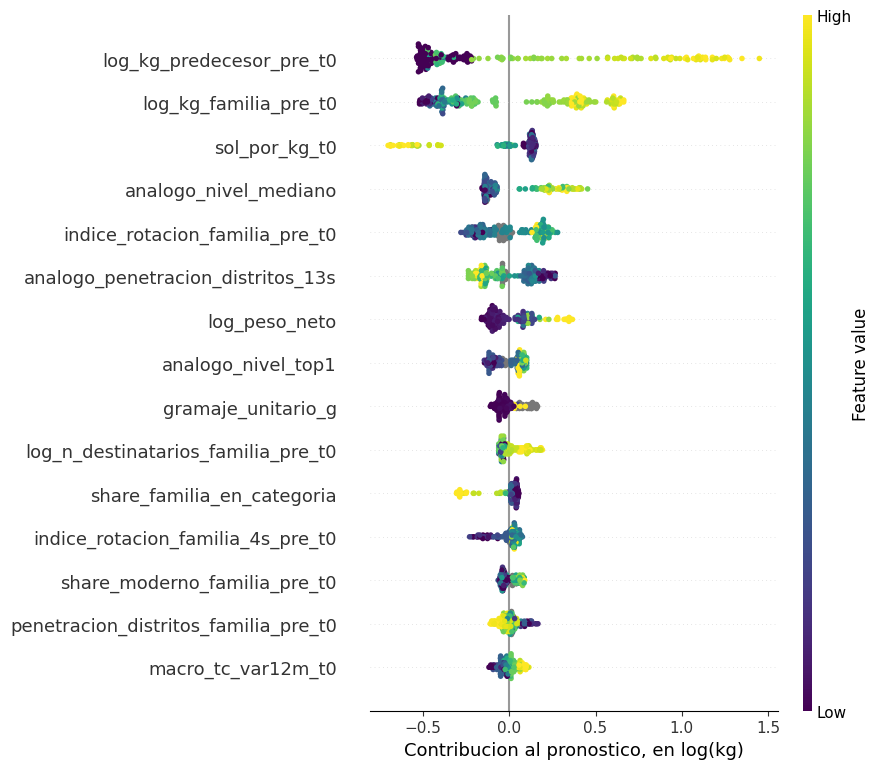

In [ ]:
modelo_interpretacion, x_interpretacion, entrenables = ajustar_modelo_interpretacion(
    features, cols_categoricas_shap, cols_numericas_shap, PARAMS_LGBM_SHAP, SEMILLA)
tb_importancia, valores_shap = importancia_shap(modelo_interpretacion, x_interpretacion,
                                                N_TOP_FEATURES)
tb_direccion = efecto_direccional(valores_shap, x_interpretacion,
                                  tb_importancia["feature"].tolist())
display(tb_importancia.merge(tb_direccion, on="feature", how="left")
        .merge(catalogo_features[["feature", "origen", "subcategoria", "descripcion"]],
               on="feature", how="left"))
tb_importancia_subcategoria = importancia_agrupada(
    valores_shap, x_interpretacion, catalogo_features, "subcategoria")
tb_importancia_origen = importancia_agrupada(
    valores_shap, x_interpretacion, catalogo_features, "origen")
display(tb_importancia_subcategoria.round(3))
display(tb_importancia_origen.round(3))
grafico_shap(valores_shap, x_interpretacion, N_TOP_FEATURES, RUTA_GRAFICO_SHAP)

In [ ]:
texto_resumen = resumen_ejecutivo(
    metricas, comparacion, pareada, tb_descomposicion, tb_por_volumen,
    tb_nivel_por_celda, estadistica_del_nivel,
    celda_foco, CELDA_BASELINE, DESCRIPCION_CELDAS, METRICA,
)

RESUMEN DE LA CORRIDA

QUE SE PROBO
  10 configuraciones sobre 16 lanzamientos en 13 iniciativas,
  con validacion cruzada de 5 folds agrupada por iniciativa: ningun lanzamiento
  comparte fold con sus hermanos de proyecto y cada uno se pronostica una vez.

    B0o        Plan de Trade Marketing    volumen comprometido en Okinawa antes del lanzamiento
    B0c        Plan del area              el metodo actual: regla de tres del planificador
    A2-B1-C3   Red neuronal multitarea    MLP + decoder GRU; pre-entrena en Foods, afina en galletas
    A1-B1-C1   LightGBM cuantilico        arboles; entrena solo con galletas, sin analogos
    A2-B1-C2   Red neuronal multitarea    MLP + decoder GRU; galletas + analogos
    A2-B1-C1   Red neuronal multitarea    MLP + decoder GRU; solo galletas, sin analogos
    A1-B1-C2   LightGBM cuantilico        arboles; galletas + features de analogos
    A1-B1-C3   LightGBM cuantilico        arboles; todo Foods + analogos, galletas con mas peso
    B1        

In [ ]:
guardar_tabla(pareada.drop(columns="grupo_volumen"), PROJECT_ID, TABLA_DIAGNOSTICO,
              WRITE_DISPOSITION)
guardar_tabla(tb_importancia, PROJECT_ID, TABLA_IMPORTANCIA, WRITE_DISPOSITION)
guardar_tabla(tb_okinawa_metodos, PROJECT_ID, TABLA_OKINAWA_METODOS, WRITE_DISPOSITION)
guardar_tabla(tb_okinawa_contrastes, PROJECT_ID, TABLA_OKINAWA_CONTRASTES, WRITE_DISPOSITION)

### Resumen

In [ ]:
# Celda del modelo = la ganadora elegida arriba (celda_foco). La descripción viene del
# dataset del modelo (`features`), cargado al inicio de esta sección.
metodos_cuadro = {CELDA_OKINAWA: "okinawa", CELDA_BASELINE: "planeamiento", celda_foco: "modelo"}
tb_cuadro = cuadro_comparativo(metricas, features, metodos_cuadro, MOSTRAR_TONELADAS)
tb_cuadro_resumen = resumen_comparativo(metricas, metodos_cuadro)

display(tb_cuadro.round(2))
display(tb_cuadro_resumen.round(3))
grafico_pronostico_vs_real(metricas, features, metodos_cuadro, COLORES_METODOS, RUTA_GRAFICO_SKU)
grafico_resumen(tb_cuadro_resumen, COLORES_METODOS, RUTA_GRAFICO_RESUMEN)

guardar_tabla(tb_cuadro, PROJECT_ID, TABLA_CUADRO, WRITE_DISPOSITION)
guardar_tabla(tb_cuadro_resumen, PROJECT_ID, TABLA_CUADRO_RESUMEN, WRITE_DISPOSITION)

,id_iniciativa,cod_material,des_material,real,okinawa,planeamiento,modelo,sesgo_okinawa,sesgo_planeamiento,sesgo_modelo,wmape_okinawa,wmape_planeamiento,wmape_modelo,mejor
0,CASINO_12PQT,000000000004508103,GALL CASINO MENTA 43GR 12PQT 4PCK,100.0,117.53,129.77,122.87,0.18,0.30,0.23,0.18,0.30,0.42,okinawa
1,CASINO_12PQT,000000000004508104,GALL CASINO SURT 43GR 12PQT 4PCK,100.0,95.02,80.99,120.37,-0.05,-0.19,0.20,0.41,0.49,0.47,okinawa
2,CASINO_64_5G,000000000004508087,GALL. CASINO MENTA 64.5GR 8PQT 10PCK,100.0,320.82,290.73,192.80,2.21,1.91,0.93,2.21,1.91,0.93,modelo
3,CASINO_64_5G,000000000004508088,GALL. CASINO FRESA 64.5GR 8PQT 10PCK,100.0,437.87,211.70,349.06,3.38,1.12,2.49,3.38,1.23,2.49,planeamiento
4,CASINO_CAFE,000000000004508109,GALL CASINO CAFÉ 43GR 6PQT 8PCK,100.0,69.41,88.26,47.32,-0.31,-0.12,-0.53,0.31,0.12,0.53,planeamiento
5,CASINO_FRESA_8PQT,000000000004508084,GALL VICT CASINO FRESA 43GR 8PQT 8PCK,100.0,456.66,247.23,319.85,3.57,1.47,2.20,3.57,1.47,2.20,planeamiento
6,CASINO_HAITI,000000000004508426,GALL VICT. MINIGLA TOFFEE 55GR 48PQT,100.0,NaN,381.02,157.61,NaN,2.81,0.58,NaN,2.81,0.60,modelo
7,CASINO_PIE_LIMON,000000000004527274,GALL CASINO PIE DE LIMON 43GR 6PQT 8PCK,100.0,99.64,102.03,95.67,-0.00,0.02,-0.04,0.10,0.07,0.26,planeamiento
8,CASINO_TORRE_108G,000000000004508990,GALL CASINO MENTA TORRE 108GR 30PQT,100.0,130.97,126.60,156.46,0.31,0.27,0.56,0.39,0.39,0.56,okinawa
9,CASINO_TORRE_108G,000000000004508991,GALL CASINO CHOCOLATE TORRE 108GR 30PQT,100.0,132.33,133.87,116.21,0.32,0.34,0.16,0.32,0.34,0.16,modelo


,metodo,n_lanzamientos,sesgo_agregado,sesgo_mediano,sobreestima_n,wmape_ponderado,wmape_mediano
0,okinawa,14,0.342,0.243,10/14,0.540,0.397
1,planeamiento,14,0.230,0.282,11/14,0.378,0.365
2,modelo,14,0.105,0.183,8/14,0.483,0.445


In [ ]:
guardar_tabla(tb_cuadro, PROJECT_ID, TABLA_CUADRO, WRITE_DISPOSITION)
guardar_tabla(tb_cuadro_resumen, PROJECT_ID, TABLA_CUADRO_RESUMEN, WRITE_DISPOSITION)

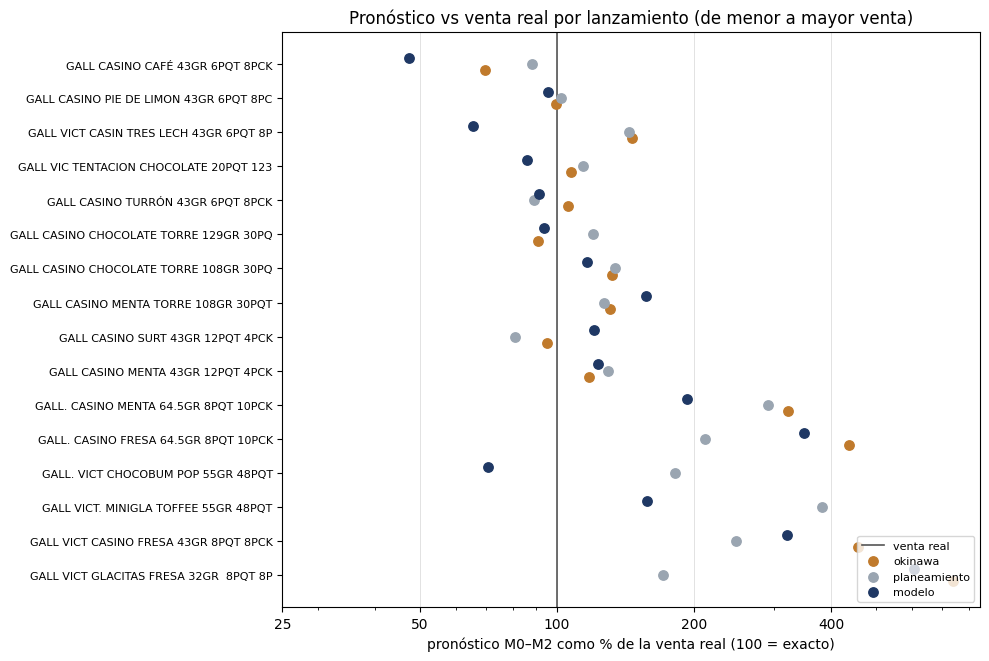

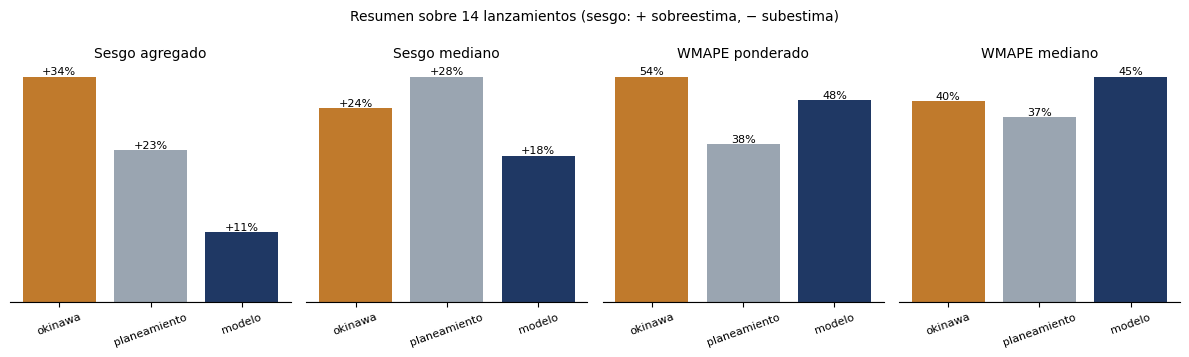

In [ ]:
fig_sku = grafico_pronostico_vs_real(metricas, features, metodos_cuadro, COLORES_METODOS,
                                     RUTA_GRAFICO_SKU)
display(fig_sku)

fig_resumen = grafico_resumen(tb_cuadro_resumen, COLORES_METODOS, RUTA_GRAFICO_RESUMEN)
display(fig_resumen)

# Se cierran después de mostrarlas para que Colab no las dibuje dos veces.
plt.close("all")

## 05 Seguimiento de iteraciones

### Parametrización

In [ ]:
# --- Origen en BigQuery: historial que acumula la sección 03 ---
PROJECT_ID = "acpe-dev-uc-sandbox-aa"
DATASET = "acpe-dev-uc-sandbox-aa.dev"
TABLA_IT_REGISTRO = f"{DATASET}.tb_iteraciones_registro"
TABLA_IT_RESUMEN = f"{DATASET}.tb_iteraciones_resumen"
TABLA_IT_LANZAMIENTO = f"{DATASET}.tb_iteraciones_lanzamiento"
TABLA_IT_CATALOGO = f"{DATASET}.tb_iteraciones_catalogo"
TABLA_IT_IMPORTANCIA = f"{DATASET}.tb_iteraciones_importancia"
TABLA_IT_ESCALERA = f"{DATASET}.tb_iteraciones_escalera"     # detalle técnico
TABLA_IT_EJECUTIVA = f"{DATASET}.tb_iteraciones_ejecutiva"   # vista para el negocio
TABLA_IT_MULTISEMILLA = f"{DATASET}.tb_iteraciones_multisemilla"  # confirmación it09
WRITE_DISPOSITION = "WRITE_TRUNCATE"

# --- Qué se sigue ---
CELDA_PRINCIPAL = "A2-B1-C3"            # la que decide si un grupo de variables se conserva
CELDAS_SEGUIMIENTO = ["A2-B1-C3", "A1-B1-C3"]
CELDA_BASELINE = "B0c"                  # plan del área: la línea a vencer
ITERACION_REFERENCIA = "it00"           # solo aporta la banda de ruido (corrió varias semillas)
UNIVERSOS = ["galletas", "foods"]
UNIVERSO_DECISION = "foods"             # 95 casos: es donde la decisión tiene potencia
UNIVERSO_MAPA = "galletas"              # conteo por lanzamiento: el caso de estudio
SEMILLA = 42                            # semilla principal: la que se compara entre iteraciones
METRICA = "wmape_mensual_mediana"       # resumen por celda
METRICA_LANZAMIENTO = "wmape_mensual"   # por lanzamiento, para el pareo y el conteo

# --- Regla de decisión ---
# Un cambio solo se considera real si supera FACTOR_RUIDO desviaciones estándar del WMAPE
# entre las semillas de la iteración de referencia. Por debajo, es indistinguible del azar.
FACTOR_RUIDO = 2.0
# Un lanzamiento cuenta como "mejora" o "empeora" solo si su error cambia más que esto (pp).
MARGEN_LANZAMIENTO_PP = 5.0

# --- Confirmación con varias semillas ---
# Pares (base, nueva) que se comparan con el promedio de las semillas que ambas corrieron.
# El umbral es el de una sola corrida dividido por la raíz del número de semillas.
PARES_MULTISEMILLA = [("it01", "it09")]
CELDAS_MULTISEMILLA = ["A2-B1-C3", "A1-B1-C3"]
ITERACIONES_MULTISEMILLA = ["it00", "it01", "it09"]   # las que corrieron 5 semillas

# --- Colores ---
# Internas en azules y verde azulado, externas en naranjas: el gráfico por grupo se lee de
# un vistazo como "información de la empresa" frente a "información del entorno".
COLORES_CELDAS = {"A2-B1-C3": "#1f3864", "A1-B1-C3": "#2a7f7a", "B0c": "#9aa5b1"}
COLORES_ORIGEN = {"Interna": "#1f3864", "Externa": "#c07a2c"}
COLORES_SUBCATEGORIA = {
    "Atributos del producto": "#1f3864",
    "Novedad del lanzamiento": "#2e5c8a",
    "Precio": "#4a7fb5",
    "Contexto previo al lanzamiento": "#8fb3dc",
    "Análogos": "#2a7f7a",
    "Canal y distribución": "#5c4d8a",
    "Inventario en el canal": "#8a7bb8",
    "Canibalización y portafolio": "#4f8f86",
    "Geografía": "#6f9bd1",
    "Calendario": "#c07a2c",
    "Macroeconómica": "#e3a857",
    "Clima": "#c9654f",
}
COLOR_SIN_ASIGNAR = "#b8b8b8"           # subcategorías nuevas sin color definido arriba
COLORES_VEREDICTO = {
    "Línea base": "#9aa5b1",
    "Mejora real": "#3f9b6b",
    "Igual, con menos variables": "#7fb89a",
    "Igual (dentro del ruido)": "#c9ced6",
    "Empeora": "#c0504d",
}

RUTA_GRAFICO_MEJORA = "iteraciones_mejora_vs_plan.png"
RUTA_GRAFICO_MATRIZ = "iteraciones_todas_contra_todas.png"
RUTA_GRAFICO_LANZAMIENTOS = "iteraciones_lanzamientos.png"
RUTA_GRAFICO_IMPORTANCIA = "iteraciones_importancia_grupos.png"
RUTA_GRAFICO_MULTISEMILLA = "iteraciones_multisemilla.png"

### Funciones

In [ ]:
import textwrap

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import TwoSlopeNorm
from matplotlib.ticker import PercentFormatter
from scipy import stats

matplotlib.use("Agg")


# =====================================================================================
# Entrada y salida
# =====================================================================================

def cargar_tabla(project_id, table_id):
    """Lee una tabla completa de BigQuery a un DataFrame de pandas."""
    from google.cloud import bigquery
    client = bigquery.Client(project=project_id)
    return client.query(f"SELECT * FROM `{table_id}`").to_dataframe()


def guardar_tabla(df, project_id, table_id, write_disposition):
    """Escribe un DataFrame de pandas a una tabla de BigQuery."""
    from google.cloud import bigquery
    client = bigquery.Client(project=project_id)
    job_config = bigquery.LoadJobConfig(write_disposition=write_disposition, autodetect=True)
    client.load_table_from_dataframe(df, table_id, job_config=job_config).result()


def a_numerico(df, columnas):
    """Convierte a float las columnas que BigQuery devuelve como NUMERIC u object."""
    d = df.copy()
    for c in columnas:
        if c in d.columns:
            d[c] = pd.to_numeric(d[c], errors="coerce").astype("float64")
    return d


def orden_iteraciones(registro):
    """Iteraciones en orden (it00, it01, ...) con su base declarada, si la tuvo.

    Las iteraciones registradas antes de que existiera la columna 'base' quedan sin base.
    """
    d = registro.sort_values("iteracion").drop_duplicates("iteracion", keep="last")
    if "base" not in d.columns:
        d = d.assign(base=None)
    d["base"] = d["base"].where(d["base"].notna() & (d["base"] != "ninguno"), None)
    return d[["iteracion", "descripcion", "n_features", "base"]].reset_index(drop=True)


# =====================================================================================
# Ruido y escalera de mejoras
# =====================================================================================

def banda_ruido(resumen, iteracion_referencia, metrica, factor):
    """Variación de la métrica entre semillas en la iteración de referencia.

    El umbral es factor x desviación estándar: una mejora menor que eso puede deberse solo
    a cómo cayeron las iniciativas en los folds o a la inicialización de los modelos.
    """
    base = resumen[resumen["iteracion"] == iteracion_referencia]
    ruido = (base.groupby(["universo", "celda"])[metrica]
             .agg(n_semillas="count", media="mean", desv="std").reset_index())
    ruido["umbral"] = factor * ruido["desv"]
    return ruido


def _wilcoxon_pareado(anterior, actual, metrica_lanzamiento):
    """p-valor bilateral de Wilcoxon entre dos iteraciones, pareando por lanzamiento."""
    pares = anterior[["cod_material", metrica_lanzamiento]].merge(
        actual[["cod_material", metrica_lanzamiento]], on="cod_material",
        suffixes=("_ant", "_act")).dropna()
    if len(pares) < 3:
        return np.nan
    try:
        return float(stats.wilcoxon(pares[f"{metrica_lanzamiento}_act"],
                                    pares[f"{metrica_lanzamiento}_ant"],
                                    zero_method="wilcox").pvalue)
    except ValueError:
        return np.nan


def tabla_escalera(resumen, lanzamientos, iteraciones, ruido, celda, universo, semilla,
                   metrica, metrica_lanzamiento):
    """Una fila por iteración: valor, cambio frente a la anterior y frente a la base, y decisión.

    La decisión compara el cambio contra el umbral de ruido de esa celda y universo:
      conservar      mejora mayor que el ruido
      descartar      empeora más que el ruido
      sin efecto     dentro del ruido (en una depuración, esto también justifica conservar,
                     porque se logra lo mismo con menos variables)
    """
    sel = resumen[(resumen["celda"] == celda) & (resumen["universo"] == universo)
                  & (resumen["semilla"] == semilla)]
    lanz = lanzamientos[(lanzamientos["celda"] == celda) & (lanzamientos["universo"] == universo)
                        & (lanzamientos["semilla"] == semilla)]
    fila_ruido = ruido[(ruido["celda"] == celda) & (ruido["universo"] == universo)]
    umbral = float(fila_ruido["umbral"].iloc[0]) if len(fila_ruido) else np.nan

    filas, previo, base = [], None, None
    for it in iteraciones.itertuples():
        actual = sel[sel["iteracion"] == it.iteracion]
        if len(actual) == 0:
            continue
        actual = actual.iloc[0]
        valor = float(actual[metrica])
        fila = {
            "iteracion": it.iteracion, "descripcion": it.descripcion,
            "n_features": int(it.n_features), "celda": celda, "universo": universo,
            metrica: valor,
            "rim": float(actual.get("rim", np.nan)),
            "sesgo_mediano": float(actual["sesgo_mediano"]),
            "cobertura_p10_p90": float(actual["cobertura_p10_p90"]),
            "gana_share": float(actual.get("gana_share", np.nan)),
            "umbral_ruido": umbral,
        }
        if previo is None:
            fila.update({"delta_anterior": np.nan, "delta_base": 0.0, "p_vs_anterior": np.nan,
                         "decision": "línea base"})
            base = valor
        else:
            delta = valor - previo["valor"]
            fila.update({
                "delta_anterior": delta,
                "delta_base": valor - base,
                "p_vs_anterior": _wilcoxon_pareado(
                    lanz[lanz["iteracion"] == previo["iteracion"]],
                    lanz[lanz["iteracion"] == it.iteracion], metrica_lanzamiento),
                "decision": ("sin umbral de ruido" if not np.isfinite(umbral)
                             else "conservar" if delta <= -umbral
                             else "descartar" if delta >= umbral else "sin efecto"),
            })
        filas.append(fila)
        previo = {"iteracion": it.iteracion, "valor": valor}
    return pd.DataFrame(filas)


def grafico_escalera(resumen, iteraciones, ruido, celdas, celda_baseline, universos, semilla,
                     metrica, colores, ruta_salida):
    """WMAPE por iteración, un panel por universo, con la banda de ruido de la referencia.

    La banda se dibuja alrededor del valor medio de la referencia de la primera celda: lo
    que quede dentro de ella no se distingue del azar. El plan del área va como línea
    punteada porque no cambia entre iteraciones.
    """
    etiquetas = [f"{r.iteracion}\n" + textwrap.fill(r.descripcion, 24) for r in iteraciones.itertuples()]
    posiciones = np.arange(len(iteraciones))
    figura, ejes = plt.subplots(1, len(universos), figsize=(6.5 * len(universos), 5.0),
                                sharey=False, squeeze=False)
    for eje, universo in zip(ejes[0], universos):
        sel = resumen[(resumen["universo"] == universo) & (resumen["semilla"] == semilla)]
        principal = ruido[(ruido["universo"] == universo) & (ruido["celda"] == celdas[0])]
        if len(principal) and np.isfinite(principal["umbral"].iloc[0]):
            centro, ancho = float(principal["media"].iloc[0]), float(principal["umbral"].iloc[0])
            eje.axhspan(centro - ancho, centro + ancho, color=colores[celdas[0]], alpha=0.10,
                        label=f"Ruido entre semillas ({celdas[0]})")
        base = sel[sel["celda"] == celda_baseline].groupby("iteracion")[metrica].first()
        if len(base):
            eje.axhline(float(base.iloc[0]), color=colores[celda_baseline], linestyle="--",
                        linewidth=1.5, label="Plan del área")
        for k, celda in enumerate(celdas):
            serie = sel[sel["celda"] == celda].set_index("iteracion")[metrica]
            valores = [serie.get(it, np.nan) for it in iteraciones["iteracion"]]
            eje.plot(posiciones, valores, marker="o", linewidth=2, color=colores[celda], label=celda)
            for x, y in zip(posiciones, valores):
                if np.isfinite(y):
                    eje.annotate(f"{y:.1%}", (x, y), textcoords="offset points", xytext=(0, 7 if k == 0 else -14),
                                 ha="center", fontsize=8, color=colores[celda])
        eje.set_xticks(posiciones)
        eje.set_xticklabels(etiquetas, fontsize=8)
        eje.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
        eje.set_title(f"WMAPE mensual mediano · {universo}", fontsize=11)
        eje.spines[["top", "right"]].set_visible(False)
        eje.grid(axis="y", alpha=0.3)
    manejadores, nombres = ejes[0][0].get_legend_handles_labels()
    figura.legend(manejadores, nombres, fontsize=8, frameon=False, loc="lower center",
                  ncol=len(nombres), bbox_to_anchor=(0.5, -0.04))
    figura.tight_layout(rect=(0, 0.05, 1, 1))
    figura.savefig(ruta_salida, dpi=150, bbox_inches="tight")
    return figura


# =====================================================================================
# Efecto por lanzamiento
# =====================================================================================

def etiquetas_lanzamiento(codigos, ancho, mostrar_descripcion):
    """Rótulo de cada lanzamiento: L01, L02... o su descripción si se permite mostrarla."""
    codigos = sorted(codigos)
    if not mostrar_descripcion:
        return {c: f"L{k + 1:02d}" for k, c in enumerate(codigos)}
    descripcion = ancho.drop_duplicates("cod_material").set_index("cod_material")["des_material"]
    return {c: str(descripcion.get(c, c))[:40] for c in codigos}


def grafico_mapa_calor(lanzamientos, iteraciones, celda, universo, semilla, iteracion_referencia,
                       metrica_lanzamiento, etiquetas, ruta_salida):
    """Cambio del WMAPE de cada lanzamiento frente a la referencia, en puntos porcentuales.

    Azul = mejora, rojo = empeora. Muestra si una mejora agregada viene de muchos
    lanzamientos o de unos pocos, y a cuáles ayuda cada grupo de variables.
    """
    sel = lanzamientos[(lanzamientos["celda"] == celda) & (lanzamientos["universo"] == universo)
                       & (lanzamientos["semilla"] == semilla)]
    tabla = sel.pivot_table(index="cod_material", columns="iteracion",
                            values=metrica_lanzamiento, aggfunc="first")
    columnas = [it for it in iteraciones["iteracion"]
                if it in tabla.columns and it != iteracion_referencia]
    delta = (tabla[columnas].sub(tabla[iteracion_referencia], axis=0) * 100).sort_index()
    delta.index = [etiquetas.get(c, c) for c in delta.index]

    limite = float(np.nanmax(np.abs(delta.to_numpy()))) if delta.size else 1.0
    limite = max(limite, 1.0)
    figura, eje = plt.subplots(figsize=(1.1 * len(columnas) + 3.2, 0.32 * len(delta) + 1.8))
    imagen = eje.imshow(delta.to_numpy(), cmap="RdBu_r", aspect="auto",
                        norm=TwoSlopeNorm(vmin=-limite, vcenter=0.0, vmax=limite))
    for i in range(delta.shape[0]):
        for j in range(delta.shape[1]):
            valor = delta.iat[i, j]
            if np.isfinite(valor):
                eje.text(j, i, f"{valor:+.0f}", ha="center", va="center", fontsize=7,
                         color="white" if abs(valor) > 0.6 * limite else "#222222")
    eje.set_xticks(range(len(columnas)))
    eje.set_xticklabels(columnas, fontsize=8)
    eje.set_yticks(range(len(delta)))
    eje.set_yticklabels(delta.index, fontsize=8)
    eje.set_title(f"Cambio del WMAPE frente a {iteracion_referencia} (pp) · {celda} · {universo}",
                  fontsize=10)
    figura.colorbar(imagen, ax=eje, shrink=0.6, aspect=30, label="pp (negativo = mejora)")
    figura.tight_layout()
    figura.savefig(ruta_salida, dpi=150, bbox_inches="tight")
    return figura


# =====================================================================================
# Importancia por grupo de variables
# =====================================================================================

def importancia_por_iteracion(importancia, col_grupo):
    """Peso relativo de cada grupo (origen o subcategoría) en cada iteración, en filas."""
    d = a_numerico(importancia, ["peso_relativo"])
    return (d.groupby(["iteracion", col_grupo], as_index=False)
            .agg(peso_relativo=("peso_relativo", "sum"), n_features=("feature", "count")))


def features_por_grupo(catalogo, col_grupo):
    """Número de features activas por grupo e iteración: cuánto creció cada bloque."""
    activas = catalogo[catalogo["activa"].astype(bool)]
    return activas.pivot_table(index="iteracion", columns=col_grupo, values="feature",
                               aggfunc="count", fill_value=0)


def _barras_apiladas(eje, tabla, colores, color_sin_asignar, titulo):
    """Barras horizontales apiladas: una por iteración, un segmento por grupo."""
    izquierda = np.zeros(len(tabla))
    for grupo in tabla.columns:
        valores = tabla[grupo].to_numpy(dtype="float64")
        eje.barh(tabla.index, valores, left=izquierda, label=grupo,
                 color=colores.get(grupo, color_sin_asignar), edgecolor="white", linewidth=0.8)
        for y, (x0, v) in enumerate(zip(izquierda, valores)):
            if v >= 0.06:
                eje.text(x0 + v / 2, y, f"{v:.0%}", ha="center", va="center",
                         fontsize=7, color="white")
        izquierda += valores
    eje.invert_yaxis()
    eje.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
    eje.set_xlim(0, 1)
    eje.set_title(titulo, fontsize=10)
    eje.spines[["top", "right"]].set_visible(False)
    eje.legend(fontsize=7, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.08),
               ncol=3)


def grafico_importancia(importancia, iteraciones, colores_subcategoria, colores_origen,
                        color_sin_asignar, ruta_salida):
    """Qué tipo de información explica el pronóstico en cada iteración.

    Izquierda, por subcategoría; derecha, interna frente a externa. Al añadir un grupo se
    ve cuánto peso gana y a qué grupos se lo quita.
    """
    orden = list(iteraciones["iteracion"])
    por_subcategoria = (importancia_por_iteracion(importancia, "subcategoria")
                        .pivot(index="iteracion", columns="subcategoria", values="peso_relativo")
                        .reindex(orden).fillna(0.0))
    columnas = [c for c in colores_subcategoria if c in por_subcategoria.columns]
    por_subcategoria = por_subcategoria[columnas + [c for c in por_subcategoria.columns
                                                    if c not in columnas]]
    por_origen = (importancia_por_iteracion(importancia, "origen")
                  .pivot(index="iteracion", columns="origen", values="peso_relativo")
                  .reindex(orden).fillna(0.0))
    por_origen = por_origen[[c for c in colores_origen if c in por_origen.columns]]

    figura, ejes = plt.subplots(1, 2, figsize=(13, 0.5 * len(orden) + 2.6),
                                gridspec_kw={"width_ratios": [2.2, 1]})
    _barras_apiladas(ejes[0], por_subcategoria, colores_subcategoria, color_sin_asignar,
                     "Peso en el pronóstico por subcategoría (SHAP)")
    _barras_apiladas(ejes[1], por_origen, colores_origen, color_sin_asignar,
                     "Interna frente a externa")
    figura.tight_layout()
    figura.savefig(ruta_salida, dpi=150, bbox_inches="tight")
    return figura


# =====================================================================================
# Vista ejecutiva: todas las iteraciones contra todas
#
# La pregunta del negocio no es "¿mejoró frente a it00?", sino "¿cuál es hoy la mejor
# versión y cuánto le gana al plan del área?". Por eso cada iteración compite contra la
# campeona vigente (la mejor hasta ese momento) y además se cruza con todas las demás.
# =====================================================================================

def cambios_por_iteracion(catalogo, iteraciones):
    """Qué variables entraron y salieron en cada iteración, en texto corto.

    Se compara contra la base declarada de la iteración (p. ej., it03 frente a it01) y, si no
    la tiene, contra la anterior. Así una iteración que parte de la mejor versión no aparece
    "quitando" las variables de una iteración descartada.
    """
    activas = catalogo[catalogo["activa"].astype(bool)]
    filas, previas = [], None
    for it, base in zip(iteraciones["iteracion"], iteraciones["base"]):
        actuales = activas[activas["iteracion"] == it]
        if base and (activas["iteracion"] == base).any():
            previas = activas[activas["iteracion"] == base]
        conjunto = set(actuales["feature"])
        if previas is None:
            texto, n_mas, n_menos = "Línea base", 0, 0
        else:
            entran = actuales[actuales["feature"].isin(conjunto - set(previas["feature"]))]
            salen = previas[previas["feature"].isin(set(previas["feature"]) - conjunto)]
            partes = []
            if len(entran):
                partes.append(f"+{len(entran)} ({', '.join(sorted(entran['subcategoria'].unique()))})")
            if len(salen):
                partes.append(f"−{len(salen)} ({', '.join(sorted(salen['subcategoria'].unique()))})")
            texto, n_mas, n_menos = " · ".join(partes) or "Sin cambios de variables", len(entran), len(salen)
        filas.append({"iteracion": it, "cambio": texto, "variables_agregadas": n_mas,
                      "variables_retiradas": n_menos, "n_variables": len(conjunto)})
        previas = actuales
    return pd.DataFrame(filas)


def veredictos(resumen, iteraciones, cambios, ruido, celda, universo, semilla, metrica):
    """Compara cada iteración con la campeona vigente y decide si la reemplaza.

    Reglas (con umbral = ruido entre semillas de la referencia):
      Mejora real                 baja el error más que el umbral -> nueva campeona
      Igual, con menos variables  dentro del ruido y más simple   -> nueva campeona
      Igual (dentro del ruido)    dentro del ruido, no más simple -> sigue la anterior
      Empeora                     sube el error más que el umbral -> sigue la anterior
    """
    sel = resumen[(resumen["celda"] == celda) & (resumen["universo"] == universo)
                  & (resumen["semilla"] == semilla)].set_index("iteracion")[metrica]
    fila_ruido = ruido[(ruido["celda"] == celda) & (ruido["universo"] == universo)]
    umbral = float(fila_ruido["umbral"].iloc[0]) if len(fila_ruido) else 0.0
    n_variables = cambios.set_index("iteracion")["n_variables"]

    filas, campeona = [], None
    for it in iteraciones["iteracion"]:
        if it not in sel.index:
            continue
        valor = float(sel[it])
        if campeona is None:
            fila = {"campeona_previa": "—", "delta_vs_campeona": np.nan, "veredicto": "Línea base"}
            campeona = it
        else:
            delta = valor - float(sel[campeona])
            if delta <= -umbral:
                veredicto = "Mejora real"
            elif delta >= umbral:
                veredicto = "Empeora"
            elif n_variables[it] < n_variables[campeona]:
                veredicto = "Igual, con menos variables"
            else:
                veredicto = "Igual (dentro del ruido)"
            fila = {"campeona_previa": campeona, "delta_vs_campeona": delta, "veredicto": veredicto}
            if veredicto in ("Mejora real", "Igual, con menos variables"):
                campeona = it
        filas.append({"iteracion": it, **fila, "umbral_ruido": umbral})
    salida = pd.DataFrame(filas)
    salida["es_campeona"] = salida["iteracion"] == campeona
    return salida


def tabla_ejecutiva(resumen, iteraciones, cambios, decision, celda, universos, semilla, metrica):
    """Una fila por iteración, en el lenguaje del negocio.

    'Error' es el WMAPE mensual mediano; 'Mejora vs plan' es el RIM: cuánto menos se
    equivoca el modelo que el plan del área (positivo = el modelo es mejor).
    """
    tabla = iteraciones[["iteracion", "descripcion"]].merge(
        cambios[["iteracion", "cambio", "n_variables"]], on="iteracion", how="left")
    for universo in universos:
        sel = resumen[(resumen["celda"] == celda) & (resumen["universo"] == universo)
                      & (resumen["semilla"] == semilla)][["iteracion", metrica, "rim"]]
        tabla = tabla.merge(sel.rename(columns={metrica: f"error_{universo}",
                                                "rim": f"mejora_vs_plan_{universo}"}),
                            on="iteracion", how="left")
    return tabla.merge(decision, on="iteracion", how="left")


def matriz_todas_contra_todas(resumen, lanzamientos, iteraciones, celda, universo, semilla,
                              metrica, metrica_lanzamiento):
    """Diferencia de error (fila menos columna, en pp) y p de Wilcoxon para cada par."""
    sel = resumen[(resumen["celda"] == celda) & (resumen["universo"] == universo)
                  & (resumen["semilla"] == semilla)].set_index("iteracion")[metrica]
    lanz = lanzamientos[(lanzamientos["celda"] == celda) & (lanzamientos["universo"] == universo)
                        & (lanzamientos["semilla"] == semilla)]
    orden = [it for it in iteraciones["iteracion"] if it in sel.index]
    delta = pd.DataFrame(np.nan, index=orden, columns=orden)
    pvalor = pd.DataFrame(np.nan, index=orden, columns=orden)
    for fila in orden:
        for col in orden:
            if fila == col:
                continue
            delta.loc[fila, col] = (float(sel[fila]) - float(sel[col])) * 100
            pvalor.loc[fila, col] = _wilcoxon_pareado(
                lanz[lanz["iteracion"] == col], lanz[lanz["iteracion"] == fila], metrica_lanzamiento)
    return delta, pvalor


def conteo_lanzamientos(lanzamientos, decision, celda, universo, semilla, metrica_lanzamiento,
                        margen_pp):
    """Cuántos lanzamientos mejoran, quedan igual o empeoran frente a la campeona previa.

    Un lanzamiento cuenta como mejora o empeora solo si su error cambia más de margen_pp.
    Complementa a la mediana: una mejora agregada puede venir de pocos lanzamientos.
    """
    lanz = lanzamientos[(lanzamientos["celda"] == celda) & (lanzamientos["universo"] == universo)
                        & (lanzamientos["semilla"] == semilla)]
    tabla = lanz.pivot_table(index="cod_material", columns="iteracion",
                             values=metrica_lanzamiento, aggfunc="first")
    filas = []
    for r in decision.itertuples():
        if r.campeona_previa == "—" or r.iteracion not in tabla or r.campeona_previa not in tabla:
            continue
        cambio = ((tabla[r.iteracion] - tabla[r.campeona_previa]) * 100).dropna()
        filas.append({"iteracion": r.iteracion, "frente_a": r.campeona_previa,
                      "mejora": int((cambio <= -margen_pp).sum()),
                      "igual": int((cambio.abs() < margen_pp).sum()),
                      "empeora": int((cambio >= margen_pp).sum())})
    return pd.DataFrame(filas, columns=["iteracion", "frente_a", "mejora", "igual", "empeora"])


def _etiqueta_iteracion(fila):
    """'it01 · −6 (Calendario, ...)' recortado para el eje."""
    return textwrap.shorten(f"{fila.iteracion} · {fila.cambio}", width=48, placeholder="…")


def grafico_mejora_vs_plan(tabla, universos, wmape_plan, ruido, celda, colores_veredicto,
                           ruta_salida):
    """Barras horizontales: cuánto menos se equivoca cada iteración que el plan del área.

    El color es el veredicto (decidido en el universo de decisión) y la campeona vigente
    lleva borde negro y estrella. El subtítulo de cada panel da el ruido en la misma escala:
    dos iteraciones que difieren menos que eso no se distinguen del azar.
    """
    etiquetas = [_etiqueta_iteracion(r) for r in tabla.itertuples()]
    posiciones = np.arange(len(tabla))
    figura, ejes = plt.subplots(1, len(universos),
                                figsize=(6.2 * len(universos), 0.55 * len(tabla) + 2.2),
                                sharey=True, squeeze=False)
    for eje, universo in zip(ejes[0], universos):
        valores = tabla[f"mejora_vs_plan_{universo}"].to_numpy(dtype="float64")
        colores = [colores_veredicto.get(v, "#9aa5b1") for v in tabla["veredicto"]]
        barras = eje.barh(posiciones, valores, color=colores, height=0.6)
        for barra, campeona in zip(barras, tabla["es_campeona"]):
            if campeona:
                barra.set_edgecolor("black")
                barra.set_linewidth(1.6)
        limite = max(np.nanmax(np.abs(valores)) if np.isfinite(valores).any() else 0.1, 0.1)
        for y, (v, campeona) in enumerate(zip(valores, tabla["es_campeona"])):
            if np.isfinite(v):
                eje.annotate(f"{v:+.0%}" + (" ★" if campeona else ""), (v, y),
                             xytext=(5 if v >= 0 else -5, 0), textcoords="offset points",
                             ha="left" if v >= 0 else "right", va="center", fontsize=9)
        eje.axvline(0, color="#333333", linewidth=1)
        eje.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
        eje.set_xlim(-1.45 * limite, 1.45 * limite)
        fila_ruido = ruido[(ruido["celda"] == celda) & (ruido["universo"] == universo)]
        subtitulo = ""
        if len(fila_ruido) and universo in wmape_plan and np.isfinite(fila_ruido["umbral"].iloc[0]):
            subtitulo = (f"\nruido: diferencias menores a ±{float(fila_ruido['umbral'].iloc[0]) / wmape_plan[universo]:.0%}"
                         " entre iteraciones no son reales")
        eje.set_title(f"Mejora frente al plan del área · {universo}{subtitulo}", fontsize=10)
        eje.spines[["top", "right"]].set_visible(False)
        eje.grid(axis="x", alpha=0.3)
    ejes[0][0].set_yticks(posiciones)
    ejes[0][0].set_yticklabels(etiquetas, fontsize=9)
    ejes[0][0].invert_yaxis()
    manejadores = [plt.Rectangle((0, 0), 1, 1, color=c) for c in colores_veredicto.values()]
    figura.legend(manejadores, list(colores_veredicto.keys()), fontsize=8, frameon=False,
                  loc="lower center", ncol=len(colores_veredicto), bbox_to_anchor=(0.5, -0.02))
    figura.text(0.5, -0.07, "0% = mismo error que el plan del área; positivo = el modelo se "
                "equivoca menos. El color es el veredicto, decidido en el universo de decisión. "
                "★ = mejor versión vigente.",
                ha="center", fontsize=8, color="#555555")
    figura.tight_layout(rect=(0, 0.05, 1, 1))
    figura.savefig(ruta_salida, dpi=150, bbox_inches="tight")
    return figura


def grafico_matriz(delta, pvalor, umbral_pp, celda, universo, ruta_salida):
    """Todas contra todas: cuántos puntos de error tiene la fila frente a la columna.

    Verde = la fila se equivoca menos; rojo = más; gris = diferencia dentro del ruido.
    El asterisco marca p < 0.05 en el Wilcoxon pareado por lanzamiento.
    """
    n = len(delta)
    figura, eje = plt.subplots(figsize=(1.0 * n + 2.6, 0.8 * n + 1.6))
    colores = np.empty((n, n, 3))
    for i in range(n):
        for j in range(n):
            v = delta.iat[i, j]
            if not np.isfinite(v):
                colores[i, j] = (1, 1, 1)
            elif v <= -umbral_pp:
                colores[i, j] = matplotlib.colors.to_rgb("#3f9b6b")
            elif v >= umbral_pp:
                colores[i, j] = matplotlib.colors.to_rgb("#c0504d")
            else:
                colores[i, j] = matplotlib.colors.to_rgb("#e3e6ea")
            texto = "—" if i == j else f"{v:+.1f}" + ("*" if pvalor.iat[i, j] < 0.05 else "")
            claro = np.isfinite(v) and abs(v) >= umbral_pp
            eje.text(j, i, texto, ha="center", va="center", fontsize=9,
                     color="white" if claro else "#222222")
    eje.imshow(colores, aspect="auto")
    eje.set_xticks(range(n))
    eje.set_xticklabels(delta.columns, fontsize=9)
    eje.set_yticks(range(n))
    eje.set_yticklabels(delta.index, fontsize=9)
    eje.set_xlabel("frente a…", fontsize=9)
    eje.set_title(f"Todas contra todas · {celda} · {universo}\n"
                  f"pp de error de la fila frente a la columna (ruido = ±{umbral_pp:.1f} pp)",
                  fontsize=10)
    figura.tight_layout()
    figura.savefig(ruta_salida, dpi=150, bbox_inches="tight")
    return figura


def grafico_lanzamientos(conteo, universo, margen_pp, ruta_salida):
    """Barras apiladas: lanzamientos que mejoran, quedan igual o empeoran frente a la campeona."""
    figura, eje = plt.subplots(figsize=(8, 0.55 * max(len(conteo), 1) + 1.8))
    if len(conteo) == 0:
        eje.text(0.5, 0.5, "Aún no hay iteraciones para comparar", ha="center", va="center")
        eje.axis("off")
        return figura
    etiquetas = [f"{r.iteracion} vs {r.frente_a}" for r in conteo.itertuples()]
    izquierda = np.zeros(len(conteo))
    for col, color in [("mejora", "#3f9b6b"), ("igual", "#c9ced6"), ("empeora", "#c0504d")]:
        valores = conteo[col].to_numpy(dtype="float64")
        eje.barh(etiquetas, valores, left=izquierda, color=color, label=col.capitalize(), height=0.6)
        for y, (x0, v) in enumerate(zip(izquierda, valores)):
            if v > 0:
                eje.text(x0 + v / 2, y, f"{int(v)}", ha="center", va="center", fontsize=9,
                         color="white" if col != "igual" else "#222222")
        izquierda += valores
    eje.invert_yaxis()
    eje.set_title(f"¿A cuántos lanzamientos ayuda cada cambio? · {universo}\n"
                  f"(cambio de error mayor a ±{margen_pp:.0f} pp frente a la mejor versión previa)",
                  fontsize=10)
    eje.spines[["top", "right"]].set_visible(False)
    eje.legend(fontsize=8, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3)
    figura.tight_layout()
    figura.savefig(ruta_salida, dpi=150, bbox_inches="tight")
    return figura

# =====================================================================================
# Confirmación con varias semillas (it01 frente a it09)
# =====================================================================================

def comparacion_multisemilla(resumen, pares, celdas, universos, ruido, metrica):
    """Compara dos iteraciones con el promedio de las semillas que ambas corrieron.

    Con la misma semilla las dos iteraciones usan los mismos folds e inicializaciones, así
    que la diferencia se mide pareada por semilla. El umbral es el de una sola corrida
    (factor x desviación entre semillas de la referencia) dividido por la raíz del número
    de semillas: promediar n corridas reduce el ruido en esa proporción.

    Args:
        resumen: Historial de métricas por iteración, universo, celda y semilla.
        pares: Lista de tuplas (iteración base, iteración nueva).
        celdas: Celdas a comparar.
        universos: Universos a comparar.
        ruido: Banda de ruido de la iteración de referencia (salida de banda_ruido).
        metrica: Métrica por celda.

    Returns:
        DataFrame con una fila por par, universo y celda: medias, diferencia, umbral,
        p-valor de la prueba t pareada y veredicto.
    """
    filas = []
    for base, nueva in pares:
        for universo in universos:
            for celda in celdas:
                sel = resumen[(resumen["universo"] == universo) & (resumen["celda"] == celda)]
                a = sel[sel["iteracion"] == base].set_index("semilla")[metrica]
                b = sel[sel["iteracion"] == nueva].set_index("semilla")[metrica]
                comunes = sorted(set(a.index) & set(b.index))
                if not comunes:
                    continue
                diferencias = (b.loc[comunes] - a.loc[comunes]).astype("float64")
                fila_ruido = ruido[(ruido["universo"] == universo) & (ruido["celda"] == celda)]
                umbral_1 = float(fila_ruido["umbral"].iloc[0]) if len(fila_ruido) else np.nan
                umbral = umbral_1 / np.sqrt(len(comunes))
                p = (float(stats.ttest_rel(b.loc[comunes], a.loc[comunes]).pvalue)
                     if len(comunes) >= 3 and diferencias.std() > 0 else np.nan)
                delta = float(diferencias.mean())
                filas.append({
                    "base": base, "nueva": nueva, "universo": universo, "celda": celda,
                    "n_semillas": len(comunes),
                    f"{metrica}_base": float(a.loc[comunes].mean()),
                    f"{metrica}_nueva": float(b.loc[comunes].mean()),
                    "delta_pp": delta * 100,
                    "desv_delta_pp": float(diferencias.std()) * 100,
                    "semillas_mejora": int((diferencias < 0).sum()),
                    "umbral_pp": umbral * 100,
                    "p_t_pareada": p,
                    "veredicto": ("sin umbral de ruido" if not np.isfinite(umbral)
                                  else "Mejora real" if delta <= -umbral
                                  else "Empeora" if delta >= umbral
                                  else "Igual (dentro del ruido)"),
                })
    return pd.DataFrame(filas)


def grafico_multisemilla(resumen, iteraciones_graficar, celda, celda_baseline, universos,
                         metrica, colores, ruta_salida):
    """Error de cada semilla por iteración, con su promedio, un panel por universo.

    Cada punto es una semilla; la raya horizontal es el promedio. Si las nubes de puntos
    de dos iteraciones se solapan, la diferencia entre ellas no es distinguible del azar.

    Args:
        resumen: Historial de métricas por iteración, universo, celda y semilla.
        iteraciones_graficar: Iteraciones con varias semillas, en orden.
        celda: Celda del modelo a graficar.
        celda_baseline: Celda del plan del área (línea de referencia).
        universos: Universos, uno por panel.
        metrica: Métrica por celda.
        colores: Colores por celda.
        ruta_salida: Ruta del PNG.

    Returns:
        Figura de matplotlib.
    """
    figura, ejes = plt.subplots(1, len(universos), figsize=(5.2 * len(universos), 4.2),
                                squeeze=False)
    for eje, universo in zip(ejes[0], universos):
        sel = resumen[(resumen["universo"] == universo) & (resumen["celda"] == celda)]
        for x, it in enumerate(iteraciones_graficar):
            valores = sel.loc[sel["iteracion"] == it, metrica].astype("float64").to_numpy()
            if len(valores) == 0:
                continue
            jitter = np.linspace(-0.08, 0.08, len(valores))
            eje.scatter(x + jitter, valores, s=28, color=colores[celda], alpha=0.65, zorder=3)
            eje.hlines(valores.mean(), x - 0.22, x + 0.22, color=colores[celda], linewidth=2.5, zorder=4)
            eje.annotate(f"{valores.mean():.1%}\n(n={len(valores)})", (x + 0.25, valores.mean()),
                         fontsize=8, va="center", color=colores[celda])
        plan = resumen[(resumen["universo"] == universo) & (resumen["celda"] == celda_baseline)][metrica]
        if len(plan):
            eje.axhline(float(plan.iloc[0]), color=colores[celda_baseline], linestyle="--",
                        linewidth=1.5, label="Plan del área")
            eje.legend(fontsize=8, frameon=False, loc="best")
        eje.set_xticks(range(len(iteraciones_graficar)))
        eje.set_xticklabels(iteraciones_graficar)
        eje.set_xlim(-0.5, len(iteraciones_graficar) - 0.2)
        eje.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
        eje.set_title(f"{celda} · {universo} · una marca por semilla", fontsize=10)
        eje.spines[["top", "right"]].set_visible(False)
        eje.grid(axis="y", alpha=0.3)
    figura.tight_layout()
    figura.savefig(ruta_salida, dpi=150, bbox_inches="tight")
    return figura

### Ejecución

In [ ]:
from IPython.display import display

registro = cargar_tabla(PROJECT_ID, TABLA_IT_REGISTRO)
resumen = a_numerico(cargar_tabla(PROJECT_ID, TABLA_IT_RESUMEN), [
    METRICA, "rim", "sesgo_mediano", "cobertura_p10_p90", "gana_share", "semilla"])
lanzamientos = a_numerico(cargar_tabla(PROJECT_ID, TABLA_IT_LANZAMIENTO),
                          [METRICA_LANZAMIENTO, "semilla"])
catalogo = cargar_tabla(PROJECT_ID, TABLA_IT_CATALOGO)
importancia = cargar_tabla(PROJECT_ID, TABLA_IT_IMPORTANCIA)

iteraciones = orden_iteraciones(registro)
ruido = banda_ruido(resumen, ITERACION_REFERENCIA, METRICA, FACTOR_RUIDO)
cambios = cambios_por_iteracion(catalogo, iteraciones)

# Vista ejecutiva: cada iteración contra la mejor versión vigente y contra todas las demás.
decision = veredictos(resumen, iteraciones, cambios, ruido, CELDA_PRINCIPAL, UNIVERSO_DECISION,
                      SEMILLA, METRICA)
tb_ejecutiva = tabla_ejecutiva(resumen, iteraciones, cambios, decision, CELDA_PRINCIPAL,
                               UNIVERSOS, SEMILLA, METRICA)
wmape_plan = (resumen[(resumen["celda"] == CELDA_BASELINE) & (resumen["semilla"] == SEMILLA)]
              .groupby("universo")[METRICA].first().to_dict())
delta_pares, p_pares = matriz_todas_contra_todas(
    resumen, lanzamientos, iteraciones, CELDA_PRINCIPAL, UNIVERSO_DECISION, SEMILLA,
    METRICA, METRICA_LANZAMIENTO)
conteo = conteo_lanzamientos(lanzamientos, decision, CELDA_PRINCIPAL, UNIVERSO_MAPA, SEMILLA,
                             METRICA_LANZAMIENTO, MARGEN_LANZAMIENTO_PP)

# Detalle técnico (ambas celdas y universos, contra la iteración anterior).
tb_escalera = pd.concat(
    [tabla_escalera(resumen, lanzamientos, iteraciones, ruido, celda, universo, SEMILLA,
                    METRICA, METRICA_LANZAMIENTO)
     for celda in CELDAS_SEGUIMIENTO for universo in UNIVERSOS],
    ignore_index=True)

# Versión legible de la tabla ejecutiva: porcentajes como texto y nombres de negocio.
vista = tb_ejecutiva.copy()
for universo in UNIVERSOS:
    vista[f"error_{universo}"] = vista[f"error_{universo}"].map(lambda v: f"{v:.1%}")
    vista[f"mejora_vs_plan_{universo}"] = vista[f"mejora_vs_plan_{universo}"].map(lambda v: f"{v:+.1%}")
vista["delta_vs_campeona"] = vista["delta_vs_campeona"].map(
    lambda v: "—" if pd.isna(v) else f"{v * 100:+.1f} pp")
vista["es_campeona"] = vista["es_campeona"].map({True: "★", False: ""})
vista = vista[["iteracion", "cambio", "n_variables"]
              + [c for u in UNIVERSOS for c in (f"error_{u}", f"mejora_vs_plan_{u}")]
              + ["campeona_previa", "delta_vs_campeona", "veredicto", "es_campeona"]]

for titulo, tabla in [
    (f"Resumen ejecutivo · {CELDA_PRINCIPAL} · decide {UNIVERSO_DECISION} "
     f"(ruido ±{decision['umbral_ruido'].iloc[0] * 100:.1f} pp)", vista),
    (f"Todas contra todas · pp de error (fila − columna) · {UNIVERSO_DECISION}", delta_pares.round(1)),
    (f"Lanzamientos que cambian más de ±{MARGEN_LANZAMIENTO_PP:.0f} pp · {UNIVERSO_MAPA}", conteo),
    ("Detalle técnico por celda y universo", tb_escalera.round(4)),
]:
    print(f"=== {titulo} ===")
    display(tabla)

=== Resumen ejecutivo · A2-B1-C3 · decide foods (ruido ±6.8 pp) ===


,iteracion,cambio,n_variables,error_galletas,mejora_vs_plan_galletas,error_foods,mejora_vs_plan_foods,campeona_previa,delta_vs_campeona,veredicto,es_campeona
0,it00,Línea base,52,42.2%,-2.4%,73.1%,-66.7%,—,—,Línea base,
1,it01,"−6 (Análogos, Calendario, Contexto previo al l...",46,39.4%,+4.5%,71.8%,-63.7%,it00,-1.3 pp,"Igual, con menos variables",★
2,it02,+6 (Canal y distribución),52,38.3%,+7.2%,76.5%,-74.4%,it01,+4.7 pp,Igual (dentro del ruido),
3,it03,+3 (Inventario en el canal),49,38.1%,+7.7%,74.2%,-69.3%,it01,+2.4 pp,Igual (dentro del ruido),
4,it04,+3 (Canibalización y portafolio),49,49.1%,-19.1%,69.1%,-57.6%,it01,-2.7 pp,Igual (dentro del ruido),
5,it06,+3 (Geografía),49,41.8%,-1.3%,75.3%,-71.8%,it01,+3.6 pp,Igual (dentro del ruido),
6,it07,+5 (Macroeconómica),51,45.1%,-9.4%,69.6%,-58.8%,it01,-2.1 pp,Igual (dentro del ruido),
7,it08,+3 (Clima),49,42.2%,-2.3%,72.5%,-65.3%,it01,+0.7 pp,Igual (dentro del ruido),
8,it09,"+22 (Canal y distribución, Canibalización y po...",68,44.5%,-7.9%,70.8%,-61.4%,it01,-1.0 pp,Igual (dentro del ruido),


=== Todas contra todas · pp de error (fila − columna) · foods ===


,it00,it01,it02,it03,it04,it06,it07,it08,it09
it00,NaN,1.3,-3.4,-1.1,4.0,-2.3,3.5,0.6,2.3
it01,-1.3,NaN,-4.7,-2.4,2.7,-3.6,2.1,-0.7,1.0
it02,3.4,4.7,NaN,2.3,7.4,1.1,6.8,4.0,5.7
it03,1.1,2.4,-2.3,NaN,5.1,-1.1,4.6,1.8,3.5
it04,-4.0,-2.7,-7.4,-5.1,NaN,-6.2,-0.5,-3.4,-1.7
it06,2.3,3.6,-1.1,1.1,6.2,NaN,5.7,2.9,4.6
it07,-3.5,-2.1,-6.8,-4.6,0.5,-5.7,NaN,-2.8,-1.1
it08,-0.6,0.7,-4.0,-1.8,3.4,-2.9,2.8,NaN,1.7
it09,-2.3,-1.0,-5.7,-3.5,1.7,-4.6,1.1,-1.7,NaN


=== Lanzamientos que cambian más de ±5 pp · galletas ===


,iteracion,frente_a,mejora,igual,empeora
0,it01,it00,4,10,2
1,it02,it01,3,7,6
2,it03,it01,4,6,6
3,it04,it01,3,4,9
4,it06,it01,1,11,4
5,it07,it01,2,8,6
6,it08,it01,3,9,4
7,it09,it01,4,5,7


=== Detalle técnico por celda y universo ===


,iteracion,descripcion,n_features,celda,universo,wmape_mensual_mediana,rim,sesgo_mediano,cobertura_p10_p90,gana_share,umbral_ruido,delta_anterior,delta_base,p_vs_anterior,decision
0,it00,Línea base: reproducción del piloto y medición...,52,A2-B1-C3,galletas,0.4223,-0.0237,0.0484,0.3125,0.4375,0.0879,NaN,0.0000,NaN,línea base
1,it01,Depuración de variables redundantes,46,A2-B1-C3,galletas,0.3940,0.0449,0.1592,0.3750,0.4375,0.0879,-0.0283,-0.0283,0.6322,sin efecto
2,it02,Canal y distribución,52,A2-B1-C3,galletas,0.3827,0.0723,0.2061,0.1250,0.5000,0.0879,-0.0113,-0.0396,0.4037,sin efecto
3,it03,Inventario en el canal,49,A2-B1-C3,galletas,0.3806,0.0774,0.2441,0.1875,0.4375,0.0879,-0.0021,-0.0417,0.5619,sin efecto
4,it04,Canibalización y portafolio,49,A2-B1-C3,galletas,0.4912,-0.1908,0.0662,0.2500,0.3750,0.0879,0.1106,0.0689,0.8209,descartar
5,it06,Geografía,49,A2-B1-C3,galletas,0.4181,-0.0134,0.0950,0.1875,0.3750,0.0879,-0.0732,-0.0042,0.7057,sin efecto
6,it07,Macroeconómica (BCRP),51,A2-B1-C3,galletas,0.4514,-0.0941,0.1926,0.2500,0.4375,0.0879,0.0333,0.0291,0.9799,sin efecto
7,it08,Clima y El Niño,49,A2-B1-C3,galletas,0.4220,-0.0230,0.1729,0.1250,0.4375,0.0879,-0.0294,-0.0003,0.5966,sin efecto
8,it09,Todos los bloques juntos (5 semillas),68,A2-B1-C3,galletas,0.4453,-0.0793,0.1829,0.3750,0.5000,0.0879,0.0232,0.0230,0.8209,sin efecto
9,it00,Línea base: reproducción del piloto y medición...,52,A2-B1-C3,foods,0.7308,-0.6670,-0.0031,0.2000,0.3263,0.0677,NaN,0.0000,NaN,línea base


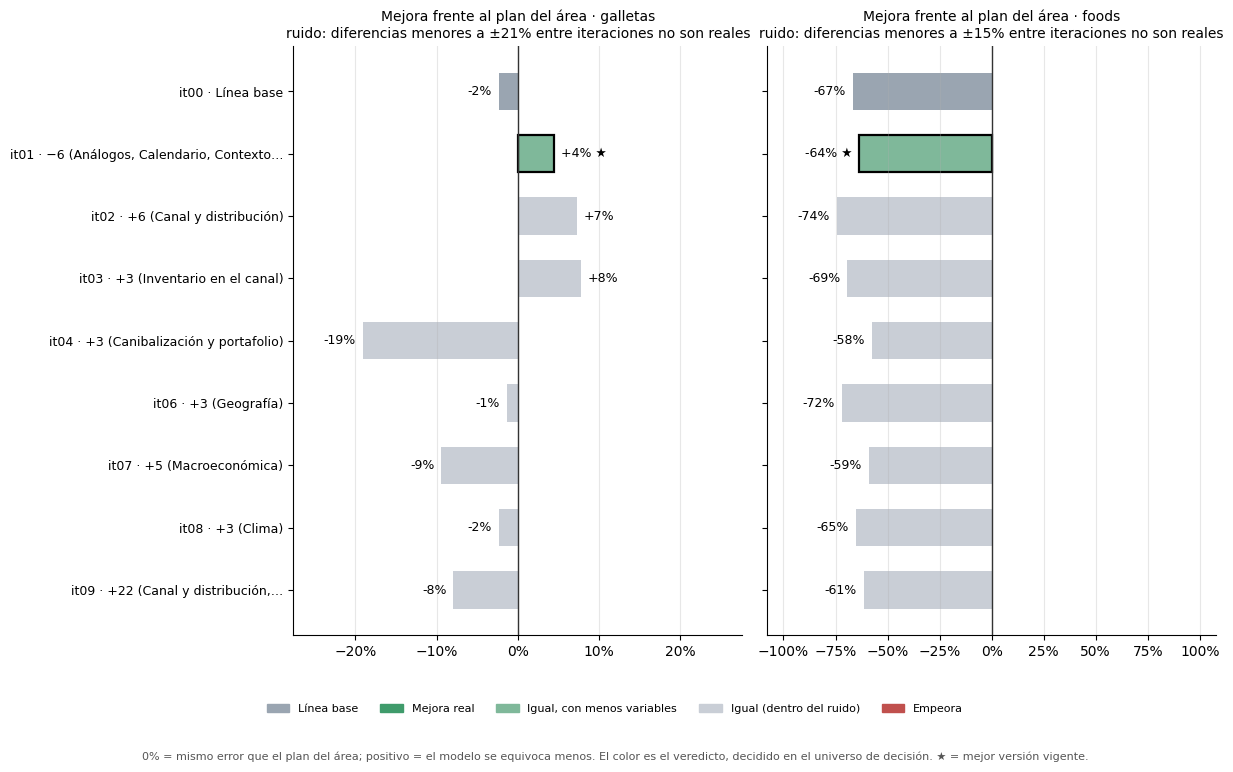

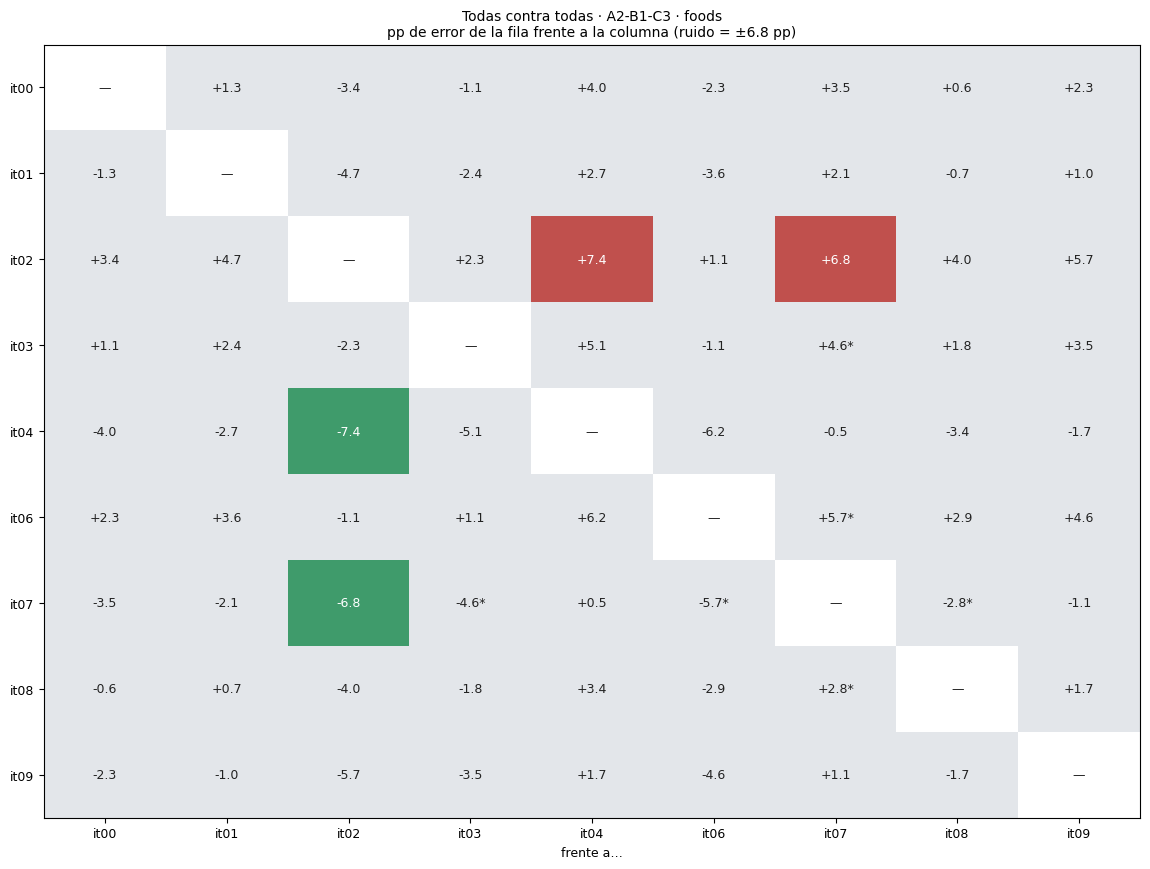

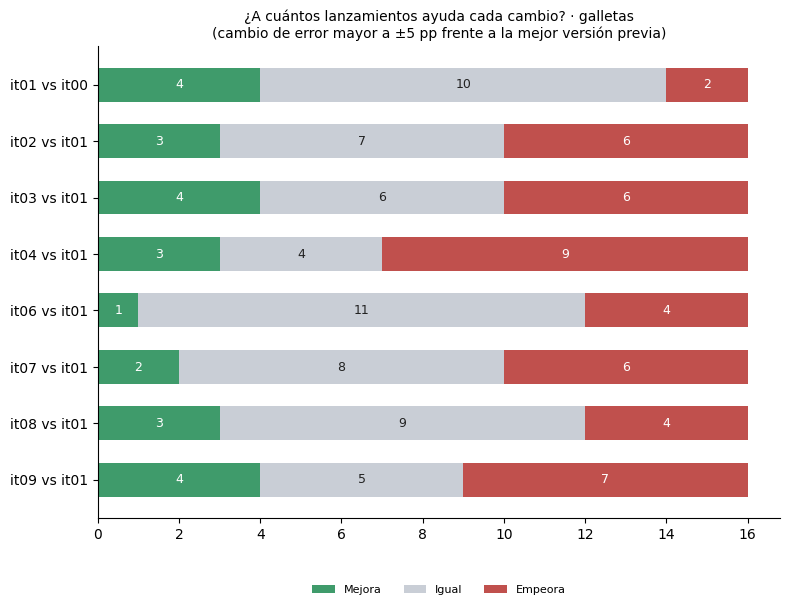

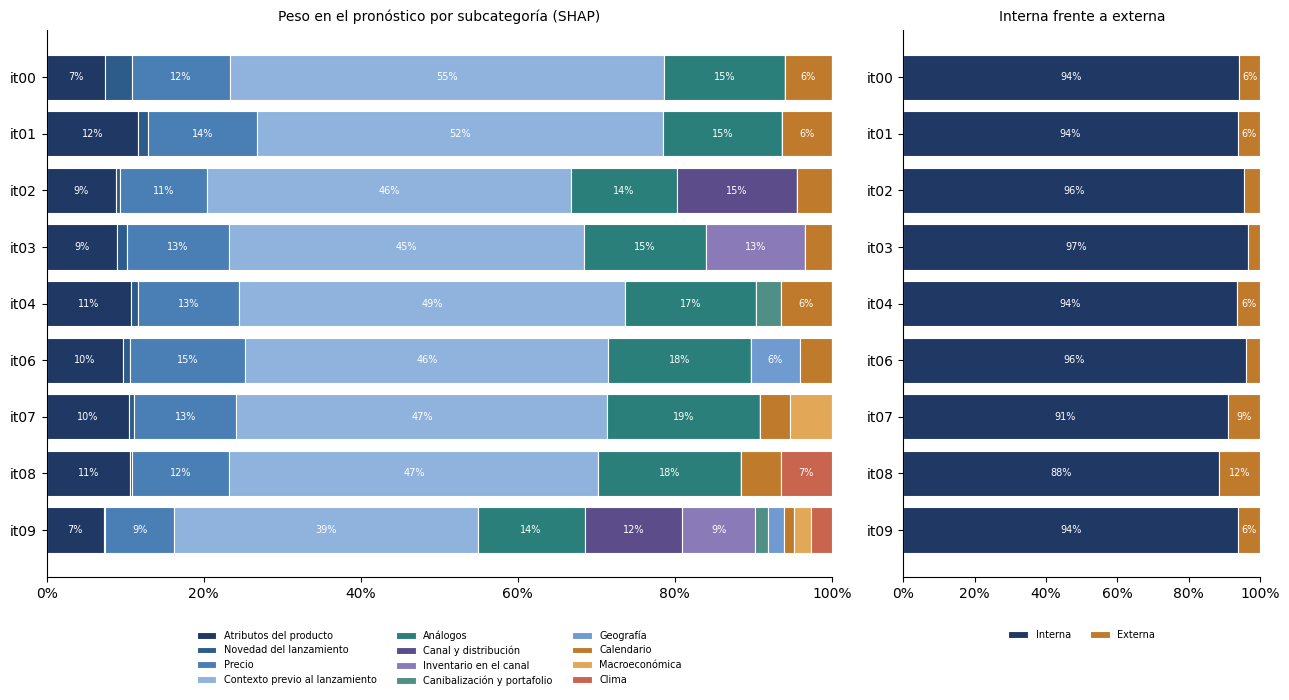

In [ ]:
fig_mejora = grafico_mejora_vs_plan(tb_ejecutiva, UNIVERSOS, wmape_plan, ruido, CELDA_PRINCIPAL,
                                    COLORES_VEREDICTO, RUTA_GRAFICO_MEJORA)
display(fig_mejora)

fig_matriz = grafico_matriz(delta_pares, p_pares, float(decision["umbral_ruido"].iloc[0]) * 100,
                            CELDA_PRINCIPAL, UNIVERSO_DECISION, RUTA_GRAFICO_MATRIZ)
display(fig_matriz)

fig_lanzamientos = grafico_lanzamientos(conteo, UNIVERSO_MAPA, MARGEN_LANZAMIENTO_PP,
                                        RUTA_GRAFICO_LANZAMIENTOS)
display(fig_lanzamientos)

fig_importancia = grafico_importancia(importancia, iteraciones, COLORES_SUBCATEGORIA,
                                      COLORES_ORIGEN, COLOR_SIN_ASIGNAR, RUTA_GRAFICO_IMPORTANCIA)
display(fig_importancia)

guardar_tabla(tb_ejecutiva, PROJECT_ID, TABLA_IT_EJECUTIVA, WRITE_DISPOSITION)
guardar_tabla(tb_escalera, PROJECT_ID, TABLA_IT_ESCALERA, WRITE_DISPOSITION)

# Se cierran después de mostrarlas para que Colab no las dibuje dos veces.
plt.close("all")

#### Confirmación con varias semillas

Compara it01 e it09 con el promedio de sus 5 semillas, pareando por semilla (mismos folds). Es la decisión final sobre si los bloques de variables, juntos, mejoran el modelo.

=== Confirmación con varias semillas · promedio pareado por semilla ===


,base,nueva,universo,celda,n_semillas,wmape_mensual_mediana_base,wmape_mensual_mediana_nueva,delta_pp,desv_delta_pp,semillas_mejora,umbral_pp,p_t_pareada,veredicto
0,it01,it09,galletas,A2-B1-C3,5,0.4525,0.5057,5.3265,8.6038,2,3.9319,0.2385,Empeora
1,it01,it09,galletas,A1-B1-C3,5,0.6107,0.5809,-2.9787,9.0975,3,7.3998,0.5047,Igual (dentro del ruido)
2,it01,it09,foods,A2-B1-C3,5,0.7691,0.7424,-2.6732,1.9093,5,3.0274,0.0352,Igual (dentro del ruido)
3,it01,it09,foods,A1-B1-C3,5,0.7291,0.7443,1.5247,3.5312,1,3.2556,0.3890,Igual (dentro del ruido)


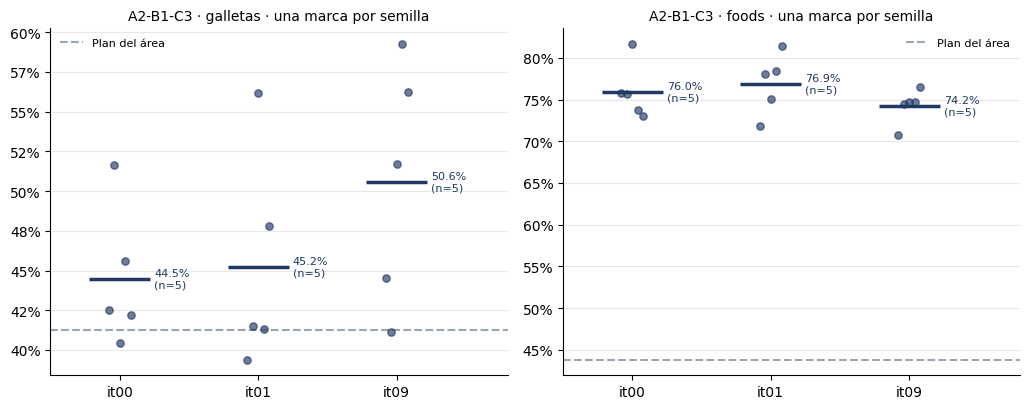

In [ ]:
from IPython.display import display

# Solo tiene sentido cuando ambas iteraciones del par corrieron varias semillas.
tb_multisemilla = comparacion_multisemilla(resumen, PARES_MULTISEMILLA, CELDAS_MULTISEMILLA,
                                           UNIVERSOS, ruido, METRICA)
print("=== Confirmación con varias semillas · promedio pareado por semilla ===")
display(tb_multisemilla.round(4))

fig_multisemilla = grafico_multisemilla(resumen, ITERACIONES_MULTISEMILLA, CELDA_PRINCIPAL,
                                        CELDA_BASELINE, UNIVERSOS, METRICA, COLORES_CELDAS,
                                        RUTA_GRAFICO_MULTISEMILLA)
display(fig_multisemilla)

guardar_tabla(tb_multisemilla, PROJECT_ID, TABLA_IT_MULTISEMILLA, WRITE_DISPOSITION)
plt.close("all")